In [ ]:
!apt-get -qq update
!apt-get -qq install -y tesseract-ocr
!pip -q install datasets scikit-learn pytesseract tqdm

In [ ]:
import hashlib
import io
import json
import random
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from datasets import load_dataset
from PIL import Image as PILImage
from tqdm.auto import tqdm

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DATASET = "stefan-hf/rvlcdip-redact"
IMAGE_CONFIG = "images_redact"

# 400 per class total, preserving the official split roles.
SAMPLE_QUOTAS = {
    "train": 320,
    "validation": 40,
    "test": 40,
}

CLASS_NAMES = [
    "advertisement",
    "budget",
    "email",
    "file_folder",
    "form",
    "handwritten",
    "invoice",
    "letter",
    "memo",
    "news_article",
    "presentation",
    "questionnaire",
    "resume",
    "scientific_publication",
    "scientific_report",
    "specification",
]
CLASS_TO_ID = {name: i for i, name in enumerate(CLASS_NAMES)}

ROOT = Path("/kaggle/working/rvlcdip_baseline")
IMAGE_DIR = ROOT / "sample_images"
SAMPLE_DIR = ROOT / "sample_manifests"
ROOT.mkdir(parents=True, exist_ok=True)
IMAGE_DIR.mkdir(parents=True, exist_ok=True)
SAMPLE_DIR.mkdir(parents=True, exist_ok=True)

In [ ]:
def train_duplicate_ids(split):
    """Return validation/test IDs flagged as duplicates of train documents."""
    if split == "train":
        return set()

    duplicate_stream = load_dataset(
        "stefan-hf/rvlcdip-duplicates",
        "documents",
        split=split,
        streaming=True,
    )

    return {
        row["id"]
        for row in duplicate_stream
        if row.get("has_train_duplicate", False)
    }


def as_pil_image(value):
    if isinstance(value, PILImage.Image):
        return value.convert("RGB")

    if isinstance(value, dict):
        if value.get("bytes") is not None:
            return PILImage.open(io.BytesIO(value["bytes"])).convert("RGB")
        if value.get("path") is not None:
            return PILImage.open(value["path"]).convert("RGB")

    return PILImage.open(value).convert("RGB")


def sample_split(split, per_class, seed):
    manifest_path = SAMPLE_DIR / f"{split}_sample.csv"

    if manifest_path.exists():
        print("Using saved sample:", manifest_path)
        return pd.read_csv(manifest_path)

    excluded_ids = train_duplicate_ids(split)
    print(f"{split}: excluding {len(excluded_ids):,} flagged train duplicates")

    stream = load_dataset(
        DATASET,
        IMAGE_CONFIG,
        split=split,
        streaming=True,
    )

    # A bounded shuffle gives a reproducible sample without loading the split.
    stream = stream.shuffle(seed=seed, buffer_size=3000)

    counts = {name: 0 for name in CLASS_NAMES}
    records = []

    for row in tqdm(stream, desc=f"Sampling {split}"):
        image_id = row.get("id")
        label = row.get("label_fixed")

        if label is None or label not in CLASS_TO_ID:
            continue
        if image_id in excluded_ids:
            continue
        if counts[label] >= per_class:
            continue

        image = as_pil_image(row["image"])

        file_hash = hashlib.sha1(image_id.encode("utf-8")).hexdigest()
        image_path = IMAGE_DIR / f"{split}_{file_hash}.png"
        image.save(image_path, format="PNG")

        records.append({
            "id": image_id,
            "split": split,
            "label": label,
            "label_id": CLASS_TO_ID[label],
            "image_path": str(image_path),
        })
        counts[label] += 1

        if all(counts[name] >= per_class for name in CLASS_NAMES):
            break

    short = {name: count for name, count in counts.items()
             if count < per_class}
    if short:
        raise RuntimeError(f"Could not fill class quotas in {split}: {short}")

    result = pd.DataFrame(records)
    result.to_csv(manifest_path, index=False)
    print(f"Saved {len(result):,} images to {manifest_path}")
    return result


parts = []
for split, quota in SAMPLE_QUOTAS.items():
    parts.append(sample_split(split, quota, SEED + len(parts)))

manifest = pd.concat(parts, ignore_index=True)
manifest.to_csv(ROOT / "sample_manifest.csv", index=False)

print(manifest.groupby(["split", "label"]).size().unstack(fill_value=0))
print("Total sample:", len(manifest))

In [ ]:
import copy
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights
from sklearn.metrics import f1_score

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
BATCH_SIZE = 32
EPOCHS = 10

weights = EfficientNet_B0_Weights.DEFAULT
IMAGE_TRANSFORM = weights.transforms()

class CleanImageDataset(Dataset):
    def __init__(self, frame):
        self.frame = frame.reset_index(drop=True)

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, index):
        row = self.frame.iloc[index]
        image = PILImage.open(row["image_path"]).convert("RGB")
        return (
            IMAGE_TRANSFORM(image),
            int(row["label_id"]),
            str(row["id"]),
        )


train_df = manifest[manifest["split"] == "train"].copy()
val_df = manifest[manifest["split"] == "validation"].copy()

train_loader = DataLoader(
    CleanImageDataset(train_df),
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=torch.cuda.is_available(),
)
val_loader = DataLoader(
    CleanImageDataset(val_df),
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available(),
)

visual_model = efficientnet_b0(weights=weights)

for parameter in visual_model.features.parameters():
    parameter.requires_grad = False

for block in list(visual_model.features.children())[-2:]:
    for parameter in block.parameters():
        parameter.requires_grad = True

visual_model.classifier[1] = nn.Linear(
    visual_model.classifier[1].in_features,
    len(CLASS_NAMES),
)
visual_model = visual_model.to(DEVICE)

backbone_params = [
    p for p in visual_model.features.parameters() if p.requires_grad
]
classifier_params = list(visual_model.classifier.parameters())

optimizer = torch.optim.AdamW(
    [{"params": backbone_params, "lr": 1e-5},
        {"params": classifier_params, "lr": 1e-3},],
    weight_decay=1e-4,
)
criterion = nn.CrossEntropyLoss()


def evaluate_visual_loader(model, loader):
    model.eval()
    true_labels, predictions = [], []

    with torch.no_grad():
        for images, labels, _ in loader:
            images = images.to(DEVICE)
            logits = model(images)
            predictions.extend(logits.argmax(dim=1).cpu().numpy())
            true_labels.extend(labels.numpy())

    score = f1_score(
        true_labels,
        predictions,
        labels=list(range(len(CLASS_NAMES))),
        average="macro",
        zero_division=0,
    )
    return score


best_val_f1 = -1
best_state = None

for epoch in range(EPOCHS):
    visual_model.train()
    total_loss = 0.0

    for images, labels, _ in tqdm(train_loader, desc=f"Epoch {epoch + 1}"):
        images = images.to(DEVICE)
        labels = labels.to(DEVICE)

        optimizer.zero_grad()
        logits = visual_model(images)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(labels)

    val_f1 = evaluate_visual_loader(visual_model, val_loader)
    mean_loss = total_loss / len(train_df)

    print(
        f"Epoch {epoch + 1}: "
        f"train_loss={mean_loss:.4f}, val_macro_f1={val_f1:.4f}"
    )

    if val_f1 > best_val_f1:
        best_val_f1 = val_f1
        best_state = copy.deepcopy(visual_model.state_dict())

visual_model.load_state_dict(best_state)
visual_model.eval()

torch.save(visual_model.state_dict(), ROOT / "efficientnet_b0_clean.pt")
print("Saved clean EfficientNet baseline.")

In [ ]:
from PIL import ImageFilter

DEGRADATIONS = ["blur", "jpeg", "noise", "downsample"]
SEVERITIES = [1, 2, 3]

def stable_seed(image_id, condition, severity):
    value = f"{SEED}|{image_id}|{condition}|{severity}"
    return int(hashlib.sha256(value.encode()).hexdigest()[:8], 16)


def apply_degradation(image, image_id, condition, severity):
    image = image.convert("RGB")

    if condition == "clean":
        return image

    if condition == "blur":
        radius = {1: 0.8, 2: 1.6, 3: 2.6}[severity]
        return image.filter(ImageFilter.GaussianBlur(radius))

    if condition == "jpeg":
        quality = {1: 70, 2: 40, 3: 15}[severity]
        buffer = io.BytesIO()
        image.save(buffer, format="JPEG", quality=quality)
        buffer.seek(0)
        return PILImage.open(buffer).convert("RGB").copy()

    if condition == "noise":
        rng = np.random.default_rng(
            stable_seed(image_id, condition, severity)
        )
        sigma = {1: 6.0, 2: 16.0, 3: 28.0}[severity]
        array = np.asarray(image).astype(np.float32)
        noise = rng.normal(0, sigma, size=array.shape)
        result = np.clip(array + noise, 0, 255).astype(np.uint8)
        return PILImage.fromarray(result)

    if condition == "downsample":
        scale = {1: 0.75, 2: 0.50, 3: 0.30}[severity]
        width, height = image.size
        small = image.resize(
            (max(32, int(width * scale)), max(32, int(height * scale))),
            PILImage.Resampling.BILINEAR,
        )
        return small.resize(
            (width, height),
            PILImage.Resampling.BILINEAR,
        )

    raise ValueError(f"Unknown degradation: {condition}")

In [ ]:
import pytesseract
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score


OCR_CONFIG = "--oem 1 --psm 6"
OCR_CACHE_PATH = ROOT / "ocr_cache.jsonl"
OCR_CACHE = {}

if OCR_CACHE_PATH.exists():
    with open(OCR_CACHE_PATH, "r", encoding="utf-8") as handle:
        for line in handle:
            item = json.loads(line)
            OCR_CACHE[item["key"]] = item["text"]

NEW_OCR_ROWS = []

def flush_ocr_cache():
    global NEW_OCR_ROWS
    if not NEW_OCR_ROWS:
        return
    with open(OCR_CACHE_PATH, "a", encoding="utf-8") as handle:
        for item in NEW_OCR_ROWS:
            handle.write(json.dumps(item, ensure_ascii=False) + "\n")
    NEW_OCR_ROWS = []


def get_ocr_text(row, condition, severity):
    key = f"{row['id']}|{condition}|{severity}"

    if key in OCR_CACHE:
        return OCR_CACHE[key]

    image = PILImage.open(row["image_path"]).convert("RGB")
    image = apply_degradation(image, row["id"], condition, severity)
    text = pytesseract.image_to_string(image, config=OCR_CONFIG)
    text = " ".join(text.split())

    OCR_CACHE[key] = text
    NEW_OCR_ROWS.append({"key": key, "text": text})

    if len(NEW_OCR_ROWS) >= 25:
        flush_ocr_cache()

    return text


# Fit the text classifier on clean training OCR only.
train_records = train_df.to_dict("records")
train_texts = [get_ocr_text(row, "clean", 0)
    for row in tqdm(train_records, desc="OCR clean training images")]
flush_ocr_cache()

train_texts = [text if text else "<EMPTY_OCR>" for text in train_texts]
train_labels = train_df["label_id"].to_numpy()

vectorizer = TfidfVectorizer(
    ngram_range=(1, 2),
    min_df=2,
    max_features=30000,
    sublinear_tf=True,
)
X_train_text = vectorizer.fit_transform(train_texts)

text_model = LogisticRegression(
    max_iter=1500,
    class_weight="balanced",
    solver="lbfgs",
)
text_model.fit(X_train_text, train_labels)

print("Trained clean OCR-text baseline.")

In [ ]:
class VariantTestDataset(Dataset):
    def __init__(self, frame, condition, severity):
        self.frame = frame.reset_index(drop=True)
        self.condition = condition
        self.severity = severity

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, index):
        row = self.frame.iloc[index]
        image = PILImage.open(row["image_path"]).convert("RGB")
        image = apply_degradation(
            image,
            str(row["id"]),
            self.condition,
            self.severity,
        )
        return (
            IMAGE_TRANSFORM(image),
            int(row["label_id"]),
            str(row["id"]),
        )


def predict_visual_on_condition(test_frame, condition, severity):
    loader = DataLoader(
        VariantTestDataset(test_frame, condition, severity),
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=2,
        pin_memory=torch.cuda.is_available(),
    )

    ids, labels, predictions = [], [], []
    visual_model.eval()

    with torch.no_grad():
        for images, batch_labels, batch_ids in loader:
            logits = visual_model(images.to(DEVICE))
            predictions.extend(logits.argmax(dim=1).cpu().numpy())
            labels.extend(batch_labels.numpy())
            ids.extend(list(batch_ids))

    return ids, labels, predictions


test_df = manifest[manifest["split"] == "test"].reset_index(drop=True)
prediction_rows = []

conditions_to_test = [("clean", 0)]
conditions_to_test += [
    (condition, severity)
    for condition in DEGRADATIONS
    for severity in SEVERITIES
]

for condition, severity in conditions_to_test:
    print(f"Evaluating {condition}, severity {severity}")

    ids, labels, visual_predictions = predict_visual_on_condition(
        test_df, condition, severity
    )

    test_records = test_df.to_dict("records")
    text_inputs = [get_ocr_text(row, condition, severity)
        for row in tqdm(test_records, desc="OCR test images")]
    flush_ocr_cache()

    text_inputs = [
        text if text else "<EMPTY_OCR>"
        for text in text_inputs
    ]
    text_predictions = text_model.predict(
        vectorizer.transform(text_inputs)
    )

    for i in range(len(ids)):
        prediction_rows.append({
            "id": ids[i],
            "condition": condition,
            "severity": severity,
            "label_id": int(labels[i]),
            "visual_pred": int(visual_predictions[i]),
            "ocr_pred": int(text_predictions[i]),
        })

predictions_df = pd.DataFrame(prediction_rows)
predictions_df.to_csv(ROOT / "baseline_predictions.csv", index=False)
print("Saved predictions.")

In [ ]:
from pathlib import Path
from collections import Counter
import json

ROOT = Path("/kaggle/working/rvlcdip_baseline")

for name in [
    "sample_manifest.csv",
    "efficientnet_b0_clean.pt",
    "ocr_cache.jsonl",
    "baseline_predictions.csv",
]:
    path = ROOT / name
    print(name, "exists:", path.exists(),
          "size:", f"{path.stat().st_size / 1e6:.1f} MB" if path.exists() else "-")

cache_path = ROOT / "ocr_cache.jsonl"
if cache_path.exists():
    counts = Counter()
    with open(cache_path, "r", encoding="utf-8") as f:
        for line in f:
            key = json.loads(line)["key"]
            _, condition, severity = key.rsplit("|", 2)
            counts[(condition, severity)] += 1

    print("\nCached OCR rows by condition:")
    for key, count in sorted(counts.items()):
        print(key, count)
    print("Total cached OCR rows:", sum(counts.values()))

In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np
from sklearn.metrics import accuracy_score, f1_score

ROOT = Path("/kaggle/working/rvlcdip_baseline")
pred = pd.read_csv(ROOT / "baseline_predictions.csv")

print("Prediction rows:", len(pred))
print("\nRows per condition:")
print(pred.groupby(["condition", "severity"]).size())

# Expect 13 conditions: clean plus 4 degradation types × 3 severities.
assert len(pred) == 640 * 13, "Check whether the prediction file is complete."
assert (pred.groupby(["condition", "severity"]).size() == 640).all()

rows = []
for (condition, severity), group in pred.groupby(
    ["condition", "severity"], sort=False
):
    y = group["label_id"].to_numpy()
    visual = group["visual_pred"].to_numpy()
    ocr = group["ocr_pred"].to_numpy()

    visual_correct = visual == y
    ocr_correct = ocr == y

    rows.append({
        "condition": condition,
        "severity": int(severity),
        "n": len(group),
        "visual_accuracy": accuracy_score(y, visual),
        "visual_macro_f1": f1_score(
            y, visual, labels=range(16),
            average="macro", zero_division=0
        ),
        "ocr_accuracy": accuracy_score(y, ocr),
        "ocr_macro_f1": f1_score(
            y, ocr, labels=range(16),
            average="macro", zero_division=0
        ),
        "ocr_fixes_visual_rate": np.mean((~visual_correct) & ocr_correct),
        "ocr_harms_visual_rate": np.mean(visual_correct & (~ocr_correct)),
        "net_ocr_utility": np.mean(
            ocr_correct.astype(int) - visual_correct.astype(int)
        ),
    })

summary = pd.DataFrame(rows)
summary.to_csv(ROOT / "baseline_condition_summary.csv", index=False)
print("\nSaved summary:")
print(summary.round(3).to_string(index=False))

In [ ]:
import numpy as np
import pandas as pd

ROOT = "/kaggle/working/rvlcdip_baseline"
pred = pd.read_csv(f"{ROOT}/baseline_predictions.csv")
rng = np.random.default_rng(42)

rows = []

for (condition, severity), group in pred.groupby(
    ["condition", "severity"], sort=False
):
    group = group.reset_index(drop=True)
    y = group["label_id"].to_numpy()
    visual_correct = (group["visual_pred"].to_numpy() == y).astype(int)
    ocr_correct = (group["ocr_pred"].to_numpy() == y).astype(int)

    # Paired difference for each document: +1, 0, or -1.
    difference = ocr_correct - visual_correct

    class_indices = {
        c: np.where(y == c)[0]
        for c in np.unique(y)
    }

    bootstrap_deltas = []
    for _ in range(2000):
        sampled = np.concatenate([rng.choice(indices, size=len(indices), replace=True)
            for indices in class_indices.values()])
        bootstrap_deltas.append(difference[sampled].mean())

    low, high = np.quantile(bootstrap_deltas, [0.025, 0.975])

    rows.append({
        "condition": condition,
        "severity": int(severity),
        "ocr_minus_visual_pp": 100 * difference.mean(),
        "ci95_low_pp": 100 * low,
        "ci95_high_pp": 100 * high,
    })

ci_table = pd.DataFrame(rows)
print(ci_table.round(2).to_string(index=False))
ci_table.to_csv(f"{ROOT}/paired_bootstrap_utility.csv", index=False)

In [ ]:
!pip install -q kgout

from kgout import KgOut

# Replace with your actual Drive Folder ID and Kaggle dataset path
kg = KgOut(
    folder_id="1LizWdNtA893Dzcic3JDmjgegPJTNMBpg",
    credentials="/kaggle/input/datasets/sehansiperera/my-creds/kgout_token.json"

).start()


In [ ]:
import copy
import hashlib
import io
import json
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import pytesseract
import torch
from PIL import Image as PILImage, ImageFilter
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights
from tqdm.auto import tqdm

SEED = 42
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
ROOT = Path("/kaggle/working/rvlcdip_baseline")

manifest = pd.read_csv(ROOT / "sample_manifest.csv")
manifest["id"] = manifest["id"].astype(str)

train_df = manifest[manifest["split"] == "train"].copy()

# Save this split so a kernel restart uses the same documents.
partition_path = ROOT / "train_mask_partition.csv"

if partition_path.exists():
    partition = pd.read_csv(partition_path)
    partition["id"] = partition["id"].astype(str)
else:
    teacher_fit, mask_df = train_test_split(
        train_df,
        test_size=0.20,
        random_state=SEED,
        stratify=train_df["label_id"],
    )
    teacher_fit = teacher_fit.copy()
    mask_df = mask_df.copy()
    teacher_fit["mask_role"] = "teacher_fit"
    mask_df["mask_role"] = "mask"
    partition = pd.concat([teacher_fit, mask_df], ignore_index=True)
    partition.to_csv(partition_path, index=False)

teacher_fit = partition[partition["mask_role"] == "teacher_fit"].copy()
mask_df = partition[partition["mask_role"] == "mask"].copy()

print("Teacher-fit images:", len(teacher_fit))
print("Mask-generation images:", len(mask_df))
print(mask_df["label"].value_counts().sort_index())

In [ ]:
import hashlib
import os
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F

from PIL import Image, ImageFilter
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights
from tqdm.auto import tqdm

ROOT = Path("/kaggle/working/rvlcdip_baseline")
OUT = ROOT / "gated_adapter_v1"
OUT.mkdir(exist_ok=True)

SEED = 42
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
BATCH_SIZE = 8
EPOCHS = 3
TEMPERATURE = 2.0
VISUAL_WEIGHT = 0.5
OCR_WEIGHT = 0.5

manifest = pd.read_csv(ROOT / "sample_manifest.csv")
partition = pd.read_csv(ROOT / "train_mask_partition.csv")
mask = pd.read_csv(ROOT / "train_residual_mask.csv")

for frame in [manifest, partition, mask]:
    frame["id"] = frame["id"].astype(str)

train = manifest[manifest["split"] == "train"].copy()
mask_ids = set(
    partition.loc[partition["mask_role"] == "mask", "id"]
)
fit_ids = set(
    partition.loc[partition["mask_role"] == "teacher_fit", "id"]
)

assert mask_ids.isdisjoint(fit_ids)
assert set(mask["id"]) == mask_ids
assert not mask.duplicated(["id", "condition", "severity"]).any()
assert set(mask["condition"]) == {"noise", "blur", "downsample"}
assert (mask["severity"] == 3).all()

# Check that the saved mask really means OCR correct AND vision wrong.
expected = (
    (mask["ocr_pred"] == mask["label_id"]) &
    (mask["visual_pred"] != mask["label_id"])
).astype(int)
assert (mask["residual_mask"] == expected).all()

probability_columns = (
    [f"visual_p_{i}" for i in range(16)] +
    [f"ocr_p_{i}" for i in range(16)]
)
assert not mask[probability_columns].isna().any().any()

# Clean images: class-label loss only.
clean = train[["id", "image_path", "label_id"]].copy()
clean["condition"] = "clean"
clean["severity"] = 0
clean["residual_mask"] = 0
clean["is_degraded"] = 0

for column in probability_columns:
    clean[column] = 0.0

# Degraded images: labels plus saved teacher probabilities.
degraded = mask.merge(
    train[["id", "image_path", "label_id"]],
    on=["id", "label_id"],
    how="left",
    validate="many_to_one",
)
assert degraded["image_path"].notna().all()
degraded["is_degraded"] = 1

columns = [
    "id", "image_path", "label_id", "condition",
    "severity", "residual_mask", "is_degraded",
] + probability_columns

items = pd.concat(
    [clean[columns], degraded[columns]],
    ignore_index=True,
)

assert len(clean) == 5120
assert len(degraded) == 3072
assert int(degraded["residual_mask"].sum()) == 601

print("Device:", DEVICE)
print("Clean training rows:", len(clean))
print("Degraded training rows:", len(degraded))
print("Selected OCR rows:", int(degraded["residual_mask"].sum()))
print("Total training rows:", len(items))

In [ ]:
TRANSFORM = EfficientNet_B0_Weights.DEFAULT.transforms()


def stable_seed(image_id, condition, severity):
    value = f"{SEED}|{image_id}|{condition}|{severity}"
    return int(hashlib.sha256(value.encode()).hexdigest()[:8], 16)


def degrade(image, image_id, condition, severity):
    image = image.convert("RGB")

    if condition == "clean":
        return image

    if condition == "blur":
        radius = {1: 0.8, 2: 1.6, 3: 2.6}[severity]
        return image.filter(ImageFilter.GaussianBlur(radius))

    if condition == "downsample":
        scale = {1: 0.75, 2: 0.50, 3: 0.30}[severity]
        width, height = image.size
        small = image.resize(
            (max(32, int(width * scale)),
             max(32, int(height * scale))),
            Image.Resampling.BILINEAR,
        )
        return small.resize(
            (width, height), Image.Resampling.BILINEAR
        )

    if condition == "noise":
        rng = np.random.default_rng(
            stable_seed(image_id, condition, severity)
        )
        sigma = {1: 6.0, 2: 16.0, 3: 28.0}[severity]
        array = np.asarray(image).astype(np.float32)
        noise = rng.normal(0, sigma, size=array.shape)
        result = np.clip(array + noise, 0, 255).astype(np.uint8)
        return Image.fromarray(result)

    raise ValueError(condition)


class StudentDataset(Dataset):
    def __init__(self, frame):
        self.frame = frame.reset_index(drop=True)

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, index):
        row = self.frame.iloc[index]

        with Image.open(row["image_path"]) as opened:
            image = opened.convert("RGB")

        image = degrade(
            image,
            str(row["id"]),
            str(row["condition"]),
            int(row["severity"]),
        )

        visual_p = np.asarray(
            [row[f"visual_p_{i}"] for i in range(16)],
            dtype=np.float32,
        )
        ocr_p = np.asarray(
            [row[f"ocr_p_{i}"] for i in range(16)],
            dtype=np.float32,
        )

        return (
            TRANSFORM(image),
            int(row["label_id"]),
            torch.from_numpy(visual_p),
            torch.from_numpy(ocr_p),
            float(row["residual_mask"]),
            float(row["is_degraded"]),
        )


class GatedAdapterStudent(nn.Module):
    def __init__(self):
        super().__init__()

        self.backbone = efficientnet_b0(weights=None)
        feature_dim = self.backbone.classifier[1].in_features

        self.backbone.classifier[1] = nn.Linear(feature_dim, 16)

        # Load your already-trained clean baseline.
        state = torch.load(
            ROOT / "efficientnet_b0_clean.pt",
            map_location="cpu",
            weights_only=True,
        )
        self.backbone.load_state_dict(state)

        # Small correction to the visual features.
        self.adapter = nn.Sequential(
            nn.Linear(feature_dim, 64),
            nn.ReLU(),
            nn.Linear(64, feature_dim),
        )
        self.gate = nn.Sequential(
            nn.Linear(feature_dim, 1),
            nn.Sigmoid(),
        )

        # Start with zero correction: initially the student behaves like
        # the saved clean baseline in evaluation mode.
        nn.init.zeros_(self.adapter[-1].weight)
        nn.init.zeros_(self.adapter[-1].bias)

        for parameter in self.backbone.features.parameters():
            parameter.requires_grad = False

        for block in list(self.backbone.features.children())[-2:]:
            for parameter in block.parameters():
                parameter.requires_grad = True

    def forward(self, images):
        features = self.backbone.features(images)
        features = self.backbone.avgpool(features)
        features = torch.flatten(features, 1)

        correction = self.adapter(features)
        gate_value = self.gate(features)
        adapted = features + gate_value * correction

        return self.backbone.classifier(adapted)


def build_student():
    # Reset before each arm so adapter initialization is matched.
    torch.manual_seed(SEED)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)
    return GatedAdapterStudent().to(DEVICE)


dataset = StudentDataset(items)

# Quick architecture and data check before training.
student = build_student()
student.eval()

sample_image, label, *_ = dataset[0]
with torch.no_grad():
    output = student(sample_image.unsqueeze(0).to(DEVICE))

assert output.shape == (1, 16)
print("Student output shape:", tuple(output.shape))
print("Total parameters:", sum(p.numel() for p in student.parameters()))
print("Trainable parameters:", sum(
    p.numel() for p in student.parameters() if p.requires_grad
))

del student
if torch.cuda.is_available():
    torch.cuda.empty_cache()

In [ ]:
def teacher_kd_per_example(logits, teacher_probabilities):
    # Saved teacher probabilities were produced at temperature 1.
    p = teacher_probabilities.clamp_min(1e-8)
    p = p.pow(1.0 / TEMPERATURE)
    p = p / p.sum(dim=1, keepdim=True)

    log_q = F.log_softmax(logits / TEMPERATURE, dim=1)

    return F.kl_div(
        log_q, p, reduction="none"
    ).sum(dim=1) * (TEMPERATURE ** 2)


def train_adapter(mode):
    assert mode in {"unconditional", "conditional"}

    model = build_student()
    optimizer = torch.optim.AdamW(
        [
            {
                "params": [
                    p for p in model.backbone.features.parameters()
                    if p.requires_grad
                ],
                "lr": 5e-6,
            },
            {
                "params": (
                    list(model.backbone.classifier.parameters()) +
                    list(model.adapter.parameters()) +
                    list(model.gate.parameters())
                ),
                "lr": 5e-5,
            },
        ],
        weight_decay=1e-4,
    )

    start_epoch = 0

    for completed in range(EPOCHS, 0, -1):
        path = OUT / f"{mode}_epoch{completed}.pt"
        if path.exists():
            saved = torch.load(
                path, map_location=DEVICE, weights_only=True
            )
            model.load_state_dict(saved["model"])
            optimizer.load_state_dict(saved["optimizer"])
            torch.set_rng_state(saved["torch_rng"].cpu())
            if torch.cuda.is_available() and "cuda_rng" in saved:
                torch.cuda.set_rng_state(saved["cuda_rng"].cpu())
            start_epoch = completed
            print(f"{mode}: resuming after epoch {completed}")
            break

    if start_epoch == EPOCHS:
        print(f"{mode}: already complete.")
        return

    for epoch in range(start_epoch, EPOCHS):
        # Both arms get the same example order in each epoch.
        generator = torch.Generator().manual_seed(SEED + epoch)
        loader = DataLoader(
            dataset,
            batch_size=BATCH_SIZE,
            shuffle=True,
            num_workers=0,
            generator=generator,
        )

        model.train()

        # Frozen feature blocks stay in evaluation mode, including their
        # BatchNorm statistics. The final two blocks remain trainable.
        for block in list(model.backbone.features.children())[:-2]:
            block.eval()

        total = 0.0
        n = 0

        for images, labels, visual_p, ocr_p, residual, degraded_flag in tqdm(
            loader, desc=f"{mode} epoch {epoch + 1}/{EPOCHS}"
        ):
            images = images.to(DEVICE)
            labels = labels.to(DEVICE)
            visual_p = visual_p.to(DEVICE)
            ocr_p = ocr_p.to(DEVICE)
            residual = residual.to(DEVICE)
            degraded_flag = degraded_flag.to(DEVICE)

            visual_mask = degraded_flag

            if mode == "unconditional":
                ocr_mask = degraded_flag
            else:
                ocr_mask = residual

            optimizer.zero_grad(set_to_none=True)
            logits = model(images)

            class_loss = F.cross_entropy(logits, labels)
            visual_per_item = teacher_kd_per_example(logits, visual_p)
            ocr_per_item = teacher_kd_per_example(logits, ocr_p)

            # Both teacher terms use the same denominator. This makes
            # conditional OCR loss reflect how many examples were selected.
            denominator = degraded_flag.sum().clamp_min(1.0)
            visual_loss = (visual_per_item * visual_mask).sum() / denominator
            ocr_loss = (ocr_per_item * ocr_mask).sum() / denominator

            loss = (
                class_loss
                + VISUAL_WEIGHT * visual_loss
                + OCR_WEIGHT * ocr_loss
            )
            loss.backward()
            optimizer.step()

            total += loss.item() * len(labels)
            n += len(labels)

        print(f"{mode} epoch {epoch + 1}: loss={total / n:.4f}")

        checkpoint = {
            "epoch": epoch + 1,
            "mode": mode,
            "model": model.state_dict(),
            "optimizer": optimizer.state_dict(),
            "torch_rng": torch.get_rng_state(),
        }
        if torch.cuda.is_available():
            checkpoint["cuda_rng"] = torch.cuda.get_rng_state()

        destination = OUT / f"{mode}_epoch{epoch + 1}.pt"
        temporary = OUT / f"{mode}_checkpoint.tmp"
        torch.save(checkpoint, temporary)
        os.replace(temporary, destination)
        print("Saved:", destination)

    del model
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


train_adapter("unconditional")
train_adapter("conditional")

In [ ]:
import hashlib
import io
import os
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from PIL import Image, ImageFilter
from sklearn.metrics import accuracy_score, f1_score
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights
from tqdm.auto import tqdm

ROOT = Path("/kaggle/working/rvlcdip_baseline")
OUT = ROOT / "gated_adapter_v1"
PRED_DIR = OUT / "validation_predictions"
PRED_DIR.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
TRANSFORM = EfficientNet_B0_Weights.DEFAULT.transforms()

manifest = pd.read_csv(ROOT / "sample_manifest.csv")
manifest["id"] = manifest["id"].astype(str)
val = manifest[manifest["split"] == "validation"].reset_index(drop=True)

assert len(val) == 640
assert val["id"].is_unique


def degrade(image, image_id, condition, severity):
    image = image.convert("RGB")

    if condition == "clean":
        return image

    if condition == "blur":
        radius = {1: 0.8, 2: 1.6, 3: 2.6}[severity]
        return image.filter(ImageFilter.GaussianBlur(radius))

    if condition == "jpeg":
        quality = {1: 70, 2: 40, 3: 15}[severity]
        buffer = io.BytesIO()
        image.save(buffer, format="JPEG", quality=quality)
        buffer.seek(0)
        return Image.open(buffer).convert("RGB").copy()

    if condition == "noise":
        key = f"42|{image_id}|{condition}|{severity}"
        seed = int(hashlib.sha256(key.encode()).hexdigest()[:8], 16)
        rng = np.random.default_rng(seed)
        sigma = {1: 6.0, 2: 16.0, 3: 28.0}[severity]
        array = np.asarray(image).astype(np.float32)
        noise = rng.normal(0, sigma, size=array.shape)
        return Image.fromarray(
            np.clip(array + noise, 0, 255).astype(np.uint8)
        )

    if condition == "downsample":
        scale = {1: 0.75, 2: 0.50, 3: 0.30}[severity]
        width, height = image.size
        small = image.resize(
            (max(32, int(width * scale)),
             max(32, int(height * scale))),
            Image.Resampling.BILINEAR,
        )
        return small.resize(
            (width, height), Image.Resampling.BILINEAR
        )

    raise ValueError(condition)


class ValidationDataset(Dataset):
    def __init__(self, frame, condition, severity):
        self.frame = frame
        self.condition = condition
        self.severity = severity

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, index):
        row = self.frame.iloc[index]
        with Image.open(row["image_path"]) as opened:
            image = opened.convert("RGB")

        image = degrade(
            image, row["id"], self.condition, self.severity
        )
        return TRANSFORM(image), int(row["label_id"]), row["id"]


# Same architecture as the trained gated students.
class GatedAdapterStudent(nn.Module):
    def __init__(self):
        super().__init__()
        self.backbone = efficientnet_b0(weights=None)
        feature_dim = self.backbone.classifier[1].in_features
        self.backbone.classifier[1] = nn.Linear(feature_dim, 16)

        self.adapter = nn.Sequential(
            nn.Linear(feature_dim, 64),
            nn.ReLU(),
            nn.Linear(64, feature_dim),
        )
        self.gate = nn.Sequential(
            nn.Linear(feature_dim, 1),
            nn.Sigmoid(),
        )

    def forward(self, images):
        features = self.backbone.features(images)
        features = self.backbone.avgpool(features)
        features = torch.flatten(features, 1)
        adapted = features + self.gate(features) * self.adapter(features)
        return self.backbone.classifier(adapted)


conditions = [("clean", 0)] + [
    (condition, severity)
    for condition in ["blur", "jpeg", "noise", "downsample"]
    for severity in [1, 2, 3]
]

all_files = []

for mode in ["unconditional", "conditional"]:
    checkpoint_path = OUT / f"{mode}_epoch3.pt"
    assert checkpoint_path.exists(), f"Missing: {checkpoint_path}"

    # Include a checkpoint fingerprint in filenames to prevent accidental
    # reuse of predictions from a different checkpoint.
    fingerprint = hashlib.sha256(checkpoint_path.read_bytes()).hexdigest()[:12]

    checkpoint = torch.load(
        checkpoint_path, map_location="cpu", weights_only=True
    )
    model = GatedAdapterStudent()
    model.load_state_dict(checkpoint["model"])
    model = model.to(DEVICE).eval()

    for condition, severity in conditions:
        path = PRED_DIR / (
            f"{mode}_{fingerprint}_{condition}_s{severity}.csv"
        )
        all_files.append(path)

        if path.exists():
            print("Using saved:", path.name)
            continue

        loader = DataLoader(
            ValidationDataset(val, condition, severity),
            batch_size=16,
            shuffle=False,
            num_workers=0,
        )

        rows = []
        with torch.no_grad():
            for images, labels, ids in tqdm(
                loader, desc=f"{mode}: {condition} s{severity}"
            ):
                predictions = model(images.to(DEVICE)).argmax(dim=1)
                predictions = predictions.cpu().numpy()

                for image_id, label, prediction in zip(
                    ids, labels.numpy(), predictions
                ):
                    rows.append({
                        "id": str(image_id),
                        "model": mode,
                        "condition": condition,
                        "severity": severity,
                        "label_id": int(label),
                        "prediction": int(prediction),
                    })

        result = pd.DataFrame(rows)
        assert len(result) == len(val)
        assert result["id"].is_unique

        temporary = path.with_suffix(".tmp")
        result.to_csv(temporary, index=False)
        os.replace(temporary, path)
        print("Saved:", path.name)

    del model
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

pred = pd.concat(
    [pd.read_csv(path, dtype={"id": str}) for path in all_files],
    ignore_index=True,
)

assert len(pred) == 2 * 13 * len(val)
assert not pred.duplicated(
    ["model", "id", "condition", "severity"]
).any()

summary_rows = []

for (condition, severity, mode), group in pred.groupby(
    ["condition", "severity", "model"]
):
    summary_rows.append({
        "condition": condition,
        "severity": int(severity),
        "model": mode,
        "accuracy": accuracy_score(
            group["label_id"], group["prediction"]
        ),
        "macro_f1": f1_score(
            group["label_id"],
            group["prediction"],
            labels=list(range(16)),
            average="macro",
            zero_division=0,
        ),
    })

summary = pd.DataFrame(summary_rows)
summary.to_csv(OUT / "gated_validation_summary.csv", index=False)

comparison = summary.pivot(
    index=["condition", "severity"],
    columns="model",
    values=["accuracy", "macro_f1"],
)
comparison.columns = [
    f"{metric}_{mode}" for metric, mode in comparison.columns
]
comparison = comparison.reset_index()

comparison["accuracy_gain_pp"] = 100 * (
    comparison["accuracy_conditional"] -
    comparison["accuracy_unconditional"]
)
comparison["macro_f1_gain_pp"] = 100 * (
    comparison["macro_f1_conditional"] -
    comparison["macro_f1_unconditional"]
)

comparison.to_csv(OUT / "gated_validation_comparison.csv", index=False)
print("\nConditional minus unconditional:")
print(comparison.round(3).to_string(index=False))

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import torch

from PIL import Image
from sklearn.metrics import accuracy_score, f1_score
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights

ROOT = Path("/kaggle/working/rvlcdip_baseline")
OUT = ROOT / "gated_adapter_v1"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

manifest = pd.read_csv(ROOT / "sample_manifest.csv")
val = manifest[manifest["split"] == "validation"].reset_index(drop=True)
transform = EfficientNet_B0_Weights.DEFAULT.transforms()

class CleanValidation(Dataset):
    def __len__(self):
        return len(val)

    def __getitem__(self, index):
        row = val.iloc[index]
        with Image.open(row["image_path"]) as opened:
            image = opened.convert("RGB")
        return transform(image), int(row["label_id"])

loader = DataLoader(
    CleanValidation(), batch_size=16, shuffle=False, num_workers=0
)

class GatedAdapterStudent(nn.Module):
    def __init__(self):
        super().__init__()
        self.backbone = efficientnet_b0(weights=None)
        dim = self.backbone.classifier[1].in_features
        self.backbone.classifier[1] = nn.Linear(dim, 16)
        self.adapter = nn.Sequential(
            nn.Linear(dim, 64), nn.ReLU(), nn.Linear(64, dim)
        )
        self.gate = nn.Sequential(nn.Linear(dim, 1), nn.Sigmoid())

    def forward(self, images):
        features = self.backbone.features(images)
        features = self.backbone.avgpool(features).flatten(1)
        adapted = features + self.gate(features) * self.adapter(features)
        return self.backbone.classifier(adapted)

def evaluate(model):
    model = model.to(DEVICE).eval()
    labels, predictions = [], []

    with torch.no_grad():
        for images, y in loader:
            predictions.extend(
                model(images.to(DEVICE)).argmax(1).cpu().numpy()
            )
            labels.extend(y.numpy())

    counts = np.bincount(predictions, minlength=16)
    return {
        "accuracy": accuracy_score(labels, predictions),
        "macro_f1": f1_score(
            labels, predictions, labels=list(range(16)),
            average="macro", zero_division=0
        ),
        "most_predicted_class": int(counts.argmax()),
        "most_predicted_fraction": counts.max() / len(predictions),
    }

baseline_state = torch.load(
    ROOT / "efficientnet_b0_clean.pt",
    map_location="cpu", weights_only=True
)

baseline = efficientnet_b0(weights=None)
baseline.classifier[1] = nn.Linear(
    baseline.classifier[1].in_features, 16
)
baseline.load_state_dict(baseline_state)

rows = [{"checkpoint": "clean_baseline", **evaluate(baseline)}]
del baseline

for mode in ["unconditional", "conditional"]:
    for epoch in [1, 2, 3]:
        path = OUT / f"{mode}_epoch{epoch}.pt"
        if not path.exists():
            print("Missing:", path)
            continue

        saved = torch.load(path, map_location="cpu", weights_only=True)
        model = GatedAdapterStudent()
        model.load_state_dict(saved["model"])
        rows.append({
            "checkpoint": f"{mode}_epoch{epoch}",
            **evaluate(model),
        })
        del model

diagnostic = pd.DataFrame(rows)
print(diagnostic.round(3).to_string(index=False))

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import torch

from PIL import Image
from sklearn.metrics import accuracy_score, f1_score
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights

ROOT = Path("/kaggle/working/rvlcdip_baseline")
OUT = ROOT / "gated_adapter_v1"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

manifest = pd.read_csv(ROOT / "sample_manifest.csv")
val = manifest[manifest["split"] == "validation"].reset_index(drop=True)
transform = EfficientNet_B0_Weights.DEFAULT.transforms()

class CleanValidation(Dataset):
    def __len__(self):
        return len(val)

    def __getitem__(self, index):
        row = val.iloc[index]
        with Image.open(row["image_path"]) as opened:
            image = opened.convert("RGB")
        return transform(image), int(row["label_id"])

loader = DataLoader(
    CleanValidation(), batch_size=16, shuffle=False, num_workers=0
)

class GatedAdapterStudent(nn.Module):
    def __init__(self):
        super().__init__()
        self.backbone = efficientnet_b0(weights=None)
        dim = self.backbone.classifier[1].in_features
        self.backbone.classifier[1] = nn.Linear(dim, 16)
        self.adapter = nn.Sequential(
            nn.Linear(dim, 64), nn.ReLU(), nn.Linear(64, dim)
        )
        self.gate = nn.Sequential(nn.Linear(dim, 1), nn.Sigmoid())

baseline_state = torch.load(
    ROOT / "efficientnet_b0_clean.pt",
    map_location="cpu",
    weights_only=True,
)

def restore_bn_statistics(model):
    """Change only the in-memory model; do not save it."""
    state = model.state_dict()
    copied = 0

    for key in state:
        if not key.startswith("backbone."):
            continue

        baseline_key = key[len("backbone."):]
        is_bn_stat = key.endswith(
            ("running_mean", "running_var", "num_batches_tracked")
        )

        if is_bn_stat and baseline_key in baseline_state:
            state[key].copy_(baseline_state[baseline_key].to(state[key].device))
            copied += 1

    return copied


def evaluate_both_paths(model):
    model.eval()
    labels, adapted_preds, base_preds = [], [], []
    gate_values, correction_ratios = [], []

    with torch.no_grad():
        for images, y in loader:
            images = images.to(DEVICE)

            features = model.backbone.features(images)
            features = model.backbone.avgpool(features).flatten(1)

            gate = model.gate(features)
            correction = gate * model.adapter(features)

            # Same trained backbone and classifier; adapter disabled.
            base_logits = model.backbone.classifier(features)

            # Same model with the gated adapter enabled.
            adapted_logits = model.backbone.classifier(features + correction)

            labels.extend(y.numpy())
            base_preds.extend(base_logits.argmax(1).cpu().numpy())
            adapted_preds.extend(adapted_logits.argmax(1).cpu().numpy())

            gate_values.extend(gate.flatten().cpu().numpy())
            ratio = correction.norm(dim=1) / features.norm(dim=1).clamp_min(1e-8)
            correction_ratios.extend(ratio.cpu().numpy())

    results = []
    for path, predictions in [
        ("adapter_on", adapted_preds),
        ("adapter_off", base_preds),
    ]:
        counts = np.bincount(predictions, minlength=16)
        results.append({
            "path": path,
            "accuracy": accuracy_score(labels, predictions),
            "macro_f1": f1_score(
                labels, predictions, labels=list(range(16)),
                average="macro", zero_division=0
            ),
            "largest_class_fraction": counts.max() / len(predictions),
            "mean_gate": np.mean(gate_values),
            "mean_correction_ratio": np.mean(correction_ratios),
        })
    return results


rows = []

for mode in ["unconditional", "conditional"]:
    checkpoint = torch.load(
        OUT / f"{mode}_epoch3.pt",
        map_location="cpu",
        weights_only=True,
    )

    model = GatedAdapterStudent()
    model.load_state_dict(checkpoint["model"])
    model = model.to(DEVICE).eval()

    for stats in ["trained_bn_stats", "baseline_bn_stats"]:
        if stats == "baseline_bn_stats":
            copied = restore_bn_statistics(model)
            print(mode, "BN buffers restored in memory:", copied)

        for result in evaluate_both_paths(model):
            rows.append({"model": mode, "bn_stats": stats, **result})

    del model
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

diagnostic = pd.DataFrame(rows)
print(diagnostic.round(3).to_string(index=False))

In [ ]:
import hashlib
import io
import os
from pathlib import Path

import numpy as np
import pandas as pd
import torch

from PIL import Image, ImageFilter
from sklearn.metrics import accuracy_score, f1_score
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision.models import (
    efficientnet_b0,
    EfficientNet_B0_Weights,
)
from tqdm.auto import tqdm


# ============================================================
# 1. SETTINGS AND FILES
# ============================================================

ROOT = Path("/kaggle/working/rvlcdip_baseline")
OUT = ROOT / "gated_adapter_v1"

BASELINE_PATH = ROOT / "efficientnet_b0_clean.pt"
MANIFEST_PATH = ROOT / "sample_manifest.csv"

CHECKPOINTS = {
    "unconditional": OUT / "unconditional_epoch3.pt",
    "conditional": OUT / "conditional_epoch3.pt",
}

for path in [BASELINE_PATH, MANIFEST_PATH, *CHECKPOINTS.values()]:
    assert path.exists(), f"Missing file: {path}"

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
BATCH_SIZE = 16
TRANSFORM = EfficientNet_B0_Weights.DEFAULT.transforms()

print("Device:", DEVICE)


def file_hash(path):
    digest = hashlib.sha256()
    with open(path, "rb") as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()


# A separate folder avoids overwriting your previous evaluation.
run_signature = hashlib.sha256(
    (
        "bn_reset_eval_v1|"
        + file_hash(BASELINE_PATH)
        + file_hash(MANIFEST_PATH)
        + file_hash(CHECKPOINTS["unconditional"])
        + file_hash(CHECKPOINTS["conditional"])
    ).encode()
).hexdigest()[:12]

PRED_DIR = OUT / f"validation_bn_reset_{run_signature}"
PRED_DIR.mkdir(parents=True, exist_ok=True)

print("Results folder:", PRED_DIR)


# ============================================================
# 2. VALIDATION DATA
# ============================================================

manifest = pd.read_csv(MANIFEST_PATH)
manifest["id"] = manifest["id"].astype(str)

val = manifest[
    manifest["split"] == "validation"
].reset_index(drop=True)

assert len(val) == 640, f"Expected 640 validation images, got {len(val)}"
assert val["id"].is_unique, "Validation IDs are not unique."

print("Validation images:", len(val))


# ============================================================
# 3. SAME DEGRADATIONS USED IN THE BASELINE
# ============================================================

def degrade(image, image_id, condition, severity):
    image = image.convert("RGB")

    if condition == "clean":
        return image

    if condition == "blur":
        radius = {1: 0.8, 2: 1.6, 3: 2.6}[severity]
        return image.filter(ImageFilter.GaussianBlur(radius))

    if condition == "jpeg":
        quality = {1: 70, 2: 40, 3: 15}[severity]
        buffer = io.BytesIO()
        image.save(buffer, format="JPEG", quality=quality)
        buffer.seek(0)
        return Image.open(buffer).convert("RGB").copy()

    if condition == "noise":
        key = f"42|{image_id}|{condition}|{severity}"
        seed = int(
            hashlib.sha256(key.encode()).hexdigest()[:8], 16
        )
        rng = np.random.default_rng(seed)

        sigma = {1: 6.0, 2: 16.0, 3: 28.0}[severity]
        array = np.asarray(image).astype(np.float32)
        noise = rng.normal(0, sigma, size=array.shape)

        result = np.clip(
            array + noise, 0, 255
        ).astype(np.uint8)

        return Image.fromarray(result)

    if condition == "downsample":
        scale = {1: 0.75, 2: 0.50, 3: 0.30}[severity]
        width, height = image.size

        small = image.resize(
            (
                max(32, int(width * scale)),
                max(32, int(height * scale)),
            ),
            Image.Resampling.BILINEAR,
        )

        return small.resize(
            (width, height),
            Image.Resampling.BILINEAR,
        )

    raise ValueError(f"Unknown condition: {condition}")


class ValidationDataset(Dataset):
    def __init__(self, frame, condition, severity):
        self.frame = frame
        self.condition = condition
        self.severity = severity

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, index):
        row = self.frame.iloc[index]

        with Image.open(row["image_path"]) as opened:
            image = opened.convert("RGB")

        image = degrade(
            image,
            str(row["id"]),
            self.condition,
            self.severity,
        )

        return (
            TRANSFORM(image),
            int(row["label_id"]),
            str(row["id"]),
        )


# ============================================================
# 4. SAME GATED STUDENT ARCHITECTURE
# ============================================================

class GatedAdapterStudent(nn.Module):
    def __init__(self):
        super().__init__()

        self.backbone = efficientnet_b0(weights=None)
        feature_dim = self.backbone.classifier[1].in_features

        self.backbone.classifier[1] = nn.Linear(
            feature_dim, 16
        )

        self.adapter = nn.Sequential(
            nn.Linear(feature_dim, 64),
            nn.ReLU(),
            nn.Linear(64, feature_dim),
        )

        self.gate = nn.Sequential(
            nn.Linear(feature_dim, 1),
            nn.Sigmoid(),
        )

    def forward(self, images):
        features = self.backbone.features(images)
        features = self.backbone.avgpool(features)
        features = torch.flatten(features, 1)

        correction = self.adapter(features)
        gate_value = self.gate(features)

        adapted = features + gate_value * correction
        return self.backbone.classifier(adapted)


# ============================================================
# 5. LOAD CLEAN BASELINE BN STATISTICS
# ============================================================

baseline_state = torch.load(
    BASELINE_PATH,
    map_location="cpu",
    weights_only=True,
)


def restore_baseline_bn(model):
    """
    Restore BN buffers in memory only.
    The saved student checkpoint is not modified.
    """
    student_state = model.state_dict()
    copied = 0

    for key in student_state:
        if not key.startswith("backbone."):
            continue

        is_bn_buffer = key.endswith(
            ("running_mean", "running_var", "num_batches_tracked")
        )
        if not is_bn_buffer:
            continue

        baseline_key = key[len("backbone."):]

        if baseline_key in baseline_state:
            student_state[key].copy_(baseline_state[baseline_key])
            copied += 1

    assert copied > 0, "No BatchNorm buffers were restored."
    return copied


# ============================================================
# 6. EVALUATE BOTH STUDENTS
# ============================================================

conditions = [("clean", 0)] + [
    (condition, severity)
    for condition in ["blur", "jpeg", "noise", "downsample"]
    for severity in [1, 2, 3]
]

prediction_files = []

for mode, checkpoint_path in CHECKPOINTS.items():
    print("\n" + "=" * 60)
    print("Evaluating:", mode)
    print("=" * 60)

    checkpoint = torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=True,
    )

    model = GatedAdapterStudent()
    model.load_state_dict(checkpoint["model"])

    copied = restore_baseline_bn(model)
    print("BatchNorm buffers restored in memory:", copied)

    model = model.to(DEVICE)
    model.eval()

    for condition, severity in conditions:
        output_path = PRED_DIR / (
            f"{mode}_{condition}_s{severity}.csv"
        )
        prediction_files.append(output_path)

        if output_path.exists():
            print("Using saved:", output_path.name)
            continue

        dataset = ValidationDataset(
            val, condition, severity
        )

        loader = DataLoader(
            dataset,
            batch_size=BATCH_SIZE,
            shuffle=False,
            num_workers=0,
        )

        rows = []

        with torch.no_grad():
            for images, labels, ids in tqdm(
                loader,
                desc=f"{mode}: {condition} s{severity}",
            ):
                logits = model(images.to(DEVICE))
                predictions = logits.argmax(dim=1).cpu().numpy()

                for image_id, label, prediction in zip(
                    ids, labels.numpy(), predictions
                ):
                    rows.append({
                        "id": str(image_id),
                        "model": mode,
                        "condition": condition,
                        "severity": int(severity),
                        "label_id": int(label),
                        "prediction": int(prediction),
                    })

        result = pd.DataFrame(rows)

        assert len(result) == len(val)
        assert result["id"].is_unique

        # Save each condition separately, so completed work can be reused.
        temporary = output_path.with_suffix(".tmp")
        result.to_csv(temporary, index=False)
        os.replace(temporary, output_path)

        print("Saved:", output_path.name)

    del model

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


# ============================================================
# 7. CHECK AND COMBINE PREDICTIONS
# ============================================================

pred = pd.concat(
    [pd.read_csv(path, dtype={"id": str})
        for path in prediction_files],
    ignore_index=True,
)

expected_rows = 2 * len(conditions) * len(val)
assert len(pred) == expected_rows, (
    f"Expected {expected_rows} rows, got {len(pred)}"
)

assert not pred.duplicated(
    ["model", "id", "condition", "severity"]
).any()

expected_ids = set(val["id"].astype(str))

for key, group in pred.groupby(["model", "condition", "severity"]):
    assert len(group) == len(val), f"Wrong row count for {key}"
    assert set(group["id"]) == expected_ids, f"ID mismatch for {key}"

print("\nTotal prediction rows:", len(pred))


# ============================================================
# 8. ACCURACY AND MACRO-F1
# ============================================================

summary_rows = []

for (condition, severity, mode), group in pred.groupby(
    ["condition", "severity", "model"]
):
    labels = group["label_id"].to_numpy()
    predictions = group["prediction"].to_numpy()

    summary_rows.append({
        "condition": condition,
        "severity": int(severity),
        "model": mode,
        "n": len(group),
        "accuracy": accuracy_score(labels, predictions),
        "macro_f1": f1_score(
            labels,
            predictions,
            labels=list(range(16)),
            average="macro",
            zero_division=0,
        ),
    })

summary = pd.DataFrame(summary_rows)
summary.to_csv(
    PRED_DIR / "gated_validation_summary.csv",
    index=False,
)


# ============================================================
# 9. CONDITIONAL MINUS UNCONDITIONAL
# ============================================================

comparison = summary.pivot(
    index=["condition", "severity"],
    columns="model",
    values=["accuracy", "macro_f1"],
)

comparison.columns = [
    f"{metric}_{mode}"
    for metric, mode in comparison.columns
]

comparison = comparison.reset_index()

comparison["accuracy_gain_pp"] = 100 * (
    comparison["accuracy_conditional"]
    - comparison["accuracy_unconditional"]
)

comparison["macro_f1_gain_pp"] = 100 * (
    comparison["macro_f1_conditional"]
    - comparison["macro_f1_unconditional"]
)

comparison.to_csv(
    PRED_DIR / "gated_validation_comparison.csv",
    index=False,
)

print("\nCONDITIONAL MINUS UNCONDITIONAL")
print(comparison.round(3).to_string(index=False))

print("\nResults saved to:", PRED_DIR)

In [ ]:
import numpy as np
import pandas as pd

assert "PRED_DIR" in globals(), (
    "Run the BN-reset evaluation cell first to set PRED_DIR."
)

conditions = [("clean", 0)] + [
    (condition, severity)
    for condition in ["blur", "jpeg", "noise", "downsample"]
    for severity in [1, 2, 3]
]

frames = []
for mode in ["conditional", "unconditional"]:
    for condition, severity in conditions:
        path = PRED_DIR / f"{mode}_{condition}_s{severity}.csv"
        assert path.exists(), f"Missing predictions: {path}"
        frames.append(pd.read_csv(path, dtype={"id": str}))

pred = pd.concat(frames, ignore_index=True)

conditional = pred[pred["model"] == "conditional"].rename(
    columns={"prediction": "conditional_pred",
             "label_id": "conditional_label"}
)
unconditional = pred[pred["model"] == "unconditional"].rename(
    columns={"prediction": "unconditional_pred",
             "label_id": "unconditional_label"}
)

paired = conditional.merge(
    unconditional[
        ["id", "condition", "severity",
         "unconditional_pred", "unconditional_label"]
    ],
    on=["id", "condition", "severity"],
    validate="one_to_one",
)

assert (paired["conditional_label"] == paired["unconditional_label"]).all()
assert len(paired) == 640 * 13

paired["difference"] = (
    (paired["conditional_pred"] == paired["conditional_label"]).astype(int)
    - (paired["unconditional_pred"] == paired["conditional_label"]).astype(int)
)

rng = np.random.default_rng(42)

def bootstrap_difference(frame, n_bootstraps=2000):
    labels = frame["conditional_label"].to_numpy()
    differences = frame["difference"].to_numpy()

    groups = [
        np.where(labels == label)[0]
        for label in np.unique(labels)
    ]

    estimates = []
    for _ in range(n_bootstraps):
        indices = np.concatenate([
            rng.choice(group, size=len(group), replace=True)
            for group in groups
        ])
        estimates.append(differences[indices].mean())

    low, high = np.quantile(estimates, [0.025, 0.975])
    return 100 * differences.mean(), 100 * low, 100 * high

rows = []

for (condition, severity), group in paired.groupby(
    ["condition", "severity"], sort=False
):
    gain, low, high = bootstrap_difference(group)
    rows.append({
        "condition": condition,
        "severity": severity,
        "gain_pp": gain,
        "ci95_low_pp": low,
        "ci95_high_pp": high,
    })

# Average over the 12 degraded conditions. Resample source documents,
# not individual variants, because each document appears 12 times.
degraded = paired[paired["condition"] != "clean"]
per_source = (
    degraded.groupby(["id", "conditional_label"], as_index=False)
    ["difference"].mean()
)

assert len(per_source) == 640
gain, low, high = bootstrap_difference(per_source)

rows.append({
    "condition": "mean_degraded",
    "severity": -1,
    "gain_pp": gain,
    "ci95_low_pp": low,
    "ci95_high_pp": high,
})

ci_table = pd.DataFrame(rows)
ci_table.to_csv(PRED_DIR / "paired_accuracy_bootstrap.csv", index=False)
print(ci_table.round(2).to_string(index=False))

In [ ]:
import hashlib
import json
import os
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F

from PIL import Image, ImageFilter
from torch import nn
from torch.utils.data import Dataset, DataLoader, Subset
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights
from tqdm.auto import tqdm


# ------------------------------------------------------------
# Settings
# ------------------------------------------------------------

ROOT = Path("/kaggle/working/rvlcdip_baseline")
OUT = ROOT / "gated_adapter_v2_frozen_bn"
OUT.mkdir(exist_ok=True)

SEED = 42
BATCH_SIZE = 8
EPOCHS = 3
TEMPERATURE = 2.0
VISUAL_WEIGHT = 0.5
OCR_WEIGHT = 0.5
SAVE_EVERY_BATCHES = 128

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
TRANSFORM = EfficientNet_B0_Weights.DEFAULT.transforms()

print("Device:", DEVICE)
print("Output folder:", OUT)


# ------------------------------------------------------------
# Check files and protect against reusing incompatible runs
# ------------------------------------------------------------

required = {
    "manifest": ROOT / "sample_manifest.csv",
    "partition": ROOT / "train_mask_partition.csv",
    "mask": ROOT / "train_residual_mask.csv",
    "baseline": ROOT / "efficientnet_b0_clean.pt",
}

for name, path in required.items():
    assert path.exists(), f"Missing {name}: {path}"


def file_hash(path):
    digest = hashlib.sha256()
    with open(path, "rb") as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()


configuration = {
    "version": "gated_v2_frozen_bn",
    "seed": SEED,
    "batch_size": BATCH_SIZE,
    "epochs": EPOCHS,
    "temperature": TEMPERATURE,
    "visual_weight": VISUAL_WEIGHT,
    "ocr_weight": OCR_WEIGHT,
    "file_hashes": {
        name: file_hash(path)
        for name, path in required.items()
    },
}

config_path = OUT / "configuration.json"

if config_path.exists():
    with open(config_path, "r") as handle:
        previous_config = json.load(handle)

    assert previous_config == configuration, (
        "The saved run uses different files or settings. "
        "Use a new output folder rather than mixing runs."
    )
else:
    with open(config_path, "w") as handle:
        json.dump(configuration, handle, indent=2)


# ------------------------------------------------------------
# Read the saved data
# ------------------------------------------------------------

manifest = pd.read_csv(required["manifest"])
partition = pd.read_csv(required["partition"])
mask = pd.read_csv(required["mask"])

for frame in [manifest, partition, mask]:
    frame["id"] = frame["id"].astype(str)

train = manifest[manifest["split"] == "train"].copy()

fit_ids = set(
    partition.loc[partition["mask_role"] == "teacher_fit", "id"]
)
mask_ids = set(
    partition.loc[partition["mask_role"] == "mask", "id"]
)

assert len(train) == 5120
assert train["id"].is_unique
assert fit_ids.isdisjoint(mask_ids)
assert set(mask["id"]) == mask_ids
assert not mask.duplicated(["id", "condition", "severity"]).any()
assert set(mask["condition"]) == {"noise", "blur", "downsample"}
assert (mask["severity"] == 3).all()
assert len(mask) == 3072

expected_mask = (
    (mask["ocr_pred"] == mask["label_id"]) &
    (mask["visual_pred"] != mask["label_id"])
).astype(int)

assert (mask["residual_mask"] == expected_mask).all()

visual_columns = [f"visual_p_{i}" for i in range(16)]
ocr_columns = [f"ocr_p_{i}" for i in range(16)]
probability_columns = visual_columns + ocr_columns

assert not mask[probability_columns].isna().any().any()
assert np.isfinite(
    mask[probability_columns].to_numpy(dtype=float)
).all()

# Clean images receive class-label loss only.
clean = train[["id", "image_path", "label_id"]].copy()
clean["condition"] = "clean"
clean["severity"] = 0
clean["residual_mask"] = 0
clean["is_degraded"] = 0

for column in probability_columns:
    clean[column] = 0.0

# Degraded images use the saved teacher predictions.
degraded = mask.merge(
    train[["id", "image_path", "label_id"]],
    on=["id", "label_id"],
    how="left",
    validate="many_to_one",
)

assert degraded["image_path"].notna().all()
degraded["is_degraded"] = 1

columns = [
    "id", "image_path", "label_id", "condition",
    "severity", "residual_mask", "is_degraded",
] + probability_columns

items = pd.concat(
    [clean[columns], degraded[columns]],
    ignore_index=True,
)

assert len(items) == 8192
assert items["image_path"].map(lambda p: Path(p).exists()).all()

print("Clean rows:", len(clean))
print("Degraded rows:", len(degraded))
print("Selected OCR rows:", int(degraded["residual_mask"].sum()))
print("Total training rows:", len(items))


# ------------------------------------------------------------
# Recreate the same degraded images used for the saved mask
# ------------------------------------------------------------

def stable_seed(image_id, condition, severity):
    value = f"{SEED}|{image_id}|{condition}|{severity}"
    return int(hashlib.sha256(value.encode()).hexdigest()[:8], 16)


def degrade(image, image_id, condition, severity):
    image = image.convert("RGB")

    if condition == "clean":
        return image

    if condition == "blur":
        radius = {1: 0.8, 2: 1.6, 3: 2.6}[severity]
        return image.filter(ImageFilter.GaussianBlur(radius))

    if condition == "downsample":
        scale = {1: 0.75, 2: 0.50, 3: 0.30}[severity]
        width, height = image.size

        small = image.resize(
            (
                max(32, int(width * scale)),
                max(32, int(height * scale)),
            ),
            Image.Resampling.BILINEAR,
        )

        return small.resize(
            (width, height),
            Image.Resampling.BILINEAR,
        )

    if condition == "noise":
        rng = np.random.default_rng(
            stable_seed(image_id, condition, severity)
        )

        sigma = {1: 6.0, 2: 16.0, 3: 28.0}[severity]
        array = np.asarray(image).astype(np.float32)
        noise = rng.normal(0, sigma, size=array.shape)

        return Image.fromarray(
            np.clip(array + noise, 0, 255).astype(np.uint8)
        )

    raise ValueError(f"Unknown condition: {condition}")


class StudentDataset(Dataset):
    def __init__(self, frame):
        self.frame = frame.reset_index(drop=True)

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, index):
        row = self.frame.iloc[index]

        with Image.open(row["image_path"]) as opened:
            image = opened.convert("RGB")

        image = degrade(
            image,
            str(row["id"]),
            str(row["condition"]),
            int(row["severity"]),
        )

        visual_p = np.asarray(
            [row[column] for column in visual_columns],
            dtype=np.float32,
        )
        ocr_p = np.asarray(
            [row[column] for column in ocr_columns],
            dtype=np.float32,
        )

        return (
            TRANSFORM(image),
            int(row["label_id"]),
            torch.from_numpy(visual_p),
            torch.from_numpy(ocr_p),
            float(row["residual_mask"]),
            float(row["is_degraded"]),
        )


dataset = StudentDataset(items)


# ------------------------------------------------------------
# Gated image-only student
# ------------------------------------------------------------

class GatedAdapterStudent(nn.Module):
    def __init__(self):
        super().__init__()

        self.backbone = efficientnet_b0(weights=None)
        feature_dim = self.backbone.classifier[1].in_features
        self.backbone.classifier[1] = nn.Linear(feature_dim, 16)

        baseline_state = torch.load(
            required["baseline"],
            map_location="cpu",
            weights_only=True,
        )
        self.backbone.load_state_dict(baseline_state)

        self.adapter = nn.Sequential(
            nn.Linear(feature_dim, 64),
            nn.ReLU(),
            nn.Linear(64, feature_dim),
        )
        self.gate = nn.Sequential(
            nn.Linear(feature_dim, 1),
            nn.Sigmoid(),
        )

        # Initially, the adapter adds no correction.
        nn.init.zeros_(self.adapter[-1].weight)
        nn.init.zeros_(self.adapter[-1].bias)

        # Match the earlier fine-tuning scope.
        for parameter in self.backbone.features.parameters():
            parameter.requires_grad = False

        for block in list(self.backbone.features.children())[-2:]:
            for parameter in block.parameters():
                parameter.requires_grad = True

    def forward(self, images):
        features = self.backbone.features(images)
        features = self.backbone.avgpool(features).flatten(1)

        adapted = features + self.gate(features) * self.adapter(features)
        return self.backbone.classifier(adapted)


def build_student():
    torch.manual_seed(SEED)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)
    return GatedAdapterStudent().to(DEVICE)


def set_training_with_frozen_bn(model):
    model.train()

    # Earlier frozen feature blocks remain in evaluation mode.
    for block in list(model.backbone.features.children())[:-2]:
        block.eval()

    # Keep ALL BatchNorm running statistics fixed.
    # Trainable affine parameters can still receive gradients.
    for module in model.modules():
        if isinstance(module, nn.modules.batchnorm._BatchNorm):
            module.eval()


def teacher_kd_per_example(logits, teacher_probabilities):
    p = teacher_probabilities.clamp_min(1e-8)
    p = p.pow(1.0 / TEMPERATURE)
    p = p / p.sum(dim=1, keepdim=True)

    log_q = F.log_softmax(logits / TEMPERATURE, dim=1)

    return F.kl_div(
        log_q,
        p,
        reduction="none",
    ).sum(dim=1) * (TEMPERATURE ** 2)


print("\nSetup complete.")

In [ ]:
def atomic_save(value, destination):
    temporary = destination.with_suffix(".tmp")
    torch.save(value, temporary)
    os.replace(temporary, destination)


def make_checkpoint(model, optimizer, epoch, offset, totals):
    state = {
        "model": model.state_dict(),
        "optimizer": optimizer.state_dict(),
        "epoch": int(epoch),
        "offset": int(offset),
        "totals": totals,
        "torch_rng": torch.get_rng_state(),
    }

    if torch.cuda.is_available():
        state["cuda_rng"] = torch.cuda.get_rng_state()

    return state


def train_frozen_bn(mode):
    assert mode in {"unconditional", "conditional"}

    model = build_student()

    optimizer = torch.optim.AdamW(
        [
            {
                "params": [
                    p for p in model.backbone.features.parameters()
                    if p.requires_grad
                ],
                "lr": 5e-6,
            },
            {
                "params": (
                    list(model.backbone.classifier.parameters())
                    + list(model.adapter.parameters())
                    + list(model.gate.parameters())
                ),
                "lr": 5e-5,
            },
        ],
        weight_decay=1e-4,
    )

    resume_path = OUT / f"{mode}_resume.pt"

    start_epoch = 0
    start_offset = 0
    totals = {"loss_sum": 0.0, "seen": 0}

    if resume_path.exists():
        saved = torch.load(
            resume_path,
            map_location=DEVICE,
            weights_only=True,
        )

        model.load_state_dict(saved["model"])
        optimizer.load_state_dict(saved["optimizer"])

        start_epoch = int(saved["epoch"])
        start_offset = int(saved["offset"])
        totals = saved["totals"]

        torch.set_rng_state(saved["torch_rng"].cpu())

        if torch.cuda.is_available() and "cuda_rng" in saved:
            torch.cuda.set_rng_state(saved["cuda_rng"].cpu())

        print(
            f"{mode}: resuming at epoch {start_epoch + 1}, "
            f"example offset {start_offset}"
        )

    if start_epoch >= EPOCHS:
        print(f"{mode}: all epochs already complete.")
        return

    for epoch in range(start_epoch, EPOCHS):
        set_training_with_frozen_bn(model)

        # Fixed ordering shared by both arms for this epoch.
        order_generator = torch.Generator().manual_seed(SEED + epoch)
        order = torch.randperm(
            len(dataset),
            generator=order_generator,
        ).tolist()

        offset = start_offset if epoch == start_epoch else 0

        if epoch != start_epoch:
            totals = {"loss_sum": 0.0, "seen": 0}

        remaining = Subset(dataset, order[offset:])

        # Separate generator keeps DataLoader setup from consuming
        # the model's random-number stream.
        loader_generator = torch.Generator().manual_seed(
            SEED + 10000 + epoch
        )

        loader = DataLoader(
            remaining,
            batch_size=BATCH_SIZE,
            shuffle=False,
            num_workers=0,
            generator=loader_generator,
        )

        for batch_number, batch in enumerate(
            tqdm(
                loader,
                desc=f"{mode} epoch {epoch + 1}/{EPOCHS}",
            ),
            start=1,
        ):
            (
                images, labels, visual_p, ocr_p,
                residual, degraded_flag,
            ) = batch

            images = images.to(DEVICE)
            labels = labels.to(DEVICE)
            visual_p = visual_p.to(DEVICE)
            ocr_p = ocr_p.to(DEVICE)
            residual = residual.to(DEVICE)
            degraded_flag = degraded_flag.to(DEVICE)

            # Visual guidance is active on all degraded examples.
            visual_mask = degraded_flag

            # OCR guidance differs between the two arms.
            if mode == "unconditional":
                ocr_mask = degraded_flag
            else:
                ocr_mask = residual

            optimizer.zero_grad(set_to_none=True)
            logits = model(images)

            class_loss = F.cross_entropy(logits, labels)

            visual_per_item = teacher_kd_per_example(logits, visual_p)
            ocr_per_item = teacher_kd_per_example(logits, ocr_p)

            denominator = degraded_flag.sum().clamp_min(1.0)

            visual_loss = (
                visual_per_item * visual_mask
            ).sum() / denominator

            ocr_loss = (
                ocr_per_item * ocr_mask
            ).sum() / denominator

            loss = (
                class_loss
                + VISUAL_WEIGHT * visual_loss
                + OCR_WEIGHT * ocr_loss
            )

            loss.backward()
            optimizer.step()

            batch_n = len(labels)
            offset += batch_n
            totals["loss_sum"] += float(loss.item()) * batch_n
            totals["seen"] += batch_n

            # Save progress within the epoch.
            if batch_number % SAVE_EVERY_BATCHES == 0:
                atomic_save(
                    make_checkpoint(
                        model, optimizer, epoch, offset, totals
                    ),
                    resume_path,
                )

        print(
            f"{mode} epoch {epoch + 1}: "
            f"loss={totals['loss_sum'] / totals['seen']:.4f}"
        )

        # Save the completed epoch and a resume point for the next epoch.
        completed = make_checkpoint(
            model,
            optimizer,
            epoch + 1,
            0,
            {"loss_sum": 0.0, "seen": 0},
        )

        epoch_path = OUT / f"{mode}_epoch{epoch + 1}.pt"
        atomic_save(completed, epoch_path)
        atomic_save(completed, resume_path)

        print("Saved:", epoch_path)

        start_offset = 0

    del model
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


train_frozen_bn("unconditional")
train_frozen_bn("conditional")

In [ ]:
import hashlib
import io
import os
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F

from PIL import Image, ImageFilter
from sklearn.metrics import accuracy_score, f1_score
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights
from tqdm.auto import tqdm


# ============================================================
# SETTINGS
# ============================================================

ROOT = Path("/kaggle/working/rvlcdip_baseline")
RUN_DIR = ROOT / "original_adapter_port"
RUN_DIR.mkdir(exist_ok=True)

SEED = 42
EPOCHS = 3
BATCH_SIZE = 16
CORRUPTION_PROBABILITY = 0.80

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if DEVICE.type != "cuda":
    raise RuntimeError(
        "GPU is not active. Turn on a Kaggle GPU accelerator before running."
    )

TRANSFORM = EfficientNet_B0_Weights.DEFAULT.transforms()

manifest = pd.read_csv(ROOT / "sample_manifest.csv")
manifest["id"] = manifest["id"].astype(str)

train = manifest[manifest["split"] == "train"].reset_index(drop=True)
val = manifest[manifest["split"] == "validation"].reset_index(drop=True)

assert len(train) == 5120
assert len(val) == 640
assert train["id"].is_unique
assert set(train["id"]).isdisjoint(set(val["id"]))

print("Training sources:", len(train))
print("Validation sources:", len(val))
print("Device:", DEVICE)
print("Output:", RUN_DIR)


# ============================================================
# SAME DEGRADATIONS AS THE NEW BASELINE STUDY
# ============================================================

def stable_seed(image_id, condition, severity):
    value = f"{SEED}|{image_id}|{condition}|{severity}"
    return int(hashlib.sha256(value.encode()).hexdigest()[:8], 16)


def degrade(image, image_id, condition, severity):
    image = image.convert("RGB")

    if condition == "clean":
        return image

    if condition == "blur":
        radius = {1: 0.8, 2: 1.6, 3: 2.6}[severity]
        return image.filter(ImageFilter.GaussianBlur(radius))

    if condition == "jpeg":
        quality = {1: 70, 2: 40, 3: 15}[severity]
        buffer = io.BytesIO()
        image.save(buffer, format="JPEG", quality=quality)
        buffer.seek(0)
        return Image.open(buffer).convert("RGB").copy()

    if condition == "noise":
        rng = np.random.default_rng(
            stable_seed(image_id, condition, severity)
        )
        sigma = {1: 6.0, 2: 16.0, 3: 28.0}[severity]
        array = np.asarray(image).astype(np.float32)
        noise = rng.normal(0, sigma, size=array.shape)
        return Image.fromarray(
            np.clip(array + noise, 0, 255).astype(np.uint8)
        )

    if condition == "downsample":
        scale = {1: 0.75, 2: 0.50, 3: 0.30}[severity]
        width, height = image.size
        small = image.resize(
            (
                max(32, int(width * scale)),
                max(32, int(height * scale)),
            ),
            Image.Resampling.BILINEAR,
        )
        return small.resize(
            (width, height), Image.Resampling.BILINEAR
        )

    raise ValueError(condition)


def training_condition(image_id, epoch):
    """Reproducible 80% corruption choice for this source and epoch."""
    key = f"{SEED}|warmup|{epoch}|{image_id}"
    seed = int(hashlib.sha256(key.encode()).hexdigest()[:8], 16)
    rng = np.random.default_rng(seed)

    if rng.random() >= CORRUPTION_PROBABILITY:
        return "clean", 0

    condition = rng.choice(["blur", "jpeg", "noise", "downsample"])
    severity = int(rng.integers(1, 4))
    return str(condition), severity


class DocumentDataset(Dataset):
    def __init__(self, frame, epoch=None, condition=None, severity=0):
        self.frame = frame
        self.epoch = epoch
        self.condition = condition
        self.severity = severity

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, index):
        row = self.frame.iloc[index]

        with Image.open(row["image_path"]) as opened:
            image = opened.convert("RGB")

        if self.epoch is not None:
            condition, severity = training_condition(
                str(row["id"]), self.epoch
            )
        else:
            condition, severity = self.condition, self.severity

        image = degrade(
            image, str(row["id"]), condition, severity
        )

        return TRANSFORM(image), int(row["label_id"])


# ============================================================
# LOAD CLEAN CHECKPOINT
# ============================================================

torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

model = efficientnet_b0(weights=None)
model.classifier[1] = nn.Linear(
    model.classifier[1].in_features, 16
)

clean_state = torch.load(
    ROOT / "efficientnet_b0_clean.pt",
    map_location="cpu",
    weights_only=True,
)
model.load_state_dict(clean_state)

for parameter in model.features.parameters():
    parameter.requires_grad = False

for block in list(model.features.children())[-2:]:
    for parameter in block.parameters():
        parameter.requires_grad = True

model = model.to(DEVICE)

optimizer = torch.optim.AdamW(
    [
        {
            "params": [
                p for p in model.features.parameters()
                if p.requires_grad
            ],
            "lr": 1e-5,
        },
        {
            "params": model.classifier.parameters(),
            "lr": 1e-4,
        },
    ],
    weight_decay=1e-4,
)


# ============================================================
# RESUME AFTER A COMPLETED EPOCH
# ============================================================

resume_path = RUN_DIR / "robust_warmup_resume.pt"
start_epoch = 0

if resume_path.exists():
    saved = torch.load(
        resume_path, map_location=DEVICE, weights_only=True
    )
    model.load_state_dict(saved["model"])
    optimizer.load_state_dict(saved["optimizer"])
    start_epoch = int(saved["epoch"])
    torch.set_rng_state(saved["torch_rng"].cpu())

    if "cuda_rng" in saved:
        torch.cuda.set_rng_state(saved["cuda_rng"].cpu())

    print("Resuming after epoch:", start_epoch)


def evaluate(condition, severity):
    loader = DataLoader(
        DocumentDataset(
            val, condition=condition, severity=severity
        ),
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=0,
    )

    model.eval()
    labels, predictions = [], []

    with torch.no_grad():
        for images, y in loader:
            logits = model(images.to(DEVICE))
            labels.extend(y.numpy())
            predictions.extend(logits.argmax(1).cpu().numpy())

    return (
        accuracy_score(labels, predictions),
        f1_score(
            labels, predictions,
            labels=list(range(16)),
            average="macro",
            zero_division=0,
        ),
    )


# ============================================================
# CORRUPTION-TRAINED INITIALIZATION
# ============================================================

if start_epoch >= EPOCHS:
    print("Warmup already complete.")

for epoch in range(start_epoch, EPOCHS):
    model.train()

    # Match the old pilot's pattern: earlier feature blocks in eval mode,
    # final two feature blocks and classifier in training mode.
    for block in list(model.features.children())[:-2]:
        block.eval()

    generator = torch.Generator().manual_seed(SEED + epoch)

    loader = DataLoader(
        DocumentDataset(train, epoch=epoch),
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=0,
        generator=generator,
    )

    total_loss = 0.0
    seen = 0

    for images, labels in tqdm(
        loader, desc=f"Robust warmup {epoch + 1}/{EPOCHS}"
    ):
        images = images.to(DEVICE)
        labels = labels.to(DEVICE)

        optimizer.zero_grad(set_to_none=True)
        logits = model(images)
        loss = F.cross_entropy(logits, labels)

        if not torch.isfinite(loss):
            raise RuntimeError("Non-finite loss; training stopped.")

        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
        optimizer.step()

        total_loss += loss.item() * len(labels)
        seen += len(labels)

    clean_acc, clean_f1 = evaluate("clean", 0)
    noise_acc, noise_f1 = evaluate("noise", 3)

    print(
        f"Epoch {epoch + 1}: "
        f"train_loss={total_loss / seen:.4f} | "
        f"clean_acc={clean_acc:.4f}, clean_f1={clean_f1:.4f} | "
        f"noise3_acc={noise_acc:.4f}, noise3_f1={noise_f1:.4f}"
    )

    checkpoint = {
        "epoch": epoch + 1,
        "model": model.state_dict(),
        "optimizer": optimizer.state_dict(),
        "torch_rng": torch.get_rng_state(),
        "cuda_rng": torch.cuda.get_rng_state(),
    }

    epoch_path = RUN_DIR / f"robust_warmup_epoch{epoch + 1}.pt"
    temporary = RUN_DIR / "warmup.tmp"

    torch.save(checkpoint, temporary)
    os.replace(temporary, epoch_path)

    torch.save(checkpoint, temporary)
    os.replace(temporary, resume_path)

    print("Saved:", epoch_path)

In [ ]:
from pathlib import Path
import hashlib

import numpy as np
import pandas as pd
import torch

from PIL import Image
from sklearn.metrics import accuracy_score, f1_score
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights

ROOT = Path("/kaggle/working/rvlcdip_baseline")
RUN_DIR = ROOT / "original_adapter_port"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

manifest = pd.read_csv(ROOT / "sample_manifest.csv")
manifest["id"] = manifest["id"].astype(str)
val = manifest[manifest["split"] == "validation"].reset_index(drop=True)

transform = EfficientNet_B0_Weights.DEFAULT.transforms()


class ValidationImages(Dataset):
    def __init__(self, condition):
        self.condition = condition

    def __len__(self):
        return len(val)

    def __getitem__(self, index):
        row = val.iloc[index]

        with Image.open(row["image_path"]) as opened:
            image = opened.convert("RGB")

        if self.condition == "noise3":
            key = f"42|{row['id']}|noise|3"
            seed = int(hashlib.sha256(key.encode()).hexdigest()[:8], 16)
            rng = np.random.default_rng(seed)

            array = np.asarray(image).astype(np.float32)
            noise = rng.normal(0, 28.0, size=array.shape)
            image = Image.fromarray(
                np.clip(array + noise, 0, 255).astype(np.uint8)
            )

        return transform(image), int(row["label_id"])


def evaluate(model, condition):
    loader = DataLoader(
        ValidationImages(condition),
        batch_size=16,
        shuffle=False,
        num_workers=0,
    )

    model.eval()
    labels, predictions = [], []

    with torch.no_grad():
        for images, y in loader:
            logits = model(images.to(DEVICE))
            labels.extend(y.numpy())
            predictions.extend(logits.argmax(1).cpu().numpy())

    counts = np.bincount(predictions, minlength=16)

    return {
        "accuracy": accuracy_score(labels, predictions),
        "macro_f1": f1_score(
            labels, predictions,
            labels=list(range(16)),
            average="macro", zero_division=0,
        ),
        "largest_class_fraction": counts.max() / len(predictions),
    }


baseline_state = torch.load(
    ROOT / "efficientnet_b0_clean.pt",
    map_location="cpu",
    weights_only=True,
)

checkpoint = torch.load(
    RUN_DIR / "robust_warmup_epoch3.pt",
    map_location="cpu",
    weights_only=True,
)

model = efficientnet_b0(weights=None)
model.classifier[1] = nn.Linear(
    model.classifier[1].in_features, 16
)
model.load_state_dict(checkpoint["model"])
model = model.to(DEVICE).eval()

rows = []

for condition in ["clean", "noise3"]:
    rows.append({
        "bn_stats": "warmup",
        "condition": condition,
        **evaluate(model, condition),
    })

# Restore BN buffers in memory only. The checkpoint is not modified.
state = model.state_dict()
copied = 0

for key in state:
    is_bn_buffer = key.endswith(
        ("running_mean", "running_var", "num_batches_tracked")
    )
    if is_bn_buffer and key in baseline_state:
        state[key].copy_(baseline_state[key].to(state[key].device))
        copied += 1

print("BN buffers restored in memory:", copied)
assert copied > 0

for condition in ["clean", "noise3"]:
    rows.append({
        "bn_stats": "clean_baseline",
        "condition": condition,
        **evaluate(model, condition),
    })

diagnostic = pd.DataFrame(rows)
diagnostic.to_csv(
    RUN_DIR / "warmup_epoch3_bn_diagnostic.csv",
    index=False,
)

print(diagnostic.round(3).to_string(index=False))

In [ ]:
from pathlib import Path

ROOT = Path("/kaggle/working/rvlcdip_baseline")

for name in [
    "visual_anchor_epoch3.pt",
    "train_residual_mask.csv",
    "train_mask_partition.csv",
]:
    path = ROOT / name
    print(name, "FOUND" if path.exists() else "MISSING")

In [ ]:
import hashlib
import io
import json
import os
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F

from PIL import Image, ImageFilter
from sklearn.metrics import accuracy_score, f1_score
from torch import nn
from torch.utils.data import Dataset, DataLoader, Subset
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights
from tqdm.auto import tqdm


ROOT = Path("/kaggle/working/rvlcdip_baseline")
OUT = ROOT / "original_adapter_port" / "faithful_gated_v1"
OUT.mkdir(parents=True, exist_ok=True)

SEED = 42
BATCH_SIZE = 16
TOTAL_EPOCHS = 8
RUN_UNTIL_EPOCH = 1  # First check one epoch per arm.

CORRUPTION_PROBABILITY = 0.80
TEMPERATURE = 2.0
VISUAL_WEIGHT = 0.25
OCR_WEIGHT = 1.0
SAVE_EVERY_BATCHES = 100

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if DEVICE.type != "cuda":
    raise RuntimeError("Turn on the Kaggle GPU before training.")

TRANSFORM = EfficientNet_B0_Weights.DEFAULT.transforms()

paths = {
    "manifest": ROOT / "sample_manifest.csv",
    "partition": ROOT / "train_mask_partition.csv",
    "mask": ROOT / "train_residual_mask.csv",
    "initial_model": ROOT / "visual_anchor_epoch3.pt",
}

for name, path in paths.items():
    assert path.exists(), f"Missing {name}: {path}"


def file_hash(path):
    digest = hashlib.sha256()
    with open(path, "rb") as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()


configuration = {
    "version": "faithful_gated_v1",
    "seed": SEED,
    "batch_size": BATCH_SIZE,
    "total_epochs": TOTAL_EPOCHS,
    "corruption_probability": CORRUPTION_PROBABILITY,
    "temperature": TEMPERATURE,
    "visual_weight": VISUAL_WEIGHT,
    "ocr_weight": OCR_WEIGHT,
    "file_hashes": {
        name: file_hash(path)
        for name, path in paths.items()
    },
}

config_path = OUT / "configuration.json"

if config_path.exists():
    with open(config_path, "r") as handle:
        old_config = json.load(handle)
    assert old_config == configuration, (
        "Saved run settings differ. Use a new output folder."
    )
else:
    with open(config_path, "w") as handle:
        json.dump(configuration, handle, indent=2)


# ------------------------------------------------------------
# Read and verify saved training information
# ------------------------------------------------------------

manifest = pd.read_csv(paths["manifest"])
partition = pd.read_csv(paths["partition"])
mask = pd.read_csv(paths["mask"])

for frame in [manifest, partition, mask]:
    frame["id"] = frame["id"].astype(str)

train = manifest[manifest["split"] == "train"].reset_index(drop=True)
val = manifest[manifest["split"] == "validation"].reset_index(drop=True)

fit_ids = set(
    partition.loc[partition["mask_role"] == "teacher_fit", "id"]
)
mask_ids = set(
    partition.loc[partition["mask_role"] == "mask", "id"]
)

assert len(train) == 5120
assert len(val) == 640
assert train["id"].is_unique
assert fit_ids.isdisjoint(mask_ids)
assert set(mask["id"]) == mask_ids
assert len(mask) == 3072
assert not mask.duplicated(["id", "condition", "severity"]).any()
assert set(mask["condition"]) == {"blur", "noise", "downsample"}
assert (mask["severity"] == 3).all()

expected_mask = (
    (mask["ocr_pred"] == mask["label_id"]) &
    (mask["visual_pred"] != mask["label_id"])
).astype(int)
assert (mask["residual_mask"] == expected_mask).all()

# Confirm that mask labels match the training manifest.
checked = mask.merge(
    train[["id", "label_id"]],
    on=["id", "label_id"],
    how="left",
    indicator=True,
    validate="many_to_one",
)
assert (checked["_merge"] == "both").all()

ocr_columns = [f"ocr_p_{i}" for i in range(16)]
ocr_values = mask[ocr_columns].to_numpy(dtype=np.float32)

assert np.isfinite(ocr_values).all()
assert np.allclose(ocr_values.sum(axis=1), 1.0, atol=1e-3)

# Each available OCR target belongs to one exact image variant.
ocr_lookup = {}

for row in mask.itertuples(index=False):
    probabilities = np.asarray(
        [getattr(row, f"ocr_p_{i}") for i in range(16)],
        dtype=np.float32,
    )

    ocr_lookup.setdefault(str(row.id), {})[str(row.condition)] = {
        "logits": np.log(np.clip(probabilities, 1e-6, 1.0)),
        "selected": int(row.residual_mask),
    }

assert all(len(variants) == 3 for variants in ocr_lookup.values())

print("Training sources:", len(train))
print("Validation sources:", len(val))
print("Sources with saved degraded OCR:", len(ocr_lookup))
print("Selected residual variants:", int(mask["residual_mask"].sum()))
print("Output folder:", OUT)


# ------------------------------------------------------------
# Recreate the exact cached degraded variants
# ------------------------------------------------------------

def stable_seed(image_id, condition, severity):
    value = f"{SEED}|{image_id}|{condition}|{severity}"
    return int(hashlib.sha256(value.encode()).hexdigest()[:8], 16)


def degrade(image, image_id, condition, severity):
    image = image.convert("RGB")

    if condition == "clean":
        return image

    if condition == "blur":
        return image.filter(
            ImageFilter.GaussianBlur(
                {1: 0.8, 2: 1.6, 3: 2.6}[severity]
            )
        )

    if condition == "jpeg":
        buffer = io.BytesIO()
        image.save(
            buffer,
            format="JPEG",
            quality={1: 70, 2: 40, 3: 15}[severity],
        )
        buffer.seek(0)
        return Image.open(buffer).convert("RGB").copy()

    if condition == "noise":
        rng = np.random.default_rng(
            stable_seed(image_id, condition, severity)
        )
        sigma = {1: 6.0, 2: 16.0, 3: 28.0}[severity]
        array = np.asarray(image).astype(np.float32)
        noise = rng.normal(0, sigma, size=array.shape)
        return Image.fromarray(
            np.clip(array + noise, 0, 255).astype(np.uint8)
        )

    if condition == "downsample":
        scale = {1: 0.75, 2: 0.50, 3: 0.30}[severity]
        width, height = image.size
        small = image.resize(
            (
                max(32, int(width * scale)),
                max(32, int(height * scale)),
            ),
            Image.Resampling.BILINEAR,
        )
        return small.resize(
            (width, height), Image.Resampling.BILINEAR
        )

    raise ValueError(condition)


def choose_training_variant(image_id, epoch):
    key = f"{SEED}|adapter_variant|{epoch}|{image_id}"
    seed = int(hashlib.sha256(key.encode()).hexdigest()[:8], 16)
    rng = np.random.default_rng(seed)

    if rng.random() >= CORRUPTION_PROBABILITY:
        return "clean", 0

    if image_id in ocr_lookup:
        # These exact severity-3 variants have cached OCR targets.
        return str(rng.choice(["blur", "noise", "downsample"])), 3

    return (
        str(rng.choice(["blur", "jpeg", "noise", "downsample"])),
        int(rng.integers(1, 4)),
    )


class AdapterTrainingDataset(Dataset):
    def __init__(self, frame, epoch):
        self.frame = frame.reset_index(drop=True)
        self.epoch = epoch

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, index):
        row = self.frame.iloc[index]
        image_id = str(row["id"])

        condition, severity = choose_training_variant(
            image_id, self.epoch
        )

        with Image.open(row["image_path"]) as opened:
            image = opened.convert("RGB")

        image = degrade(image, image_id, condition, severity)

        text_logits = np.zeros(16, dtype=np.float32)
        available = 0.0
        selected = 0.0

        if image_id in ocr_lookup and condition != "clean":
            target = ocr_lookup[image_id][condition]
            text_logits = target["logits"]
            available = 1.0
            selected = float(target["selected"])

        return (
            TRANSFORM(image),
            int(row["label_id"]),
            torch.from_numpy(text_logits),
            available,
            selected,
        )


class ValidationDataset(Dataset):
    def __init__(self, frame, condition, severity):
        self.frame = frame.reset_index(drop=True)
        self.condition = condition
        self.severity = severity

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, index):
        row = self.frame.iloc[index]

        with Image.open(row["image_path"]) as opened:
            image = opened.convert("RGB")

        image = degrade(
            image, str(row["id"]), self.condition, self.severity
        )
        return TRANSFORM(image), int(row["label_id"])


# ------------------------------------------------------------
# Load the existing image-model checkpoint
# ------------------------------------------------------------

saved = torch.load(
    paths["initial_model"], map_location="cpu", weights_only=True
)

if isinstance(saved, dict) and "model_state_dict" in saved:
    initial_state = saved["model_state_dict"]
elif isinstance(saved, dict) and "model" in saved:
    initial_state = saved["model"]
else:
    initial_state = saved


def make_base():
    model = efficientnet_b0(weights=None)
    model.classifier[1] = nn.Linear(
        model.classifier[1].in_features, 16
    )
    model.load_state_dict(initial_state)
    return model


# ------------------------------------------------------------
# Original 128-dimensional adapter and two-layer gate
# ------------------------------------------------------------

class ResidualAdapterEfficientNet(nn.Module):
    def __init__(self):
        super().__init__()

        base = make_base()
        self.features = base.features
        self.avgpool = base.avgpool
        self.dropout = base.classifier[0]
        self.classifier = base.classifier[1]

        feature_dim = self.classifier.in_features

        self.adapter = nn.Sequential(
            nn.Linear(feature_dim, 128),
            nn.ReLU(),
            nn.Linear(128, feature_dim),
        )

        self.gate = nn.Sequential(
            nn.Linear(feature_dim, 64),
            nn.ReLU(),
            nn.Linear(64, 1),
        )

        nn.init.zeros_(self.adapter[-1].weight)
        nn.init.zeros_(self.adapter[-1].bias)

    def forward(self, images):
        features = self.features(images)
        features = self.avgpool(features).flatten(1)

        gate = torch.sigmoid(self.gate(features))
        adapted = features + gate * self.adapter(features)

        return self.classifier(self.dropout(adapted))


def prepare_student(model):
    for parameter in model.parameters():
        parameter.requires_grad = False

    for module in [model.adapter, model.gate, model.classifier]:
        for parameter in module.parameters():
            parameter.requires_grad = True

    for parameter in model.features[-2:].parameters():
        parameter.requires_grad = True


def set_student_training(model):
    # Original pilot pattern, with BN buffers kept fixed because the
    # previous run showed a validation collapse when they changed.
    model.eval()
    model.features[-2:].train()
    model.adapter.train()
    model.gate.train()
    model.classifier.train()
    model.dropout.train()

    for module in model.modules():
        if isinstance(module, nn.modules.batchnorm._BatchNorm):
            module.eval()


def per_sample_kl(student_logits, teacher_logits):
    teacher_probability = F.softmax(
        teacher_logits / TEMPERATURE, dim=1
    )
    student_log_probability = F.log_softmax(
        student_logits / TEMPERATURE, dim=1
    )

    return F.kl_div(
        student_log_probability,
        teacher_probability,
        reduction="none",
    ).sum(dim=1) * (TEMPERATURE ** 2)


def evaluate(model, condition, severity):
    loader = DataLoader(
        ValidationDataset(val, condition, severity),
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=0,
    )

    model.eval()
    labels, predictions = [], []

    with torch.no_grad():
        for images, y in loader:
            logits = model(images.to(DEVICE))
            labels.extend(y.numpy())
            predictions.extend(logits.argmax(1).cpu().numpy())

    counts = np.bincount(predictions, minlength=16)

    return {
        "accuracy": accuracy_score(labels, predictions),
        "macro_f1": f1_score(
            labels, predictions,
            labels=list(range(16)),
            average="macro",
            zero_division=0,
        ),
        "largest_class_fraction": counts.max() / len(predictions),
    }


print("Setup complete.")

In [ ]:
def atomic_save(value, destination):
    temporary = destination.with_suffix(".tmp")
    torch.save(value, temporary)
    os.replace(temporary, destination)


def train_arm(mode):
    assert mode in {"unconditional", "conditional"}

    torch.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)

    student = ResidualAdapterEfficientNet().to(DEVICE)
    prepare_student(student)

    visual_teacher = make_base().to(DEVICE).eval()
    for parameter in visual_teacher.parameters():
        parameter.requires_grad = False

    optimizer = torch.optim.AdamW(
        [
            {
                "params": list(student.features[-2:].parameters()),
                "lr": 1e-5,
            },
            {
                "params": (
                    list(student.adapter.parameters())
                    + list(student.gate.parameters())
                    + list(student.classifier.parameters())
                ),
                "lr": 1e-4,
            },
        ],
        weight_decay=1e-4,
    )

    resume_path = OUT / f"{mode}_resume.pt"
    start_epoch = 0
    start_offset = 0
    totals = {
        "loss_sum": 0.0,
        "ce_sum": 0.0,
        "visual_sum": 0.0,
        "ocr_sum": 0.0,
        "seen": 0,
        "ocr_examples": 0,
    }

    if resume_path.exists():
        saved = torch.load(
            resume_path, map_location=DEVICE, weights_only=True
        )
        student.load_state_dict(saved["model"])
        optimizer.load_state_dict(saved["optimizer"])
        start_epoch = int(saved["epoch"])
        start_offset = int(saved["offset"])
        totals = saved["totals"]

        torch.set_rng_state(saved["torch_rng"].cpu())
        if "cuda_rng" in saved:
            torch.cuda.set_rng_state(saved["cuda_rng"].cpu())

        print(
            f"{mode}: resuming at epoch {start_epoch + 1}, "
            f"offset {start_offset}"
        )

    if start_epoch >= RUN_UNTIL_EPOCH:
        print(f"{mode}: requested epoch already completed.")
        return

    def checkpoint(epoch, offset, totals):
        return {
            "model": student.state_dict(),
            "optimizer": optimizer.state_dict(),
            "epoch": int(epoch),
            "offset": int(offset),
            "totals": totals,
            "torch_rng": torch.get_rng_state(),
            "cuda_rng": torch.cuda.get_rng_state(),
        }

    for epoch in range(start_epoch, RUN_UNTIL_EPOCH):
        set_student_training(student)
        visual_teacher.eval()

        epoch_dataset = AdapterTrainingDataset(train, epoch)

        order_generator = torch.Generator().manual_seed(SEED + epoch)
        order = torch.randperm(
            len(epoch_dataset), generator=order_generator
        ).tolist()

        offset = start_offset if epoch == start_epoch else 0

        if epoch != start_epoch:
            totals = {
                "loss_sum": 0.0,
                "ce_sum": 0.0,
                "visual_sum": 0.0,
                "ocr_sum": 0.0,
                "seen": 0,
                "ocr_examples": 0,
            }

        loader = DataLoader(
            Subset(epoch_dataset, order[offset:]),
            batch_size=BATCH_SIZE,
            shuffle=False,
            num_workers=0,
            generator=torch.Generator().manual_seed(SEED + 10000 + epoch),
        )

        for batch_number, batch in enumerate(
            tqdm(loader, desc=f"{mode} epoch {epoch + 1}"),
            start=1,
        ):
            images, labels, text_logits, available, selected = batch

            images = images.to(DEVICE)
            labels = labels.to(DEVICE)
            text_logits = text_logits.to(DEVICE)
            available = available.to(DEVICE)
            selected = selected.to(DEVICE)

            # Both arms receive visual-teacher guidance on every image.
            # OCR is used only where the exact degraded OCR target exists.
            if mode == "unconditional":
                ocr_mask = available
            else:
                ocr_mask = available * selected

            optimizer.zero_grad(set_to_none=True)

            student_logits = student(images)

            with torch.no_grad():
                visual_logits = visual_teacher(images)

            ce_loss = F.cross_entropy(student_logits, labels)

            visual_loss = per_sample_kl(
                student_logits, visual_logits
            ).mean()

            ocr_values = per_sample_kl(
                student_logits, text_logits
            )
            ocr_loss = (
                ocr_values * ocr_mask
            ).sum() / ocr_mask.sum().clamp_min(1.0)

            loss = (
                ce_loss
                + VISUAL_WEIGHT * visual_loss
                + OCR_WEIGHT * ocr_loss
            )

            if not torch.isfinite(loss):
                raise RuntimeError(
                    f"Non-finite loss in {mode}; training stopped."
                )

            loss.backward()
            torch.nn.utils.clip_grad_norm_(
                student.parameters(), max_norm=5.0
            )
            optimizer.step()

            n = len(labels)
            offset += n
            totals["seen"] += n
            totals["ocr_examples"] += int(ocr_mask.sum().item())
            totals["loss_sum"] += loss.item() * n
            totals["ce_sum"] += ce_loss.item() * n
            totals["visual_sum"] += visual_loss.item() * n
            totals["ocr_sum"] += ocr_loss.item() * n

            if batch_number % SAVE_EVERY_BATCHES == 0:
                atomic_save(
                    checkpoint(epoch, offset, totals),
                    resume_path,
                )

        seen = totals["seen"]

        print(
            f"\n{mode} epoch {epoch + 1}: "
            f"total={totals['loss_sum']/seen:.4f}, "
            f"CE={totals['ce_sum']/seen:.4f}, "
            f"visual_KD={totals['visual_sum']/seen:.4f}, "
            f"OCR_KD={totals['ocr_sum']/seen:.4f}, "
            f"OCR_examples={totals['ocr_examples']}"
        )

        clean_result = evaluate(student, "clean", 0)
        noise_result = evaluate(student, "noise", 3)

        print("Clean validation:", {
            k: round(v, 4) for k, v in clean_result.items()
        })
        print("Noise severity 3 validation:", {
            k: round(v, 4) for k, v in noise_result.items()
        })

        next_totals = {
            "loss_sum": 0.0,
            "ce_sum": 0.0,
            "visual_sum": 0.0,
            "ocr_sum": 0.0,
            "seen": 0,
            "ocr_examples": 0,
        }

        completed = checkpoint(epoch + 1, 0, next_totals)

        atomic_save(
            completed,
            OUT / f"{mode}_epoch{epoch + 1}.pt",
        )
        atomic_save(completed, resume_path)

        start_offset = 0
        totals = next_totals

    del student
    del visual_teacher
    torch.cuda.empty_cache()


train_arm("unconditional")
train_arm("conditional")

In [ ]:
RUN_UNTIL_EPOCH = 3

train_arm("unconditional")
train_arm("conditional")

In [ ]:
path = OUT / "unconditional_epoch3.pt"
print("Epoch-3 checkpoint exists:", path.exists())

if path.exists():
    saved = torch.load(path, map_location=DEVICE, weights_only=True)
    model = ResidualAdapterEfficientNet().to(DEVICE)
    model.load_state_dict(saved["model"])

    print("Clean:", evaluate(model, "clean", 0))
    print("Noise severity 3:", evaluate(model, "noise", 3))

    del model
    torch.cuda.empty_cache()

In [ ]:
RUN_UNTIL_EPOCH = 8

train_arm("unconditional")
train_arm("conditional")

In [ ]:
from pathlib import Path
import pandas as pd

ROOT = Path("/kaggle/working/rvlcdip_baseline")

for name in ["sample_manifest.csv", "ocr_cache.jsonl"]:
    path = ROOT / name
    print(f"{name}: {'FOUND' if path.exists() else 'MISSING'}")

path = ROOT / "sample_manifest.csv"

if path.exists():
    df = pd.read_csv(path)
    print("\nManifest columns:", df.columns.tolist())

    label_col = next(
        (c for c in ["label_id", "label", "label_fixed"] if c in df.columns),
        None
    )
    split_col = next(
        (c for c in ["split", "dataset_split"] if c in df.columns),
        None
    )

    if label_col and split_col:
        print("\nCounts by label and split:")
        print(pd.crosstab(df[label_col], df[split_col]).to_string())
    else:
        print("\nCould not identify label or split columns.")

In [ ]:
from pathlib import Path
import json
import pandas as pd

ROOT = Path("/kaggle/working/rvlcdip_baseline")
OUT = ROOT / "four_class_original_pilot"
OUT.mkdir(parents=True, exist_ok=True)

manifest = pd.read_csv(ROOT / "sample_manifest.csv")

# IDs from the existing 16-class sample
selected_ids = [2, 7, 8, 12]
four = manifest[manifest["label_id"].isin(selected_ids)].copy()

print("Selected class names and IDs:")
print(four.groupby("label_id")["label"].unique().to_string())

print("\nCounts per class and split:")
print(pd.crosstab(four["label_id"], four["split"]).to_string())

print("\nDuplicate document IDs:", four["id"].duplicated().sum())

expected = {"train": 320, "validation": 40, "test": 40}
counts = pd.crosstab(four["label_id"], four["split"])

assert len(four) == 1600, "Expected 1,600 documents."
assert all(
    counts.loc[class_id, split] == n
    for class_id in selected_ids
    for split, n in expected.items()
), "Class or split counts differ from the intended sample."
assert not four["id"].duplicated().any(), "Duplicate IDs need checking."

output_path = OUT / "four_class_manifest_original_labels.csv"
four.to_csv(output_path, index=False)
print("\nSaved:", output_path)

# Inspect keys only, not private OCR text.
cache_path = ROOT / "ocr_cache.jsonl"
with cache_path.open("r", encoding="utf-8") as f:
    first = json.loads(next(line for line in f if line.strip()))

print("\nOCR cache fields:", sorted(first.keys()))

In [ ]:
from pathlib import Path
import json
import pandas as pd

ROOT = Path("/kaggle/working/rvlcdip_baseline")
OUT = ROOT / "four_class_original_pilot"

four = pd.read_csv(
    OUT / "four_class_manifest_original_labels.csv",
    dtype={"id": str}
)

# New labels for the four-class models.
class_to_id = {"letter": 0, "email": 1, "resume": 2, "memo": 3}
four["label_4"] = four["label"].map(class_to_id)

assert four["label_4"].notna().all(), "Unexpected class name."
four["label_4"] = four["label_4"].astype(int)

# Count cached clean OCR by document ID.
clean_ids = set()

with (ROOT / "ocr_cache.jsonl").open("r", encoding="utf-8") as f:
    for line in f:
        if not line.strip():
            continue
        row = json.loads(line)
        try:
            doc_id, condition, severity = row["key"].rsplit("|", 2)
        except (KeyError, ValueError):
            continue
        if condition == "clean" and severity == "0":
            clean_ids.add(doc_id)

four["clean_ocr_cached"] = four["id"].isin(clean_ids)

print("Four-class label mapping:", class_to_id)
print("\nClean OCR coverage:")
print(
    four.groupby("split")["clean_ocr_cached"]
    .agg(cached="sum", total="size")
    .to_string()
)

path = OUT / "four_class_manifest.csv"
four.to_csv(path, index=False)
print("\nSaved:", path)

In [ ]:
from pathlib import Path
import pandas as pd
from sklearn.model_selection import StratifiedKFold

ROOT = Path("/kaggle/working/rvlcdip_baseline")
OUT = ROOT / "four_class_original_pilot"

manifest = pd.read_csv(
    OUT / "four_class_manifest.csv",
    dtype={"id": str}
)

train = (
    manifest[manifest["split"] == "train"]
    .copy()
    .reset_index(drop=True)
)

folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
train["fold"] = -1

for fold, (_, held_out) in enumerate(folds.split(train, train["label_4"])):
    train.loc[held_out, "fold"] = fold

assert (train["fold"] >= 0).all()
assert train["id"].is_unique

path = OUT / "training_folds_seed42.csv"
train.to_csv(path, index=False)

print("Training documents per fold and class:")
print(pd.crosstab(train["fold"], train["label"]).to_string())
print("\nSaved:", path)

In [ ]:
from pathlib import Path
import json
import numpy as np
import pandas as pd

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score, f1_score

ROOT = Path("/kaggle/working/rvlcdip_baseline")
OUT = ROOT / "four_class_original_pilot"

manifest = pd.read_csv(
    OUT / "four_class_manifest.csv",
    dtype={"id": str}
)

train = (
    manifest[manifest["split"] == "train"]
    .copy()
    .reset_index(drop=True)
)

assert len(train) == 1280
assert train["id"].is_unique

# Load clean OCR only. No OCR is run.
clean_text = {}
with (ROOT / "ocr_cache.jsonl").open("r", encoding="utf-8") as f:
    for line in f:
        if not line.strip():
            continue

        row = json.loads(line)
        try:
            doc_id, condition, severity = row["key"].rsplit("|", 2)
        except (KeyError, ValueError):
            continue

        if condition == "clean" and severity == "0":
            text = row.get("text")
            text = "" if text is None else str(text)
            clean_text[doc_id] = " ".join(text.replace("\n", " ").split())

missing = [doc_id for doc_id in train["id"] if doc_id not in clean_text]
assert not missing, f"Missing clean OCR for {len(missing)} training documents."

texts = np.array([clean_text[doc_id] for doc_id in train["id"]])
labels = train["label_4"].astype(int).to_numpy()

splitter = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=20260812,
)

probabilities = np.zeros((len(train), 4), dtype=np.float32)
fold_numbers = np.full(len(train), -1, dtype=int)

for fold, (fit_idx, holdout_idx) in enumerate(
    splitter.split(texts, labels)
):
    vectorizer = TfidfVectorizer(
        max_features=8000,
        ngram_range=(1, 2),
        min_df=1,
    )

    X_fit = vectorizer.fit_transform(texts[fit_idx])
    X_holdout = vectorizer.transform(texts[holdout_idx])

    classifier = LogisticRegression(max_iter=2000, C=3.0)
    classifier.fit(X_fit, labels[fit_idx])

    raw = classifier.predict_proba(X_holdout)
    probabilities[np.ix_(holdout_idx, classifier.classes_.astype(int))] = raw
    fold_numbers[holdout_idx] = fold

    print(f"Text fold {fold + 1}/5 complete")

assert (fold_numbers >= 0).all()
assert np.allclose(probabilities.sum(axis=1), 1.0, atol=1e-5)

predictions = probabilities.argmax(axis=1)

fold_manifest = train.copy()
fold_manifest["fold"] = fold_numbers
fold_path = OUT / "training_folds_original_seed20260812.csv"
fold_manifest.to_csv(fold_path, index=False)

oof = train[["id", "label", "label_4"]].copy()
oof["fold"] = fold_numbers
for class_id in range(4):
    oof[f"p_{class_id}"] = probabilities[:, class_id]
oof["prediction"] = predictions

oof_path = OUT / "oof_text_original_settings.csv"
oof.to_csv(oof_path, index=False)

print("\nOOF training accuracy:", round(accuracy_score(labels, predictions), 4))
print("OOF training macro-F1:", round(f1_score(labels, predictions, average="macro"), 4))
print("\nFold counts:")
print(pd.crosstab(fold_numbers, train["label"]).to_string())
print("\nSaved:", fold_path)
print("Saved:", oof_path)

In [ ]:
import copy
import io
import os
import random
from pathlib import Path

import numpy as np
import pandas as pd
from PIL import Image, ImageFilter
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import torchvision.transforms as T
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import accuracy_score, f1_score


# ============================================================
# CONFIGURATION
# ============================================================

ROOT = Path("/kaggle/working/rvlcdip_baseline")
OUT = ROOT / "four_class_original_pilot"
OUT.mkdir(parents=True, exist_ok=True)

SEED = 42
BATCH_SIZE = 16
BASELINE_EPOCHS = 8
RUN_UNTIL_EPOCH = 8  # Change to 8 after checking epoch 1.

CORRUPTION_PROBABILITY = 0.80
CORRUPTIONS = ["blur", "jpeg", "noise", "downsample"]

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if DEVICE.type != "cuda":
    raise RuntimeError("Turn on the Kaggle GPU before running.")

print("Device:", DEVICE)

manifest = pd.read_csv(
    OUT / "four_class_manifest.csv",
    dtype={"id": str}
)

train_frame = (
    manifest[manifest["split"] == "train"]
    .copy()
    .reset_index(drop=True)
)

val_frame = (
    manifest[manifest["split"] == "validation"]
    .copy()
    .reset_index(drop=True)
)

assert len(train_frame) == 1280
assert len(val_frame) == 160

TRANSFORM = T.Compose([
    T.Resize((224, 224)),
    T.ToTensor(),
    T.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225],
    ),
])


def resolve_image_path(value):
    path = Path(str(value))
    candidates = [path, ROOT / path, Path("/kaggle/working") / path]

    for candidate in candidates:
        if candidate.is_file():
            return candidate

    raise FileNotFoundError(f"Image not found: {value}")


# Check paths before starting a training run.
for value in pd.concat([
    train_frame["image_path"],
    val_frame["image_path"],
]):
    resolve_image_path(value)

print("Training images:", len(train_frame))
print("Validation images:", len(val_frame))


# ============================================================
# ORIGINAL CORRUPTIONS
# ============================================================

def jpeg_compress(image, quality):
    buffer = io.BytesIO()
    image.save(buffer, format="JPEG", quality=quality)
    buffer.seek(0)
    return Image.open(buffer).convert("RGB")


def add_gaussian_noise(image, sigma):
    array = np.array(image).astype(np.float32)
    noise = np.random.normal(0, sigma, array.shape)
    array = np.clip(array + noise, 0, 255)
    return Image.fromarray(array.astype(np.uint8))


def down_up_sample(image, scale):
    width, height = image.size

    small = image.resize(
        (
            max(32, int(width * scale)),
            max(32, int(height * scale)),
        ),
        Image.BILINEAR,
    )

    return small.resize((width, height), Image.BILINEAR)


def apply_corruption(image, corruption):
    image = image.convert("RGB")

    if corruption == "blur":
        return image.filter(
            ImageFilter.GaussianBlur(random.choice([2.0, 3.0, 4.0]))
        )

    if corruption == "jpeg":
        return jpeg_compress(image, random.choice([6, 10, 15]))

    if corruption == "noise":
        return add_gaussian_noise(image, random.choice([20, 28, 36]))

    if corruption == "downsample":
        return down_up_sample(image, random.choice([0.15, 0.22, 0.30]))

    raise ValueError(corruption)


class ImageDataset(Dataset):
    def __init__(self, frame, augment=False):
        self.frame = frame.reset_index(drop=True)
        self.augment = augment

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, index):
        row = self.frame.iloc[index]

        with Image.open(resolve_image_path(row["image_path"])) as handle:
            image = handle.convert("RGB")

        if self.augment and random.random() < CORRUPTION_PROBABILITY:
            image = apply_corruption(image, random.choice(CORRUPTIONS))

        return TRANSFORM(image), int(row["label_4"])


# ============================================================
# INITIALIZE OR RESUME
# ============================================================

def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


seed_everything(SEED)

resume_path = OUT / "robust_baseline_resume.pt"

if resume_path.exists():
    # Load only checkpoints created by this notebook and trusted by you.
    saved = torch.load(
        resume_path,
        map_location="cpu",
        weights_only=False,
    )

    model = torchvision.models.efficientnet_b0(weights=None)
    model.classifier[1] = nn.Linear(model.classifier[1].in_features, 4)
    model.load_state_dict(saved["model"])
    print("Resuming after epoch", saved["epoch"])

else:
    # Do not silently fall back to random weights.
    weights = torchvision.models.EfficientNet_B0_Weights.DEFAULT
    model = torchvision.models.efficientnet_b0(weights=weights)
    model.classifier[1] = nn.Linear(model.classifier[1].in_features, 4)
    saved = None

for parameter in model.parameters():
    parameter.requires_grad = False

for parameter in model.classifier[1].parameters():
    parameter.requires_grad = True

model = model.to(DEVICE)

optimizer = torch.optim.Adam(
    model.classifier[1].parameters(),
    lr=1e-3,
    weight_decay=1e-5,
)

start_epoch = 0

if saved is not None:
    optimizer.load_state_dict(saved["optimizer"])
    start_epoch = int(saved["epoch"])

    random.setstate(saved["python_rng"])
    np.random.set_state(saved["numpy_rng"])
    torch.set_rng_state(saved["torch_rng"])

    if torch.cuda.is_available() and saved["cuda_rng"] is not None:
        torch.cuda.set_rng_state_all(saved["cuda_rng"])


# ============================================================
# CLEAN VALIDATION CHECK
# ============================================================

@torch.no_grad()
def evaluate_clean(model):
    model.eval()

    # Separate generator: validation does not advance training's RNG.
    val_generator = torch.Generator().manual_seed(999)

    loader = DataLoader(
        ImageDataset(val_frame, augment=False),
        batch_size=64,
        shuffle=False,
        num_workers=0,
        generator=val_generator,
    )

    all_labels = []
    all_predictions = []

    for images, labels in loader:
        logits = model(images.to(DEVICE))
        all_predictions.extend(logits.argmax(dim=1).cpu().tolist())
        all_labels.extend(labels.tolist())

    counts = np.bincount(all_predictions, minlength=4)

    return {
        "accuracy": float(accuracy_score(all_labels, all_predictions)),
        "macro_f1": float(f1_score(
            all_labels, all_predictions,
            labels=[0, 1, 2, 3],
            average="macro",
            zero_division=0,
        )),
        "largest_class_fraction": float(counts.max() / len(all_predictions)),
    }


# ============================================================
# TRAIN
# ============================================================

if start_epoch >= RUN_UNTIL_EPOCH:
    print("Requested epoch already completed.")
    print("Clean validation:", evaluate_clean(model))

for epoch in range(start_epoch, min(RUN_UNTIL_EPOCH, BASELINE_EPOCHS)):
    loader = DataLoader(
        ImageDataset(train_frame, augment=True),
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=0,
        pin_memory=True,
    )

    # Matches the original baseline, including BatchNorm behavior.
    model.train()

    losses = []
    correct = 0
    total = 0

    for images, labels in tqdm(
        loader,
        desc=f"Robust baseline epoch {epoch + 1}/{BASELINE_EPOCHS}",
    ):
        images = images.to(DEVICE)
        labels = labels.to(DEVICE)

        optimizer.zero_grad()
        logits = model(images)
        loss = F.cross_entropy(logits, labels)

        if not torch.isfinite(loss):
            raise RuntimeError("Non-finite loss; training stopped.")

        loss.backward()
        optimizer.step()

        losses.append(float(loss.detach().cpu()))
        correct += int((logits.argmax(dim=1) == labels).sum().item())
        total += len(labels)

    validation = evaluate_clean(model)

    print(
        f"Epoch {epoch + 1}: "
        f"train_loss={np.mean(losses):.4f}, "
        f"train_accuracy={correct / total:.4f}"
    )
    print("Clean validation:", {
        key: round(value, 4)
        for key, value in validation.items()
    })

    checkpoint = {
        "epoch": epoch + 1,
        "model": model.state_dict(),
        "optimizer": optimizer.state_dict(),
        "python_rng": random.getstate(),
        "numpy_rng": np.random.get_state(),
        "torch_rng": torch.get_rng_state(),
        "cuda_rng": torch.cuda.get_rng_state_all(),
    }

    epoch_path = OUT / f"robust_baseline_epoch{epoch + 1}.pt"
    temporary = OUT / "robust_baseline_temporary.pt"

    torch.save(checkpoint, temporary)
    os.replace(temporary, epoch_path)

    torch.save(checkpoint, temporary)
    os.replace(temporary, resume_path)

    print("Saved:", epoch_path)

In [ ]:
import hashlib
import os
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision

from torch.utils.data import DataLoader
from sklearn.metrics import accuracy_score
from tqdm.auto import tqdm

ROOT = Path("/kaggle/working/rvlcdip_baseline")
OUT = ROOT / "four_class_original_pilot"

fold_path = OUT / "training_folds_original_seed20260812.csv"
baseline_path = OUT / "robust_baseline_epoch8.pt"
text_path = OUT / "oof_text_original_settings.csv"

for path in [fold_path, baseline_path, text_path]:
    assert path.exists(), f"Missing: {path}"

# The dataset and corruption functions were defined in the baseline cell.
for name in ["ImageDataset", "seed_everything", "DEVICE"]:
    assert name in globals(), (
        f"{name} is missing. Rerun the baseline cell first; "
        "it will load the completed checkpoint rather than retrain."
    )

train = pd.read_csv(fold_path, dtype={"id": str})
text_oof = pd.read_csv(text_path, dtype={"id": str})

assert len(train) == 1280
assert train["id"].is_unique
assert text_oof["id"].is_unique
assert set(train["fold"]) == {0, 1, 2, 3, 4}

# Bind saved fold results to these exact inputs.
def sha256(path):
    digest = hashlib.sha256()
    with open(path, "rb") as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

input_signature = sha256(fold_path) + ":" + sha256(baseline_path)

# This checkpoint was created by the preceding cell.
baseline_checkpoint = torch.load(
    baseline_path,
    map_location="cpu",
    weights_only=False,
)
baseline_state = baseline_checkpoint["model"]


def build_oof_visual_model():
    model = torchvision.models.efficientnet_b0(weights=None)

    input_features = model.classifier[1].in_features
    model.classifier[1] = nn.Linear(input_features, 4)

    # Original pilot copied the backbone, not the trained classifier.
    backbone_state = {
        key: value
        for key, value in baseline_state.items()
        if not key.startswith("classifier.")
    }
    model.load_state_dict(backbone_state, strict=False)

    # Fresh classifier for this fold.
    model.classifier[1] = nn.Linear(input_features, 4)

    for parameter in model.parameters():
        parameter.requires_grad = False
    for parameter in model.classifier[1].parameters():
        parameter.requires_grad = True

    return model.to(DEVICE)


fold_results = []

for fold in range(5):
    fold_file = OUT / f"oof_visual_fold{fold}_original_settings.csv"

    fit_frame = train[train["fold"] != fold].reset_index(drop=True)
    holdout_frame = train[train["fold"] == fold].reset_index(drop=True)

    if fold_file.exists():
        result = pd.read_csv(fold_file, dtype={"id": str})

        assert set(result["id"]) == set(holdout_frame["id"]), (
            f"Saved fold {fold} does not match the current manifest."
        )
        assert result["input_signature"].eq(input_signature).all(), (
            f"Saved fold {fold} was produced with different inputs."
        )

        print(f"Loaded completed visual fold {fold + 1}/5")
        fold_results.append(result)
        continue

    print(f"\nTraining visual fold {fold + 1}/5")
    seed_everything(42 + 10000 + fold)

    fit_loader = DataLoader(
        ImageDataset(fit_frame, augment=True),
        batch_size=16,
        shuffle=True,
        num_workers=0,
        pin_memory=True,
    )

    holdout_loader = DataLoader(
        ImageDataset(holdout_frame, augment=False),
        batch_size=64,
        shuffle=False,
        num_workers=0,
        pin_memory=True,
    )

    model = build_oof_visual_model()

    optimizer = torch.optim.Adam(
        model.classifier[1].parameters(),
        lr=1e-4,
        weight_decay=1e-5,
    )

    for epoch in range(4):
        model.eval()
        model.classifier[1].train()
        losses = []

        for images, labels in tqdm(
            fit_loader,
            desc=f"Fold {fold + 1}, epoch {epoch + 1}/4",
        ):
            images = images.to(DEVICE)
            labels = labels.to(DEVICE)

            optimizer.zero_grad()
            logits = model(images)
            loss = F.cross_entropy(logits, labels)

            if not torch.isfinite(loss):
                raise RuntimeError("Non-finite visual-teacher loss.")

            loss.backward()
            optimizer.step()
            losses.append(float(loss.detach().cpu()))

        print(f"Fold {fold + 1}, epoch {epoch + 1}: loss={np.mean(losses):.4f}")

    model.eval()
    probability_batches = []

    with torch.no_grad():
        for images, _ in holdout_loader:
            logits = model(images.to(DEVICE))
            probability_batches.append(
                F.softmax(logits, dim=1).cpu().numpy()
            )

    probabilities = np.concatenate(probability_batches, axis=0)
    assert len(probabilities) == len(holdout_frame)

    result = holdout_frame[["id", "label", "label_4", "fold"]].copy()

    for class_id in range(4):
        result[f"p_{class_id}"] = probabilities[:, class_id]

    result["prediction"] = probabilities.argmax(axis=1)
    result["input_signature"] = input_signature

    temporary = fold_file.with_suffix(".tmp")
    result.to_csv(temporary, index=False)
    os.replace(temporary, fold_file)

    fold_accuracy = accuracy_score(result["label_4"], result["prediction"])
    print(f"Fold {fold + 1} clean holdout accuracy: {fold_accuracy:.4f}")
    print("Saved:", fold_file)

    fold_results.append(result)

    del model
    torch.cuda.empty_cache()


# ============================================================
# JOIN TEACHERS BY DOCUMENT ID
# ============================================================

visual = pd.concat(fold_results, ignore_index=True)
assert visual["id"].is_unique
assert set(visual["id"]) == set(train["id"])

visual_columns = ["id", "prediction"] + [f"p_{i}" for i in range(4)]
text_columns = ["id", "prediction"] + [f"p_{i}" for i in range(4)]

visual = visual[visual_columns].rename(columns={
    "prediction": "visual_prediction",
    **{f"p_{i}": f"visual_p_{i}" for i in range(4)},
})

text = text_oof[text_columns].rename(columns={
    "prediction": "text_prediction",
    **{f"p_{i}": f"text_p_{i}" for i in range(4)},
})

teachers = (
    train[["id", "label", "label_4", "fold"]]
    .merge(text, on="id", validate="one_to_one")
    .merge(visual, on="id", validate="one_to_one")
)

assert len(teachers) == len(train)

labels = teachers["label_4"].to_numpy(dtype=int)

text_probs = teachers[[f"text_p_{i}" for i in range(4)]].to_numpy()
visual_probs = teachers[[f"visual_p_{i}" for i in range(4)]].to_numpy()

text_correct = teachers["text_prediction"].to_numpy() == labels
visual_correct = teachers["visual_prediction"].to_numpy() == labels

# Original strict and soft residual rules.
teachers["strict_weight"] = (
    text_correct & ~visual_correct
).astype(float)

teachers["soft_weight"] = (
    text_probs.max(axis=1)
    * (1.0 - visual_probs.max(axis=1))
    * text_correct.astype(float)
)

teacher_path = OUT / "original_pilot_teacher_predictions_seed42.csv"
teachers.to_csv(teacher_path, index=False)

print("\nTEACHER DIAGNOSTICS")
print("Text OOF accuracy:", round(float(text_correct.mean()), 4))
print("Visual fold accuracy:", round(float(visual_correct.mean()), 4))
print("Strict residual examples:", int(teachers["strict_weight"].sum()))
print("Mean soft weight:", round(float(teachers["soft_weight"].mean()), 4))
print("Saved:", teacher_path)

In [ ]:
import os
import random
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision

from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import accuracy_score, f1_score
from tqdm.auto import tqdm


# ============================================================
# CONFIGURATION
# ============================================================

ROOT = Path("/kaggle/working/rvlcdip_baseline")
PILOT = ROOT / "four_class_original_pilot"
OUT = PILOT / "original_adapter_seed42"
OUT.mkdir(parents=True, exist_ok=True)

BASELINE_PATH = PILOT / "robust_baseline_epoch8.pt"
TEACHER_PATH = PILOT / "original_pilot_teacher_predictions_seed42.csv"
MANIFEST_PATH = PILOT / "four_class_manifest.csv"

SEED = 42
BATCH_SIZE = 16
ADAPTER_EPOCHS = 8
RUN_UNTIL_EPOCH = 8

TEMPERATURE = 2.0
VISUAL_WEIGHT = 0.25
OCR_WEIGHT = 1.0

METHODS = [
    "adapter-visual-control",
    "adapter-strict-kd",
    "adapter-soft-kd",
]

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if DEVICE.type != "cuda":
    raise RuntimeError("Turn on the Kaggle GPU.")

for path in [BASELINE_PATH, TEACHER_PATH, MANIFEST_PATH]:
    assert path.exists(), f"Missing: {path}"

# These functions were defined in the baseline cell.
for name in [
    "TRANSFORM",
    "resolve_image_path",
    "apply_corruption",
    "seed_everything",
]:
    assert name in globals(), (
        f"{name} is missing. Rerun the baseline cell first. "
        "It will load the saved baseline instead of retraining."
    )


# ============================================================
# LOAD AND ALIGN TRAINING DATA
# ============================================================

manifest = pd.read_csv(MANIFEST_PATH, dtype={"id": str})
teacher_data = pd.read_csv(TEACHER_PATH, dtype={"id": str})

train = (
    manifest[manifest["split"] == "train"]
    .copy()
    .reset_index(drop=True)
)

validation = (
    manifest[manifest["split"] == "validation"]
    .copy()
    .reset_index(drop=True)
)

assert train["id"].is_unique
assert teacher_data["id"].is_unique

teacher_columns = (
    ["id", "label_4", "strict_weight", "soft_weight"]
    + [f"text_p_{i}" for i in range(4)]
)

train = train.merge(
    teacher_data[teacher_columns],
    on="id",
    how="left",
    validate="one_to_one",
    suffixes=("", "_teacher"),
)

assert len(train) == 1280
assert len(validation) == 160
assert train["label_4_teacher"].notna().all()
assert (
    train["label_4"].astype(int)
    == train["label_4_teacher"].astype(int)
).all()

text_probs = train[[f"text_p_{i}" for i in range(4)]].to_numpy(
    dtype=np.float32
)

assert np.isfinite(text_probs).all()
assert np.allclose(text_probs.sum(axis=1), 1.0, atol=1e-5)

# Same conversion used in the original adapter experiment.
text_logits = np.log(np.clip(text_probs, 1e-6, 1.0)).astype(np.float32)

print("Training documents:", len(train))
print("Strict selected:", int(train["strict_weight"].sum()))
print("Mean soft weight:", round(float(train["soft_weight"].mean()), 4))


# ============================================================
# MODEL
# ============================================================

# Load only checkpoints created by this notebook and trusted by you.
baseline_checkpoint = torch.load(
    BASELINE_PATH,
    map_location="cpu",
    weights_only=False,
)
baseline_state = baseline_checkpoint["model"]


def build_baseline():
    model = torchvision.models.efficientnet_b0(weights=None)
    model.classifier[1] = nn.Linear(model.classifier[1].in_features, 4)
    model.load_state_dict(baseline_state)
    return model


class ResidualAdapterEfficientNet(nn.Module):
    def __init__(self):
        super().__init__()

        base = build_baseline()

        self.features = base.features
        self.avgpool = base.avgpool
        self.dropout = base.classifier[0]
        self.classifier = base.classifier[1]

        feature_dim = self.classifier.in_features

        self.adapter = nn.Sequential(
            nn.Linear(feature_dim, 128),
            nn.ReLU(),
            nn.Linear(128, feature_dim),
        )

        self.gate = nn.Sequential(
            nn.Linear(feature_dim, 64),
            nn.ReLU(),
            nn.Linear(64, 1),
        )

        nn.init.zeros_(self.adapter[-1].weight)
        nn.init.zeros_(self.adapter[-1].bias)

    def forward(self, images):
        features = self.features(images)
        features = self.avgpool(features)
        features = torch.flatten(features, 1)

        residual = self.adapter(features)
        gate = torch.sigmoid(self.gate(features))
        adapted = features + gate * residual

        return self.classifier(self.dropout(adapted))


def prepare_adapter_training(model):
    for parameter in model.parameters():
        parameter.requires_grad = False

    for module in [model.adapter, model.gate, model.classifier]:
        for parameter in module.parameters():
            parameter.requires_grad = True

    for parameter in model.features[-2:].parameters():
        parameter.requires_grad = True


# ============================================================
# DATASETS
# ============================================================

class AdapterTrainingDataset(Dataset):
    def __init__(self, frame, logits, weights):
        self.frame = frame.reset_index(drop=True)
        self.logits = logits
        self.weights = np.asarray(weights, dtype=np.float32)

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, index):
        from PIL import Image

        row = self.frame.iloc[index]

        with Image.open(resolve_image_path(row["image_path"])) as handle:
            image = handle.convert("RGB")

        if random.random() < 0.80:
            condition = random.choice(["blur", "jpeg", "noise", "downsample"])
            image = apply_corruption(image, condition)

        return (
            TRANSFORM(image),
            int(row["label_4"]),
            torch.tensor(self.logits[index], dtype=torch.float32),
            torch.tensor(self.weights[index], dtype=torch.float32),
        )


class CleanValidationDataset(Dataset):
    def __init__(self, frame):
        self.frame = frame.reset_index(drop=True)

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, index):
        from PIL import Image

        row = self.frame.iloc[index]

        with Image.open(resolve_image_path(row["image_path"])) as handle:
            image = handle.convert("RGB")

        return TRANSFORM(image), int(row["label_4"])


# ============================================================
# LOSS AND VALIDATION
# ============================================================

def per_sample_kl(student_logits, teacher_logits):
    teacher_probability = F.softmax(
        teacher_logits / TEMPERATURE, dim=1
    )
    student_log_probability = F.log_softmax(
        student_logits / TEMPERATURE, dim=1
    )

    return (
        F.kl_div(
            student_log_probability,
            teacher_probability,
            reduction="none",
        ).sum(dim=1)
        * TEMPERATURE ** 2
    )


@torch.no_grad()
def evaluate_clean(model):
    model.eval()

    generator = torch.Generator().manual_seed(999)
    loader = DataLoader(
        CleanValidationDataset(validation),
        batch_size=64,
        shuffle=False,
        num_workers=0,
        generator=generator,
    )

    labels_all = []
    predictions_all = []

    for images, labels in loader:
        logits = model(images.to(DEVICE))
        predictions_all.extend(logits.argmax(dim=1).cpu().tolist())
        labels_all.extend(labels.tolist())

    counts = np.bincount(predictions_all, minlength=4)

    return {
        "accuracy": float(accuracy_score(labels_all, predictions_all)),
        "macro_f1": float(f1_score(
            labels_all,
            predictions_all,
            labels=[0, 1, 2, 3],
            average="macro",
            zero_division=0,
        )),
        "largest_class_fraction": float(counts.max() / len(predictions_all)),
    }


# ============================================================
# TRAIN ONE METHOD
# ============================================================

def train_adapter(method):
    offsets = {
        "adapter-visual-control": 100,
        "adapter-strict-kd": 200,
        "adapter-soft-kd": 300,
    }

    if method == "adapter-visual-control":
        weights = np.zeros(len(train), dtype=np.float32)
    elif method == "adapter-strict-kd":
        weights = train["strict_weight"].to_numpy(dtype=np.float32)
    elif method == "adapter-soft-kd":
        weights = train["soft_weight"].to_numpy(dtype=np.float32)
    else:
        raise ValueError(method)

    seed_everything(SEED + offsets[method])

    student = ResidualAdapterEfficientNet().to(DEVICE)
    prepare_adapter_training(student)

    visual_teacher = build_baseline().to(DEVICE)
    for parameter in visual_teacher.parameters():
        parameter.requires_grad = False
    visual_teacher.eval()

    optimizer = torch.optim.AdamW(
        [
            {
                "params": list(student.features[-2:].parameters()),
                "lr": 1e-5,
            },
            {
                "params": (
                    list(student.adapter.parameters())
                    + list(student.gate.parameters())
                    + list(student.classifier.parameters())
                ),
                "lr": 1e-4,
            },
        ],
        weight_decay=1e-4,
    )

    resume_path = OUT / f"{method}_resume.pt"
    start_epoch = 0

    if resume_path.exists():
        saved = torch.load(
            resume_path,
            map_location="cpu",
            weights_only=False,
        )

        student.load_state_dict(saved["model"])
        optimizer.load_state_dict(saved["optimizer"])
        start_epoch = int(saved["epoch"])

        random.setstate(saved["python_rng"])
        np.random.set_state(saved["numpy_rng"])
        torch.set_rng_state(saved["torch_rng"])
        torch.cuda.set_rng_state_all(saved["cuda_rng"])

        print(f"\n{method}: resuming after epoch {start_epoch}")
    else:
        print(f"\n{method}: starting")

    if start_epoch >= RUN_UNTIL_EPOCH:
        print("Requested epoch already completed.")
        print("Clean validation:", evaluate_clean(student))
        return

    for epoch in range(start_epoch, min(RUN_UNTIL_EPOCH, ADAPTER_EPOCHS)):
        loader = DataLoader(
            AdapterTrainingDataset(train, text_logits, weights),
            batch_size=BATCH_SIZE,
            shuffle=True,
            num_workers=0,
            pin_memory=True,
        )

        # Same training modes as the original adapter code.
        student.eval()
        student.features[-2:].train()
        student.adapter.train()
        student.gate.train()
        student.classifier.train()
        student.dropout.train()

        losses = []
        selected_count = 0

        for images, labels, ocr_logits, residual_weights in tqdm(
            loader,
            desc=f"{method} epoch {epoch + 1}/{ADAPTER_EPOCHS}",
        ):
            images = images.to(DEVICE)
            labels = labels.to(DEVICE)
            ocr_logits = ocr_logits.to(DEVICE)
            residual_weights = residual_weights.to(DEVICE)

            optimizer.zero_grad()

            student_logits = student(images)

            with torch.no_grad():
                visual_logits = visual_teacher(images)

            ce_loss = F.cross_entropy(student_logits, labels)
            visual_loss = per_sample_kl(
                student_logits, visual_logits
            ).mean()

            if method == "adapter-visual-control":
                ocr_loss = student_logits.new_tensor(0.0)
            else:
                ocr_values = per_sample_kl(student_logits, ocr_logits)

                if residual_weights.sum().item() > 0:
                    ocr_loss = (
                        (ocr_values * residual_weights).sum()
                        / (residual_weights.sum() + 1e-8)
                    )
                else:
                    ocr_loss = student_logits.new_tensor(0.0)

            loss = (
                ce_loss
                + VISUAL_WEIGHT * visual_loss
                + OCR_WEIGHT * ocr_loss
            )

            if not torch.isfinite(loss):
                raise RuntimeError(f"Non-finite loss in {method}.")

            loss.backward()
            torch.nn.utils.clip_grad_norm_(student.parameters(), max_norm=5.0)
            optimizer.step()

            losses.append(float(loss.detach().cpu()))
            selected_count += int((residual_weights > 0).sum().item())

        result = evaluate_clean(student)

        print(
            f"{method} epoch {epoch + 1}: "
            f"loss={np.mean(losses):.4f}, "
            f"OCR-weighted examples={selected_count}"
        )
        print("Clean validation:", {
            key: round(value, 4)
            for key, value in result.items()
        })

        checkpoint = {
            "method": method,
            "epoch": epoch + 1,
            "model": student.state_dict(),
            "optimizer": optimizer.state_dict(),
            "python_rng": random.getstate(),
            "numpy_rng": np.random.get_state(),
            "torch_rng": torch.get_rng_state(),
            "cuda_rng": torch.cuda.get_rng_state_all(),
        }

        epoch_path = OUT / f"{method}_epoch{epoch + 1}.pt"
        temporary = OUT / f"{method}_temporary.pt"

        torch.save(checkpoint, temporary)
        os.replace(temporary, epoch_path)

        torch.save(checkpoint, temporary)
        os.replace(temporary, resume_path)

        print("Saved:", epoch_path)

    del student, visual_teacher
    torch.cuda.empty_cache()


for method in METHODS:
    train_adapter(method)

In [ ]:
import hashlib
import io
import random
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
from PIL import Image, ImageFilter
from tqdm.auto import tqdm

import torch
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import accuracy_score, f1_score


# ============================================================
# SETUP
# ============================================================

ROOT = Path("/kaggle/working/rvlcdip_baseline")
PILOT = ROOT / "four_class_original_pilot"
ADAPTER_DIR = PILOT / "original_adapter_seed42"
RESULT_DIR = PILOT / "validation_results_seed42"
RESULT_DIR.mkdir(parents=True, exist_ok=True)

for name in [
    "TRANSFORM",
    "resolve_image_path",
    "build_baseline",
    "ResidualAdapterEfficientNet",
]:
    assert name in globals(), (
        f"{name} is missing. Rerun the baseline and adapter setup cells. "
        "Completed checkpoints will be loaded, not retrained."
    )

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
assert DEVICE.type == "cuda", "Turn on the Kaggle GPU."

manifest = pd.read_csv(
    PILOT / "four_class_manifest.csv",
    dtype={"id": str},
)

validation = (
    manifest[manifest["split"] == "validation"]
    .copy()
    .reset_index(drop=True)
)

assert len(validation) == 160
assert validation["id"].is_unique

known = ["blur", "jpeg", "noise", "downsample"]
unseen = ["rotation", "keystoning", "illumination", "motion_blur"]
conditions = ["clean"] + known + unseen

# Original validation corruption parameter choices.
rng = random.Random(42 + 20000)
parameters = {}

for row in validation.itertuples(index=False):
    parameters[(row.id, "blur")] = rng.choice([2.0, 3.0, 4.0])
    parameters[(row.id, "jpeg")] = rng.choice([6, 10, 15])
    parameters[(row.id, "noise")] = rng.choice([20, 28, 36])
    parameters[(row.id, "downsample")] = rng.choice([0.15, 0.22, 0.30])


def noise_seed(doc_id):
    value = f"42|validation|{doc_id}|noise".encode("utf-8")
    return int.from_bytes(hashlib.sha256(value).digest()[:8], "big")


def corrupt(image, doc_id, condition):
    image = image.convert("RGB")

    if condition == "clean":
        return image

    if condition == "blur":
        return image.filter(
            ImageFilter.GaussianBlur(parameters[(doc_id, condition)])
        )

    if condition == "jpeg":
        buffer = io.BytesIO()
        image.save(
            buffer,
            format="JPEG",
            quality=int(parameters[(doc_id, condition)]),
        )
        buffer.seek(0)
        return Image.open(buffer).convert("RGB")

    if condition == "noise":
        array = np.array(image).astype(np.float32)
        sigma = parameters[(doc_id, condition)]
        local_rng = np.random.default_rng(noise_seed(doc_id))
        noise = local_rng.normal(0, sigma, array.shape)
        return Image.fromarray(
            np.clip(array + noise, 0, 255).astype(np.uint8)
        )

    if condition == "downsample":
        scale = parameters[(doc_id, condition)]
        width, height = image.size
        small = image.resize(
            (max(32, int(width * scale)), max(32, int(height * scale))),
            Image.BILINEAR,
        )
        return small.resize((width, height), Image.BILINEAR)

    if condition == "rotation":
        return image.rotate(10, resample=Image.BICUBIC, expand=False)

    if condition == "illumination":
        array = np.array(image).astype(np.float32)
        height, width = array.shape[:2]
        gradient = np.linspace(0.55, 1.45, width, dtype=np.float32)
        mask = np.tile(gradient[None, :, None], (height, 1, 3))
        return Image.fromarray(
            np.clip(array * mask, 0, 255).astype(np.uint8)
        )

    if condition == "motion_blur":
        array = np.array(image).astype(np.float32)
        kernel = np.zeros((9, 9), dtype=np.float32)
        kernel[4, :] = 1.0 / 9
        output = cv2.filter2D(array, -1, kernel)
        return Image.fromarray(
            np.clip(output, 0, 255).astype(np.uint8)
        )

    if condition == "keystoning":
        array = np.array(image)
        height, width = array.shape[:2]
        offset = int(min(height, width) * 0.10)

        source = np.float32([
            [0, 0],
            [width - 1, 0],
            [width - 1, height - 1],
            [0, height - 1],
        ])
        target = np.float32([
            [offset, 0],
            [width - 1, offset],
            [width - 1 - offset, height - 1],
            [0, height - 1 - offset],
        ])

        matrix = cv2.getPerspectiveTransform(source, target)
        output = cv2.warpPerspective(
            array, matrix, (width, height),
            borderMode=cv2.BORDER_REPLICATE,
        )
        return Image.fromarray(output.astype(np.uint8))

    raise ValueError(condition)


class ValidationConditionDataset(Dataset):
    def __init__(self, frame, condition):
        self.frame = frame.reset_index(drop=True)
        self.condition = condition

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, index):
        row = self.frame.iloc[index]

        with Image.open(resolve_image_path(row["image_path"])) as handle:
            image = handle.convert("RGB")

        image = corrupt(image, str(row["id"]), self.condition)

        return TRANSFORM(image), int(row["label_4"]), index


# ============================================================
# LOAD THE FOUR SAVED MODELS
# ============================================================

models = {}

baseline = build_baseline().to(DEVICE)
baseline.eval()
models["robust-baseline"] = baseline

for name in [
    "adapter-visual-control",
    "adapter-strict-kd",
    "adapter-soft-kd",
]:
    path = ADAPTER_DIR / f"{name}_epoch8.pt"
    assert path.exists(), f"Missing checkpoint: {path}"

    # Load only checkpoints created by this notebook and trusted by you.
    checkpoint = torch.load(path, map_location="cpu", weights_only=False)

    model = ResidualAdapterEfficientNet().to(DEVICE)
    model.load_state_dict(checkpoint["model"])
    model.eval()
    models[name] = model

print("Loaded models:", list(models))


# ============================================================
# PAIRED VALIDATION PREDICTIONS
# ============================================================

prediction_rows = []

for condition in conditions:
    dataset = ValidationConditionDataset(validation, condition)
    loader = DataLoader(
        dataset,
        batch_size=16,
        shuffle=False,
        num_workers=0,
    )

    for images, labels, indices in tqdm(loader, desc=condition):
        images = images.to(DEVICE)
        labels = labels.numpy()
        indices = indices.numpy()

        with torch.no_grad():
            batch_predictions = {
                name: model(images).argmax(dim=1).cpu().numpy()
                for name, model in models.items()
            }

        for j, index in enumerate(indices):
            row = validation.iloc[int(index)]

            for name, predictions in batch_predictions.items():
                prediction_rows.append({
                    "id": str(row["id"]),
                    "label": int(labels[j]),
                    "condition": condition,
                    "model": name,
                    "prediction": int(predictions[j]),
                    "correct": int(predictions[j] == labels[j]),
                })

predictions = pd.DataFrame(prediction_rows)

expected = len(validation) * len(conditions) * len(models)
assert len(predictions) == expected

prediction_path = RESULT_DIR / "paired_validation_predictions.csv"
predictions.to_csv(prediction_path, index=False)


# ============================================================
# ACCURACY AND MACRO-F1
# ============================================================

summary_rows = []

for (condition, model), group in predictions.groupby(
    ["condition", "model"], sort=False
):
    summary_rows.append({
        "condition": condition,
        "model": model,
        "n": len(group),
        "accuracy": accuracy_score(group["label"], group["prediction"]),
        "macro_f1": f1_score(
            group["label"],
            group["prediction"],
            labels=[0, 1, 2, 3],
            average="macro",
            zero_division=0,
        ),
    })

summary = pd.DataFrame(summary_rows)
summary_path = RESULT_DIR / "validation_summary.csv"
summary.to_csv(summary_path, index=False)

accuracy_table = summary.pivot(
    index="condition", columns="model", values="accuracy"
).reindex(conditions)

print("\nVALIDATION ACCURACY")
print(accuracy_table.round(4).to_string())

print("\nMEAN ACCURACY ACROSS UNSEEN CONDITIONS")
print(
    accuracy_table.loc[unseen]
    .mean()
    .round(4)
    .to_string()
)


# ============================================================
# PAIRED CLASS-STRATIFIED BOOTSTRAP
# ============================================================

def paired_interval(frame, candidate, comparator, condition_list, draws=2000):
    subset = frame[frame["condition"].isin(condition_list)]

    left = subset[subset["model"] == candidate][
        ["id", "label", "condition", "correct"]
    ].rename(columns={"correct": "candidate_correct"})

    right = subset[subset["model"] == comparator][
        ["id", "label", "condition", "correct"]
    ].rename(columns={"correct": "comparator_correct"})

    paired = left.merge(
        right,
        on=["id", "label", "condition"],
        validate="one_to_one",
    )

    assert len(paired) == len(validation) * len(condition_list)

    paired["difference"] = (
        paired["candidate_correct"] - paired["comparator_correct"]
    )

    # Average each source's conditions before resampling sources.
    per_source = (
        paired.groupby(["id", "label"], as_index=False)["difference"]
        .mean()
    )

    point = float(per_source["difference"].mean())
    rng = np.random.default_rng(20260827)
    bootstrap = []

    by_class = [
        group["difference"].to_numpy()
        for _, group in per_source.groupby("label")
    ]

    for _ in range(draws):
        sampled = [rng.choice(values, size=len(values), replace=True)
            for values in by_class]
        bootstrap.append(float(np.concatenate(sampled).mean()))

    low, high = np.quantile(bootstrap, [0.025, 0.975])

    return {
        "evaluation": (
            condition_list[0] if len(condition_list) == 1
            else "mean_unseen"
        ),
        "candidate": candidate,
        "comparator": comparator,
        "gain_pp": 100 * point,
        "ci95_low_pp": 100 * low,
        "ci95_high_pp": 100 * high,
    }


comparison_rows = []

for evaluation_conditions in [[c] for c in conditions] + [unseen]:
    for comparator in ["robust-baseline", "adapter-visual-control"]:
        comparison_rows.append(
            paired_interval(
                predictions,
                "adapter-strict-kd",
                comparator,
                evaluation_conditions,
            )
        )

comparisons = pd.DataFrame(comparison_rows)
comparison_path = RESULT_DIR / "strict_paired_comparisons.csv"
comparisons.to_csv(comparison_path, index=False)

print("\nSTRICT ADAPTER MINUS COMPARATOR, PERCENTAGE POINTS")
print(comparisons.round(2).to_string(index=False))

print("\nSaved:")
print(prediction_path)
print(summary_path)
print(comparison_path)

In [ ]:
import numpy as np
import pandas as pd
from pathlib import Path

RESULT_DIR = Path(
    "/kaggle/working/rvlcdip_baseline/"
    "four_class_original_pilot/validation_results_seed42"
)

predictions = pd.read_csv(
    RESULT_DIR / "paired_validation_predictions.csv",
    dtype={"id": str},
)

groups = {
    "clean": ["clean"],
    "mean_known": ["blur", "jpeg", "noise", "downsample"],
    "mean_unseen": ["rotation", "keystoning", "illumination", "motion_blur"],
}

rows = []

for group_name, conditions in groups.items():
    subset = predictions[predictions["condition"].isin(conditions)]

    candidate = subset[subset["model"] == "adapter-soft-kd"][
        ["id", "label", "condition", "correct"]
    ].rename(columns={"correct": "soft_correct"})

    for comparator in [
        "robust-baseline",
        "adapter-visual-control",
        "adapter-strict-kd",
    ]:
        other = subset[subset["model"] == comparator][
            ["id", "label", "condition", "correct"]
        ].rename(columns={"correct": "other_correct"})

        paired = candidate.merge(
            other,
            on=["id", "label", "condition"],
            validate="one_to_one",
        )

        assert len(paired) == 160 * len(conditions)

        paired["difference"] = paired["soft_correct"] - paired["other_correct"]

        per_source = (
            paired.groupby(["id", "label"], as_index=False)["difference"]
            .mean()
        )

        point = per_source["difference"].mean()
        by_class = [
            group["difference"].to_numpy()
            for _, group in per_source.groupby("label")
        ]

        rng = np.random.default_rng(20260827)
        bootstrap = []

        for _ in range(2000):
            sample = np.concatenate([rng.choice(values, size=len(values), replace=True)
                for values in by_class])
            bootstrap.append(sample.mean())

        low, high = np.quantile(bootstrap, [0.025, 0.975])

        rows.append({
            "evaluation": group_name,
            "comparator": comparator,
            "soft_gain_pp": 100 * point,
            "ci95_low_pp": 100 * low,
            "ci95_high_pp": 100 * high,
        })

result = pd.DataFrame(rows)
result.to_csv(RESULT_DIR / "soft_paired_comparisons.csv", index=False)

print(result.round(2).to_string(index=False))

In [ ]:
import io
import os
import random
import time
import platform
from pathlib import Path

import numpy as np
import pandas as pd
from PIL import Image

import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as T

ROOT = Path("/kaggle/working/rvlcdip_baseline")
PILOT = ROOT / "four_class_original_pilot"
ADAPTER_DIR = PILOT / "original_adapter_seed42"
RESULT_DIR = PILOT / "latency_results_seed42"
RESULT_DIR.mkdir(parents=True, exist_ok=True)

manifest = pd.read_csv(
    PILOT / "four_class_manifest.csv",
    dtype={"id": str},
)

# Ten validation images per class, used for every model.
validation = manifest[manifest["split"] == "validation"].copy()
sample = (
    validation.groupby("label_4", group_keys=False)
    .head(10)
    .reset_index(drop=True)
)
assert len(sample) == 40


def image_path(value):
    path = Path(str(value))
    for candidate in [path, ROOT / path, Path("/kaggle/working") / path]:
        if candidate.is_file():
            return candidate
    raise FileNotFoundError(value)


transform = T.Compose([
    T.Resize((224, 224)),
    T.ToTensor(),
    T.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225],
    ),
])

# Preprocess before timing.
inputs = []
for row in sample.itertuples(index=False):
    with Image.open(image_path(row.image_path)) as handle:
        tensor = transform(handle.convert("RGB")).unsqueeze(0)
    inputs.append((str(row.id), tensor))


def new_base():
    model = torchvision.models.efficientnet_b0(weights=None)
    model.classifier[1] = nn.Linear(model.classifier[1].in_features, 4)
    return model


class AdapterModel(nn.Module):
    def __init__(self):
        super().__init__()
        base = new_base()

        self.features = base.features
        self.avgpool = base.avgpool
        self.dropout = base.classifier[0]
        self.classifier = base.classifier[1]

        feature_dim = self.classifier.in_features

        self.adapter = nn.Sequential(
            nn.Linear(feature_dim, 128),
            nn.ReLU(),
            nn.Linear(128, feature_dim),
        )
        self.gate = nn.Sequential(
            nn.Linear(feature_dim, 64),
            nn.ReLU(),
            nn.Linear(64, 1),
        )

    def forward(self, images):
        features = self.features(images)
        features = self.avgpool(features)
        features = torch.flatten(features, 1)

        residual = self.adapter(features)
        gate = torch.sigmoid(self.gate(features))
        adapted = features + gate * residual

        return self.classifier(self.dropout(adapted))


# Load only checkpoints created by this notebook and trusted by you.
baseline_checkpoint = torch.load(
    PILOT / "robust_baseline_epoch8.pt",
    map_location="cpu",
    weights_only=False,
)

baseline = new_base()
baseline.load_state_dict(baseline_checkpoint["model"])

models = {"robust-baseline": baseline.eval()}

for name in ["adapter-strict-kd", "adapter-soft-kd"]:
    checkpoint = torch.load(
        ADAPTER_DIR / f"{name}_epoch8.pt",
        map_location="cpu",
        weights_only=False,
    )
    model = AdapterModel()
    model.load_state_dict(checkpoint["model"])
    models[name] = model.eval()

original_threads = torch.get_num_threads()
torch.set_num_threads(1)

timings = []
repeats = 3

try:
    with torch.inference_mode():
        # Warm up each model.
        for model in models.values():
            for _, tensor in inputs[:10]:
                model(tensor)

        # Vary the order to reduce systematic ordering effects.
        rng = random.Random(42)

        for repeat in range(repeats):
            for image_id, tensor in inputs:
                names = list(models)
                rng.shuffle(names)

                for name in names:
                    start = time.perf_counter_ns()
                    models[name](tensor)
                    elapsed_ms = (time.perf_counter_ns() - start) / 1e6

                    timings.append({
                        "model": name,
                        "image_id": image_id,
                        "repeat": repeat,
                        "latency_ms": elapsed_ms,
                    })
finally:
    torch.set_num_threads(original_threads)

timings = pd.DataFrame(timings)

summary = (
    timings.groupby("model")["latency_ms"]
    .agg(
        measurements="size",
        mean_ms="mean",
        median_ms="median",
        p95_ms=lambda values: values.quantile(0.95),
    )
    .reset_index()
)

summary["parameters"] = summary["model"].map({
    name: sum(p.numel() for p in model.parameters())
    for name, model in models.items()
})

baseline_mean = summary.loc[
    summary["model"] == "robust-baseline", "mean_ms"
].iloc[0]

summary["mean_vs_baseline"] = summary["mean_ms"] / baseline_mean

timings.to_csv(RESULT_DIR / "cpu_forward_timings.csv", index=False)
summary.to_csv(RESULT_DIR / "cpu_forward_summary.csv", index=False)

print("Device: CPU")
print("Machine:", platform.machine())
print("Processor:", platform.processor() or "not reported")
print("Available logical CPUs:", os.cpu_count())
print("PyTorch:", torch.__version__)
print("Threads used: 1")
print("Batch size: 1")
print("Images:", len(inputs), "| repeats:", repeats)
print("\nCPU FORWARD LATENCY")
print(summary.round(3).to_string(index=False))
print("\nSaved:", RESULT_DIR)

In [ ]:
import hashlib
import io
import json
import os
import random
import time
from pathlib import Path

import numpy as np
import pandas as pd
from PIL import Image, ImageFilter

import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import torchvision.transforms as T

import pytesseract
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression


# ============================================================
# SETTINGS
# ============================================================

ROOT = Path("/kaggle/working/rvlcdip_baseline")
PILOT = ROOT / "four_class_original_pilot"
ADAPTER_DIR = PILOT / "original_adapter_seed42"
OUT = PILOT / "fusion_validation_seed42"
OUT.mkdir(parents=True, exist_ok=True)

MANIFEST_PATH = PILOT / "four_class_manifest.csv"
OCR_CACHE_PATH = ROOT / "ocr_cache.jsonl"
BASELINE_PATH = PILOT / "robust_baseline_epoch8.pt"
SOFT_PATH = ADAPTER_DIR / "adapter-soft-kd_epoch8.pt"

# First run: 2 images per class × 3 conditions = 24 OCR calls.
IMAGES_PER_CLASS = 40
CONDITIONS = ["clean", "blur", "noise"]

# Fixed before evaluation; not tuned on these images.
VISUAL_FUSION_WEIGHT = 0.50

for path in [MANIFEST_PATH, OCR_CACHE_PATH, BASELINE_PATH, SOFT_PATH]:
    assert path.exists(), f"Missing: {path}"

print("Tesseract:", pytesseract.get_tesseract_version())
print("Fusion weight:", VISUAL_FUSION_WEIGHT)


# ============================================================
# DATA AND CLEAN TRAINING OCR
# ============================================================

manifest = pd.read_csv(MANIFEST_PATH, dtype={"id": str})

train = (
    manifest[manifest["split"] == "train"]
    .copy()
    .reset_index(drop=True)
)

validation = (
    manifest[manifest["split"] == "validation"]
    .copy()
    .reset_index(drop=True)
)

sample = (
    validation.groupby("label_4", group_keys=False)
    .head(IMAGES_PER_CLASS)
    .reset_index(drop=True)
)

assert len(train) == 1280
assert len(validation) == 160
assert len(sample) == 4 * IMAGES_PER_CLASS
assert train["id"].is_unique
assert validation["id"].is_unique

clean_text = {}

with OCR_CACHE_PATH.open("r", encoding="utf-8") as handle:
    for line in handle:
        if not line.strip():
            continue

        row = json.loads(line)

        try:
            doc_id, condition, severity = row["key"].rsplit("|", 2)
        except (KeyError, ValueError):
            continue

        if condition == "clean" and severity == "0":
            text = row.get("text")
            text = "" if text is None else str(text)
            clean_text[doc_id] = " ".join(text.replace("\n", " ").split())

missing = [doc_id for doc_id in train["id"] if doc_id not in clean_text]
assert not missing, f"Missing clean training OCR: {len(missing)}"

train_texts = [clean_text[doc_id] for doc_id in train["id"]]
train_labels = train["label_4"].to_numpy(dtype=int)

# Original pilot text-classifier settings, now fitted on all training text.
vectorizer = TfidfVectorizer(
    max_features=8000,
    ngram_range=(1, 2),
    min_df=1,
)

X_train = vectorizer.fit_transform(train_texts)

text_model = LogisticRegression(
    max_iter=2000,
    C=3.0,
)

text_model.fit(X_train, train_labels)
assert np.array_equal(text_model.classes_, np.array([0, 1, 2, 3]))

print("Text classifier fitted on:", len(train), "training documents")
print("Validation documents in this run:", len(sample))
print("Conditions:", CONDITIONS)


# ============================================================
# IMAGE PREPROCESSING AND ORIGINAL VALIDATION CORRUPTIONS
# ============================================================

def resolve_path(value):
    path = Path(str(value))

    for candidate in [
        path,
        ROOT / path,
        Path("/kaggle/working") / path,
    ]:
        if candidate.is_file():
            return candidate

    raise FileNotFoundError(value)


transform = T.Compose([
    T.Resize((224, 224)),
    T.ToTensor(),
    T.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225],
    ),
])

# Reproduce the parameter schedule used in the previous validation cell.
rng = random.Random(42 + 20000)
parameters = {}

for row in validation.itertuples(index=False):
    parameters[(row.id, "blur")] = rng.choice([2.0, 3.0, 4.0])
    parameters[(row.id, "jpeg")] = rng.choice([6, 10, 15])
    parameters[(row.id, "noise")] = rng.choice([20, 28, 36])
    parameters[(row.id, "downsample")] = rng.choice([0.15, 0.22, 0.30])


def make_variant(image, doc_id, condition):
    image = image.convert("RGB")

    if condition == "clean":
        return image

    if condition == "blur":
        return image.filter(
            ImageFilter.GaussianBlur(parameters[(doc_id, "blur")])
        )

    if condition == "noise":
        value = f"42|validation|{doc_id}|noise".encode("utf-8")
        seed = int.from_bytes(hashlib.sha256(value).digest()[:8], "big")

        array = np.array(image).astype(np.float32)
        sigma = parameters[(doc_id, "noise")]
        local_rng = np.random.default_rng(seed)
        noise = local_rng.normal(0, sigma, array.shape)

        return Image.fromarray(
            np.clip(array + noise, 0, 255).astype(np.uint8)
        )

    raise ValueError(condition)


# ============================================================
# LOAD IMAGE MODELS ON CPU
# ============================================================

def new_base():
    model = torchvision.models.efficientnet_b0(weights=None)
    model.classifier[1] = nn.Linear(model.classifier[1].in_features, 4)
    return model


class AdapterModel(nn.Module):
    def __init__(self):
        super().__init__()

        base = new_base()
        self.features = base.features
        self.avgpool = base.avgpool
        self.dropout = base.classifier[0]
        self.classifier = base.classifier[1]

        feature_dim = self.classifier.in_features

        self.adapter = nn.Sequential(
            nn.Linear(feature_dim, 128),
            nn.ReLU(),
            nn.Linear(128, feature_dim),
        )

        self.gate = nn.Sequential(
            nn.Linear(feature_dim, 64),
            nn.ReLU(),
            nn.Linear(64, 1),
        )

    def forward(self, images):
        features = self.features(images)
        features = self.avgpool(features)
        features = torch.flatten(features, 1)

        adapted = (
            features
            + torch.sigmoid(self.gate(features)) * self.adapter(features)
        )

        return self.classifier(self.dropout(adapted))


# Load only checkpoints created by this notebook and trusted by you.
baseline_checkpoint = torch.load(
    BASELINE_PATH, map_location="cpu", weights_only=False
)
soft_checkpoint = torch.load(
    SOFT_PATH, map_location="cpu", weights_only=False
)

baseline = new_base()
baseline.load_state_dict(baseline_checkpoint["model"])
baseline.eval()

soft = AdapterModel()
soft.load_state_dict(soft_checkpoint["model"])
soft.eval()


def visual_probabilities(model, image):
    tensor = transform(image).unsqueeze(0)

    with torch.inference_mode():
        logits = model(tensor)
        return F.softmax(logits, dim=1)[0].numpy()


# ============================================================
# RESUMABLE RESULTS
# ============================================================

def file_hash(path):
    digest = hashlib.sha256()
    with path.open("rb") as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()


signature = "|".join([file_hash(MANIFEST_PATH),
    file_hash(OCR_CACHE_PATH),
    file_hash(BASELINE_PATH),
    file_hash(SOFT_PATH),
    "fusion50_tesseract_psm6_v1",])

result_path = OUT / "fusion_smoke_predictions_and_timing.csv"

if result_path.exists():
    results = pd.read_csv(result_path, dtype={"id": str})

    assert results["signature"].eq(signature).all(), (
        "Existing results were made with different inputs. "
        "Use a new output folder rather than mixing runs."
    )

    assert not results.duplicated(["id", "condition", "system"]).any()

    completed = set(
        zip(results["id"], results["condition"], results["system"])
    )
else:
    results = pd.DataFrame()
    completed = set()

systems = ["robust-baseline", "soft-adapter", "always-on-fusion"]

original_threads = torch.get_num_threads()
old_omp_limit = os.environ.get("OMP_THREAD_LIMIT")

torch.set_num_threads(1)
os.environ["OMP_THREAD_LIMIT"] = "1"

try:
    # Warm up image models; these calls are not timed.
    first_path = resolve_path(sample.iloc[0]["image_path"])

    with Image.open(first_path) as handle:
        warmup_image = handle.convert("RGB")

    for _ in range(5):
        visual_probabilities(baseline, warmup_image)
        visual_probabilities(soft, warmup_image)

    for condition in CONDITIONS:
        for row in sample.itertuples(index=False):
            doc_id = str(row.id)

            if all(
                (doc_id, condition, system) in completed
                for system in systems
            ):
                continue

            # Loading and generating the variant are outside the timer.
            with Image.open(resolve_path(row.image_path)) as handle:
                image = handle.convert("RGB")

            image = make_variant(image, doc_id, condition)
            new_rows = []

            # Each system gets the same decoded image.
            order = list(systems)
            order_rng = random.Random(f"{doc_id}|{condition}|42")
            order_rng.shuffle(order)

            for system in order:
                if (doc_id, condition, system) in completed:
                    continue

                started = time.perf_counter()

                if system == "robust-baseline":
                    probabilities = visual_probabilities(baseline, image)

                elif system == "soft-adapter":
                    probabilities = visual_probabilities(soft, image)

                else:
                    image_probs = visual_probabilities(baseline, image)

                    # OCR is actually run here, on this condition's image.
                    text = pytesseract.image_to_string(
                        image,
                        config="--oem 1 --psm 6",
                    )
                    text = " ".join(text.replace("\n", " ").split())

                    text_features = vectorizer.transform([text])
                    text_probs = text_model.predict_proba(text_features)[0]

                    probabilities = (
                        VISUAL_FUSION_WEIGHT * image_probs
                        + (1.0 - VISUAL_FUSION_WEIGHT) * text_probs
                    )

                prediction = int(np.argmax(probabilities))
                elapsed_ms = (time.perf_counter() - started) * 1000

                new_rows.append({
                    "id": doc_id,
                    "condition": condition,
                    "label": int(row.label_4),
                    "system": system,
                    "prediction": prediction,
                    "correct": int(prediction == int(row.label_4)),
                    "latency_ms": elapsed_ms,
                    "signature": signature,
                })

            if new_rows:
                results = pd.concat(
                    [results, pd.DataFrame(new_rows)],
                    ignore_index=True,
                )

                temporary = result_path.with_suffix(".tmp")
                results.to_csv(temporary, index=False)
                os.replace(temporary, result_path)

                for record in new_rows:
                    completed.add((
                        record["id"],
                        record["condition"],
                        record["system"],
                    ))

                print(f"Saved {condition}: one document completed")

finally:
    torch.set_num_threads(original_threads)

    if old_omp_limit is None:
        os.environ.pop("OMP_THREAD_LIMIT", None)
    else:
        os.environ["OMP_THREAD_LIMIT"] = old_omp_limit


# ============================================================
# SMOKE RESULTS
# ============================================================

current_ids = set(sample["id"].astype(str))

current = results[
    results["id"].isin(current_ids)
    & results["condition"].isin(CONDITIONS)
].copy()

summary = (
    current.groupby(["condition", "system"], as_index=False)
    .agg(
        n=("correct", "size"),
        accuracy=("correct", "mean"),
        mean_latency_ms=("latency_ms", "mean"),
        median_latency_ms=("latency_ms", "median"),
    )
)

print("\nSMOKE RESULTS — 8 DOCUMENTS PER CONDITION")
print(summary.round(3).to_string(index=False))
print("\nSaved:", result_path)

In [ ]:
import numpy as np
import pandas as pd
from pathlib import Path

path = Path(
    "/kaggle/working/rvlcdip_baseline/four_class_original_pilot/"
    "fusion_validation_seed42/fusion_smoke_predictions_and_timing.csv"
)

pred = pd.read_csv(path, dtype={"id": str})
rows = []

for condition in ["clean", "blur", "noise"]:
    group = pred[pred["condition"] == condition]

    soft = group[group["system"] == "soft-adapter"][
        ["id", "label", "correct"]
    ].rename(columns={"correct": "soft_correct"})

    fusion = group[group["system"] == "always-on-fusion"][
        ["id", "label", "correct"]
    ].rename(columns={"correct": "fusion_correct"})

    paired = soft.merge(
        fusion, on=["id", "label"], validate="one_to_one"
    )
    assert len(paired) == 160

    paired["difference"] = paired["soft_correct"] - paired["fusion_correct"]

    rng = np.random.default_rng(42)
    bootstrap_sums = np.zeros(5000)

    for _, class_rows in paired.groupby("label"):
        values = class_rows["difference"].to_numpy()
        bootstrap_sums += rng.choice(
            values, size=(5000, len(values)), replace=True
        ).sum(axis=1)

    estimates = bootstrap_sums / len(paired)
    low, high = np.quantile(estimates, [0.025, 0.975])

    rows.append({
        "condition": condition,
        "soft_minus_fusion_pp": 100 * paired["difference"].mean(),
        "ci95_low_pp": 100 * low,
        "ci95_high_pp": 100 * high,
    })

result = pd.DataFrame(rows)
print(result.round(2).to_string(index=False))

In [ ]:
from pathlib import Path
import torch

path = Path(
    "/kaggle/working/rvlcdip_baseline/four_class_original_pilot/"
    "original_adapter_seed42/adapter-soft-kd_epoch8.pt"
)

# Load the checkpoint created by your notebook.
checkpoint = torch.load(path, map_location="cpu", weights_only=False)

soft = AdapterModel()
soft.load_state_dict(checkpoint["model"])
soft = soft.cpu().eval()

print("Soft adapter restored:", type(soft).__name__)

In [ ]:
import os
import platform
import random
import time
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
from PIL import Image

import torch
import pytesseract
import sklearn
from sklearn.metrics import f1_score


# ============================================================
# CHECK PREVIOUS FUSION SETUP
# ============================================================

required = [
    "baseline",
    "soft",
    "vectorizer",
    "text_model",
    "visual_probabilities",
    "resolve_path",
    "signature",
]

for name in required:
    assert name in globals(), (
        f"{name} is missing. Rerun the preceding fusion cell first."
    )

assert np.array_equal(text_model.classes_, np.array([0, 1, 2, 3]))

baseline = baseline.cpu().eval()
soft = soft.cpu().eval()

ROOT = Path("/kaggle/working/rvlcdip_baseline")
PILOT = ROOT / "four_class_original_pilot"
OUT = PILOT / "fusion_validation_seed42"
OUT.mkdir(parents=True, exist_ok=True)

manifest = pd.read_csv(
    PILOT / "four_class_manifest.csv",
    dtype={"id": str},
)

validation = (
    manifest[manifest["split"] == "validation"]
    .copy()
    .reset_index(drop=True)
)

assert len(validation) == 160
assert validation["id"].is_unique

UNSEEN = ["rotation", "keystoning", "illumination", "motion_blur"]
SYSTEMS = ["robust-baseline", "soft-adapter", "always-on-fusion"]

# Prevent accidentally combining results made with different inputs or software.
run_signature = "|".join([
    signature,
    "unseen_v1",
    str(torch.__version__),
    sklearn.__version__,
    cv2.__version__,
    str(pytesseract.get_tesseract_version()),
    platform.machine(),
])

result_path = OUT / "unseen_fusion_predictions_and_timing.csv"

if result_path.exists():
    results = pd.read_csv(result_path, dtype={"id": str})

    assert results["signature"].eq(run_signature).all(), (
        "Existing results were made with different inputs or software. "
        "Use a new output folder rather than mixing runs."
    )
    assert not results.duplicated(["id", "condition", "system"]).any()

    completed = set(
        zip(results["id"], results["condition"], results["system"])
    )
else:
    results = pd.DataFrame()
    completed = set()

remaining = sum(
    not all((doc_id, condition, system) in completed for system in SYSTEMS)
    for condition in UNSEEN
    for doc_id in validation["id"].astype(str)
)

print("Validation documents:", len(validation))
print("Unseen conditions:", UNSEEN)
print("Document-condition pairs remaining:", remaining)


# ============================================================
# ORIGINAL UNSEEN DEGRADATIONS
# ============================================================

def make_unseen(image, condition):
    image = image.convert("RGB")

    if condition == "rotation":
        return image.rotate(
            10,
            resample=Image.BICUBIC,
            expand=False,
        )

    if condition == "keystoning":
        array = np.array(image)
        height, width = array.shape[:2]
        offset = int(min(height, width) * 0.10)

        source = np.float32([
            [0, 0],
            [width - 1, 0],
            [width - 1, height - 1],
            [0, height - 1],
        ])

        target = np.float32([
            [offset, 0],
            [width - 1, offset],
            [width - 1 - offset, height - 1],
            [0, height - 1 - offset],
        ])

        matrix = cv2.getPerspectiveTransform(source, target)
        output = cv2.warpPerspective(
            array,
            matrix,
            (width, height),
            borderMode=cv2.BORDER_REPLICATE,
        )

        return Image.fromarray(output.astype(np.uint8))

    if condition == "illumination":
        array = np.array(image).astype(np.float32)
        height, width = array.shape[:2]

        gradient = np.linspace(
            0.55, 1.45, width, dtype=np.float32
        )
        mask = np.tile(
            gradient[None, :, None],
            (height, 1, 3),
        )

        return Image.fromarray(
            np.clip(array * mask, 0, 255).astype(np.uint8)
        )

    if condition == "motion_blur":
        array = np.array(image).astype(np.float32)
        kernel = np.zeros((9, 9), dtype=np.float32)
        kernel[4, :] = 1.0 / 9

        output = cv2.filter2D(array, -1, kernel)

        return Image.fromarray(
            np.clip(output, 0, 255).astype(np.uint8)
        )

    raise ValueError(condition)


# ============================================================
# RUN AND SAVE AFTER EACH DOCUMENT
# ============================================================

original_threads = torch.get_num_threads()
old_omp_limit = os.environ.get("OMP_THREAD_LIMIT")

torch.set_num_threads(1)
os.environ["OMP_THREAD_LIMIT"] = "1"

try:
    # Warm up image models; these calls are not timed.
    with Image.open(resolve_path(validation.iloc[0]["image_path"])) as handle:
        warmup_image = handle.convert("RGB")

    for _ in range(5):
        visual_probabilities(baseline, warmup_image)
        visual_probabilities(soft, warmup_image)

    for condition in UNSEEN:
        print(f"\nCondition: {condition}")

        for index, row in enumerate(validation.itertuples(index=False), 1):
            doc_id = str(row.id)

            if all(
                (doc_id, condition, system) in completed
                for system in SYSTEMS
            ):
                continue

            # File loading and corruption generation are outside the timer.
            with Image.open(resolve_path(row.image_path)) as handle:
                image = handle.convert("RGB")

            image = make_unseen(image, condition)
            new_rows = []

            order = list(SYSTEMS)
            order_rng = random.Random(f"{doc_id}|{condition}|42")
            order_rng.shuffle(order)

            for system in order:
                if (doc_id, condition, system) in completed:
                    continue

                started = time.perf_counter()

                if system == "robust-baseline":
                    probabilities = visual_probabilities(baseline, image)

                elif system == "soft-adapter":
                    probabilities = visual_probabilities(soft, image)

                else:
                    image_probs = visual_probabilities(baseline, image)

                    # OCR runs on the actual degraded image.
                    text = pytesseract.image_to_string(
                        image,
                        config="--oem 1 --psm 6",
                    )
                    text = " ".join(text.replace("\n", " ").split())

                    text_features = vectorizer.transform([text])
                    text_probs = text_model.predict_proba(text_features)[0]

                    probabilities = 0.5 * image_probs + 0.5 * text_probs

                prediction = int(np.argmax(probabilities))
                elapsed_ms = (time.perf_counter() - started) * 1000

                new_rows.append({
                    "id": doc_id,
                    "condition": condition,
                    "label": int(row.label_4),
                    "system": system,
                    "prediction": prediction,
                    "correct": int(prediction == int(row.label_4)),
                    "latency_ms": elapsed_ms,
                    "signature": run_signature,
                })

            if new_rows:
                results = pd.concat(
                    [results, pd.DataFrame(new_rows)],
                    ignore_index=True,
                )

                temporary = result_path.with_suffix(".tmp")
                results.to_csv(temporary, index=False)
                os.replace(temporary, result_path)

                for record in new_rows:
                    completed.add((
                        record["id"],
                        record["condition"],
                        record["system"],
                    ))

            if index % 20 == 0 or index == len(validation):
                print(f"{condition}: {index}/{len(validation)}")

finally:
    torch.set_num_threads(original_threads)

    if old_omp_limit is None:
        os.environ.pop("OMP_THREAD_LIMIT", None)
    else:
        os.environ["OMP_THREAD_LIMIT"] = old_omp_limit


# ============================================================
# ACCURACY AND LATENCY
# ============================================================

summary = (
    results.groupby(["condition", "system"], as_index=False)
    .agg(
        n=("correct", "size"),
        accuracy=("correct", "mean"),
        mean_latency_ms=("latency_ms", "mean"),
        median_latency_ms=("latency_ms", "median"),
    )
)

print("\nUNSEEN VALIDATION RESULTS")
print(summary.round(3).to_string(index=False))

summary.to_csv(OUT / "unseen_fusion_summary.csv", index=False)


# ============================================================
# PAIRED ACCURACY INTERVALS
# ============================================================

def paired_soft_vs_fusion(frame, condition_list, name):
    subset = frame[frame["condition"].isin(condition_list)]

    left = subset[subset["system"] == "soft-adapter"][
        ["id", "label", "condition", "correct"]
    ].rename(columns={"correct": "soft_correct"})

    right = subset[subset["system"] == "always-on-fusion"][
        ["id", "label", "condition", "correct"]
    ].rename(columns={"correct": "fusion_correct"})

    paired = left.merge(
        right,
        on=["id", "label", "condition"],
        validate="one_to_one",
    )

    expected = len(validation) * len(condition_list)
    if len(paired) != expected:
        print(f"Skipping {name}: {len(paired)}/{expected} pairs complete.")
        return None

    paired["difference"] = paired["soft_correct"] - paired["fusion_correct"]

    # Average conditions per document before resampling.
    per_source = (
        paired.groupby(["id", "label"], as_index=False)["difference"]
        .mean()
    )

    rng = np.random.default_rng(42)
    bootstrap_sums = np.zeros(5000)

    for _, class_rows in per_source.groupby("label"):
        values = class_rows["difference"].to_numpy()
        bootstrap_sums += rng.choice(
            values,
            size=(5000, len(values)),
            replace=True,
        ).sum(axis=1)

    estimates = bootstrap_sums / len(per_source)
    low, high = np.quantile(estimates, [0.025, 0.975])

    return {
        "evaluation": name,
        "soft_minus_fusion_pp": 100 * per_source["difference"].mean(),
        "ci95_low_pp": 100 * low,
        "ci95_high_pp": 100 * high,
    }


interval_rows = []

for condition in UNSEEN:
    row = paired_soft_vs_fusion(results, [condition], condition)
    if row is not None:
        interval_rows.append(row)

row = paired_soft_vs_fusion(results, UNSEEN, "mean_unseen")
if row is not None:
    interval_rows.append(row)

intervals = pd.DataFrame(interval_rows)

print("\nSOFT ADAPTER MINUS FUSION")
print(intervals.round(2).to_string(index=False))

intervals.to_csv(OUT / "unseen_soft_vs_fusion_intervals.csv", index=False)

print("\nSaved:", result_path)

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd

# Saved results from your four-class validation experiment
RESULT_DIR = Path(
    "/kaggle/working/rvlcdip_baseline/"
    "four_class_original_pilot/validation_results_seed42"
)

PREDICTIONS_PATH = RESULT_DIR / "paired_validation_predictions.csv"
OUTPUT_PATH = RESULT_DIR / "visual_kd_baseline_comparison.csv"

if not PREDICTIONS_PATH.exists():
    raise FileNotFoundError(f"Cannot find: {PREDICTIONS_PATH}")

predictions = pd.read_csv(PREDICTIONS_PATH, dtype={"id": str})

required = {"id", "label", "condition", "model", "correct"}
missing = required - set(predictions.columns)
if missing:
    raise ValueError(f"Missing columns: {sorted(missing)}")

predictions["correct"] = pd.to_numeric(
    predictions["correct"], errors="raise"
)

if not predictions["correct"].isin([0, 1]).all():
    raise ValueError("'correct' must contain only 0 or 1.")

known = ["blur", "jpeg", "noise", "downsample"]
unseen = ["rotation", "keystoning", "illumination", "motion_blur"]

evaluations = {
    "clean": ["clean"],
    "blur": ["blur"],
    "jpeg": ["jpeg"],
    "noise": ["noise"],
    "downsample": ["downsample"],
    "rotation": ["rotation"],
    "keystoning": ["keystoning"],
    "illumination": ["illumination"],
    "motion_blur": ["motion_blur"],
    "mean_seen": known,
    "mean_unseen": unseen,
}

baseline_name = "adapter-visual-control"

candidates = {
    "soft OCR guidance": "adapter-soft-kd",
    "strict OCR guidance": "adapter-strict-kd",
}

N_BOOTSTRAPS = 5000


def compare_with_visual_kd(candidate_name, conditions, seed=42):
    subset = predictions[predictions["condition"].isin(conditions)]

    def get_model_rows(model_name, correct_name):
        rows = subset[subset["model"] == model_name][
            ["id", "label", "condition", "correct"]
        ].copy()

        if rows.empty:
            raise ValueError(f"No predictions found for {model_name}.")

        if rows.duplicated(["id", "condition"]).any():
            raise ValueError(f"Duplicate predictions for {model_name}.")

        return rows.rename(columns={"correct": correct_name})

    candidate = get_model_rows(candidate_name, "candidate_correct")
    baseline = get_model_rows(baseline_name, "baseline_correct")

    paired = candidate.merge(
        baseline,
        on=["id", "label", "condition"],
        how="outer",
        validate="one_to_one",
        indicator=True,
    )

    if not (paired["_merge"] == "both").all():
        raise ValueError(
            f"Predictions do not match for {candidate_name}. "
            "Check document IDs, labels and conditions."
        )

    # Each source must have every condition in this evaluation.
    condition_counts = paired.groupby("id")["condition"].nunique()
    if not (condition_counts == len(conditions)).all():
        raise ValueError("Some documents are missing a condition.")

    paired["difference"] = (
        paired["candidate_correct"] - paired["baseline_correct"]
    )

    # Average repeated conditions per document before bootstrapping.
    per_source = (
        paired.groupby(["id", "label"], as_index=False)
        .agg(
            candidate_accuracy=("candidate_correct", "mean"),
            baseline_accuracy=("baseline_correct", "mean"),
            difference=("difference", "mean"),
        )
    )

    # Resample documents within class.
    rng = np.random.default_rng(seed)
    class_differences = [
        group["difference"].to_numpy()
        for _, group in per_source.groupby("label")
    ]

    bootstrap = np.empty(N_BOOTSTRAPS)

    for i in range(N_BOOTSTRAPS):
        sampled = [rng.choice(values, size=len(values), replace=True)
            for values in class_differences]
        bootstrap[i] = np.concatenate(sampled).mean()

    low, high = np.quantile(bootstrap, [0.025, 0.975])

    return {
        "documents": len(per_source),
        "visual_kd_accuracy_pct":
            100 * per_source["baseline_accuracy"].mean(),
        "candidate_accuracy_pct":
            100 * per_source["candidate_accuracy"].mean(),
        "candidate_minus_visual_kd_pp":
            100 * per_source["difference"].mean(),
        "ci95_low_pp": 100 * low,
        "ci95_high_pp": 100 * high,
    }


rows = []

for evaluation, conditions in evaluations.items():
    for display_name, model_name in candidates.items():
        result = compare_with_visual_kd(model_name, conditions)
        rows.append({
            "evaluation": evaluation,
            "candidate": display_name,
            **result,
        })

results = pd.DataFrame(rows)
results.to_csv(OUTPUT_PATH, index=False)

print("VISUAL KD BASELINE COMPARISON")
print(results.round(2).to_string(index=False))
print(f"\nSaved: {OUTPUT_PATH}")

In [ ]:
# ============================================================
# MATCHED EXPERIMENT: VISUAL KD VS CLEAN-CONFIDENCE OCR
#                     VS DEGRADED-CONFIDENCE OCR
#
# Uses existing:
# - four-class manifest
# - clean OCR teacher predictions
# - robust baseline checkpoint
# - ResidualAdapterEfficientNet class from your notebook
#
# Saves NEW checkpoints and results in a separate folder.
# Does not modify your existing checkpoints.
# ============================================================

import copy
import hashlib
import io
import os
import random
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
from PIL import Image, ImageFilter

import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import torchvision.transforms as T

from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm


# ============================================================
# 1. SETTINGS
# ============================================================

ROOT = Path("/kaggle/working/rvlcdip_baseline")
PILOT = ROOT / "four_class_original_pilot"

MANIFEST_PATH = PILOT / "four_class_manifest.csv"
TEACHER_PATH = (
    PILOT / "original_pilot_teacher_predictions_seed42.csv"
)
BASELINE_PATH = PILOT / "robust_baseline_epoch8.pt"

OUT = PILOT / "matched_degradation_aware_v1"
OUT.mkdir(parents=True, exist_ok=True)

SEED = 42
EPOCHS = 8
BATCH_SIZE = 16
LEARNING_RATE = 1e-4

TEMPERATURE = 2.0
VISUAL_LOSS_WEIGHT = 0.25
OCR_LOSS_WEIGHT = 0.5

METHODS = [
    "visual-kd",
    "clean-confidence",
    "degraded-confidence",
]

SEEN = ["blur", "jpeg", "noise", "downsample"]
HELD_OUT = ["rotation", "keystoning", "illumination", "motion_blur"]
CONDITIONS = ["clean"] + SEEN + HELD_OUT

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

if DEVICE.type != "cuda":
    raise RuntimeError("Please enable the Kaggle GPU before running.")

for path in [MANIFEST_PATH, TEACHER_PATH, BASELINE_PATH]:
    if not path.exists():
        raise FileNotFoundError(f"Missing file: {path}")

if "ResidualAdapterEfficientNet" not in globals():
    raise RuntimeError(
        "ResidualAdapterEfficientNet is missing from this notebook. "
        "Run the original adapter model definition cell first."
    )

print("Device:", DEVICE)
print("Output folder:", OUT)


# ============================================================
# 2. REPRODUCIBILITY
# ============================================================

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def stable_seed(*parts):
    text = "|".join(str(part) for part in parts)
    digest = hashlib.sha256(text.encode("utf-8")).digest()
    return int.from_bytes(digest[:8], "little") % (2**32)


set_seed(SEED)


# ============================================================
# 3. LOAD DATA
# ============================================================

manifest = pd.read_csv(MANIFEST_PATH, dtype={"id": str})
teachers = pd.read_csv(TEACHER_PATH, dtype={"id": str})

required_manifest = {"id", "split", "label", "label_4", "image_path"}
required_teacher = {
    "id", "text_p_0", "text_p_1", "text_p_2", "text_p_3"
}

if required_manifest - set(manifest.columns):
    raise ValueError(
        "Manifest is missing: "
        f"{sorted(required_manifest - set(manifest.columns))}"
    )

if required_teacher - set(teachers.columns):
    raise ValueError(
        "Teacher file is missing: "
        f"{sorted(required_teacher - set(teachers.columns))}"
    )

if manifest["id"].duplicated().any():
    raise ValueError("Duplicate document IDs found in the manifest.")

if teachers["id"].duplicated().any():
    raise ValueError("Duplicate document IDs found in teacher predictions.")

label_map = {
    "letter": 0,
    "email": 1,
    "resume": 2,
    "memo": 3,
}

# Use numeric label_4 when available; otherwise map class names.
numeric_labels = pd.to_numeric(manifest["label_4"], errors="coerce")

if numeric_labels.notna().all():
    manifest["target"] = numeric_labels.astype(int)
else:
    manifest["target"] = (
        manifest["label"]
        .astype(str)
        .str.lower()
        .str.strip()
        .map(label_map)
    )

if manifest["target"].isna().any():
    raise ValueError("Could not map every document to a four-class label.")

manifest["target"] = manifest["target"].astype(int)

if not set(manifest["target"].unique()).issubset({0, 1, 2, 3}):
    raise ValueError("Unexpected four-class labels in manifest.")

train = manifest[manifest["split"] == "train"].copy()
validation = manifest[manifest["split"] == "validation"].copy()

prob_cols = [f"text_p_{i}" for i in range(4)]

train = train.merge(
    teachers[["id"] + prob_cols],
    on="id",
    how="left",
    validate="one_to_one",
)

if train[prob_cols].isna().any().any():
    raise ValueError("Some training documents lack OCR teacher probabilities.")

train[prob_cols] = train[prob_cols].apply(
    pd.to_numeric, errors="raise"
)

probabilities = train[prob_cols].to_numpy(dtype=float)

if (probabilities < 0).any():
    raise ValueError("OCR teacher probabilities contain negative values.")

if not np.allclose(probabilities.sum(axis=1), 1.0, atol=1e-3):
    raise ValueError("OCR teacher probabilities do not sum to 1.")

train = train.reset_index(drop=True)
validation = validation.reset_index(drop=True)

print("Training documents:", len(train))
print("Validation documents:", len(validation))
print("Training classes:")
print(train.groupby("label")["id"].count().to_string())


# ============================================================
# 4. IMAGE PATHS AND TRANSFORM
# ============================================================

def find_image_path(value):
    value = str(value)

    # Use the notebook's existing resolver when available.
    resolver = globals().get("resolve_image_path")
    if callable(resolver):
        try:
            resolved = Path(resolver(value))
            if resolved.is_file():
                return resolved
        except Exception:
            pass

    candidates = [
        Path(value),
        ROOT / value,
        Path("/kaggle/working") / value,
        Path("/kaggle/input") / value,
    ]

    for path in candidates:
        if path.is_file():
            return path

    raise FileNotFoundError(f"Cannot locate image: {value}")


TRANSFORM_MATCHED = T.Compose([
    T.Resize((224, 224)),
    T.ToTensor(),
    T.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225],
    ),
])


# ============================================================
# 5. REPRODUCIBLE CORRUPTIONS
#
# These are this experiment's settings. Every model receives
# the same image for a given document, epoch and condition.
# ============================================================

def corrupt_image(image, condition, rng):
    image = image.convert("RGB")

    if condition == "clean":
        return image

    if condition == "blur":
        radius = float(rng.choice([2.0, 3.0, 4.0]))
        return image.filter(ImageFilter.GaussianBlur(radius=radius))

    if condition == "jpeg":
        quality = int(rng.choice([6, 10, 15]))
        buffer = io.BytesIO()
        image.save(buffer, format="JPEG", quality=quality)
        buffer.seek(0)
        with Image.open(buffer) as compressed:
            return compressed.convert("RGB").copy()

    if condition == "noise":
        sigma = float(rng.choice([20, 28, 36]))
        array = np.asarray(image).astype(np.float32)
        noise = rng.normal(0.0, sigma, array.shape)
        array = np.clip(array + noise, 0, 255).astype(np.uint8)
        return Image.fromarray(array)

    if condition == "downsample":
        scale = float(rng.choice([0.25, 0.35, 0.50]))
        width, height = image.size
        small = image.resize(
            (max(1, int(width * scale)), max(1, int(height * scale))),
            Image.Resampling.BILINEAR,
        )
        return small.resize(
            (width, height),
            Image.Resampling.BILINEAR,
        )

    if condition == "rotation":
        angle = float(rng.choice([-12.0, 12.0]))
        return image.rotate(
            angle,
            resample=Image.Resampling.BILINEAR,
            fillcolor=(255, 255, 255),
        )

    if condition == "keystoning":
        array = np.asarray(image)
        height, width = array.shape[:2]
        shift = 0.08 * width

        source = np.float32([
            [0, 0],
            [width - 1, 0],
            [width - 1, height - 1],
            [0, height - 1],
        ])

        destination = np.float32([
            [shift, 0],
            [width - 1 - shift, 0],
            [width - 1, height - 1],
            [0, height - 1],
        ])

        matrix = cv2.getPerspectiveTransform(source, destination)
        warped = cv2.warpPerspective(
            array,
            matrix,
            (width, height),
            borderValue=(255, 255, 255),
        )
        return Image.fromarray(warped)

    if condition == "illumination":
        array = np.asarray(image).astype(np.float32)
        width = array.shape[1]

        gradient = np.linspace(0.55, 1.10, width, dtype=np.float32)

        if rng.random() < 0.5:
            gradient = gradient[::-1].copy()

        array = array * gradient[None, :, None]
        array = np.clip(array, 0, 255).astype(np.uint8)
        return Image.fromarray(array)

    if condition == "motion_blur":
        array = np.asarray(image)
        size = 9
        kernel = np.zeros((size, size), dtype=np.float32)
        kernel[size // 2, :] = 1.0 / size
        blurred = cv2.filter2D(array, -1, kernel)
        return Image.fromarray(blurred)

    raise ValueError(f"Unknown condition: {condition}")


# ============================================================
# 6. DATASETS
# ============================================================

class MatchedTrainingDataset(Dataset):
    def __init__(self, frame, epoch):
        self.frame = frame.reset_index(drop=True)
        self.epoch = epoch

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, index):
        row = self.frame.iloc[index]

        rng = np.random.default_rng(
            stable_seed(SEED, "train", self.epoch, row["id"])
        )

        if rng.random() < 0.80:
            condition = str(rng.choice(SEEN))
        else:
            condition = "clean"

        path = find_image_path(row["image_path"])

        with Image.open(path) as opened:
            clean_image = opened.convert("RGB").copy()

        degraded_image = corrupt_image(clean_image, condition, rng)

        clean_tensor = TRANSFORM_MATCHED(clean_image)
        degraded_tensor = TRANSFORM_MATCHED(degraded_image)

        text_probs = torch.tensor(
            row[prob_cols].to_numpy(dtype=np.float32),
            dtype=torch.float32,
        )

        return (
            degraded_tensor,
            clean_tensor,
            int(row["target"]),
            text_probs,
        )


class MatchedValidationDataset(Dataset):
    def __init__(self, frame, condition):
        self.frame = frame.reset_index(drop=True)
        self.condition = condition

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, index):
        row = self.frame.iloc[index]

        rng = np.random.default_rng(
            stable_seed(SEED, "validation", self.condition, row["id"])
        )

        path = find_image_path(row["image_path"])

        with Image.open(path) as opened:
            image = opened.convert("RGB").copy()

        image = corrupt_image(image, self.condition, rng)
        tensor = TRANSFORM_MATCHED(image)

        return tensor, int(row["target"]), str(row["id"])


# ============================================================
# 7. RESTORE THE ROBUST VISUAL TEACHER
# ============================================================

def load_checkpoint_state(path):
    checkpoint = torch.load(
        path,
        map_location="cpu",
        weights_only=False,
    )

    if isinstance(checkpoint, dict):
        for key in ["model", "model_state_dict", "state_dict"]:
            if key in checkpoint:
                return checkpoint[key]

    return checkpoint


baseline_state = load_checkpoint_state(BASELINE_PATH)

if "build_baseline" in globals() and callable(build_baseline):
    visual_teacher = build_baseline()
else:
    visual_teacher = torchvision.models.efficientnet_b0(weights=None)
    in_features = visual_teacher.classifier[1].in_features
    visual_teacher.classifier[1] = nn.Linear(in_features, 4)

visual_teacher.load_state_dict(baseline_state, strict=True)
visual_teacher = visual_teacher.to(DEVICE).eval()

for parameter in visual_teacher.parameters():
    parameter.requires_grad = False


# ============================================================
# 8. BUILD IDENTICAL STUDENT STARTING POINT
# ============================================================

def make_student_template(teacher):
    cls = globals()["ResidualAdapterEfficientNet"]

    constructors = [lambda: cls(copy.deepcopy(teacher).cpu()),
        lambda: cls(),
        lambda: cls(num_classes=4),]

    errors = []

    for constructor in constructors:
        try:
            student = constructor()

            # Copy compatible baseline weights into the student.
            student_state = student.state_dict()
            copied = 0

            for key, value in baseline_state.items():
                possible_keys = [
                    key,
                    key.replace("classifier.1.", "classifier."),
                ]

                for student_key in possible_keys:
                    if (
                        student_key in student_state
                        and student_state[student_key].shape == value.shape
                    ):
                        student_state[student_key] = value.detach().cpu().clone()
                        copied += 1
                        break

            student.load_state_dict(student_state, strict=True)

            # The residual correction must initially be zero.
            if not hasattr(student, "adapter"):
                raise RuntimeError("Student has no 'adapter' attribute.")

            linear_layers = [
                module
                for module in student.adapter.modules()
                if isinstance(module, nn.Linear)
            ]

            if not linear_layers:
                raise RuntimeError("Could not find adapter output layer.")

            nn.init.zeros_(linear_layers[-1].weight)

            if linear_layers[-1].bias is not None:
                nn.init.zeros_(linear_layers[-1].bias)

            student = student.to(DEVICE).eval()

            # Verify that the initial student reproduces the baseline.
            with torch.no_grad():
                test_input = torch.zeros(2, 3, 224, 224, device=DEVICE)
                teacher_output = teacher(test_input)
                student_output = student(test_input)

            if not torch.allclose(
                teacher_output,
                student_output,
                atol=1e-5,
                rtol=1e-4,
            ):
                raise RuntimeError(
                    "Initial student output did not match the robust model."
                )

            print("Student initialized from robust model.")
            print("Compatible baseline tensors copied:", copied)
            return student.cpu()

        except Exception as exc:
            errors.append(str(exc))

    raise RuntimeError(
        "Could not initialize the notebook's adapter class safely.\n"
        + "\n".join(errors)
    )


set_seed(SEED)
student_template = make_student_template(visual_teacher)


# ============================================================
# 9. LOSSES AND TRAINABLE PARAMETERS
# ============================================================

def configure_trainable_parameters(student):
    for parameter in student.parameters():
        parameter.requires_grad = False

    for name in ["adapter", "gate", "classifier"]:
        module = getattr(student, name, None)
        if module is None:
            raise RuntimeError(f"Student is missing '{name}'.")
        for parameter in module.parameters():
            parameter.requires_grad = True

    if not hasattr(student, "features"):
        raise RuntimeError("Student is missing 'features'.")

    # Match the intended adapter setup: train the last two feature blocks.
    for block in list(student.features.children())[-2:]:
        for parameter in block.parameters():
            parameter.requires_grad = True


def kl_from_logits(student_logits, teacher_logits):
    t = TEMPERATURE

    return F.kl_div(
        F.log_softmax(student_logits / t, dim=1),
        F.softmax(teacher_logits / t, dim=1),
        reduction="none",
    ).sum(dim=1) * (t * t)


def kl_from_probabilities(student_logits, teacher_probs):
    t = TEMPERATURE

    # Convert probabilities to temperature-adjusted teacher targets.
    teacher_probs = teacher_probs.clamp_min(1e-8)
    teacher_soft = F.softmax(torch.log(teacher_probs) / t, dim=1)

    return F.kl_div(
        F.log_softmax(student_logits / t, dim=1),
        teacher_soft,
        reduction="none",
    ).sum(dim=1) * (t * t)


# ============================================================
# 10. TRAIN ALL THREE METHODS
# ============================================================

def train_method(method):
    checkpoint_path = OUT / f"{method}_checkpoint.pt"

    student = copy.deepcopy(student_template).to(DEVICE)
    configure_trainable_parameters(student)

    optimizer = torch.optim.AdamW(
        [p for p in student.parameters() if p.requires_grad],
        lr=LEARNING_RATE,
    )

    start_epoch = 0

    if checkpoint_path.exists():
        checkpoint = torch.load(
            checkpoint_path,
            map_location=DEVICE,
            weights_only=False,
        )

        expected = {
            "method": method,
            "seed": SEED,
            "epochs": EPOCHS,
            "learning_rate": LEARNING_RATE,
            "ocr_loss_weight": OCR_LOSS_WEIGHT,
        }

        if checkpoint.get("config") != expected:
            raise RuntimeError(
                f"Existing checkpoint configuration differs: {checkpoint_path}\n"
                "Use a new output folder instead of overwriting it."
            )

        student.load_state_dict(checkpoint["model"])
        optimizer.load_state_dict(checkpoint["optimizer"])
        start_epoch = int(checkpoint["epoch"])

        print(f"{method}: resuming after epoch {start_epoch}")

    for epoch in range(start_epoch, EPOCHS):
        # Same seed and document order for every method.
        set_seed(SEED + epoch)

        dataset = MatchedTrainingDataset(train, epoch)
        generator = torch.Generator().manual_seed(SEED + epoch)

        loader = DataLoader(
            dataset,
            batch_size=BATCH_SIZE,
            shuffle=True,
            num_workers=0,
            generator=generator,
        )

        student.train()
        visual_teacher.eval()

        losses = []
        nonzero_weights = 0

        for degraded, clean, labels, text_probs in tqdm(
            loader,
            desc=f"{method} epoch {epoch + 1}/{EPOCHS}",
        ):
            degraded = degraded.to(DEVICE)
            clean = clean.to(DEVICE)
            labels = labels.to(DEVICE)
            text_probs = text_probs.to(DEVICE)

            optimizer.zero_grad(set_to_none=True)

            with torch.no_grad():
                degraded_visual_logits = visual_teacher(degraded)

                if method == "clean-confidence":
                    weight_visual_logits = visual_teacher(clean)
                else:
                    weight_visual_logits = degraded_visual_logits

            student_logits = student(degraded)

            classification_loss = F.cross_entropy(
                student_logits,
                labels,
            )

            visual_loss = kl_from_logits(
                student_logits,
                degraded_visual_logits,
            ).mean()

            ocr_loss = student_logits.new_tensor(0.0)

            if method != "visual-kd":
                with torch.no_grad():
                    text_prediction = text_probs.argmax(dim=1)
                    text_confidence = text_probs.max(dim=1).values

                    visual_confidence = F.softmax(
                        weight_visual_logits,
                        dim=1,
                    ).max(dim=1).values

                    text_correct = (
                        text_prediction == labels
                    ).float()

                    weights = (
                        text_correct
                        * text_confidence
                        * (1.0 - visual_confidence)
                    )

                ocr_values = kl_from_probabilities(
                    student_logits,
                    text_probs,
                )

                if weights.sum().item() > 0:
                    ocr_loss = (
                        (ocr_values * weights).sum()
                        / weights.sum().clamp_min(1e-8)
                    )

                nonzero_weights += int((weights > 0).sum().item())

            loss = (
                classification_loss
                + VISUAL_LOSS_WEIGHT * visual_loss
                + OCR_LOSS_WEIGHT * ocr_loss
            )

            if not torch.isfinite(loss):
                raise RuntimeError(f"Non-finite loss in {method}.")

            loss.backward()
            torch.nn.utils.clip_grad_norm_(
                student.parameters(),
                max_norm=5.0,
            )
            optimizer.step()

            losses.append(float(loss.detach().cpu()))

        config = {
            "method": method,
            "seed": SEED,
            "epochs": EPOCHS,
            "learning_rate": LEARNING_RATE,
            "ocr_loss_weight": OCR_LOSS_WEIGHT,
        }

        checkpoint = {
            "config": config,
            "epoch": epoch + 1,
            "model": student.state_dict(),
            "optimizer": optimizer.state_dict(),
        }

        temporary_path = OUT / f"{method}_temporary.pt"
        torch.save(checkpoint, temporary_path)
        os.replace(temporary_path, checkpoint_path)

        print(
            f"{method} | epoch {epoch + 1}/{EPOCHS} | "
            f"loss={np.mean(losses):.4f} | "
            f"OCR-weighted examples={nonzero_weights}"
        )

    del student
    torch.cuda.empty_cache()


for method in METHODS:
    train_method(method)


# ============================================================
# 11. EVALUATE ALL THREE ON IDENTICAL VALIDATION IMAGES
# ============================================================

prediction_rows = []

for method in METHODS:
    student = copy.deepcopy(student_template).to(DEVICE)

    checkpoint = torch.load(
        OUT / f"{method}_checkpoint.pt",
        map_location=DEVICE,
        weights_only=False,
    )

    if checkpoint["epoch"] != EPOCHS:
        raise RuntimeError(f"{method} has not finished training.")

    student.load_state_dict(checkpoint["model"])
    student.eval()

    for condition in CONDITIONS:
        dataset = MatchedValidationDataset(validation, condition)

        loader = DataLoader(
            dataset,
            batch_size=BATCH_SIZE,
            shuffle=False,
            num_workers=0,
        )

        with torch.no_grad():
            for images, labels, ids in tqdm(
                loader,
                desc=f"Evaluating {method}: {condition}",
            ):
                logits = student(images.to(DEVICE))
                predicted = logits.argmax(dim=1).cpu().numpy()
                labels = labels.numpy()

                for doc_id, label, prediction in zip(
                    ids, labels, predicted
                ):
                    prediction_rows.append({
                        "id": str(doc_id),
                        "label": int(label),
                        "condition": condition,
                        "method": method,
                        "prediction": int(prediction),
                        "correct": int(prediction == label),
                    })

    del student
    torch.cuda.empty_cache()

predictions = pd.DataFrame(prediction_rows)
predictions.to_csv(OUT / "validation_predictions.csv", index=False)


# ============================================================
# 12. ACCURACY TABLE
# ============================================================

summary = (
    predictions
    .groupby(["condition", "method"], as_index=False)["correct"]
    .mean()
)

table = summary.pivot(
    index="condition",
    columns="method",
    values="correct",
)

table.loc["mean_seen"] = table.loc[SEEN].mean()
table.loc["mean_held_out"] = table.loc[HELD_OUT].mean()

table = table.loc[
    CONDITIONS + ["mean_seen", "mean_held_out"],
    METHODS,
]

table_pct = 100 * table
table_pct.to_csv(OUT / "validation_accuracy_percent.csv")

print("\n" + "=" * 80)
print("MATCHED VALIDATION ACCURACY (%)")
print("=" * 80)
print(table_pct.round(2).to_string())


# ============================================================
# 13. PAIRED SOURCE-LEVEL BOOTSTRAP
# ============================================================

def paired_comparison(candidate, baseline, conditions, draws=5000):
    subset = predictions[predictions["condition"].isin(conditions)]

    left = subset[subset["method"] == candidate][
        ["id", "label", "condition", "correct"]
    ].rename(columns={"correct": "candidate_correct"})

    right = subset[subset["method"] == baseline][
        ["id", "label", "condition", "correct"]
    ].rename(columns={"correct": "baseline_correct"})

    paired = left.merge(
        right,
        on=["id", "label", "condition"],
        how="outer",
        validate="one_to_one",
        indicator=True,
    )

    if not (paired["_merge"] == "both").all():
        raise RuntimeError("Candidate and baseline predictions do not match.")

    condition_counts = paired.groupby("id")["condition"].nunique()

    if not (condition_counts == len(conditions)).all():
        raise RuntimeError("A document is missing an evaluation condition.")

    paired["difference"] = (
        paired["candidate_correct"] - paired["baseline_correct"]
    )

    per_source = (
        paired.groupby(["id", "label"], as_index=False)["difference"]
        .mean()
    )


    
    by_class = [
        group["difference"].to_numpy()
        for _, group in per_source.groupby("label")
    ]

    rng = np.random.default_rng(20260827)
    bootstrap = []

    for _ in range(draws):
        sampled = [rng.choice(values, size=len(values), replace=True)
            for values in by_class]
        bootstrap.append(np.concatenate(sampled).mean())

    low, high = np.quantile(bootstrap, [0.025, 0.975])

    return {
        "candidate": candidate,
        "baseline": baseline,
        "documents": len(per_source),
        "difference_pp": 100 * per_source["difference"].mean(),
        "ci95_low_pp": 100 * low,
        "ci95_high_pp": 100 * high,
    }


comparison_rows = []

for evaluation_name, conditions in [
    ("mean_seen", SEEN),
    ("mean_held_out", HELD_OUT),
    ("noise", ["noise"]),
    ("blur", ["blur"]),
]:
    for baseline in ["visual-kd", "clean-confidence"]:
        result = paired_comparison(
            "degraded-confidence",
            baseline,
            conditions,
        )
        result["evaluation"] = evaluation_name
        comparison_rows.append(result)

comparisons = pd.DataFrame(comparison_rows)[[
    "evaluation",
    "candidate",
    "baseline",
    "documents",
    "difference_pp",
    "ci95_low_pp",
    "ci95_high_pp",
]]

comparisons.to_csv(OUT / "paired_comparisons.csv", index=False)

print("\n" + "=" * 80)
print("DEGRADED-CONFIDENCE MINUS BASELINE")
print("=" * 80)
print(comparisons.round(2).to_string(index=False))

print("\nSaved results and checkpoints to:")
print(OUT)

In [ ]:
# ============================================================
# TWO ADDITIONAL MATCHED SEEDS
#
# Reuses the functions and models from the previous cell.
# Does not rerun OCR or overwrite the seed-42 results.
# ============================================================

from pathlib import Path
import copy
import numpy as np
import pandas as pd
import torch

from torch.utils.data import DataLoader
from tqdm.auto import tqdm


# ------------------------------------------------------------
# 1. CHECK PREVIOUS EXPERIMENT IS AVAILABLE
# ------------------------------------------------------------

required_names = [
    "PILOT",
    "train_method",
    "MatchedValidationDataset",
    "student_template",
    "validation",
    "stable_seed",
    "METHODS",
    "SEEN",
    "HELD_OUT",
    "CONDITIONS",
    "DEVICE",
    "EPOCHS",
    "BATCH_SIZE",
]

missing = [name for name in required_names if name not in globals()]

if missing:
    raise RuntimeError(
        "The previous matched-experiment cell must be run first. "
        f"Missing: {missing}"
    )

if DEVICE.type != "cuda":
    raise RuntimeError("Please enable the Kaggle GPU.")

SEEDS_TO_RUN = [7, 123]
ALL_SEEDS = [42, 7, 123]

SEED_42_DIR = PILOT / "matched_degradation_aware_v1"
SUMMARY_DIR = PILOT / "matched_degradation_aware_three_seeds"
SUMMARY_DIR.mkdir(parents=True, exist_ok=True)

print("Device:", DEVICE)
print("Existing seed-42 results:", SEED_42_DIR)
print("Combined output:", SUMMARY_DIR)


# ------------------------------------------------------------
# 2. FIX VALIDATION CORRUPTIONS ACROSS SEEDS
#
# Training corruptions can vary by seed, but are matched
# between methods within each seed.
# ------------------------------------------------------------

if "_matched_original_stable_seed" not in globals():
    _matched_original_stable_seed = stable_seed


def fixed_validation_stable_seed(*parts):
    # Previous dataset calls:
    # stable_seed(SEED, "validation", condition, document_id)
    if len(parts) >= 2 and parts[1] == "validation":
        parts = (42,) + parts[1:]

    return _matched_original_stable_seed(*parts)


stable_seed = fixed_validation_stable_seed

# Verify that the validation dataset returns identical images
# regardless of the training seed.
original_seed = SEED

try:
    for condition in ["blur", "noise", "rotation"]:
        SEED = 42
        image_42, label_42, id_42 = MatchedValidationDataset(
            validation, condition
        )[0]

        for check_seed in SEEDS_TO_RUN:
            SEED = check_seed
            image_other, label_other, id_other = MatchedValidationDataset(
                validation, condition
            )[0]

            if (
                id_42 != id_other
                or label_42 != label_other
                or not torch.equal(image_42, image_other)
            ):
                raise RuntimeError(
                    f"Validation image changed for {condition}, "
                    f"seed {check_seed}."
                )
finally:
    SEED = original_seed

print("Validation corruption check: PASSED")


# ------------------------------------------------------------
# 3. TRAIN NEW SEEDS
#
# train_method saves a checkpoint after every epoch.
# Rerunning this cell resumes completed work.
# ------------------------------------------------------------

for run_seed in SEEDS_TO_RUN:
    SEED = run_seed
    OUT = PILOT / f"matched_degradation_aware_seed{SEED}"
    OUT.mkdir(parents=True, exist_ok=True)

    print("\n" + "=" * 80)
    print(f"TRAINING SEED {SEED}")
    print("Checkpoint folder:", OUT)
    print("=" * 80)

    for method in METHODS:
        train_method(method)


# ------------------------------------------------------------
# 4. EVALUATE A SEED
# ------------------------------------------------------------

def evaluate_seed(run_seed, checkpoint_dir):
    global SEED

    SEED = run_seed
    rows = []

    for method in METHODS:
        checkpoint_path = checkpoint_dir / f"{method}_checkpoint.pt"

        if not checkpoint_path.exists():
            raise FileNotFoundError(checkpoint_path)

        checkpoint = torch.load(
            checkpoint_path,
            map_location=DEVICE,
            weights_only=False,
        )

        if int(checkpoint["epoch"]) != EPOCHS:
            raise RuntimeError(
                f"{method}, seed {run_seed} has not finished training."
            )

        student = copy.deepcopy(student_template).to(DEVICE)
        student.load_state_dict(checkpoint["model"])
        student.eval()

        for condition in CONDITIONS:
            dataset = MatchedValidationDataset(validation, condition)

            loader = DataLoader(
                dataset,
                batch_size=BATCH_SIZE,
                shuffle=False,
                num_workers=0,
            )

            with torch.no_grad():
                for images, labels, ids in tqdm(
                    loader,
                    desc=f"Seed {run_seed} | {method} | {condition}",
                    leave=False,
                ):
                    logits = student(images.to(DEVICE))
                    predicted = logits.argmax(dim=1).cpu().numpy()
                    labels = labels.numpy()

                    for doc_id, label, prediction in zip(
                        ids, labels, predicted
                    ):
                        rows.append({
                            "seed": run_seed,
                            "id": str(doc_id),
                            "label": int(label),
                            "condition": condition,
                            "method": method,
                            "prediction": int(prediction),
                            "correct": int(prediction == label),
                        })

        del student
        torch.cuda.empty_cache()

    result = pd.DataFrame(rows)

    if result.duplicated(["id", "condition", "method"]).any():
        raise RuntimeError(f"Duplicate predictions for seed {run_seed}.")

    return result


# ------------------------------------------------------------
# 5. LOAD SEED 42 AND EVALUATE SEEDS 7 AND 123
# ------------------------------------------------------------

seed_42_predictions = SEED_42_DIR / "validation_predictions.csv"

if seed_42_predictions.exists():
    first = pd.read_csv(seed_42_predictions, dtype={"id": str})
    first["seed"] = 42
    print("\nLoaded existing seed-42 predictions.")
else:
    print("\nSeed-42 predictions not found; evaluating saved checkpoints.")
    first = evaluate_seed(42, SEED_42_DIR)

all_results = [first]

for run_seed in SEEDS_TO_RUN:
    checkpoint_dir = PILOT / f"matched_degradation_aware_seed{run_seed}"
    prediction_path = checkpoint_dir / "validation_predictions.csv"

    if prediction_path.exists():
        result = pd.read_csv(prediction_path, dtype={"id": str})
        print(f"Loaded saved predictions for seed {run_seed}.")
    else:
        print(f"\nEvaluating seed {run_seed}...")
        result = evaluate_seed(run_seed, checkpoint_dir)
        result.to_csv(prediction_path, index=False)

    all_results.append(result)

predictions = pd.concat(all_results, ignore_index=True)

required_columns = {
    "seed", "id", "label", "condition", "method", "correct"
}

if required_columns - set(predictions.columns):
    raise ValueError(
        "Prediction columns missing: "
        f"{required_columns - set(predictions.columns)}"
    )

if predictions.duplicated(
    ["seed", "id", "condition", "method"]
).any():
    raise ValueError("Duplicate seed/document/condition/model predictions.")

expected_ids = set(validation["id"].astype(str))

for run_seed in ALL_SEEDS:
    for method in METHODS:
        for condition in CONDITIONS:
            subset = predictions[
                (predictions["seed"] == run_seed)
                & (predictions["method"] == method)
                & (predictions["condition"] == condition)
            ]

            if set(subset["id"].astype(str)) != expected_ids:
                raise ValueError(
                    f"Document mismatch: seed={run_seed}, "
                    f"method={method}, condition={condition}"
                )

predictions.to_csv(
    SUMMARY_DIR / "all_seed_validation_predictions.csv",
    index=False,
)


# ------------------------------------------------------------
# 6. ACCURACY BY SEED
# ------------------------------------------------------------

per_condition = (
    predictions.groupby(
        ["seed", "method", "condition"], as_index=False
    )["correct"]
    .mean()
)

evaluation_sets = {
    "clean": ["clean"],
    "blur": ["blur"],
    "noise": ["noise"],
    "mean_seen": SEEN,
    "mean_held_out": HELD_OUT,
}

accuracy_rows = []

for evaluation, conditions in evaluation_sets.items():
    subset = per_condition[
        per_condition["condition"].isin(conditions)
    ]

    averaged = (
        subset.groupby(["seed", "method"], as_index=False)["correct"]
        .mean()
    )

    for row in averaged.itertuples(index=False):
        accuracy_rows.append({
            "seed": int(row.seed),
            "evaluation": evaluation,
            "method": row.method,
            "accuracy_pct": 100 * row.correct,
        })

accuracy = pd.DataFrame(accuracy_rows)

accuracy_table = accuracy.pivot(
    index=["seed", "evaluation"],
    columns="method",
    values="accuracy_pct",
).reset_index()

accuracy_table.to_csv(
    SUMMARY_DIR / "accuracy_by_seed.csv",
    index=False,
)

print("\n" + "=" * 80)
print("VALIDATION ACCURACY BY SEED (%)")
print("=" * 80)
print(accuracy_table.round(2).to_string(index=False))


# ------------------------------------------------------------
# 7. DEGRADED-CONFIDENCE MINUS EACH BASELINE
# ------------------------------------------------------------

comparison_rows = []

for row in accuracy_table.itertuples(index=False):
    # Column names contain hyphens, so retrieve from the table below.
    pass

for _, row in accuracy_table.iterrows():
    for baseline in ["visual-kd", "clean-confidence"]:
        comparison_rows.append({
            "seed": int(row["seed"]),
            "evaluation": row["evaluation"],
            "baseline": baseline,
            "difference_pp": (
                row["degraded-confidence"] - row[baseline]
            ),
        })

comparisons = pd.DataFrame(comparison_rows)

comparisons.to_csv(
    SUMMARY_DIR / "differences_by_seed.csv",
    index=False,
)

print("\n" + "=" * 80)
print("DEGRADED-CONFIDENCE MINUS BASELINE, BY SEED")
print("=" * 80)
print(
    comparisons.sort_values(
        ["evaluation", "baseline", "seed"]
    ).round(2).to_string(index=False)
)


# ------------------------------------------------------------
# 8. MEAN DIFFERENCE ACROSS THE THREE STUDENT RUNS
# ------------------------------------------------------------

across_seeds = (
    comparisons.groupby(
        ["evaluation", "baseline"], as_index=False
    )
    .agg(
        seeds=("difference_pp", "count"),
        mean_difference_pp=("difference_pp", "mean"),
        min_difference_pp=("difference_pp", "min"),
        max_difference_pp=("difference_pp", "max"),
    )
)

across_seeds.to_csv(
    SUMMARY_DIR / "mean_differences_across_seeds.csv",
    index=False,
)

print("\n" + "=" * 80)
print("SUMMARY ACROSS SEEDS")
print("=" * 80)
print(across_seeds.round(2).to_string(index=False))

print("\nSaved combined results to:")
print(SUMMARY_DIR)

In [ ]:
from pathlib import Path
import hashlib

import numpy as np
import pandas as pd
from PIL import Image, ImageFilter

import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as T

ROOT = Path("/kaggle/working/rvlcdip_baseline")
PILOT = ROOT / "four_class_original_pilot"
OLD_RUN = PILOT / "matched_degradation_aware_v1"

checkpoint_path = OLD_RUN / "degraded-confidence_checkpoint.pt"
predictions_path = OLD_RUN / "validation_predictions.csv"
manifest_path = PILOT / "four_class_manifest.csv"

for path in [checkpoint_path, predictions_path, manifest_path]:
    if not path.exists():
        raise FileNotFoundError(f"Saved file not found: {path}")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=False,
)

state = checkpoint["model"]

needed = [
    "adapter.0.weight",
    "adapter.2.weight",
    "gate.0.weight",
    "gate.2.weight",
    "classifier.weight",
]

missing = [key for key in needed if key not in state]

if missing:
    raise RuntimeError(
        f"Saved adapter has unexpected parameter names: {missing}"
    )

feature_dim = state["adapter.0.weight"].shape[1]
adapter_dim = state["adapter.0.weight"].shape[0]
gate_dim = state["gate.0.weight"].shape[0]
gate_output_dim = state["gate.2.weight"].shape[0]

if gate_output_dim not in [1, feature_dim]:
    raise RuntimeError(
        f"Unexpected gate output dimension: {gate_output_dim}"
    )


def build_baseline():
    model = torchvision.models.efficientnet_b0(weights=None)
    in_features = model.classifier[1].in_features
    model.classifier[1] = nn.Linear(in_features, 4)
    return model


class ResidualAdapterEfficientNet(nn.Module):
    def __init__(self, baseline):
        super().__init__()

        self.features = baseline.features
        self.avgpool = baseline.avgpool
        self.dropout = baseline.classifier[0]
        self.classifier = baseline.classifier[1]

        self.adapter = nn.Sequential(
            nn.Linear(feature_dim, adapter_dim),
            nn.ReLU(),
            nn.Linear(adapter_dim, feature_dim),
        )

        self.gate = nn.Sequential(
            nn.Linear(feature_dim, gate_dim),
            nn.ReLU(),
            nn.Linear(gate_dim, gate_output_dim),
            nn.Sigmoid(),
        )

        nn.init.zeros_(self.adapter[2].weight)
        nn.init.zeros_(self.adapter[2].bias)

    def forward(self, images):
        features = self.features(images)
        features = self.avgpool(features)
        features = torch.flatten(features, 1)

        correction = self.adapter(features)
        gate = self.gate(features)
        adapted = features + gate * correction

        return self.classifier(self.dropout(adapted))


# Check that the reconstructed model accepts the saved weights.
model = ResidualAdapterEfficientNet(build_baseline())
model.load_state_dict(state, strict=True)
model = model.to(device).eval()

manifest = pd.read_csv(manifest_path, dtype={"id": str})
validation = manifest[manifest["split"] == "validation"].copy()

saved = pd.read_csv(predictions_path, dtype={"id": str})
saved = saved[
    (saved["method"] == "degraded-confidence")
    & (saved["condition"].isin(["clean", "blur", "noise"]))
].copy()

transform = T.Compose([
    T.Resize((224, 224)),
    T.ToTensor(),
    T.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225],
    ),
])


def stable_seed_check(*parts):
    text = "|".join(str(part) for part in parts)
    digest = hashlib.sha256(text.encode("utf-8")).digest()
    return int.from_bytes(digest[:8], "little") % (2**32)


def find_path(value):
    value = str(value)
    candidates = [
        Path(value),
        ROOT / value,
        Path("/kaggle/working") / value,
        Path("/kaggle/input") / value,
    ]

    for path in candidates:
        if path.is_file():
            return path

    raise FileNotFoundError(f"Cannot locate image: {value}")


def validation_image(image, condition, doc_id):
    rng = np.random.default_rng(
        stable_seed_check(42, "validation", condition, doc_id)
    )

    if condition == "clean":
        return image

    if condition == "blur":
        radius = float(rng.choice([2.0, 3.0, 4.0]))
        return image.filter(ImageFilter.GaussianBlur(radius=radius))

    if condition == "noise":
        sigma = float(rng.choice([20, 28, 36]))
        array = np.asarray(image).astype(np.float32)
        noise = rng.normal(0.0, sigma, array.shape)
        array = np.clip(array + noise, 0, 255).astype(np.uint8)
        return Image.fromarray(array)

    raise ValueError(condition)


saved_lookup = saved.set_index(["id", "condition"])["prediction"]

if not saved_lookup.index.is_unique:
    raise RuntimeError("Saved predictions contain duplicate entries.")

matches = 0
total = 0

with torch.no_grad():
    for row in validation.itertuples(index=False):
        doc_id = str(row.id)

        with Image.open(find_path(row.image_path)) as opened:
            clean_image = opened.convert("RGB").copy()

        for condition in ["clean", "blur", "noise"]:
            image = validation_image(clean_image, condition, doc_id)
            tensor = transform(image).unsqueeze(0).to(device)

            prediction = int(model(tensor).argmax(dim=1).item())
            old_prediction = int(saved_lookup.loc[(doc_id, condition)])

            matches += int(prediction == old_prediction)
            total += 1

print(f"Saved-prediction check: {matches}/{total} matched")

if matches != total:
    raise RuntimeError(
        "The reconstructed adapter did not reproduce all saved "
        "predictions. Stop here and send me this output."
    )

print("Adapter definition restored.")
print("Now rerun the MATCHED EXPERIMENT cell.")
print("Then rerun the TWO ADDITIONAL MATCHED SEEDS cell.")

In [ ]:
import shutil

original = PILOT / "matched_degradation_aware_v1" / "validation_predictions.csv"
backup = PILOT / "matched_degradation_aware_v1" / "validation_predictions_backup.csv"

if not backup.exists():
    shutil.copy2(original, backup)

print("Backup ready:", backup)

In [ ]:
# ============================================================
# TARGETED OCR GUIDANCE VS MATCHED VISUAL-KD BASELINE
#
# Standalone Kaggle cell.
# Uses existing four-class data, OCR predictions, and robust model.
# Trains both methods with matched settings for three seeds.
# Saves checkpoints after every epoch and resumes automatically.
# ============================================================

import copy
import hashlib
import io
import json
import os
import random
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
from PIL import Image, ImageFilter

import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import torchvision.transforms as T

from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm


# ============================================================
# 1. CONFIGURATION
# ============================================================

ROOT = Path("/kaggle/working/rvlcdip_baseline")
PILOT = ROOT / "four_class_original_pilot"
OUT = PILOT / "targeted_ocr_matched_v1"
OUT.mkdir(parents=True, exist_ok=True)

MANIFEST_PATH = PILOT / "four_class_manifest.csv"
TEACHER_PATH = (
    PILOT / "original_pilot_teacher_predictions_seed42.csv"
)
BASELINE_PATH = PILOT / "robust_baseline_epoch8.pt"

# Used only to recover the saved adapter dimensions.
ARCH_PATH = (
    PILOT
    / "matched_degradation_aware_v1"
    / "degraded-confidence_checkpoint.pt"
)

SEEDS = [42, 7, 123]
METHODS = ["visual-kd", "targeted-ocr"]

EPOCHS = 8
BATCH_SIZE = 16
LEARNING_RATE = 1e-4

TEMPERATURE = 2.0
VISUAL_WEIGHT = 0.25
OCR_WEIGHT = 0.5

SEEN = ["blur", "jpeg", "noise", "downsample"]
HELD_OUT = ["rotation", "keystoning", "illumination", "motion_blur"]
CONDITIONS = ["clean"] + SEEN + HELD_OUT

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

if DEVICE.type != "cuda":
    raise RuntimeError("Enable the Kaggle GPU, then rerun this cell.")

for path in [MANIFEST_PATH, TEACHER_PATH, BASELINE_PATH, ARCH_PATH]:
    if not path.exists():
        raise FileNotFoundError(f"Missing required file: {path}")

print("Device:", DEVICE)
print("Output:", OUT)
print("Seeds:", SEEDS)


# ============================================================
# 2. REPRODUCIBILITY
# ============================================================

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def stable_seed(*parts):
    text = "|".join(str(part) for part in parts)
    digest = hashlib.sha256(text.encode("utf-8")).digest()
    return int.from_bytes(digest[:8], "little") % (2**32)


def file_sha256(path):
    digest = hashlib.sha256()

    with open(path, "rb") as handle:
        while True:
            block = handle.read(1024 * 1024)
            if not block:
                break
            digest.update(block)

    return digest.hexdigest()


# ============================================================
# 3. LOAD AND CHECK DATA
# ============================================================

manifest = pd.read_csv(MANIFEST_PATH, dtype={"id": str})
teachers = pd.read_csv(TEACHER_PATH, dtype={"id": str})

prob_cols = [f"text_p_{i}" for i in range(4)]

required_manifest = {
    "id", "split", "label", "label_4", "image_path"
}
required_teacher = {"id"} | set(prob_cols)

missing_manifest = required_manifest - set(manifest.columns)
missing_teacher = required_teacher - set(teachers.columns)

if missing_manifest:
    raise ValueError(f"Manifest columns missing: {sorted(missing_manifest)}")

if missing_teacher:
    raise ValueError(f"Teacher columns missing: {sorted(missing_teacher)}")

if manifest["id"].duplicated().any():
    raise ValueError("Duplicate document IDs in manifest.")

if teachers["id"].duplicated().any():
    raise ValueError("Duplicate document IDs in OCR teacher file.")

label_map = {
    "letter": 0,
    "email": 1,
    "resume": 2,
    "memo": 3,
}

numeric = pd.to_numeric(manifest["label_4"], errors="coerce")

if numeric.notna().all():
    manifest["target"] = numeric.astype(int)
else:
    manifest["target"] = (
        manifest["label"]
        .astype(str)
        .str.lower()
        .str.strip()
        .map(label_map)
    )

if manifest["target"].isna().any():
    raise ValueError("Could not map all document labels.")

manifest["target"] = manifest["target"].astype(int)

if not set(manifest["target"].unique()).issubset({0, 1, 2, 3}):
    raise ValueError("Unexpected class labels.")

train = manifest[manifest["split"] == "train"].copy()
validation = manifest[manifest["split"] == "validation"].copy()

if set(train["id"]) & set(validation["id"]):
    raise ValueError("Training and validation IDs overlap.")

train = train.merge(
    teachers[["id"] + prob_cols],
    on="id",
    how="left",
    validate="one_to_one",
)

if train[prob_cols].isna().any().any():
    raise ValueError("Missing OCR teacher predictions.")

train[prob_cols] = train[prob_cols].apply(
    pd.to_numeric, errors="raise"
)

probabilities = train[prob_cols].to_numpy(dtype=float)

if (probabilities < 0).any():
    raise ValueError("OCR probabilities contain negative values.")

if not np.allclose(probabilities.sum(axis=1), 1.0, atol=1e-3):
    raise ValueError("OCR probabilities do not sum to 1.")

train = train.reset_index(drop=True)
validation = validation.reset_index(drop=True)

print("Training documents:", len(train))
print("Validation documents:", len(validation))
print(train.groupby("label")["id"].count().to_string())


# ============================================================
# 4. IMAGE LOADING AND PREPROCESSING
# ============================================================

def find_image_path(value):
    value = str(value)

    candidates = [
        Path(value),
        ROOT / value,
        Path("/kaggle/working") / value,
        Path("/kaggle/input") / value,
    ]

    for path in candidates:
        if path.is_file():
            return path

    raise FileNotFoundError(f"Cannot locate image: {value}")


TRANSFORM = T.Compose([
    T.Resize((224, 224)),
    T.ToTensor(),
    T.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225],
    ),
])


# ============================================================
# 5. CORRUPTION PROTOCOL
# ============================================================

def corrupt_image(image, condition, rng):
    image = image.convert("RGB")

    if condition == "clean":
        return image

    if condition == "blur":
        radius = float(rng.choice([2.0, 3.0, 4.0]))
        return image.filter(ImageFilter.GaussianBlur(radius=radius))

    if condition == "jpeg":
        quality = int(rng.choice([6, 10, 15]))
        buffer = io.BytesIO()
        image.save(buffer, format="JPEG", quality=quality)
        buffer.seek(0)

        with Image.open(buffer) as compressed:
            return compressed.convert("RGB").copy()

    if condition == "noise":
        sigma = float(rng.choice([20, 28, 36]))
        array = np.asarray(image).astype(np.float32)
        noise = rng.normal(0.0, sigma, array.shape)
        array = np.clip(array + noise, 0, 255).astype(np.uint8)
        return Image.fromarray(array)

    if condition == "downsample":
        scale = float(rng.choice([0.25, 0.35, 0.50]))
        width, height = image.size

        small = image.resize(
            (
                max(1, int(width * scale)),
                max(1, int(height * scale)),
            ),
            Image.Resampling.BILINEAR,
        )

        return small.resize(
            (width, height),
            Image.Resampling.BILINEAR,
        )

    if condition == "rotation":
        angle = float(rng.choice([-12.0, 12.0]))

        return image.rotate(
            angle,
            resample=Image.Resampling.BILINEAR,
            fillcolor=(255, 255, 255),
        )

    if condition == "keystoning":
        array = np.asarray(image)
        height, width = array.shape[:2]
        shift = 0.08 * width

        source = np.float32([
            [0, 0],
            [width - 1, 0],
            [width - 1, height - 1],
            [0, height - 1],
        ])

        destination = np.float32([
            [shift, 0],
            [width - 1 - shift, 0],
            [width - 1, height - 1],
            [0, height - 1],
        ])

        matrix = cv2.getPerspectiveTransform(source, destination)

        warped = cv2.warpPerspective(
            array,
            matrix,
            (width, height),
            borderValue=(255, 255, 255),
        )

        return Image.fromarray(warped)

    if condition == "illumination":
        array = np.asarray(image).astype(np.float32)
        width = array.shape[1]

        gradient = np.linspace(
            0.55, 1.10, width, dtype=np.float32
        )

        if rng.random() < 0.5:
            gradient = gradient[::-1].copy()

        array = array * gradient[None, :, None]
        array = np.clip(array, 0, 255).astype(np.uint8)
        return Image.fromarray(array)

    if condition == "motion_blur":
        array = np.asarray(image)
        kernel = np.zeros((9, 9), dtype=np.float32)
        kernel[4, :] = 1.0 / 9.0

        blurred = cv2.filter2D(array, -1, kernel)
        return Image.fromarray(blurred)

    raise ValueError(f"Unknown condition: {condition}")


# ============================================================
# 6. DATASETS
# ============================================================

class TrainingDataset(Dataset):
    def __init__(self, frame, seed, epoch):
        self.frame = frame.reset_index(drop=True)
        self.seed = seed
        self.epoch = epoch

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, index):
        row = self.frame.iloc[index]

        rng = np.random.default_rng(
            stable_seed(
                self.seed,
                "train",
                self.epoch,
                row["id"],
            )
        )

        condition = (
            str(rng.choice(SEEN))
            if rng.random() < 0.80
            else "clean"
        )

        with Image.open(find_image_path(row["image_path"])) as opened:
            image = opened.convert("RGB").copy()

        image = corrupt_image(image, condition, rng)

        text_probs = torch.tensor(
            row[prob_cols].to_numpy(dtype=np.float32),
            dtype=torch.float32,
        )

        return (
            TRANSFORM(image),
            int(row["target"]),
            text_probs,
        )


class ValidationDataset(Dataset):
    def __init__(self, frame, condition):
        self.frame = frame.reset_index(drop=True)
        self.condition = condition

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, index):
        row = self.frame.iloc[index]

        # Fixed across all methods and training seeds.
        rng = np.random.default_rng(
            stable_seed(
                42,
                "validation",
                self.condition,
                row["id"],
            )
        )

        with Image.open(find_image_path(row["image_path"])) as opened:
            image = opened.convert("RGB").copy()

        image = corrupt_image(image, self.condition, rng)

        return (
            TRANSFORM(image),
            int(row["target"]),
            str(row["id"]),
        )


# ============================================================
# 7. RESTORE THE VISUAL TEACHER
# ============================================================

def checkpoint_state(path):
    checkpoint = torch.load(
        path,
        map_location="cpu",
        weights_only=False,
    )

    if isinstance(checkpoint, dict):
        for key in ["model", "model_state_dict", "state_dict"]:
            if key in checkpoint:
                return checkpoint[key]

    return checkpoint


def make_baseline():
    model = torchvision.models.efficientnet_b0(weights=None)
    in_features = model.classifier[1].in_features
    model.classifier[1] = nn.Linear(in_features, 4)
    return model


baseline_state = checkpoint_state(BASELINE_PATH)

visual_teacher = make_baseline()
visual_teacher.load_state_dict(baseline_state, strict=True)
visual_teacher = visual_teacher.to(DEVICE).eval()

for parameter in visual_teacher.parameters():
    parameter.requires_grad = False


# ============================================================
# 8. RECONSTRUCT THE STUDENT ARCHITECTURE
# ============================================================

architecture_state = checkpoint_state(ARCH_PATH)

required_keys = [
    "adapter.0.weight",
    "adapter.2.weight",
    "gate.0.weight",
    "gate.2.weight",
    "classifier.weight",
]

missing_keys = [
    key for key in required_keys
    if key not in architecture_state
]

if missing_keys:
    raise RuntimeError(
        f"Unexpected adapter checkpoint keys. Missing: {missing_keys}"
    )

feature_dim = architecture_state["adapter.0.weight"].shape[1]
adapter_dim = architecture_state["adapter.0.weight"].shape[0]
gate_dim = architecture_state["gate.0.weight"].shape[0]
gate_output_dim = architecture_state["gate.2.weight"].shape[0]

if gate_output_dim not in [1, feature_dim]:
    raise RuntimeError(
        f"Unexpected gate output dimension: {gate_output_dim}"
    )


class Student(nn.Module):
    def __init__(self, baseline):
        super().__init__()

        self.features = baseline.features
        self.avgpool = baseline.avgpool
        self.dropout = baseline.classifier[0]
        self.classifier = baseline.classifier[1]

        self.adapter = nn.Sequential(
            nn.Linear(feature_dim, adapter_dim),
            nn.ReLU(),
            nn.Linear(adapter_dim, feature_dim),
        )

        self.gate = nn.Sequential(
            nn.Linear(feature_dim, gate_dim),
            nn.ReLU(),
            nn.Linear(gate_dim, gate_output_dim),
            nn.Sigmoid(),
        )

        nn.init.zeros_(self.adapter[2].weight)
        nn.init.zeros_(self.adapter[2].bias)

    def forward(self, images):
        features = self.features(images)
        features = self.avgpool(features)
        features = torch.flatten(features, 1)

        correction = self.adapter(features)
        gate = self.gate(features)
        adapted = features + gate * correction

        return self.classifier(self.dropout(adapted))


# Verify compatibility with the saved adapter architecture.
architecture_check = Student(make_baseline())
architecture_check.load_state_dict(architecture_state, strict=True)
del architecture_check

# Both new methods start from one identical template.
set_seed(42)
student_template = Student(copy.deepcopy(visual_teacher).cpu())

with torch.no_grad():
    student_template.eval()
    test_input = torch.zeros(2, 3, 224, 224, device=DEVICE)

    teacher_output = visual_teacher(test_input)
    student_output = student_template.to(DEVICE)(test_input)

    if not torch.allclose(
        teacher_output,
        student_output,
        atol=1e-5,
        rtol=1e-4,
    ):
        raise RuntimeError(
            "Initial student does not reproduce the robust model."
        )

student_template = student_template.cpu()
print("Student initialization check: PASSED")


# ============================================================
# 9. TRAINABLE PARAMETERS AND LOSSES
# ============================================================

def configure_trainable(student):
    for parameter in student.parameters():
        parameter.requires_grad = False

    for module in [
        student.adapter,
        student.gate,
        student.classifier,
    ]:
        for parameter in module.parameters():
            parameter.requires_grad = True

    for block in list(student.features.children())[-2:]:
        for parameter in block.parameters():
            parameter.requires_grad = True


def visual_kl(student_logits, teacher_logits):
    temperature = TEMPERATURE

    return F.kl_div(
        F.log_softmax(student_logits / temperature, dim=1),
        F.softmax(teacher_logits / temperature, dim=1),
        reduction="none",
    ).sum(dim=1) * (temperature ** 2)


def text_kl(student_logits, teacher_probabilities):
    temperature = TEMPERATURE

    teacher_probabilities = teacher_probabilities.clamp_min(1e-8)

    teacher_soft = F.softmax(
        torch.log(teacher_probabilities) / temperature,
        dim=1,
    )

    return F.kl_div(
        F.log_softmax(student_logits / temperature, dim=1),
        teacher_soft,
        reduction="none",
    ).sum(dim=1) * (temperature ** 2)


# Used to prevent accidental resume with different input files.
INPUT_HASHES = {
    "manifest": file_sha256(MANIFEST_PATH),
    "ocr_predictions": file_sha256(TEACHER_PATH),
    "robust_checkpoint": file_sha256(BASELINE_PATH),
    "architecture_checkpoint": file_sha256(ARCH_PATH),
}


# ============================================================
# 10. TRAIN ONE METHOD
# ============================================================

def train_one(method, seed):
    seed_dir = OUT / f"seed_{seed}"
    seed_dir.mkdir(parents=True, exist_ok=True)

    checkpoint_path = seed_dir / f"{method}.pt"

    student = copy.deepcopy(student_template).to(DEVICE)
    configure_trainable(student)

    optimizer = torch.optim.AdamW(
        [p for p in student.parameters() if p.requires_grad],
        lr=LEARNING_RATE,
    )

    config = {
        "protocol": "targeted_ocr_v1",
        "method": method,
        "seed": seed,
        "epochs": EPOCHS,
        "batch_size": BATCH_SIZE,
        "learning_rate": LEARNING_RATE,
        "temperature": TEMPERATURE,
        "visual_weight": VISUAL_WEIGHT,
        "ocr_weight": OCR_WEIGHT,
        "input_hashes": INPUT_HASHES,
    }

    start_epoch = 0

    if checkpoint_path.exists():
        checkpoint = torch.load(
            checkpoint_path,
            map_location=DEVICE,
            weights_only=False,
        )

        if checkpoint.get("config") != config:
            raise RuntimeError(
                f"Checkpoint settings differ: {checkpoint_path}\n"
                "Use a new output folder instead of overwriting."
            )

        student.load_state_dict(checkpoint["model"])
        optimizer.load_state_dict(checkpoint["optimizer"])
        start_epoch = int(checkpoint["epoch"])

        print(f"{method}, seed {seed}: completed epoch {start_epoch}")

    for epoch in range(start_epoch, EPOCHS):
        # Identical seed, order and corruptions for both methods.
        set_seed(seed + epoch)

        dataset = TrainingDataset(train, seed, epoch)

        generator = torch.Generator()
        generator.manual_seed(seed + epoch)

        loader = DataLoader(
            dataset,
            batch_size=BATCH_SIZE,
            shuffle=True,
            num_workers=0,
            generator=generator,
        )

        student.train()
        visual_teacher.eval()

        losses = []
        selected_examples = 0

        for images, labels, text_probs in tqdm(
            loader,
            desc=f"Seed {seed} | {method} | epoch {epoch + 1}/{EPOCHS}",
        ):
            images = images.to(DEVICE)
            labels = labels.to(DEVICE)
            text_probs = text_probs.to(DEVICE)

            optimizer.zero_grad(set_to_none=True)

            with torch.no_grad():
                visual_logits = visual_teacher(images)

            student_logits = student(images)

            classification_loss = F.cross_entropy(
                student_logits,
                labels,
            )

            distillation_loss = visual_kl(
                student_logits,
                visual_logits,
            ).mean()

            ocr_loss = student_logits.new_tensor(0.0)

            if method == "targeted-ocr":
                with torch.no_grad():
                    text_prediction = text_probs.argmax(dim=1)
                    text_confidence = text_probs.max(dim=1).values

                    visual_probs = F.softmax(visual_logits, dim=1)
                    visual_prediction = visual_probs.argmax(dim=1)
                    visual_confidence = visual_probs.max(dim=1).values

                    # Training labels are used only during training.
                    text_correct = text_prediction == labels
                    visual_wrong = visual_prediction != labels

                    selected = text_correct & visual_wrong

                    weights = (
                        selected.float()
                        * text_confidence
                        * (1.0 - visual_confidence)
                    )

                per_example_ocr = text_kl(
                    student_logits,
                    text_probs,
                )

                if weights.sum().item() > 0:
                    ocr_loss = (
                        (per_example_ocr * weights).sum()
                        / weights.sum().clamp_min(1e-8)
                    )

                selected_examples += int(selected.sum().item())

            loss = (
                classification_loss
                + VISUAL_WEIGHT * distillation_loss
                + OCR_WEIGHT * ocr_loss
            )

            if not torch.isfinite(loss):
                raise RuntimeError(
                    f"Non-finite loss: {method}, seed {seed}."
                )

            loss.backward()

            torch.nn.utils.clip_grad_norm_(
                student.parameters(),
                max_norm=5.0,
            )

            optimizer.step()
            losses.append(float(loss.detach().cpu()))

        checkpoint = {
            "config": config,
            "epoch": epoch + 1,
            "model": student.state_dict(),
            "optimizer": optimizer.state_dict(),
        }

        temporary = seed_dir / f"{method}_temporary.pt"
        torch.save(checkpoint, temporary)
        os.replace(temporary, checkpoint_path)

        print(
            f"Seed {seed} | {method} | "
            f"epoch {epoch + 1}/{EPOCHS} | "
            f"loss={np.mean(losses):.4f} | "
            f"targeted examples={selected_examples}"
        )

    del student
    torch.cuda.empty_cache()


# ============================================================
# 11. TRAIN BOTH METHODS FOR ALL SEEDS
# ============================================================

for seed in SEEDS:
    print("\n" + "=" * 80)
    print(f"TRAINING SEED {seed}")
    print("=" * 80)

    for method in METHODS:
        train_one(method, seed)


# ============================================================
# 12. EVALUATE ON THE SAME VALIDATION IMAGES
# ============================================================

rows = []

for seed in SEEDS:
    for method in METHODS:
        checkpoint_path = OUT / f"seed_{seed}" / f"{method}.pt"

        checkpoint = torch.load(
            checkpoint_path,
            map_location=DEVICE,
            weights_only=False,
        )

        if int(checkpoint["epoch"]) != EPOCHS:
            raise RuntimeError(
                f"Incomplete checkpoint: seed {seed}, {method}"
            )

        student = copy.deepcopy(student_template).to(DEVICE)
        student.load_state_dict(checkpoint["model"])
        student.eval()

        for condition in CONDITIONS:
            dataset = ValidationDataset(validation, condition)

            loader = DataLoader(
                dataset,
                batch_size=BATCH_SIZE,
                shuffle=False,
                num_workers=0,
            )

            with torch.no_grad():
                for images, labels, ids in tqdm(
                    loader,
                    desc=f"Evaluate {seed} | {method} | {condition}",
                    leave=False,
                ):
                    predictions = (
                        student(images.to(DEVICE))
                        .argmax(dim=1)
                        .cpu()
                        .numpy()
                    )

                    labels = labels.numpy()

                    for doc_id, label, prediction in zip(
                        ids, labels, predictions
                    ):
                        rows.append({
                            "seed": seed,
                            "method": method,
                            "condition": condition,
                            "id": str(doc_id),
                            "label": int(label),
                            "prediction": int(prediction),
                            "correct": int(prediction == label),
                        })

        del student
        torch.cuda.empty_cache()

predictions = pd.DataFrame(rows)

if predictions.duplicated(
    ["seed", "method", "condition", "id"]
).any():
    raise RuntimeError("Duplicate evaluation predictions found.")

predictions.to_csv(
    OUT / "validation_predictions.csv",
    index=False,
)


# ============================================================
# 13. PRINT RESULTS
# ============================================================

condition_accuracy = (
    predictions.groupby(
        ["seed", "method", "condition"],
        as_index=False,
    )["correct"]
    .mean()
)

evaluation_sets = {
    "clean": ["clean"],
    "blur": ["blur"],
    "noise": ["noise"],
    "mean_seen": SEEN,
    "mean_held_out": HELD_OUT,
}

summary_rows = []

for evaluation, conditions in evaluation_sets.items():
    subset = condition_accuracy[
        condition_accuracy["condition"].isin(conditions)
    ]

    averaged = (
        subset.groupby(["seed", "method"], as_index=False)["correct"]
        .mean()
    )

    for row in averaged.itertuples(index=False):
        summary_rows.append({
            "seed": int(row.seed),
            "evaluation": evaluation,
            "method": row.method,
            "accuracy_pct": 100 * float(row.correct),
        })

summary = pd.DataFrame(summary_rows)

table = summary.pivot(
    index=["seed", "evaluation"],
    columns="method",
    values="accuracy_pct",
).reset_index()

table["targeted_minus_visual_kd_pp"] = (
    table["targeted-ocr"] - table["visual-kd"]
)

table.to_csv(OUT / "accuracy_by_seed.csv", index=False)

print("\n" + "=" * 80)
print("MATCHED VALIDATION RESULTS BY SEED (%)")
print("=" * 80)
print(table.round(2).to_string(index=False))

across_seeds = (
    table.groupby("evaluation", as_index=False)
    .agg(
        visual_kd_mean_pct=("visual-kd", "mean"),
        targeted_ocr_mean_pct=("targeted-ocr", "mean"),
        mean_difference_pp=("targeted_minus_visual_kd_pp", "mean"),
        min_difference_pp=("targeted_minus_visual_kd_pp", "min"),
        max_difference_pp=("targeted_minus_visual_kd_pp", "max"),
    )
)

across_seeds.to_csv(
    OUT / "mean_results_across_seeds.csv",
    index=False,
)

print("\n" + "=" * 80)
print("MEAN RESULTS ACROSS THREE SEEDS")
print("=" * 80)
print(across_seeds.round(2).to_string(index=False))

print("\nSaved checkpoints and results to:")
print(OUT)

In [ ]:
# ============================================================
# SINGLE-MODEL WEIGHT BLENDING: VALIDATION SCREEN
#
# Blends matched visual-KD and targeted-OCR checkpoints.
# Each blend is one model at inference.
#
# No training, OCR, or test-set evaluation is performed.
# ============================================================

import copy
import hashlib
import io
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
from PIL import Image, ImageFilter

import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as T

from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm


# ============================================================
# 1. SETTINGS
# ============================================================

ROOT = Path("/kaggle/working/rvlcdip_baseline")
PILOT = ROOT / "four_class_original_pilot"
EXPERIMENT = PILOT / "targeted_ocr_matched_v1"
OUT = EXPERIMENT / "weight_blend_validation"
OUT.mkdir(parents=True, exist_ok=True)

MANIFEST_PATH = PILOT / "four_class_manifest.csv"
REFERENCE_PATH = EXPERIMENT / "validation_predictions.csv"

SEEDS = [42, 7, 123]

# 0 = visual KD; 1 = targeted OCR.
ALPHAS = [0.0, 0.25, 0.50, 0.75, 1.0]

SEEN = ["blur", "jpeg", "noise", "downsample"]
HELD_OUT = ["rotation", "keystoning", "illumination", "motion_blur"]
CONDITIONS = ["clean"] + SEEN + HELD_OUT

BATCH_SIZE = 16

# Provisional development-screen thresholds, in percentage points.
MIN_NOISE_GAIN = 1.0
MAX_CLEAN_LOSS = 0.5
MAX_HELD_OUT_LOSS = 0.5

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

if not MANIFEST_PATH.exists():
    raise FileNotFoundError(MANIFEST_PATH)

if not REFERENCE_PATH.exists():
    raise FileNotFoundError(
        f"Saved validation predictions not found: {REFERENCE_PATH}"
    )

for seed in SEEDS:
    for method in ["visual-kd", "targeted-ocr"]:
        path = EXPERIMENT / f"seed_{seed}" / f"{method}.pt"
        if not path.exists():
            raise FileNotFoundError(path)

print("Device:", DEVICE)
print("Output:", OUT)
print("Blending ratios:", ALPHAS)

if DEVICE.type != "cuda":
    print("GPU not detected; evaluation on CPU may take longer.")


# ============================================================
# 2. REPRODUCIBLE VALIDATION CORRUPTIONS
# ============================================================

def stable_seed(*parts):
    text = "|".join(str(part) for part in parts)
    digest = hashlib.sha256(text.encode("utf-8")).digest()
    return int.from_bytes(digest[:8], "little") % (2**32)


def corrupt_image(image, condition, rng):
    image = image.convert("RGB")

    if condition == "clean":
        return image

    if condition == "blur":
        radius = float(rng.choice([2.0, 3.0, 4.0]))
        return image.filter(ImageFilter.GaussianBlur(radius=radius))

    if condition == "jpeg":
        quality = int(rng.choice([6, 10, 15]))
        buffer = io.BytesIO()
        image.save(buffer, format="JPEG", quality=quality)
        buffer.seek(0)

        with Image.open(buffer) as compressed:
            return compressed.convert("RGB").copy()

    if condition == "noise":
        sigma = float(rng.choice([20, 28, 36]))
        array = np.asarray(image).astype(np.float32)
        noise = rng.normal(0.0, sigma, array.shape)
        array = np.clip(array + noise, 0, 255).astype(np.uint8)
        return Image.fromarray(array)

    if condition == "downsample":
        scale = float(rng.choice([0.25, 0.35, 0.50]))
        width, height = image.size

        small = image.resize(
            (
                max(1, int(width * scale)),
                max(1, int(height * scale)),
            ),
            Image.Resampling.BILINEAR,
        )

        return small.resize(
            (width, height),
            Image.Resampling.BILINEAR,
        )

    if condition == "rotation":
        angle = float(rng.choice([-12.0, 12.0]))
        return image.rotate(
            angle,
            resample=Image.Resampling.BILINEAR,
            fillcolor=(255, 255, 255),
        )

    if condition == "keystoning":
        array = np.asarray(image)
        height, width = array.shape[:2]
        shift = 0.08 * width

        source = np.float32([
            [0, 0],
            [width - 1, 0],
            [width - 1, height - 1],
            [0, height - 1],
        ])

        destination = np.float32([
            [shift, 0],
            [width - 1 - shift, 0],
            [width - 1, height - 1],
            [0, height - 1],
        ])

        matrix = cv2.getPerspectiveTransform(source, destination)

        warped = cv2.warpPerspective(
            array,
            matrix,
            (width, height),
            borderValue=(255, 255, 255),
        )

        return Image.fromarray(warped)

    if condition == "illumination":
        array = np.asarray(image).astype(np.float32)
        width = array.shape[1]

        gradient = np.linspace(
            0.55, 1.10, width, dtype=np.float32
        )

        if rng.random() < 0.5:
            gradient = gradient[::-1].copy()

        array = array * gradient[None, :, None]
        array = np.clip(array, 0, 255).astype(np.uint8)

        return Image.fromarray(array)

    if condition == "motion_blur":
        array = np.asarray(image)
        kernel = np.zeros((9, 9), dtype=np.float32)
        kernel[4, :] = 1.0 / 9.0

        blurred = cv2.filter2D(array, -1, kernel)
        return Image.fromarray(blurred)

    raise ValueError(f"Unknown condition: {condition}")


# ============================================================
# 3. VALIDATION DATA
# ============================================================

manifest = pd.read_csv(MANIFEST_PATH, dtype={"id": str})
validation = manifest[manifest["split"] == "validation"].copy()

if validation.empty:
    raise ValueError("No validation documents found.")

if validation["id"].duplicated().any():
    raise ValueError("Duplicate validation document IDs.")

label_map = {
    "letter": 0,
    "email": 1,
    "resume": 2,
    "memo": 3,
}

numeric = pd.to_numeric(validation["label_4"], errors="coerce")

if numeric.notna().all():
    validation["target"] = numeric.astype(int)
else:
    validation["target"] = (
        validation["label"]
        .astype(str)
        .str.lower()
        .str.strip()
        .map(label_map)
    )

if validation["target"].isna().any():
    raise ValueError("Could not map all validation labels.")

validation["target"] = validation["target"].astype(int)
validation = validation.reset_index(drop=True)

transform = T.Compose([
    T.Resize((224, 224)),
    T.ToTensor(),
    T.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225],
    ),
])


def find_image_path(value):
    value = str(value)

    candidates = [
        Path(value),
        ROOT / value,
        Path("/kaggle/working") / value,
        Path("/kaggle/input") / value,
    ]

    for path in candidates:
        if path.is_file():
            return path

    raise FileNotFoundError(f"Cannot locate image: {value}")


class ValidationDataset(Dataset):
    def __init__(self, frame, condition):
        self.frame = frame.reset_index(drop=True)
        self.condition = condition

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, index):
        row = self.frame.iloc[index]

        rng = np.random.default_rng(
            stable_seed(42, "validation", self.condition, row["id"])
        )

        with Image.open(find_image_path(row["image_path"])) as opened:
            image = opened.convert("RGB").copy()

        image = corrupt_image(image, self.condition, rng)

        return transform(image), int(row["target"]), str(row["id"])


print("Validation documents:", len(validation))


# ============================================================
# 4. LOAD CHECKPOINTS AND REBUILD ARCHITECTURE
# ============================================================

def load_checkpoint(seed, method):
    path = EXPERIMENT / f"seed_{seed}" / f"{method}.pt"

    checkpoint = torch.load(
        path,
        map_location="cpu",
        weights_only=False,
    )

    config = checkpoint.get("config", {})

    if config.get("seed") != seed or config.get("method") != method:
        raise ValueError(f"Unexpected checkpoint configuration: {path}")

    if int(checkpoint.get("epoch", 0)) != 8:
        raise ValueError(f"Checkpoint is not at epoch 8: {path}")

    return checkpoint["model"]


states = {}

for seed in SEEDS:
    states[(seed, "visual-kd")] = load_checkpoint(seed, "visual-kd")
    states[(seed, "targeted-ocr")] = load_checkpoint(seed, "targeted-ocr")

example_state = states[(SEEDS[0], "visual-kd")]

required = [
    "adapter.0.weight",
    "adapter.2.weight",
    "gate.0.weight",
    "gate.2.weight",
    "classifier.weight",
]

missing = [key for key in required if key not in example_state]

if missing:
    raise RuntimeError(f"Unexpected model architecture. Missing: {missing}")

feature_dim = example_state["adapter.0.weight"].shape[1]
adapter_dim = example_state["adapter.0.weight"].shape[0]
gate_dim = example_state["gate.0.weight"].shape[0]
gate_output_dim = example_state["gate.2.weight"].shape[0]


def make_baseline():
    model = torchvision.models.efficientnet_b0(weights=None)
    in_features = model.classifier[1].in_features
    model.classifier[1] = nn.Linear(in_features, 4)
    return model


class Student(nn.Module):
    def __init__(self):
        super().__init__()

        baseline = make_baseline()

        self.features = baseline.features
        self.avgpool = baseline.avgpool
        self.dropout = baseline.classifier[0]
        self.classifier = baseline.classifier[1]

        self.adapter = nn.Sequential(
            nn.Linear(feature_dim, adapter_dim),
            nn.ReLU(),
            nn.Linear(adapter_dim, feature_dim),
        )

        self.gate = nn.Sequential(
            nn.Linear(feature_dim, gate_dim),
            nn.ReLU(),
            nn.Linear(gate_dim, gate_output_dim),
            nn.Sigmoid(),
        )

    def forward(self, images):
        features = self.features(images)
        features = self.avgpool(features)
        features = torch.flatten(features, 1)

        correction = self.adapter(features)
        gate = self.gate(features)

        return self.classifier(
            self.dropout(features + gate * correction)
        )


def blend_states(visual_state, targeted_state, alpha):
    if set(visual_state) != set(targeted_state):
        raise ValueError("Checkpoint parameter names do not match.")

    result = {}

    for key in visual_state:
        left = visual_state[key]
        right = targeted_state[key]

        if left.shape != right.shape or left.dtype != right.dtype:
            raise ValueError(f"Checkpoint mismatch for: {key}")

        if alpha == 0.0:
            result[key] = left.clone()
        elif alpha == 1.0:
            result[key] = right.clone()
        elif torch.is_floating_point(left):
            # Includes floating BatchNorm buffers.
            result[key] = left + alpha * (right - left)
        else:
            # Integer buffers, such as BatchNorm batch counters.
            result[key] = left.clone()

    return result


# Build one inference model per seed and ratio.
models = {}

for seed in SEEDS:
    visual_state = states[(seed, "visual-kd")]
    targeted_state = states[(seed, "targeted-ocr")]

    for alpha in ALPHAS:
        blended = blend_states(visual_state, targeted_state, alpha)

        model = Student()
        model.load_state_dict(blended, strict=True)
        model = model.to(DEVICE).eval()

        models[(seed, alpha)] = model

print("Models restored:", len(models))


# ============================================================
# 5. EVALUATE THE SAME DOCUMENTS FOR EVERY MODEL
# ============================================================

rows = []

with torch.inference_mode():
    for condition in CONDITIONS:
        dataset = ValidationDataset(validation, condition)

        loader = DataLoader(
            dataset,
            batch_size=BATCH_SIZE,
            shuffle=False,
            num_workers=0,
        )

        for images, labels, ids in tqdm(
            loader,
            desc=f"Validation: {condition}",
        ):
            images = images.to(DEVICE)
            labels_np = labels.numpy()

            for seed in SEEDS:
                for alpha in ALPHAS:
                    predicted = (
                        models[(seed, alpha)](images)
                        .argmax(dim=1)
                        .cpu()
                        .numpy()
                    )

                    for doc_id, label, prediction in zip(
                        ids, labels_np, predicted
                    ):
                        rows.append({
                            "seed": seed,
                            "alpha": alpha,
                            "condition": condition,
                            "id": str(doc_id),
                            "label": int(label),
                            "prediction": int(prediction),
                            "correct": int(prediction == label),
                        })

predictions = pd.DataFrame(rows)

if predictions.duplicated(
    ["seed", "alpha", "condition", "id"]
).any():
    raise RuntimeError("Duplicate predictions found.")


# ============================================================
# 6. VERIFY ORIGINAL ENDPOINTS AGAINST SAVED PREDICTIONS
# ============================================================

reference = pd.read_csv(REFERENCE_PATH, dtype={"id": str})

required_reference = {
    "seed", "method", "condition", "id", "label", "prediction"
}

missing_reference = required_reference - set(reference.columns)

if missing_reference:
    raise ValueError(
        f"Saved prediction columns missing: {missing_reference}"
    )

checks = []

for alpha, method in [(0.0, "visual-kd"), (1.0, "targeted-ocr")]:
    reconstructed = predictions[predictions["alpha"] == alpha][[
        "seed", "condition", "id", "label", "prediction"
    ]].rename(columns={"prediction": "new_prediction"})

    original = reference[reference["method"] == method][[
        "seed", "condition", "id", "label", "prediction"
    ]].rename(columns={"prediction": "saved_prediction"})

    paired = reconstructed.merge(
        original,
        on=["seed", "condition", "id", "label"],
        how="outer",
        validate="one_to_one",
        indicator=True,
    )

    matched = (
        (paired["_merge"] == "both")
        & (paired["new_prediction"] == paired["saved_prediction"])
    )

    checks.append({
        "endpoint": method,
        "matched": int(matched.sum()),
        "total": len(paired),
    })

    if not matched.all():
        print(pd.DataFrame(checks).to_string(index=False))
        raise RuntimeError(
            f"{method} did not reproduce all saved predictions. "
            "Stop and send me this output."
        )

print("\nENDPOINT REPRODUCTION CHECK")
print(pd.DataFrame(checks).to_string(index=False))

predictions.to_csv(
    OUT / "blend_validation_predictions.csv",
    index=False,
)


# ============================================================
# 7. ACCURACY BY SEED AND BLEND
# ============================================================

condition_accuracy = (
    predictions.groupby(
        ["seed", "alpha", "condition"],
        as_index=False,
    )["correct"]
    .mean()
)

evaluation_sets = {
    "clean": ["clean"],
    "blur": ["blur"],
    "noise": ["noise"],
    "mean_seen": SEEN,
    "mean_held_out": HELD_OUT,
}

summary_rows = []

for evaluation, conditions in evaluation_sets.items():
    subset = condition_accuracy[
        condition_accuracy["condition"].isin(conditions)
    ]

    averaged = (
        subset.groupby(["seed", "alpha"], as_index=False)["correct"]
        .mean()
    )

    for row in averaged.itertuples(index=False):
        summary_rows.append({
            "seed": int(row.seed),
            "alpha": float(row.alpha),
            "evaluation": evaluation,
            "accuracy_pct": 100 * float(row.correct),
        })

summary = pd.DataFrame(summary_rows)

by_seed = summary.pivot(
    index=["seed", "alpha"],
    columns="evaluation",
    values="accuracy_pct",
).reset_index()

baseline = by_seed[by_seed["alpha"] == 0.0][[
    "seed", "clean", "noise", "mean_held_out"
]].rename(columns={
    "clean": "baseline_clean",
    "noise": "baseline_noise",
    "mean_held_out": "baseline_held_out",
})

by_seed = by_seed.merge(
    baseline,
    on="seed",
    how="left",
    validate="many_to_one",
)

by_seed["clean_difference_pp"] = (
    by_seed["clean"] - by_seed["baseline_clean"]
)

by_seed["noise_difference_pp"] = (
    by_seed["noise"] - by_seed["baseline_noise"]
)

by_seed["held_out_difference_pp"] = (
    by_seed["mean_held_out"] - by_seed["baseline_held_out"]
)

by_seed.to_csv(OUT / "blend_results_by_seed.csv", index=False)

print("\n" + "=" * 80)
print("RESULTS BY SEED")
print("=" * 80)
print(
    by_seed[[
        "seed",
        "alpha",
        "clean",
        "noise",
        "mean_held_out",
        "clean_difference_pp",
        "noise_difference_pp",
        "held_out_difference_pp",
    ]].round(2).to_string(index=False)
)


# ============================================================
# 8. SCREEN BLENDS USING MEAN DIFFERENCES
# ============================================================

mean_results = (
    by_seed.groupby("alpha", as_index=False)
    .agg(
        clean_pct=("clean", "mean"),
        noise_pct=("noise", "mean"),
        held_out_pct=("mean_held_out", "mean"),
        clean_difference_pp=("clean_difference_pp", "mean"),
        noise_difference_pp=("noise_difference_pp", "mean"),
        held_out_difference_pp=("held_out_difference_pp", "mean"),
    )
)

mean_results["passes_screen"] = (
    (mean_results["alpha"] > 0.0)
    & (mean_results["noise_difference_pp"] >= MIN_NOISE_GAIN)
    & (mean_results["clean_difference_pp"] >= -MAX_CLEAN_LOSS)
    & (mean_results["held_out_difference_pp"] >= -MAX_HELD_OUT_LOSS)
)

mean_results.to_csv(
    OUT / "mean_blend_results.csv",
    index=False,
)

print("\n" + "=" * 80)
print("MEAN VALIDATION RESULTS ACROSS SEEDS")
print("=" * 80)
print(mean_results.round(2).to_string(index=False))

passing = mean_results[mean_results["passes_screen"]].copy()

if passing.empty:
    print("\nSCREEN RESULT: No blend met all three thresholds.")
    print("Do not select a blend from this validation screen.")
else:
    # Highest mean noise gain among blends meeting the fixed constraints.
    passing = passing.sort_values(
        ["noise_difference_pp", "alpha"],
        ascending=[False, True],
    )

    selected_alpha = float(passing.iloc[0]["alpha"])
    selected_dir = OUT / f"selected_alpha_{selected_alpha:.2f}"
    selected_dir.mkdir(parents=True, exist_ok=True)

    for seed in SEEDS:
        blended = blend_states(
            states[(seed, "visual-kd")],
            states[(seed, "targeted-ocr")],
            selected_alpha,
        )

        torch.save({
            "model": blended,
            "seed": seed,
            "alpha": selected_alpha,
            "selection": "validation screen",
            "note": (
                "Selected on validation data; independent evaluation "
                "is still required."
            ),
        }, selected_dir / f"blended_seed_{seed}.pt")

    print(f"\nSCREEN RESULT: Selected alpha = {selected_alpha:.2f}")
    print("Saved single-model blended checkpoints to:")
    print(selected_dir)
    print(
        "This is a validation-selected candidate, "
        "not a fresh-test result."
    )

print("\nAll results saved to:")
print(OUT)

In [ ]:
# ============================================================
# FRESH-SOURCE EVALUATION
#
# Candidate: previously selected alpha=0.75 blended model
# Baseline: matched visual-KD model
#
# Uses new official test documents that:
# - are not in the earlier parent sample manifest
# - are not flagged as having a training duplicate
#
# IMPORTANT:
# - The same dataset is used; this is not an external dataset.
# - Duplicate filtering cannot guarantee zero near-duplicates.
# - Do not use these results to select a different alpha.
# ============================================================

import hashlib
import io
import json
import os
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
from PIL import Image, ImageFilter

import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as T

from sklearn.metrics import f1_score
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm

try:
    import datasets as hf_datasets
    from huggingface_hub import HfApi
except ImportError as exc:
    raise RuntimeError(
        "The datasets or huggingface_hub package is missing. "
        "Install it in the notebook, then rerun this cell."
    ) from exc


# ============================================================
# 1. FIXED PROTOCOL
# ============================================================

ROOT = Path("/kaggle/working/rvlcdip_baseline")
PILOT = ROOT / "four_class_original_pilot"

EXPERIMENT = PILOT / "targeted_ocr_matched_v1"
BLEND_DIR = (
    EXPERIMENT
    / "weight_blend_validation"
    / "selected_alpha_0.75"
)

PARENT_MANIFEST = ROOT / "sample_manifest.csv"
FOUR_CLASS_MANIFEST = PILOT / "four_class_manifest.csv"

OUT = PILOT / "fresh_source_alpha075_evaluation"
IMAGE_DIR = OUT / "images"
OUT.mkdir(parents=True, exist_ok=True)
IMAGE_DIR.mkdir(parents=True, exist_ok=True)

LOCK_PATH = OUT / "locked_protocol.json"
FRESH_MANIFEST_PATH = OUT / "fresh_source_manifest.csv"

DATASET_REPO = "stefan-hf/rvlcdip-redact"
DUPLICATE_REPO = "stefan-hf/rvlcdip-duplicates"

SEEDS = [42, 7, 123]
ALPHA = 0.75
PER_CLASS = 100

CLASS_TO_ID = {
    "letter": 0,
    "email": 1,
    "resume": 2,
    "memo": 3,
}

SEEN = ["blur", "jpeg", "noise", "downsample"]
HELD_OUT = ["rotation", "keystoning", "illumination", "motion_blur"]
CONDITIONS = ["clean"] + SEEN + HELD_OUT

BATCH_SIZE = 16
BOOTSTRAPS = 5000

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

for path in [PARENT_MANIFEST, FOUR_CLASS_MANIFEST]:
    if not path.exists():
        raise FileNotFoundError(
            f"Required earlier manifest not found: {path}\n"
            "It is needed to check for previously used IDs."
        )

for seed in SEEDS:
    baseline_path = EXPERIMENT / f"seed_{seed}" / "visual-kd.pt"
    candidate_path = BLEND_DIR / f"blended_seed_{seed}.pt"

    if not baseline_path.exists():
        raise FileNotFoundError(baseline_path)

    if not candidate_path.exists():
        raise FileNotFoundError(candidate_path)

print("Device:", DEVICE)
print("Candidate alpha:", ALPHA)
print("Target documents:", PER_CLASS * len(CLASS_TO_ID))
print("Output folder:", OUT)

if DEVICE.type != "cuda":
    print("GPU not detected; evaluation on CPU may take longer.")


# ============================================================
# 2. LOCK INPUTS AND DATASET REVISIONS
# ============================================================

def file_sha256(path):
    digest = hashlib.sha256()

    with open(path, "rb") as handle:
        while True:
            block = handle.read(1024 * 1024)
            if not block:
                break
            digest.update(block)

    return digest.hexdigest()


input_hashes = {
    "parent_manifest": file_sha256(PARENT_MANIFEST),
    "four_class_manifest": file_sha256(FOUR_CLASS_MANIFEST),
}

for seed in SEEDS:
    input_hashes[f"visual_kd_{seed}"] = file_sha256(
        EXPERIMENT / f"seed_{seed}" / "visual-kd.pt"
    )
    input_hashes[f"blend_{seed}"] = file_sha256(
        BLEND_DIR / f"blended_seed_{seed}.pt"
    )

fixed_settings = {
    "protocol": "fresh_source_alpha075_v1",
    "alpha": ALPHA,
    "seeds": SEEDS,
    "per_class": PER_CLASS,
    "classes": CLASS_TO_ID,
    "conditions": CONDITIONS,
    "source_split": "test",
    "selection": (
        "first eligible documents in dataset stream order; "
        "not a uniform random sample"
    ),
    "input_hashes": input_hashes,
}

if LOCK_PATH.exists():
    with open(LOCK_PATH, "r", encoding="utf-8") as handle:
        locked = json.load(handle)

    if locked.get("fixed_settings") != fixed_settings:
        raise RuntimeError(
            "The existing locked protocol does not match these inputs. "
            "Do not overwrite it; use a new output folder."
        )

    dataset_revision = locked["dataset_revision"]
    duplicate_revision = locked["duplicate_revision"]

    print("Loaded existing locked protocol.")
else:
    api = HfApi()

    dataset_revision = api.dataset_info(DATASET_REPO).sha
    duplicate_revision = api.dataset_info(DUPLICATE_REPO).sha

    locked = {
        "fixed_settings": fixed_settings,
        "dataset_revision": dataset_revision,
        "duplicate_revision": duplicate_revision,
    }

    temporary = LOCK_PATH.with_suffix(".tmp")
    with open(temporary, "w", encoding="utf-8") as handle:
        json.dump(locked, handle, indent=2, sort_keys=True)

    os.replace(temporary, LOCK_PATH)
    print("Protocol locked before evaluation.")

print("Image dataset revision:", dataset_revision)
print("Duplicate metadata revision:", duplicate_revision)


# ============================================================
# 3. CHECK EARLIER IDS AND LABEL MAPPING
# ============================================================

parent = pd.read_csv(PARENT_MANIFEST, dtype={"id": str})
four_class = pd.read_csv(FOUR_CLASS_MANIFEST, dtype={"id": str})

if "id" not in parent.columns or "split" not in parent.columns:
    raise ValueError("Earlier parent manifest lacks id or split.")

if "id" not in four_class.columns:
    raise ValueError("Four-class manifest lacks id.")

previous_ids = set(parent["id"].astype(str))
previous_ids.update(four_class["id"].astype(str))

if not previous_ids:
    raise ValueError("Earlier manifests contain no document IDs.")

if not set(four_class["id"].astype(str)).issubset(
    set(parent["id"].astype(str))
):
    raise ValueError(
        "Four-class IDs do not all appear in the parent manifest."
    )

numeric = pd.to_numeric(four_class["label_4"], errors="coerce")

if numeric.notna().all():
    mapping_check = four_class.copy()
    mapping_check["numeric_label"] = numeric.astype(int)

    for class_name, target_id in CLASS_TO_ID.items():
        values = set(
            mapping_check.loc[
                mapping_check["label"].astype(str).str.lower() == class_name,
                "numeric_label",
            ]
        )

        if values != {target_id}:
            raise ValueError(
                f"Saved label mapping differs for {class_name}: {values}"
            )

print("Previously sampled IDs:", len(previous_ids))


# ============================================================
# 4. LOAD KNOWN TRAIN-DUPLICATE FLAGS
# ============================================================

duplicate_data = hf_datasets.load_dataset(
    DUPLICATE_REPO,
    "documents",
    split="test",
    revision=duplicate_revision,
)

duplicate_flags = {
    str(row["id"]): row["has_train_duplicate"]
    for row in duplicate_data
}

parent_test_ids = set(
    parent.loc[
        parent["split"].astype(str) == "test",
        "id",
    ].astype(str)
)

if not (parent_test_ids & set(duplicate_flags)):
    raise RuntimeError(
        "Earlier test IDs do not match the duplicate metadata's ID "
        "namespace. Stop rather than assume the overlap check is valid."
    )

print("Duplicate metadata records:", len(duplicate_flags))


# ============================================================
# 5. PREPARE OR REUSE THE FRESH-SOURCE MANIFEST
# ============================================================

def image_from_record(value):
    if isinstance(value, Image.Image):
        return value.convert("RGB")

    if isinstance(value, dict):
        if value.get("bytes") is not None:
            with Image.open(io.BytesIO(value["bytes"])) as opened:
                return opened.convert("RGB").copy()

        if value.get("path"):
            with Image.open(value["path"]) as opened:
                return opened.convert("RGB").copy()

    raise ValueError("Could not decode the dataset image.")


def validate_fresh_manifest(frame):
    required = {
        "id", "label", "target", "image_path", "image_sha256"
    }

    missing = required - set(frame.columns)
    if missing:
        raise ValueError(f"Fresh manifest columns missing: {missing}")

    if frame["id"].duplicated().any():
        raise ValueError("Duplicate IDs in the fresh manifest.")

    if set(frame["id"].astype(str)) & previous_ids:
        raise ValueError("Fresh manifest overlaps the earlier sample IDs.")

    for row in frame.itertuples(index=False):
        if duplicate_flags.get(str(row.id)) != False:
            raise ValueError(
                f"Missing or flagged duplicate metadata for ID: {row.id}"
            )

        if str(row.label) not in CLASS_TO_ID:
            raise ValueError(f"Unexpected class: {row.label}")

        if int(row.target) != CLASS_TO_ID[str(row.label)]:
            raise ValueError(f"Incorrect class mapping for ID: {row.id}")

        path = Path(row.image_path)

        if not path.is_file():
            raise FileNotFoundError(path)

        if file_sha256(path) != str(row.image_sha256):
            raise RuntimeError(f"Image file changed: {path}")

    counts = frame.groupby("label")["id"].count().to_dict()

    expected = {name: PER_CLASS for name in CLASS_TO_ID}

    if counts != expected:
        raise ValueError(
            f"Unexpected class counts. Found {counts}; expected {expected}"
        )


if FRESH_MANIFEST_PATH.exists():
    fresh = pd.read_csv(FRESH_MANIFEST_PATH, dtype={"id": str})
    validate_fresh_manifest(fresh)
    print("Loaded existing locked fresh-source manifest.")
else:
    stream = hf_datasets.load_dataset(
        DATASET_REPO,
        "images_redact",
        split="test",
        streaming=True,
        revision=dataset_revision,
    )

    # Avoid decoding images before deciding whether they are eligible.
    stream = stream.cast_column(
        "image",
        hf_datasets.Image(decode=False),
    )

    counts = {name: 0 for name in CLASS_TO_ID}
    selected_ids = set()
    selected_rows = []
    skipped_unreadable = 0

    print("Selecting eligible documents in dataset stream order...")

    for record in tqdm(stream, desc="Scanning source dataset"):
        doc_id = str(record.get("id"))
        label = record.get("label_fixed")

        if label not in CLASS_TO_ID:
            continue

        if counts[label] >= PER_CLASS:
            continue

        if doc_id in previous_ids or doc_id in selected_ids:
            continue

        # Also excludes missing or null duplicate flags.
        if duplicate_flags.get(doc_id) != False:
            continue

        try:
            image = image_from_record(record["image"])
        except Exception:
            skipped_unreadable += 1
            continue

        filename = hashlib.sha256(
            doc_id.encode("utf-8")
        ).hexdigest() + ".png"

        image_path = IMAGE_DIR / filename
        image.save(image_path, format="PNG")

        selected_rows.append({
            "id": doc_id,
            "label": label,
            "target": CLASS_TO_ID[label],
            "rvlcdip_path": record.get("rvlcdip_path"),
            "image_path": str(image_path),
            "image_sha256": file_sha256(image_path),
        })

        selected_ids.add(doc_id)
        counts[label] += 1

        if all(value == PER_CLASS for value in counts.values()):
            break

    if not all(value == PER_CLASS for value in counts.values()):
        raise RuntimeError(
            f"Could not complete the requested sample. Counts: {counts}"
        )

    fresh = pd.DataFrame(selected_rows)
    validate_fresh_manifest(fresh)

    temporary = FRESH_MANIFEST_PATH.with_suffix(".tmp")
    fresh.to_csv(temporary, index=False)
    os.replace(temporary, FRESH_MANIFEST_PATH)

    print("Unreadable candidate images skipped:", skipped_unreadable)

print("\nFresh-source counts:")
print(fresh.groupby("label")["id"].count().to_string())
print("Overlap with recorded earlier sample IDs:", 0)


# ============================================================
# 6. FIXED CORRUPTIONS
# ============================================================

def stable_seed(*parts):
    text = "|".join(str(part) for part in parts)
    digest = hashlib.sha256(text.encode("utf-8")).digest()
    return int.from_bytes(digest[:8], "little") % (2**32)


def corrupt_image(image, condition, rng):
    image = image.convert("RGB")

    if condition == "clean":
        return image

    if condition == "blur":
        radius = float(rng.choice([2.0, 3.0, 4.0]))
        return image.filter(ImageFilter.GaussianBlur(radius=radius))

    if condition == "jpeg":
        quality = int(rng.choice([6, 10, 15]))
        buffer = io.BytesIO()
        image.save(buffer, format="JPEG", quality=quality)
        buffer.seek(0)

        with Image.open(buffer) as compressed:
            return compressed.convert("RGB").copy()

    if condition == "noise":
        sigma = float(rng.choice([20, 28, 36]))
        array = np.asarray(image).astype(np.float32)
        noise = rng.normal(0.0, sigma, array.shape)
        array = np.clip(array + noise, 0, 255).astype(np.uint8)
        return Image.fromarray(array)

    if condition == "downsample":
        scale = float(rng.choice([0.25, 0.35, 0.50]))
        width, height = image.size

        small = image.resize(
            (
                max(1, int(width * scale)),
                max(1, int(height * scale)),
            ),
            Image.Resampling.BILINEAR,
        )

        return small.resize(
            (width, height),
            Image.Resampling.BILINEAR,
        )

    if condition == "rotation":
        angle = float(rng.choice([-12.0, 12.0]))

        return image.rotate(
            angle,
            resample=Image.Resampling.BILINEAR,
            fillcolor=(255, 255, 255),
        )

    if condition == "keystoning":
        array = np.asarray(image)
        height, width = array.shape[:2]
        shift = 0.08 * width

        source = np.float32([
            [0, 0],
            [width - 1, 0],
            [width - 1, height - 1],
            [0, height - 1],
        ])

        destination = np.float32([
            [shift, 0],
            [width - 1 - shift, 0],
            [width - 1, height - 1],
            [0, height - 1],
        ])

        matrix = cv2.getPerspectiveTransform(source, destination)

        warped = cv2.warpPerspective(
            array,
            matrix,
            (width, height),
            borderValue=(255, 255, 255),
        )

        return Image.fromarray(warped)

    if condition == "illumination":
        array = np.asarray(image).astype(np.float32)
        width = array.shape[1]

        gradient = np.linspace(
            0.55, 1.10, width, dtype=np.float32
        )

        if rng.random() < 0.5:
            gradient = gradient[::-1].copy()

        array = array * gradient[None, :, None]
        array = np.clip(array, 0, 255).astype(np.uint8)
        return Image.fromarray(array)

    if condition == "motion_blur":
        array = np.asarray(image)
        kernel = np.zeros((9, 9), dtype=np.float32)
        kernel[4, :] = 1.0 / 9.0
        return Image.fromarray(cv2.filter2D(array, -1, kernel))

    raise ValueError(f"Unknown condition: {condition}")


transform = T.Compose([
    T.Resize((224, 224)),
    T.ToTensor(),
    T.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225],
    ),
])


class FreshDataset(Dataset):
    def __init__(self, frame, condition):
        self.frame = frame.reset_index(drop=True)
        self.condition = condition

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, index):
        row = self.frame.iloc[index]

        rng = np.random.default_rng(
            stable_seed(42, "validation", self.condition, row["id"])
        )

        with Image.open(row["image_path"]) as opened:
            image = opened.convert("RGB").copy()

        image = corrupt_image(image, self.condition, rng)

        return (
            transform(image),
            int(row["target"]),
            str(row["id"]),
        )


# ============================================================
# 7. LOAD THE LOCKED MODELS
# ============================================================

states = {}

for seed in SEEDS:
    baseline_path = EXPERIMENT / f"seed_{seed}" / "visual-kd.pt"
    candidate_path = BLEND_DIR / f"blended_seed_{seed}.pt"

    baseline_checkpoint = torch.load(
        baseline_path,
        map_location="cpu",
        weights_only=False,
    )

    candidate_checkpoint = torch.load(
        candidate_path,
        map_location="cpu",
        weights_only=False,
    )

    baseline_config = baseline_checkpoint.get("config", {})

    if (
        baseline_config.get("seed") != seed
        or baseline_config.get("method") != "visual-kd"
        or int(baseline_checkpoint.get("epoch", 0)) != 8
    ):
        raise ValueError(f"Unexpected baseline checkpoint: {baseline_path}")

    if (
        candidate_checkpoint.get("seed") != seed
        or float(candidate_checkpoint.get("alpha", -1)) != ALPHA
    ):
        raise ValueError(f"Unexpected blend checkpoint: {candidate_path}")

    states[(seed, "visual-kd")] = baseline_checkpoint["model"]
    states[(seed, "blend-075")] = candidate_checkpoint["model"]

example = states[(SEEDS[0], "visual-kd")]

required_keys = [
    "adapter.0.weight",
    "adapter.2.weight",
    "gate.0.weight",
    "gate.2.weight",
    "classifier.weight",
]

missing = [key for key in required_keys if key not in example]

if missing:
    raise RuntimeError(f"Unexpected model architecture: {missing}")

feature_dim = example["adapter.0.weight"].shape[1]
adapter_dim = example["adapter.0.weight"].shape[0]
gate_dim = example["gate.0.weight"].shape[0]
gate_output_dim = example["gate.2.weight"].shape[0]


class Student(nn.Module):
    def __init__(self):
        super().__init__()

        baseline = torchvision.models.efficientnet_b0(weights=None)
        in_features = baseline.classifier[1].in_features
        baseline.classifier[1] = nn.Linear(in_features, 4)

        self.features = baseline.features
        self.avgpool = baseline.avgpool
        self.dropout = baseline.classifier[0]
        self.classifier = baseline.classifier[1]

        self.adapter = nn.Sequential(
            nn.Linear(feature_dim, adapter_dim),
            nn.ReLU(),
            nn.Linear(adapter_dim, feature_dim),
        )

        self.gate = nn.Sequential(
            nn.Linear(feature_dim, gate_dim),
            nn.ReLU(),
            nn.Linear(gate_dim, gate_output_dim),
            nn.Sigmoid(),
        )

    def forward(self, images):
        features = self.features(images)
        features = self.avgpool(features)
        features = torch.flatten(features, 1)

        adapted = features + self.gate(features) * self.adapter(features)
        return self.classifier(self.dropout(adapted))


models = {}

for seed in SEEDS:
    for method in ["visual-kd", "blend-075"]:
        model = Student()
        model.load_state_dict(states[(seed, method)], strict=True)
        models[(seed, method)] = model.to(DEVICE).eval()

print("Loaded models:", len(models))


# ============================================================
# 8. EVALUATE ALL MODELS ON IDENTICAL IMAGES
# ============================================================

prediction_rows = []

with torch.inference_mode():
    for condition in CONDITIONS:
        loader = DataLoader(
            FreshDataset(fresh, condition),
            batch_size=BATCH_SIZE,
            shuffle=False,
            num_workers=0,
        )

        for images, labels, ids in tqdm(
            loader,
            desc=f"Evaluating {condition}",
        ):
            images = images.to(DEVICE)
            labels = labels.numpy()

            for seed in SEEDS:
                for method in ["visual-kd", "blend-075"]:
                    predicted = (
                        models[(seed, method)](images)
                        .argmax(dim=1)
                        .cpu()
                        .numpy()
                    )

                    for doc_id, label, prediction in zip(
                        ids, labels, predicted
                    ):
                        prediction_rows.append({
                            "seed": seed,
                            "method": method,
                            "condition": condition,
                            "id": str(doc_id),
                            "label": int(label),
                            "prediction": int(prediction),
                            "correct": int(prediction == label),
                        })

predictions = pd.DataFrame(prediction_rows)

if predictions.duplicated(
    ["seed", "method", "condition", "id"]
).any():
    raise RuntimeError("Duplicate prediction rows found.")

expected_rows = (
    len(fresh) * len(CONDITIONS) * len(SEEDS) * 2
)

if len(predictions) != expected_rows:
    raise RuntimeError(
        f"Expected {expected_rows} predictions; found {len(predictions)}."
    )

predictions.to_csv(
    OUT / "fresh_source_predictions.csv",
    index=False,
)


# ============================================================
# 9. ACCURACY AND MACRO-F1
# ============================================================

metric_rows = []

for (seed, method, condition), group in predictions.groupby(
    ["seed", "method", "condition"]
):
    metric_rows.append({
        "seed": seed,
        "method": method,
        "condition": condition,
        "accuracy_pct": 100 * group["correct"].mean(),
        "macro_f1_pct": 100 * f1_score(
            group["label"],
            group["prediction"],
            labels=[0, 1, 2, 3],
            average="macro",
            zero_division=0,
        ),
    })

condition_metrics = pd.DataFrame(metric_rows)

evaluation_sets = {
    "clean": ["clean"],
    "blur": ["blur"],
    "noise": ["noise"],
    "mean_seen": SEEN,
    "mean_held_out": HELD_OUT,
}

summary_rows = []

for evaluation, conditions in evaluation_sets.items():
    subset = condition_metrics[
        condition_metrics["condition"].isin(conditions)
    ]

    means = (
        subset.groupby(["seed", "method"], as_index=False)
        .agg(
            accuracy_pct=("accuracy_pct", "mean"),
            macro_f1_pct=("macro_f1_pct", "mean"),
        )
    )

    means["evaluation"] = evaluation
    summary_rows.append(means)

metrics = pd.concat(summary_rows, ignore_index=True)

metrics.to_csv(
    OUT / "metrics_by_seed.csv",
    index=False,
)

print("\n" + "=" * 80)
print("FRESH-SOURCE METRICS BY SEED")
print("=" * 80)
print(
    metrics[[
        "seed", "evaluation", "method",
        "accuracy_pct", "macro_f1_pct",
    ]].round(2).to_string(index=False)
)


# ============================================================
# 10. PAIRED SOURCE-LEVEL BOOTSTRAP
#
# Differences are averaged across seeds and conditions for
# each source before resampling. The interval is conditional
# on these fixed trained models.
# ============================================================

def paired_bootstrap(conditions, draws=BOOTSTRAPS):
    subset = predictions[
        predictions["condition"].isin(conditions)
    ]

    candidate = subset[subset["method"] == "blend-075"][[
        "seed", "condition", "id", "label", "correct"
    ]].rename(columns={"correct": "candidate_correct"})

    baseline = subset[subset["method"] == "visual-kd"][[
        "seed", "condition", "id", "label", "correct"
    ]].rename(columns={"correct": "baseline_correct"})

    paired = candidate.merge(
        baseline,
        on=["seed", "condition", "id", "label"],
        how="outer",
        validate="one_to_one",
        indicator=True,
    )

    if not (paired["_merge"] == "both").all():
        raise RuntimeError("Candidate and baseline rows do not match.")

    expected_per_source = len(SEEDS) * len(conditions)
    counts = paired.groupby("id").size()

    if not (counts == expected_per_source).all():
        raise RuntimeError("A source is missing a seed or condition.")

    paired["difference"] = (
        paired["candidate_correct"] - paired["baseline_correct"]
    )

    per_source = (
        paired.groupby(["id", "label"], as_index=False)
        .agg(
            baseline_accuracy=("baseline_correct", "mean"),
            candidate_accuracy=("candidate_correct", "mean"),
            difference=("difference", "mean"),
        )
    )

    by_class = [
        group["difference"].to_numpy()
        for _, group in per_source.groupby("label")
    ]

    rng = np.random.default_rng(20260827)
    bootstrap = np.empty(draws)

    for index in range(draws):
        sampled = [rng.choice(values, size=len(values), replace=True)
            for values in by_class]
        bootstrap[index] = np.concatenate(sampled).mean()

    low, high = np.quantile(bootstrap, [0.025, 0.975])

    return {
        "documents": len(per_source),
        "visual_kd_accuracy_pct":
            100 * per_source["baseline_accuracy"].mean(),
        "blend_accuracy_pct":
            100 * per_source["candidate_accuracy"].mean(),
        "blend_minus_visual_kd_pp":
            100 * per_source["difference"].mean(),
        "ci95_low_pp": 100 * low,
        "ci95_high_pp": 100 * high,
    }


comparison_rows = []

for evaluation, conditions in evaluation_sets.items():
    comparison_rows.append({
        "evaluation": evaluation,
        **paired_bootstrap(conditions),
    })

comparisons = pd.DataFrame(comparison_rows)

comparisons.to_csv(
    OUT / "paired_source_comparisons.csv",
    index=False,
)

print("\n" + "=" * 80)
print("FRESH-SOURCE PAIRED COMPARISON")
print("=" * 80)
print(comparisons.round(2).to_string(index=False))

print("\nResults and locked protocol saved to:")
print(OUT)

print(
    "\nIntervals describe source-document sampling for the fixed "
    "trained models; they do not capture full teacher-training variability."
)

In [ ]:
# ============================================================
# DEGRADATION-AWARE OCR GUIDANCE
#
# Matched methods:
#  1. visual-kd
#  2. targeted-ocr
#  3. degradation-aware-ocr
#
# The group map is estimated from TRAINING documents only.
# Degradation type and severity are known because they are
# generated by this script. They are NOT used at inference.
#
# New experiment: do not directly compare its absolute numbers
# with earlier experiments using different corruption protocols.
# ============================================================

import copy
import hashlib
import io
import json
import random
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
from PIL import Image, ImageFilter

import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import torchvision.transforms as T

from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm


# ============================================================
# 1. CONFIGURATION
# ============================================================

ROOT = Path("/kaggle/working/rvlcdip_baseline")
PILOT = ROOT / "four_class_original_pilot"

MANIFEST_PATH = PILOT / "four_class_manifest.csv"
TEXT_PATH = PILOT / "original_pilot_teacher_predictions_seed42.csv"
ROBUST_PATH = PILOT / "robust_baseline_epoch8.pt"

OUT = PILOT / "degradation_aware_ocr_matched_v1"
OUT.mkdir(parents=True, exist_ok=True)

# For a faster initial run, change this to [42].
# Add 7 and 123 later; completed epochs will be reused.
SEEDS = [42, 7, 123]

METHODS = [
    "visual-kd",
    "targeted-ocr",
    "degradation-aware-ocr",
]

EPOCHS = 8
BATCH_SIZE = 16
LR = 1e-4

TEMPERATURE = 2.0
VISUAL_WEIGHT = 0.25
OCR_WEIGHT = 0.5

SEEN = ["blur", "jpeg", "noise", "downsample"]
HELD_OUT = ["rotation", "keystoning", "illumination", "motion_blur"]
SEVERITIES = [1, 2, 3]

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

if DEVICE.type != "cuda":
    raise RuntimeError("Enable GPU in Kaggle and rerun this cell.")

for path in [MANIFEST_PATH, TEXT_PATH, ROBUST_PATH]:
    if not path.exists():
        raise FileNotFoundError(f"Missing required file: {path}")

print("Device:", DEVICE)
print("Output:", OUT)


# ============================================================
# 2. REPRODUCIBILITY AND PATHS
# ============================================================

def stable_seed(*parts):
    text = "|".join(map(str, parts))
    digest = hashlib.sha256(text.encode("utf-8")).digest()
    return int.from_bytes(digest[:8], "little") % (2**32)


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def find_image_path(value):
    value = str(value)

    candidates = [
        Path(value),
        ROOT / value,
        PILOT / value,
        Path("/kaggle/working") / value,
        Path("/kaggle/input") / value,
    ]

    for path in candidates:
        if path.is_file():
            return path

    raise FileNotFoundError(f"Cannot find image: {value}")


def load_checkpoint(path):
    return torch.load(path, map_location="cpu", weights_only=False)


def extract_state(obj):
    if isinstance(obj, dict):
        for key in [
            "model",
            "model_state_dict",
            "state_dict",
            "model_state",
            "weights",
        ]:
            if key in obj and isinstance(obj[key], dict):
                obj = obj[key]
                break

    if not isinstance(obj, dict):
        raise RuntimeError(f"Unexpected checkpoint format: {type(obj)}")

    if all(isinstance(k, str) and k.startswith("module.") for k in obj):
        obj = {k[len("module."):]: v for k, v in obj.items()}

    return obj


# ============================================================
# 3. LOAD DATA
# ============================================================

manifest = pd.read_csv(MANIFEST_PATH)
text_df = pd.read_csv(TEXT_PATH)

required_manifest = ["id", "split", "image_path", "label_4"]
required_text = ["id"] + [f"text_p_{i}" for i in range(4)]

for column in required_manifest:
    if column not in manifest.columns:
        raise RuntimeError(f"Manifest is missing column: {column}")

for column in required_text:
    if column not in text_df.columns:
        raise RuntimeError(f"OCR prediction file is missing: {column}")

manifest["id"] = manifest["id"].astype(str)
text_df["id"] = text_df["id"].astype(str)
manifest["split"] = manifest["split"].astype(str).str.lower().str.strip()

manifest["label_4"] = pd.to_numeric(
    manifest["label_4"], errors="raise"
).astype(int)

if not set(manifest["label_4"].unique()).issubset({0, 1, 2, 3}):
    raise RuntimeError("Expected label_4 values 0, 1, 2, 3.")

if manifest["id"].duplicated().any():
    raise RuntimeError("Manifest contains duplicate document IDs.")

if text_df["id"].duplicated().any():
    raise RuntimeError("OCR prediction file contains duplicate IDs.")

train = manifest[manifest["split"] == "train"].copy()
validation = manifest[
    manifest["split"].isin(["val", "validation"])
].copy()

if train.empty or validation.empty:
    raise RuntimeError("Training or validation split is empty.")

if set(train["id"]) & set(validation["id"]):
    raise RuntimeError("Training and validation IDs overlap.")

train = train.merge(
    text_df[required_text],
    on="id",
    how="left",
    validate="one_to_one",
)

prob_columns = [f"text_p_{i}" for i in range(4)]

if train[prob_columns].isna().any().any():
    raise RuntimeError("Some training documents lack OCR probabilities.")

probs = train[prob_columns].to_numpy(dtype=np.float64)

if not np.isfinite(probs).all() or (probs < 0).any():
    raise RuntimeError("Invalid OCR probabilities.")

row_sums = probs.sum(axis=1)

if (row_sums <= 0).any():
    raise RuntimeError("An OCR probability row sums to zero.")

probs = probs / row_sums[:, None]
train.loc[:, prob_columns] = probs

train = train.reset_index(drop=True)
validation = validation.reset_index(drop=True)

print("\nTraining documents:", len(train))
print("Validation documents:", len(validation))
print("Training classes:")
print(train["label_4"].value_counts().sort_index().to_string())

# Cached OCR probabilities are assumed to be the out-of-fold
# predictions from the earlier experiment.
if "fold" in text_df.columns:
    print("OCR prediction file includes fold assignments.")
else:
    print(
        "WARNING: No fold column found. Verify that cached training "
        "OCR predictions were generated out-of-fold."
    )


# ============================================================
# 4. FIXED IMAGE PREPROCESSING AND CORRUPTIONS
#
# Images are resized to 224 x 224 BEFORE corruption in this
# experiment. All methods use exactly the same images.
# ============================================================

RESAMPLE = (
    Image.Resampling.BILINEAR
    if hasattr(Image, "Resampling")
    else Image.BILINEAR
)

transform = T.Compose([
    T.ToTensor(),
    T.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225],
    ),
])


def open_image(path):
    with Image.open(find_image_path(path)) as im:
        return im.convert("RGB").resize((224, 224), RESAMPLE)


def apply_condition(image, condition, severity, rng):
    if condition == "clean":
        return image

    if condition == "blur":
        radius = [1.5, 2.5, 3.5][severity - 1]
        return image.filter(ImageFilter.GaussianBlur(radius))

    if condition == "jpeg":
        quality = [20, 10, 5][severity - 1]
        buffer = io.BytesIO()
        image.save(buffer, format="JPEG", quality=quality)
        buffer.seek(0)
        with Image.open(buffer) as compressed:
            return compressed.convert("RGB").copy()

    if condition == "noise":
        sigma = [16, 28, 40][severity - 1]
        array = np.asarray(image, dtype=np.float32)
        noise = rng.normal(0, sigma, array.shape)
        array = np.clip(array + noise, 0, 255).astype(np.uint8)
        return Image.fromarray(array)

    if condition == "downsample":
        factor = [0.50, 0.35, 0.25][severity - 1]
        size = max(1, int(round(224 * factor)))
        return image.resize((size, size), RESAMPLE).resize(
            (224, 224), RESAMPLE
        )

    if condition == "rotation":
        angle = 12 if rng.random() < 0.5 else -12
        return image.rotate(angle, resample=RESAMPLE, fillcolor="white")

    if condition == "keystoning":
        array = np.asarray(image)
        src = np.float32([
            [0, 0], [223, 0], [223, 223], [0, 223]
        ])
        dst = np.float32([
            [18, 0], [205, 0], [223, 223], [0, 223]
        ])
        matrix = cv2.getPerspectiveTransform(src, dst)
        warped = cv2.warpPerspective(
            array,
            matrix,
            (224, 224),
            borderValue=(255, 255, 255),
        )
        return Image.fromarray(warped)

    if condition == "illumination":
        array = np.asarray(image, dtype=np.float32)
        gradient = np.linspace(0.55, 1.10, 224)[None, :, None]
        array = np.clip(array * gradient, 0, 255).astype(np.uint8)
        return Image.fromarray(array)

    if condition == "motion_blur":
        array = np.asarray(image)
        kernel = np.zeros((9, 9), dtype=np.float32)
        kernel[4, :] = 1.0 / 9.0
        return Image.fromarray(cv2.filter2D(array, -1, kernel))

    raise ValueError(f"Unknown condition: {condition}")


GROUPS = [("clean", 0)] + [
    (condition, severity)
    for condition in SEEN
    for severity in SEVERITIES
]


def group_name(condition, severity):
    return f"{condition}:{severity}"


# ============================================================
# 5. VISUAL TEACHER AND MATCHED STUDENT ARCHITECTURE
# ============================================================

def build_visual_teacher():
    model = torchvision.models.efficientnet_b0(weights=None)
    features = model.classifier[1].in_features
    model.classifier[1] = nn.Linear(features, 4)

    state = extract_state(load_checkpoint(ROBUST_PATH))
    model.load_state_dict(state, strict=True)

    return model


teacher_cpu = build_visual_teacher()

teacher = copy.deepcopy(teacher_cpu).to(DEVICE)
teacher.eval()

for parameter in teacher.parameters():
    parameter.requires_grad = False


class ImageStudent(nn.Module):
    def __init__(self, baseline):
        super().__init__()

        self.features = copy.deepcopy(baseline.features)
        self.avgpool = copy.deepcopy(baseline.avgpool)
        self.dropout = copy.deepcopy(baseline.classifier[0])
        self.classifier = copy.deepcopy(baseline.classifier[1])

        dim = self.classifier.in_features

        self.adapter = nn.Sequential(
            nn.Linear(dim, 128),
            nn.ReLU(),
            nn.Linear(128, dim),
        )

        self.gate = nn.Sequential(
            nn.Linear(dim, 64),
            nn.ReLU(),
            nn.Linear(64, 1),
            nn.Sigmoid(),
        )

        # The initial student matches the visual baseline before
        # the adapter learns a nonzero correction.
        nn.init.zeros_(self.adapter[2].weight)
        nn.init.zeros_(self.adapter[2].bias)

        for parameter in self.features.parameters():
            parameter.requires_grad = False

        # Same trainable backbone blocks for every method.
        for parameter in self.features[-2:].parameters():
            parameter.requires_grad = True

    def forward(self, x):
        x = self.features(x)
        x = self.avgpool(x)
        x = torch.flatten(x, 1)

        correction = self.gate(x) * self.adapter(x)
        x = x + correction

        x = self.dropout(x)
        return self.classifier(x)


# Construct ONE shared starting state.
set_seed(20261121)
student_template = ImageStudent(teacher_cpu)
template_state = copy.deepcopy(student_template.state_dict())

print(
    "Student parameters:",
    f"{sum(p.numel() for p in student_template.parameters()):,}"
)
print(
    "Trainable parameters:",
    f"{sum(p.numel() for p in student_template.parameters() if p.requires_grad):,}"
)


# ============================================================
# 6. TRAINING-ONLY DEGRADATION UTILITY MAP
#
# For each training source, evaluate two assigned groups.
# Utility is the frequency of:
#   OCR teacher correct AND visual teacher wrong.
#
# Group estimates are shrunk toward the global mean. The map
# is estimated only on TRAINING documents.
# ============================================================

class MapDataset(Dataset):
    def __init__(self, frame):
        self.frame = frame
        self.assignments = []

        # Approximately balanced assignment across all 13 groups.
        for index in range(len(frame)):
            for repeat in range(2):
                group_index = (2 * index + repeat) % len(GROUPS)
                self.assignments.append((index, group_index, repeat))

        rng = np.random.default_rng(123456)
        rng.shuffle(self.assignments)

    def __len__(self):
        return len(self.assignments)

    def __getitem__(self, index):
        row_index, group_index, repeat = self.assignments[index]
        row = self.frame.iloc[row_index]

        condition, severity = GROUPS[group_index]

        rng = np.random.default_rng(
            stable_seed("map", row["id"], condition, severity, repeat)
        )

        image = apply_condition(
            open_image(row["image_path"]),
            condition,
            severity,
            rng,
        )

        text_probs = row[prob_columns].to_numpy(dtype=np.float32)

        return (
            transform(image),
            int(row["label_4"]),
            torch.tensor(text_probs),
            group_index,
        )


map_loader = DataLoader(
    MapDataset(train),
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
)

group_count = np.zeros(len(GROUPS), dtype=np.int64)
group_corrections = np.zeros(len(GROUPS), dtype=np.float64)
group_raw_weight = np.zeros(len(GROUPS), dtype=np.float64)

with torch.inference_mode():
    for images, labels, text_probs, group_ids in tqdm(
        map_loader,
        desc="Building training-only utility map",
    ):
        images = images.to(DEVICE)
        labels = labels.to(DEVICE)
        text_probs = text_probs.to(DEVICE)
        group_ids = group_ids.to(DEVICE)

        visual_probs = torch.softmax(teacher(images), dim=1)

        text_correct = text_probs.argmax(dim=1).eq(labels)
        visual_wrong = visual_probs.argmax(dim=1).ne(labels)

        eligible = text_correct & visual_wrong

        raw_weight = (
            eligible.float()
            * text_probs.max(dim=1).values
            * (1.0 - visual_probs.max(dim=1).values)
        )

        for group_index in range(len(GROUPS)):
            mask = group_ids.eq(group_index)
            group_count[group_index] += int(mask.sum().item())
            group_corrections[group_index] += float(
                eligible[mask].sum().item()
            )
            group_raw_weight[group_index] += float(
                raw_weight[mask].sum().item()
            )

if group_count.min() == 0:
    raise RuntimeError("At least one degradation group has no map samples.")

global_rate = group_corrections.sum() / group_count.sum()

if global_rate <= 0:
    raise RuntimeError(
        "No OCR-correct / visual-wrong cases were found. "
        "Cannot build the targeted guidance map."
    )

# Shrink small group estimates toward the global correction rate.
PRIOR_STRENGTH = 30.0

smoothed_rates = (
    group_corrections + PRIOR_STRENGTH * global_rate
) / (
    group_count + PRIOR_STRENGTH
)

# Bounded factors prevent extremely large weights.
factors = np.clip(smoothed_rates / global_rate, 0.5, 2.0)

# Normalize factors so that, on the map sample, the total
# weighted OCR guidance equals the targeted baseline's total.
raw_total = group_raw_weight.sum()
weighted_total = np.sum(group_raw_weight * factors)

if raw_total <= 0 or weighted_total <= 0:
    raise RuntimeError("OCR guidance weights are all zero.")

factors = factors * (raw_total / weighted_total)

# Fixed normalization for BOTH OCR methods.
# This is not per-batch weight-sum normalization.
normalizer = raw_total / group_count.sum()

utility_map = pd.DataFrame({
    "condition": [g[0] for g in GROUPS],
    "severity": [g[1] for g in GROUPS],
    "examples": group_count,
    "ocr_correct_visual_wrong": group_corrections.astype(int),
    "correction_rate": group_corrections / group_count,
    "smoothed_rate": smoothed_rates,
    "guidance_factor": factors,
})

utility_map.to_csv(OUT / "training_utility_map.csv", index=False)

print("\nTRAINING-ONLY GUIDANCE MAP")
print(utility_map.round(3).to_string(index=False))
print("\nShared OCR normalization:", round(float(normalizer), 6))

factor_tensor = torch.tensor(
    factors, dtype=torch.float32, device=DEVICE
)


# ============================================================
# 7. MATCHED TRAINING DATA
#
# Condition and corruption randomness depend on:
#   seed, epoch, and document ID
# They do NOT depend on method.
# ============================================================

class TrainDataset(Dataset):
    def __init__(self, frame, seed, epoch):
        self.frame = frame
        self.seed = seed
        self.epoch = epoch

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, index):
        row = self.frame.iloc[index]

        rng = np.random.default_rng(
            stable_seed("train", self.seed, self.epoch, row["id"])
        )

        if rng.random() < 0.20:
            condition, severity = "clean", 0
        else:
            condition = SEEN[int(rng.integers(0, len(SEEN)))]
            severity = int(rng.integers(1, 4))

        group_index = GROUPS.index((condition, severity))

        image = apply_condition(
            open_image(row["image_path"]),
            condition,
            severity,
            rng,
        )

        text_probs = row[prob_columns].to_numpy(dtype=np.float32)

        return (
            transform(image),
            int(row["label_4"]),
            torch.tensor(text_probs),
            group_index,
        )


def kl_per_example(student_logits, teacher_probs, temperature):
    teacher_probs = teacher_probs.clamp_min(1e-8)

    # Temperature-soften already-normalized teacher probabilities.
    soft_targets = torch.softmax(
        torch.log(teacher_probs) / temperature,
        dim=1,
    )

    student_log_probs = F.log_softmax(
        student_logits / temperature,
        dim=1,
    )

    return (
        F.kl_div(
            student_log_probs,
            soft_targets,
            reduction="none",
        ).sum(dim=1)
        * (temperature ** 2)
    )


# ============================================================
# 8. TRAIN THE THREE METHODS
# ============================================================

CONFIG = {
    "epochs": EPOCHS,
    "batch_size": BATCH_SIZE,
    "learning_rate": LR,
    "temperature": TEMPERATURE,
    "visual_weight": VISUAL_WEIGHT,
    "ocr_weight": OCR_WEIGHT,
    "prior_strength": PRIOR_STRENGTH,
    "methods": METHODS,
    "corruption_protocol": "resize224_before_corruption_v1",
}

config_path = OUT / "config.json"

if config_path.exists():
    old_config = json.loads(config_path.read_text())
    if old_config != CONFIG:
        raise RuntimeError(
            "Configuration differs from the saved run. "
            "Choose a new output folder to avoid mixing experiments."
        )
else:
    config_path.write_text(json.dumps(CONFIG, indent=2))


def atomic_save(obj, path):
    temp = path.with_suffix(path.suffix + ".tmp")
    torch.save(obj, temp)
    temp.replace(path)


def train_method(seed, method):
    seed_dir = OUT / f"seed_{seed}"
    seed_dir.mkdir(parents=True, exist_ok=True)

    checkpoint_path = seed_dir / f"{method}.pt"

    # Reset all random generators identically before each method.
    set_seed(seed)

    model = ImageStudent(teacher_cpu)
    model.load_state_dict(template_state, strict=True)
    model.to(DEVICE)

    optimizer = torch.optim.AdamW(
        [p for p in model.parameters() if p.requires_grad],
        lr=LR,
        weight_decay=0.01,
    )

    start_epoch = 0

    if checkpoint_path.exists():
        saved = load_checkpoint(checkpoint_path)
        model.load_state_dict(saved["model"], strict=True)
        optimizer.load_state_dict(saved["optimizer"])
        start_epoch = int(saved["completed_epochs"])

        if "torch_rng" in saved:
            torch.set_rng_state(saved["torch_rng"])

        if "cuda_rng" in saved:
            torch.cuda.set_rng_state_all(saved["cuda_rng"])

        print(
            f"Resuming seed={seed}, method={method}, "
            f"completed epochs={start_epoch}"
        )

    if start_epoch >= EPOCHS:
        print(f"Already complete: seed={seed}, method={method}")
        return

    for epoch in range(start_epoch, EPOCHS):
        dataset = TrainDataset(train, seed, epoch)

        generator = torch.Generator()
        generator.manual_seed(stable_seed("order", seed, epoch))

        loader = DataLoader(
            dataset,
            batch_size=BATCH_SIZE,
            shuffle=True,
            generator=generator,
            num_workers=0,
        )

        model.train()
        totals = {
            "loss": 0.0,
            "ce": 0.0,
            "visual": 0.0,
            "ocr": 0.0,
            "raw_ocr_weight": 0.0,
            "used_ocr_weight": 0.0,
            "count": 0,
        }

        for images, labels, text_probs, group_ids in tqdm(
            loader,
            desc=f"seed {seed} | {method} | epoch {epoch + 1}/{EPOCHS}",
            leave=False,
        ):
            images = images.to(DEVICE)
            labels = labels.to(DEVICE)
            text_probs = text_probs.to(DEVICE)
            group_ids = group_ids.to(DEVICE)

            with torch.no_grad():
                visual_logits = teacher(images)
                visual_probs = torch.softmax(visual_logits, dim=1)

                text_correct = text_probs.argmax(dim=1).eq(labels)
                visual_wrong = visual_probs.argmax(dim=1).ne(labels)

                raw_weight = (
                    (text_correct & visual_wrong).float()
                    * text_probs.max(dim=1).values
                    * (1.0 - visual_probs.max(dim=1).values)
                )

            optimizer.zero_grad(set_to_none=True)

            student_logits = model(images)

            ce_loss = F.cross_entropy(student_logits, labels)

            visual_kd = (
                F.kl_div(
                    F.log_softmax(
                        student_logits / TEMPERATURE,
                        dim=1,
                    ),
                    F.softmax(
                        visual_logits / TEMPERATURE,
                        dim=1,
                    ),
                    reduction="batchmean",
                )
                * TEMPERATURE**2
            )

            ocr_loss = torch.zeros((), device=DEVICE)
            used_weight = torch.zeros_like(raw_weight)

            if method != "visual-kd":
                used_weight = raw_weight

                if method == "degradation-aware-ocr":
                    used_weight = used_weight * factor_tensor[group_ids]

                ocr_per_example = kl_per_example(
                    student_logits,
                    text_probs,
                    TEMPERATURE,
                )

                # Same fixed denominator for both OCR methods.
                ocr_loss = (
                    used_weight * ocr_per_example
                ).mean() / float(normalizer)

            loss = (
                ce_loss
                + VISUAL_WEIGHT * visual_kd
                + OCR_WEIGHT * ocr_loss
            )

            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            optimizer.step()

            n = len(labels)
            totals["count"] += n
            totals["loss"] += float(loss.item()) * n
            totals["ce"] += float(ce_loss.item()) * n
            totals["visual"] += float(visual_kd.item()) * n
            totals["ocr"] += float(ocr_loss.item()) * n
            totals["raw_ocr_weight"] += float(raw_weight.sum().item())
            totals["used_ocr_weight"] += float(used_weight.sum().item())

        n = totals["count"]

        print(
            f"seed={seed} method={method} epoch={epoch + 1} "
            f"loss={totals['loss']/n:.4f} "
            f"ocr_loss={totals['ocr']/n:.4f} "
            f"mean_raw_weight={totals['raw_ocr_weight']/n:.5f} "
            f"mean_used_weight={totals['used_ocr_weight']/n:.5f}"
        )

        atomic_save(
            {
                "model": model.state_dict(),
                "optimizer": optimizer.state_dict(),
                "completed_epochs": epoch + 1,
                "seed": seed,
                "method": method,
                "torch_rng": torch.get_rng_state(),
                "cuda_rng": torch.cuda.get_rng_state_all(),
                "config": CONFIG,
            },
            checkpoint_path,
        )

    del model
    torch.cuda.empty_cache()


for seed in SEEDS:
    for method in METHODS:
        train_method(seed, method)


# ============================================================
# 9. MATCHED VALIDATION
#
# Seen conditions are evaluated at all three severities.
# Held-out conditions were not used in student training.
# ============================================================

EVAL_GROUPS = (
    [("clean", 0)]
    + [(c, s) for c in SEEN for s in SEVERITIES]
    + [(c, 0) for c in HELD_OUT]
)


class ValidationDataset(Dataset):
    def __init__(self, frame, condition, severity):
        self.frame = frame
        self.condition = condition
        self.severity = severity

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, index):
        row = self.frame.iloc[index]

        rng = np.random.default_rng(
            stable_seed(
                "validation",
                row["id"],
                self.condition,
                self.severity,
            )
        )

        image = apply_condition(
            open_image(row["image_path"]),
            self.condition,
            self.severity,
            rng,
        )

        return (
            transform(image),
            int(row["label_4"]),
            str(row["id"]),
        )


rows = []

for seed in SEEDS:
    models = {}

    for method in METHODS:
        checkpoint = load_checkpoint(
            OUT / f"seed_{seed}" / f"{method}.pt"
        )

        model = ImageStudent(teacher_cpu)
        model.load_state_dict(checkpoint["model"], strict=True)
        model.to(DEVICE)
        model.eval()

        models[method] = model

    for condition, severity in tqdm(
        EVAL_GROUPS,
        desc=f"Validation seed {seed}",
    ):
        loader = DataLoader(
            ValidationDataset(validation, condition, severity),
            batch_size=BATCH_SIZE,
            shuffle=False,
            num_workers=0,
        )

        with torch.inference_mode():
            for images, labels, ids in loader:
                images = images.to(DEVICE)
                labels_np = labels.numpy()

                for method, model in models.items():
                    predictions = (
                        model(images)
                        .argmax(dim=1)
                        .cpu()
                        .numpy()
                    )

                    for doc_id, label, prediction in zip(
                        ids, labels_np, predictions
                    ):
                        rows.append({
                            "seed": seed,
                            "method": method,
                            "id": str(doc_id),
                            "label": int(label),
                            "condition": condition,
                            "severity": severity,
                            "prediction": int(prediction),
                            "correct": int(prediction == label),
                        })

    del models
    torch.cuda.empty_cache()


predictions = pd.DataFrame(rows)

if predictions.duplicated(
    ["seed", "method", "id", "condition", "severity"]
).any():
    raise RuntimeError("Duplicate validation predictions found.")

predictions.to_csv(OUT / "validation_predictions.csv", index=False)


# ============================================================
# 10. RESULT TABLES
# ============================================================

condition_accuracy = (
    predictions.groupby(
        ["seed", "method", "condition", "severity"],
        as_index=False,
    )["correct"]
    .mean()
)

condition_accuracy["accuracy_pct"] = (
    100 * condition_accuracy["correct"]
)

condition_accuracy.to_csv(
    OUT / "accuracy_by_condition_and_severity.csv",
    index=False,
)

condition_table = condition_accuracy.pivot(
    index=["seed", "condition", "severity"],
    columns="method",
    values="accuracy_pct",
).reset_index()

condition_table["aware_minus_targeted_pp"] = (
    condition_table["degradation-aware-ocr"]
    - condition_table["targeted-ocr"]
)

condition_table["aware_minus_visual_pp"] = (
    condition_table["degradation-aware-ocr"]
    - condition_table["visual-kd"]
)


def evaluation_name(condition):
    if condition == "clean":
        return "clean"
    if condition in SEEN:
        return "mean_seen"
    if condition in HELD_OUT:
        return "mean_held_out"
    raise ValueError(condition)


summary_data = predictions.copy()
summary_data["evaluation"] = summary_data["condition"].map(
    evaluation_name
)

# First average per source, so each document has equal weight.
source_summary = (
    summary_data.groupby(
        ["seed", "method", "evaluation", "id"],
        as_index=False,
    )["correct"]
    .mean()
)

summary = (
    source_summary.groupby(
        ["seed", "method", "evaluation"],
        as_index=False,
    )["correct"]
    .mean()
)

summary["accuracy_pct"] = 100 * summary["correct"]

by_seed = summary.pivot(
    index=["seed", "evaluation"],
    columns="method",
    values="accuracy_pct",
).reset_index()

by_seed["aware_minus_targeted_pp"] = (
    by_seed["degradation-aware-ocr"] - by_seed["targeted-ocr"]
)

by_seed["aware_minus_visual_pp"] = (
    by_seed["degradation-aware-ocr"] - by_seed["visual-kd"]
)

by_seed.to_csv(OUT / "summary_by_seed.csv", index=False)

mean_table = (
    by_seed.groupby("evaluation", as_index=False)
    .agg(
        visual_kd_pct=("visual-kd", "mean"),
        targeted_ocr_pct=("targeted-ocr", "mean"),
        aware_ocr_pct=("degradation-aware-ocr", "mean"),
        aware_minus_targeted_pp=("aware_minus_targeted_pp", "mean"),
        aware_minus_visual_pp=("aware_minus_visual_pp", "mean"),
    )
)

mean_table.to_csv(OUT / "mean_summary.csv", index=False)

mean_conditions = (
    condition_table.groupby(
        ["condition", "severity"],
        as_index=False,
    )
    .agg(
        visual_kd_pct=("visual-kd", "mean"),
        targeted_ocr_pct=("targeted-ocr", "mean"),
        aware_ocr_pct=("degradation-aware-ocr", "mean"),
        aware_minus_targeted_pp=("aware_minus_targeted_pp", "mean"),
        aware_minus_visual_pp=("aware_minus_visual_pp", "mean"),
    )
)

mean_conditions.to_csv(
    OUT / "mean_by_condition_and_severity.csv",
    index=False,
)


# ============================================================
# 11. PRINT
# ============================================================

print("\n" + "=" * 80)
print("MATCHED VALIDATION SUMMARY BY SEED")
print("=" * 80)
print(by_seed.round(2).to_string(index=False))

print("\n" + "=" * 80)
print("MEAN VALIDATION SUMMARY")
print("=" * 80)
print(mean_table.round(2).to_string(index=False))

print("\n" + "=" * 80)
print("MEAN RESULTS BY TYPE AND SEVERITY")
print("=" * 80)
print(mean_conditions.round(2).to_string(index=False))

print("\nSaved all files to:")
print(OUT)

print(
    "\nThese are development-validation results. "
    "The guidance map was estimated from training documents. "
    "Both OCR methods use the same fixed normalization; their "
    "actual mean weights are printed during training."
)

In [ ]:
# ============================================================
# SELECTIVE OCR ROUTING FROM SAVED PREDICTIONS
#
# - No OCR is rerun.
# - No image models are retrained.
# - Sources are separated across cross-validation folds.
# - Equal-score ties are broken randomly and reproducibly.
# - Results are exploratory validation results.
# ============================================================

from pathlib import Path

import numpy as np
import pandas as pd

from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler


# ============================================================
# 1. SETTINGS
# ============================================================

PILOT = Path(
    "/kaggle/working/rvlcdip_baseline/four_class_original_pilot"
)

INPUT = (
    PILOT
    / "fusion_validation_seed42"
    / "fusion_smoke_predictions_and_timing.csv"
)

OUT = PILOT / "selective_ocr_saved_predictions_tie_fixed"
OUT.mkdir(parents=True, exist_ok=True)

CONDITIONS = ["clean", "blur", "noise"]
BUDGETS = [0.25, 0.50, 0.75]

N_FOLDS = 5
RANDOM_SEED = 42
BOOTSTRAPS = 2000

if not INPUT.exists():
    raise FileNotFoundError(f"Saved prediction file not found: {INPUT}")

raw = pd.read_csv(INPUT)

print("Loaded:", INPUT)
print("Rows:", len(raw))
print("Columns:", raw.columns.tolist())


# ============================================================
# 2. CHECK AND PAIR SAVED PREDICTIONS
# ============================================================

required = [
    "id",
    "condition",
    "label",
    "system",
    "prediction",
    "correct",
    "latency_ms",
]

missing = [col for col in required if col not in raw.columns]

if missing:
    raise RuntimeError(
        f"Missing required columns: {missing}\n"
        f"Available columns: {raw.columns.tolist()}"
    )

raw["id"] = raw["id"].astype(str)
raw["condition"] = raw["condition"].astype(str).str.lower().str.strip()
raw["system"] = raw["system"].astype(str).str.lower().str.strip()

raw["correct"] = pd.to_numeric(
    raw["correct"], errors="raise"
).astype(int)

if not raw["correct"].isin([0, 1]).all():
    raise RuntimeError("Correctness values must be 0 or 1.")

raw["latency_ms"] = pd.to_numeric(
    raw["latency_ms"], errors="coerce"
)

visual_name = "soft-adapter"
fusion_name = "always-on-fusion"

print("\nSaved systems:", sorted(raw["system"].unique()))

selected = raw[
    raw["condition"].isin(CONDITIONS)
    & raw["system"].isin([visual_name, fusion_name])
].copy()

if selected.duplicated(["id", "condition", "system"]).any():
    raise RuntimeError(
        "Duplicate document/condition/system rows found."
    )

visual = selected[selected["system"] == visual_name].copy()
fusion = selected[selected["system"] == fusion_name].copy()

if visual.empty or fusion.empty:
    raise RuntimeError(
        "Could not find both soft-adapter and always-on-fusion."
    )


# Optional features must come from the image-only row.
optional_features = [
    "confidence",
    "visual_confidence",
    "visual_conf",
    "image_confidence",
    "img_conf",
    "max_probability",
    "max_prob",
    "blur_score",
    "noise_score",
    "noise_residual",
    "contrast_score",
    "edge_density",
    "image_entropy",
    "high_frequency_energy",
    "white_fraction",
]

available_features = [
    col for col in optional_features
    if col in visual.columns
    and pd.to_numeric(
        visual[col], errors="coerce"
    ).notna().any()
]

visual_columns = [
    "id",
    "condition",
    "label",
    "prediction",
    "correct",
    "latency_ms",
] + available_features

visual = visual[visual_columns].rename(columns={
    "prediction": "visual_prediction",
    "correct": "visual_correct",
    "latency_ms": "visual_latency_ms",
})

fusion = fusion[
    ["id", "condition", "label", "correct", "latency_ms"]
].rename(columns={
    "label": "fusion_label",
    "correct": "fusion_correct",
    "latency_ms": "fusion_latency_ms",
})

paired = visual.merge(
    fusion,
    on=["id", "condition"],
    how="outer",
    validate="one_to_one",
    indicator=True,
)

if not paired["_merge"].eq("both").all():
    print(paired["_merge"].value_counts())
    raise RuntimeError("Image and fusion rows are not fully paired.")

paired = paired.drop(columns="_merge")

if not (
    paired["label"].astype(str)
    == paired["fusion_label"].astype(str)
).all():
    raise RuntimeError("Labels do not match between paired systems.")

paired = paired.drop(columns="fusion_label")

print("\nPAIRED COUNTS")
print(
    paired.groupby("condition")["id"]
    .nunique()
    .to_string()
)

# Retain sources with all three conditions.
condition_counts = paired.groupby("id")["condition"].nunique()

complete_ids = condition_counts[
    condition_counts == len(CONDITIONS)
].index

before = len(paired)

paired = (
    paired[paired["id"].isin(complete_ids)]
    .sort_values(["id", "condition"])
    .reset_index(drop=True)
)

print("\nComplete source documents:", paired["id"].nunique())
print("Paired condition rows:", len(paired))
print("Incomplete rows excluded:", before - len(paired))

if paired["id"].nunique() < 20:
    raise RuntimeError("Too few complete source documents.")

if paired.groupby("id")["label"].nunique().max() != 1:
    raise RuntimeError("A source document has conflicting labels.")

paired["utility"] = (
    paired["fusion_correct"] - paired["visual_correct"]
)


# ============================================================
# 3. EXPERT RESULTS
# ============================================================

expert_summary = (
    paired.groupby("condition", as_index=False)
    .agg(
        rows=("id", "size"),
        image_accuracy=("visual_correct", "mean"),
        fusion_accuracy=("fusion_correct", "mean"),
        fusion_fixes_image=(
            "utility",
            lambda values: (values == 1).mean(),
        ),
        fusion_hurts_image=(
            "utility",
            lambda values: (values == -1).mean(),
        ),
    )
)

for column in [
    "image_accuracy",
    "fusion_accuracy",
    "fusion_fixes_image",
    "fusion_hurts_image",
]:
    expert_summary[column] *= 100

expert_summary.to_csv(
    OUT / "expert_summary.csv",
    index=False,
)

print("\n" + "=" * 80)
print("EXPERT RESULTS ON THE PAIRED SAMPLE")
print("=" * 80)
print(expert_summary.round(2).to_string(index=False))


# ============================================================
# 4. PRE-OCR ROUTER FEATURES
#
# The router does NOT receive:
# - condition
# - ground-truth label
# - fusion prediction
# - OCR text
# ============================================================

feature_frame = pd.DataFrame(index=paired.index)

predicted_class = (
    paired["visual_prediction"]
    .fillna("missing")
    .astype(str)
)

class_features = pd.get_dummies(
    predicted_class,
    prefix="visual_pred",
    dtype=float,
)

feature_frame = pd.concat(
    [feature_frame, class_features],
    axis=1,
)

for column in available_features:
    values = pd.to_numeric(
        paired[column], errors="coerce"
    ).replace([np.inf, -np.inf], np.nan)

    if values.notna().any():
        feature_frame[f"feature__{column}"] = values

confidence_candidates = [
    "confidence",
    "visual_confidence",
    "visual_conf",
    "image_confidence",
    "img_conf",
    "max_probability",
    "max_prob",
]

confidence_col = next(
    (
        col for col in confidence_candidates
        if col in available_features
    ),
    None,
)

quality_names = [
    "blur_score",
    "noise_score",
    "noise_residual",
    "contrast_score",
    "edge_density",
    "image_entropy",
    "high_frequency_energy",
    "white_fraction",
]

quality_features = [
    col for col in quality_names
    if col in available_features
]

print("\nPRE-OCR ROUTER FEATURES")
print(feature_frame.columns.tolist())

if quality_features:
    print("Saved quality features:", quality_features)
else:
    print(
        "No quality features were saved. This is a "
        "prediction-based router, NOT a blur/noise detector."
    )

if confidence_col is None:
    print(
        "No confidence column was saved. "
        "Confidence routing cannot be evaluated in this run."
    )
else:
    print("Confidence baseline column:", confidence_col)


# ============================================================
# 5. SOURCE-SEPARATED CROSS-VALIDATION
#
# Target:
#   fusion_correct - visual_correct
#
# Positive: fusion fixes an image-model error.
# Negative: fusion changes a correct image prediction to wrong.
# ============================================================

source_table = (
    paired[["id", "label"]]
    .drop_duplicates("id")
    .sort_values("id")
    .reset_index(drop=True)
)

class_counts = source_table["label"].astype(str).value_counts()

if class_counts.min() < N_FOLDS:
    raise RuntimeError(
        "Not enough source documents per class for five folds."
    )

splitter = StratifiedKFold(
    n_splits=N_FOLDS,
    shuffle=True,
    random_state=RANDOM_SEED,
)

fold_for_id = {}

for fold, (_, test_indexes) in enumerate(
    splitter.split(
        source_table["id"],
        source_table["label"].astype(str),
    )
):
    for source_id in source_table.iloc[test_indexes]["id"]:
        fold_for_id[str(source_id)] = fold

paired["fold"] = paired["id"].map(fold_for_id)

if paired["fold"].isna().any():
    raise RuntimeError("Some documents did not receive a fold.")

paired["predicted_utility"] = np.nan

for fold in range(N_FOLDS):
    train_mask = paired["fold"] != fold
    test_mask = paired["fold"] == fold

    train_ids = set(paired.loc[train_mask, "id"])
    test_ids = set(paired.loc[test_mask, "id"])

    if train_ids & test_ids:
        raise RuntimeError("Source overlap between fit and check folds.")

    router = make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler(),
        Ridge(alpha=10.0),
    )

    router.fit(
        feature_frame.loc[train_mask],
        paired.loc[train_mask, "utility"],
    )

    paired.loc[test_mask, "predicted_utility"] = router.predict(
        feature_frame.loc[test_mask]
    )

if paired["predicted_utility"].isna().any():
    raise RuntimeError("Some routing scores were not generated.")


# ============================================================
# 6. MATCHED-BUDGET ROUTING
#
# Within each held-out fold, select the top-scoring fraction.
# This is offline budget ranking, not yet a streaming policy.
# ============================================================

def choose_top(scores, count, tie_seed):
    scores = np.asarray(scores, dtype=float)

    if not np.isfinite(scores).all():
        raise RuntimeError("Routing scores contain invalid values.")

    rng = np.random.default_rng(tie_seed)
    tie_break = rng.random(len(scores))

    # Primary sort: descending score.
    # Secondary sort: random tie-break.
    order = np.lexsort((tie_break, -scores))

    selected = np.zeros(len(scores), dtype=bool)
    selected[order[:count]] = True

    return selected


decision_rows = []

for fold in range(N_FOLDS):
    fold_data = (
        paired[paired["fold"] == fold]
        .copy()
        .reset_index(drop=True)
    )

    n = len(fold_data)

    random_rng = np.random.default_rng(
        RANDOM_SEED + 1000 + fold
    )

    # Same random ranking across all budgets in this fold.
    random_scores = random_rng.random(n)

    for budget in BUDGETS:
        count = int(round(budget * n))

        policies = {
            "learned-utility": choose_top(
                fold_data["predicted_utility"],
                count,
                tie_seed=20261121 + fold,
            ),
            "random": choose_top(
                random_scores,
                count,
                tie_seed=20261121 + fold,
            ),
        }

        if confidence_col is not None:
            confidence = pd.to_numeric(
                fold_data[confidence_col],
                errors="coerce",
            )

            confidence = confidence.fillna(confidence.median())

            policies["low-confidence"] = choose_top(
                -confidence.to_numpy(),
                count,
                tie_seed=20261121 + fold,
            )

        for method, use_ocr in policies.items():
            for index, row in fold_data.iterrows():
                use = bool(use_ocr[index])

                correct = (
                    int(row["fusion_correct"])
                    if use
                    else int(row["visual_correct"])
                )

                visual_ms = row["visual_latency_ms"]
                fusion_ms = row["fusion_latency_ms"]

                # The saved fusion system is a full separate
                # pipeline. Charge it in addition to the initial
                # soft-adapter inference whenever it is selected.
                if pd.notna(visual_ms):
                    estimated_latency = float(visual_ms)

                    if use:
                        if pd.notna(fusion_ms):
                            estimated_latency += float(fusion_ms)
                        else:
                            estimated_latency = np.nan
                else:
                    estimated_latency = np.nan

                decision_rows.append({
                    "fold": fold,
                    "budget": budget,
                    "method": method,
                    "id": row["id"],
                    "label": row["label"],
                    "condition": row["condition"],
                    "use_ocr": int(use),
                    "correct": correct,
                    "estimated_latency_ms": estimated_latency,
                    "predicted_utility": row["predicted_utility"],
                })

decisions = pd.DataFrame(decision_rows)

decisions.to_csv(
    OUT / "cross_validated_routing_decisions.csv",
    index=False,
)


# ============================================================
# 7. SUMMARY
# ============================================================

summary = (
    decisions.groupby(["budget", "method"], as_index=False)
    .agg(
        rows=("correct", "size"),
        accuracy=("correct", "mean"),
        ocr_usage=("use_ocr", "mean"),
        estimated_latency_ms=("estimated_latency_ms", "mean"),
    )
)

summary["accuracy_pct"] = 100 * summary["accuracy"]
summary["ocr_usage_pct"] = 100 * summary["ocr_usage"]

image_accuracy = 100 * paired["visual_correct"].mean()
fusion_accuracy = 100 * paired["fusion_correct"].mean()

print("\n" + "=" * 80)
print("REFERENCE SYSTEMS ON THE SAME CLEAN/BLUR/NOISE MIX")
print("=" * 80)
print(f"Image only:       {image_accuracy:.2f}% accuracy, 0% OCR")
print(f"Always-on fusion: {fusion_accuracy:.2f}% accuracy, 100% OCR")

print("\n" + "=" * 80)
print("CROSS-VALIDATED ROUTING AT MATCHED OCR BUDGETS")
print("=" * 80)

print(
    summary[
        [
            "budget",
            "method",
            "rows",
            "accuracy_pct",
            "ocr_usage_pct",
            "estimated_latency_ms",
        ]
    ].round(2).to_string(index=False)
)

summary.to_csv(
    OUT / "routing_summary.csv",
    index=False,
)


# ============================================================
# 8. CONDITION-BY-CONDITION RESULTS
# ============================================================

by_condition = (
    decisions.groupby(
        ["budget", "method", "condition"],
        as_index=False,
    )
    .agg(
        accuracy=("correct", "mean"),
        ocr_usage=("use_ocr", "mean"),
        rows=("correct", "size"),
    )
)

by_condition["accuracy_pct"] = 100 * by_condition["accuracy"]
by_condition["ocr_usage_pct"] = 100 * by_condition["ocr_usage"]

print("\n" + "=" * 80)
print("RESULTS BY CONDITION")
print("=" * 80)

print(
    by_condition[
        [
            "budget",
            "method",
            "condition",
            "rows",
            "accuracy_pct",
            "ocr_usage_pct",
        ]
    ].round(2).to_string(index=False)
)

by_condition.to_csv(
    OUT / "routing_by_condition.csv",
    index=False,
)


# ============================================================
# 9. PAIRED SOURCE-LEVEL BOOTSTRAP
#
# All conditions from one document are resampled together.
# The fitted cross-validation predictions are held fixed.
# ============================================================

def paired_bootstrap(budget, candidate, baseline):
    left = decisions[
        (decisions["budget"] == budget)
        & (decisions["method"] == candidate)
    ][
        ["id", "label", "condition", "correct"]
    ].rename(columns={
        "correct": "candidate_correct"
    })

    right = decisions[
        (decisions["budget"] == budget)
        & (decisions["method"] == baseline)
    ][
        ["id", "condition", "correct"]
    ].rename(columns={
        "correct": "baseline_correct"
    })

    merged = left.merge(
        right,
        on=["id", "condition"],
        how="inner",
        validate="one_to_one",
    )

    if len(merged) != len(left) or len(merged) != len(right):
        raise RuntimeError("Incomplete paired policy comparison.")

    merged["difference"] = (
        merged["candidate_correct"]
        - merged["baseline_correct"]
    )

    per_source = (
        merged.groupby(
            ["id", "label"],
            as_index=False,
        )["difference"]
        .mean()
    )

    class_arrays = [
        group["difference"].to_numpy()
        for _, group in per_source.groupby("label")
    ]

    rng = np.random.default_rng(
        RANDOM_SEED + int(budget * 1000)
    )

    draws = np.empty(BOOTSTRAPS)

    for draw in range(BOOTSTRAPS):
        sampled = [rng.choice(values, size=len(values), replace=True)
            for values in class_arrays]

        draws[draw] = np.concatenate(sampled).mean()

    low, high = np.quantile(draws, [0.025, 0.975])

    return {
        "budget": budget,
        "candidate": candidate,
        "baseline": baseline,
        "source_documents": len(per_source),
        "difference_pp": 100 * per_source["difference"].mean(),
        "ci95_low_pp": 100 * low,
        "ci95_high_pp": 100 * high,
    }


comparisons = []
baselines = ["random"]

if confidence_col is not None:
    baselines.append("low-confidence")

for budget in BUDGETS:
    for baseline in baselines:
        comparisons.append(
            paired_bootstrap(
                budget,
                "learned-utility",
                baseline,
            )
        )

comparisons = pd.DataFrame(comparisons)

print("\n" + "=" * 80)
print("LEARNED ROUTER MINUS MATCHED-BUDGET BASELINES")
print("=" * 80)
print(comparisons.round(2).to_string(index=False))

comparisons.to_csv(
    OUT / "paired_source_bootstrap.csv",
    index=False,
)

print("\nSaved results to:", OUT)

print(
    "\nThese are exploratory cross-validated results on "
    "previously inspected validation documents."
)

print(
    "Latency is an additive estimate from separately measured "
    "components. Router overhead has not been measured."
)

print(
    "If no image-quality features were found, this run does "
    "not test degradation-aware routing."
)

In [ ]:
# ============================================================
# BLUR/NOISE-AWARE SELECTIVE OCR
#
# Systems:
#   1. image-only soft adapter
#   2. always-on image + OCR fusion
#   3. degradation-detector routing
#   4. random routing at the same OCR budget
#   5. confidence routing at the same OCR budget
#   6. known-condition rule: diagnostic only
#
# The detector is trained and evaluated with source-separated
# cross-validation. It does not receive OCR output or labels
# at inference.
#
# This is an exploratory validation experiment.
# ============================================================

import copy
import hashlib
import json
import os
import random
import time
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
from PIL import Image, ImageFilter

import pytesseract

import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as T

from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import StratifiedKFold

from tqdm.auto import tqdm


# ============================================================
# 1. CONFIGURATION
# ============================================================

ROOT = Path("/kaggle/working/rvlcdip_baseline")
PILOT = ROOT / "four_class_original_pilot"

MANIFEST_PATH = PILOT / "four_class_manifest.csv"
TRAIN_OCR_CACHE = ROOT / "ocr_cache.jsonl"

ROBUST_PATH = PILOT / "robust_baseline_epoch8.pt"

SOFT_PATH = (
    PILOT
    / "original_adapter_seed42"
    / "adapter-soft-kd_epoch8.pt"
)

OLD_PREDICTIONS = (
    PILOT
    / "fusion_validation_seed42"
    / "fusion_smoke_predictions_and_timing.csv"
)

OUT = PILOT / "blur_noise_detector_routing_v1"
OUT.mkdir(parents=True, exist_ok=True)

CACHE_PATH = OUT / "new_condition_predictions.jsonl"
CONFIG_PATH = OUT / "run_config.json"

CONDITIONS = ["clean", "blur", "noise"]

# One fixed severity per condition for this initial experiment.
BLUR_RADIUS = 3.0
NOISE_SIGMA = 28.0

FUSION_VISUAL_WEIGHT = 0.5
N_FOLDS = 5
RANDOM_SEED = 42
N_BOOTSTRAPS = 2000

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

if DEVICE.type != "cuda":
    raise RuntimeError("Enable GPU in Kaggle, then rerun this cell.")

for path in [
    MANIFEST_PATH,
    TRAIN_OCR_CACHE,
    ROBUST_PATH,
    SOFT_PATH,
    OLD_PREDICTIONS,
]:
    if not path.exists():
        raise FileNotFoundError(f"Missing required file: {path}")

try:
    tesseract_version = str(pytesseract.get_tesseract_version())
except Exception as exc:
    raise RuntimeError(
        "Tesseract is not available in this notebook. "
        "Install or enable it, then rerun this cell."
    ) from exc

print("Device:", DEVICE)
print("Tesseract:", tesseract_version)
print("Output:", OUT)
print(
    "This experiment creates new images and reruns OCR on them. "
    "Each completed image is cached."
)

# Avoid excessive Tesseract threading.
os.environ["OMP_THREAD_LIMIT"] = "1"


# ============================================================
# 2. HELPERS
# ============================================================

def stable_seed(*parts):
    text = "|".join(map(str, parts))
    digest = hashlib.sha256(text.encode("utf-8")).digest()
    return int.from_bytes(digest[:8], "little") % (2**32)


def sha256_file(path):
    digest = hashlib.sha256()

    with open(path, "rb") as handle:
        while True:
            chunk = handle.read(1024 * 1024)
            if not chunk:
                break
            digest.update(chunk)

    return digest.hexdigest()


def resolve_path(value):
    value = str(value)

    candidates = [
        Path(value),
        ROOT / value,
        PILOT / value,
        Path("/kaggle/working") / value,
        Path("/kaggle/input") / value,
    ]

    for path in candidates:
        if path.is_file():
            return path

    raise FileNotFoundError(f"Cannot locate image: {value}")


def load_checkpoint(path):
    return torch.load(
        path,
        map_location="cpu",
        weights_only=False,
    )


def extract_state(checkpoint):
    if isinstance(checkpoint, dict):
        for key in [
            "model",
            "model_state_dict",
            "state_dict",
            "model_state",
            "weights",
        ]:
            if key in checkpoint and isinstance(checkpoint[key], dict):
                checkpoint = checkpoint[key]
                break

    if not isinstance(checkpoint, dict):
        raise RuntimeError("Unexpected checkpoint format.")

    if checkpoint and all(
        str(key).startswith("module.")
        for key in checkpoint
    ):
        checkpoint = {
            str(key)[len("module."):]: value
            for key, value in checkpoint.items()
        }

    return checkpoint


config = {
    "experiment": "blur_noise_detector_routing_v1",
    "conditions": CONDITIONS,
    "blur_radius": BLUR_RADIUS,
    "noise_sigma": NOISE_SIGMA,
    "fusion_visual_weight": FUSION_VISUAL_WEIGHT,
    "random_seed": RANDOM_SEED,
    "manifest_sha256": sha256_file(MANIFEST_PATH),
    "robust_sha256": sha256_file(ROBUST_PATH),
    "soft_sha256": sha256_file(SOFT_PATH),
    "train_ocr_cache_sha256": sha256_file(TRAIN_OCR_CACHE),
    "tesseract_version": tesseract_version,
    "torch_version": str(torch.__version__),
    "torchvision_version": str(torchvision.__version__),
    "opencv_version": str(cv2.__version__),
}

if CONFIG_PATH.exists():
    old_config = json.loads(CONFIG_PATH.read_text())

    if old_config != config:
        raise RuntimeError(
            "The saved run configuration differs from the current "
            "configuration. Use a new output folder rather than "
            "mixing results."
        )
else:
    CONFIG_PATH.write_text(json.dumps(config, indent=2))


# ============================================================
# 3. DATA AND CLEAN-OCR TEXT CLASSIFIER
# ============================================================

manifest = pd.read_csv(
    MANIFEST_PATH,
    dtype={"id": str},
)

required_manifest = [
    "id",
    "split",
    "label_4",
    "image_path",
]

missing = [
    col for col in required_manifest
    if col not in manifest.columns
]

if missing:
    raise RuntimeError(f"Manifest missing columns: {missing}")

manifest["id"] = manifest["id"].astype(str)
manifest["split"] = (
    manifest["split"]
    .astype(str)
    .str.lower()
    .str.strip()
)

manifest["label_4"] = pd.to_numeric(
    manifest["label_4"],
    errors="raise",
).astype(int)

if manifest["id"].duplicated().any():
    raise RuntimeError("Manifest contains duplicate document IDs.")

train = manifest[manifest["split"] == "train"].copy()

validation = manifest[
    manifest["split"].isin(["validation", "val"])
].copy()

train = train.reset_index(drop=True)
validation = validation.reset_index(drop=True)

if train.empty or validation.empty:
    raise RuntimeError("Training or validation split is empty.")

if set(train["id"]) & set(validation["id"]):
    raise RuntimeError("Training and validation source IDs overlap.")

print("\nTraining documents:", len(train))
print("Validation documents:", len(validation))

# Existing clean OCR cache keys have the format:
# document_id|clean|0
clean_ocr = {}

with TRAIN_OCR_CACHE.open("r", encoding="utf-8") as handle:
    for line in handle:
        if not line.strip():
            continue

        record = json.loads(line)

        try:
            doc_id, condition, severity = record["key"].rsplit("|", 2)
        except (KeyError, ValueError):
            continue

        if condition == "clean" and severity == "0":
            clean_ocr[str(doc_id)] = str(record.get("text", ""))

missing_train_ocr = [
    doc_id for doc_id in train["id"]
    if doc_id not in clean_ocr
]

if missing_train_ocr:
    raise RuntimeError(
        f"{len(missing_train_ocr)} training documents are missing "
        "from the clean OCR cache."
    )

train_text = [
    clean_ocr[doc_id] if clean_ocr[doc_id].strip() else "<EMPTY_OCR>"
    for doc_id in train["id"]
]

train_labels = train["label_4"].to_numpy(dtype=int)

print("Fitting text classifier on cached training OCR...")

vectorizer = TfidfVectorizer(
    max_features=8000,
    ngram_range=(1, 2),
    min_df=1,
)

train_matrix = vectorizer.fit_transform(train_text)

text_model = LogisticRegression(
    max_iter=2000,
    C=3.0,
)

text_model.fit(train_matrix, train_labels)

if not np.array_equal(
    text_model.classes_,
    np.array([0, 1, 2, 3]),
):
    raise RuntimeError(
        f"Unexpected text-model classes: {text_model.classes_}"
    )

print("Text classifier ready.")


# ============================================================
# 4. RESTORE VISUAL MODELS
# ============================================================

def build_baseline():
    model = torchvision.models.efficientnet_b0(weights=None)

    feature_dim = model.classifier[1].in_features

    model.classifier[1] = nn.Linear(feature_dim, 4)

    return model


robust_state = extract_state(load_checkpoint(ROBUST_PATH))
soft_state = extract_state(load_checkpoint(SOFT_PATH))

required_soft_keys = [
    "adapter.0.weight",
    "adapter.2.weight",
    "gate.0.weight",
    "gate.2.weight",
    "classifier.weight",
]

missing_soft = [
    key for key in required_soft_keys
    if key not in soft_state
]

if missing_soft:
    raise RuntimeError(
        f"Unexpected soft-adapter checkpoint. Missing: {missing_soft}"
    )

feature_dim = int(soft_state["adapter.0.weight"].shape[1])
adapter_dim = int(soft_state["adapter.0.weight"].shape[0])
gate_dim = int(soft_state["gate.0.weight"].shape[0])
gate_output_dim = int(soft_state["gate.2.weight"].shape[0])

if gate_output_dim not in [1, feature_dim]:
    raise RuntimeError(
        f"Unexpected gate output dimension: {gate_output_dim}"
    )


class ResidualAdapterEfficientNet(nn.Module):
    def __init__(self, baseline):
        super().__init__()

        self.features = baseline.features
        self.avgpool = baseline.avgpool
        self.dropout = baseline.classifier[0]
        self.classifier = baseline.classifier[1]

        self.adapter = nn.Sequential(
            nn.Linear(feature_dim, adapter_dim),
            nn.ReLU(),
            nn.Linear(adapter_dim, feature_dim),
        )

        self.gate = nn.Sequential(
            nn.Linear(feature_dim, gate_dim),
            nn.ReLU(),
            nn.Linear(gate_dim, gate_output_dim),
        )

    def forward(self, images):
        features = self.features(images)
        features = self.avgpool(features)
        features = torch.flatten(features, 1)

        gate = torch.sigmoid(self.gate(features))
        corrected = features + gate * self.adapter(features)

        corrected = self.dropout(corrected)

        return self.classifier(corrected)


robust = build_baseline()
robust.load_state_dict(robust_state, strict=True)
robust.to(DEVICE).eval()

soft = ResidualAdapterEfficientNet(build_baseline())
soft.load_state_dict(soft_state, strict=True)
soft.to(DEVICE).eval()

transform = T.Compose([
    T.Resize((224, 224)),
    T.ToTensor(),
    T.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225],
    ),
])


def visual_probabilities(model, image):
    tensor = transform(image).unsqueeze(0).to(DEVICE)

    with torch.inference_mode():
        logits = model(tensor)
        probabilities = torch.softmax(logits, dim=1)

    return probabilities[0].cpu().numpy()


# ============================================================
# 5. CHECK MODEL RECONSTRUCTION ON SAVED CLEAN PREDICTIONS
#
# This checks predicted labels, not logits or pixel hashes.
# ============================================================

old = pd.read_csv(
    OLD_PREDICTIONS,
    dtype={"id": str},
)

old["id"] = old["id"].astype(str)

old_clean = old[
    (old["condition"] == "clean")
    & old["system"].isin(["soft-adapter", "robust-baseline"])
].copy()

if old_clean.duplicated(["id", "system"]).any():
    raise RuntimeError("Old clean predictions contain duplicates.")

old_lookup = old_clean.set_index(
    ["id", "system"]
)["prediction"]

matches = 0
total = 0

for row in tqdm(
    validation.itertuples(index=False),
    total=len(validation),
    desc="Checking restored models",
):
    doc_id = str(row.id)

    with Image.open(resolve_path(row.image_path)) as opened:
        image = opened.convert("RGB").copy()

    for name, model in [
        ("soft-adapter", soft),
        ("robust-baseline", robust),
    ]:
        key = (doc_id, name)

        if key not in old_lookup.index:
            raise RuntimeError(
                f"Missing saved clean prediction for {key}"
            )

        prediction = int(
            np.argmax(visual_probabilities(model, image))
        )

        expected = int(old_lookup.loc[key])

        matches += int(prediction == expected)
        total += 1

print(f"\nClean model check: {matches}/{total} predictions matched.")

if matches != total:
    raise RuntimeError(
        "The restored models did not reproduce all saved clean "
        "predictions. Stop here and send me this output; "
        "no new OCR has been run."
    )


# ============================================================
# 6. GENERATE IMAGES AND PRE-OCR QUALITY FEATURES
# ============================================================

def make_condition(clean_image, doc_id, condition):
    if condition == "clean":
        return clean_image.copy()

    if condition == "blur":
        return clean_image.filter(
            ImageFilter.GaussianBlur(radius=BLUR_RADIUS)
        )

    if condition == "noise":
        rng = np.random.default_rng(
            stable_seed(
                "blur_noise_router_v1",
                doc_id,
                condition,
            )
        )

        array = np.asarray(
            clean_image,
            dtype=np.float32,
        )

        noise = rng.normal(
            0.0,
            NOISE_SIGMA,
            size=array.shape,
        )

        array = np.clip(
            array + noise,
            0,
            255,
        ).astype(np.uint8)

        return Image.fromarray(array)

    raise ValueError(f"Unknown condition: {condition}")


FEATURE_NAMES = [
    "laplacian_variance",
    "laplacian_abs_mean",
    "gradient_mean",
    "gradient_std",
    "residual_std",
    "residual_abs_mean",
    "contrast_std",
    "edge_fraction",
    "bright_fraction",
    "entropy",
]


def image_quality_features(image):
    """
    Cheap image-only features. No OCR, label, or condition name
    is used by this function.
    """
    gray = cv2.cvtColor(
        np.asarray(image.convert("RGB")),
        cv2.COLOR_RGB2GRAY,
    )

    # Limit feature-extraction work while preserving aspect ratio.
    height, width = gray.shape
    scale = min(1.0, 1500.0 / max(height, width))

    if scale < 1.0:
        gray = cv2.resize(
            gray,
            (
                max(1, int(round(width * scale))),
                max(1, int(round(height * scale))),
            ),
            interpolation=cv2.INTER_AREA,
        )

    gray_float = gray.astype(np.float32)

    lap = cv2.Laplacian(
        gray_float,
        cv2.CV_32F,
        ksize=3,
    )

    gx = cv2.Sobel(
        gray_float,
        cv2.CV_32F,
        1,
        0,
        ksize=3,
    )

    gy = cv2.Sobel(
        gray_float,
        cv2.CV_32F,
        0,
        1,
        ksize=3,
    )

    gradient = cv2.magnitude(gx, gy)

    smoothed = cv2.GaussianBlur(
        gray_float,
        (3, 3),
        0,
    )

    residual = gray_float - smoothed

    edges = cv2.Canny(gray, 50, 150)

    histogram = np.histogram(
        gray,
        bins=256,
        range=(0, 256),
    )[0].astype(np.float64)

    probabilities = histogram / max(histogram.sum(), 1.0)
    probabilities = probabilities[probabilities > 0]

    entropy = -np.sum(
        probabilities * np.log2(probabilities)
    )

    values = [
        float(lap.var()),
        float(np.abs(lap).mean()),
        float(gradient.mean()),
        float(gradient.std()),
        float(residual.std()),
        float(np.abs(residual).mean()),
        float(gray_float.std()),
        float((edges > 0).mean()),
        float((gray >= 235).mean()),
        float(entropy),
    ]

    if not np.isfinite(values).all():
        raise RuntimeError("Non-finite image-quality feature found.")

    return values


# ============================================================
# 7. LOAD OR BUILD PAIRED PREDICTIONS
#
# OCR is run on the SAME newly generated image used by:
# - quality features
# - soft adapter
# - robust visual model
#
# Cache stores predictions and features, not OCR text.
# ============================================================

cached = {}

if CACHE_PATH.exists():
    with CACHE_PATH.open("r", encoding="utf-8") as handle:
        for line in handle:
            if not line.strip():
                continue

            record = json.loads(line)
            key = (str(record["id"]), record["condition"])

            if key in cached:
                raise RuntimeError(
                    f"Duplicate cached record: {key}"
                )

            cached[key] = record

print("\nAlready cached image-condition records:", len(cached))

expected_keys = {
    (str(row.id), condition)
    for row in validation.itertuples(index=False)
    for condition in CONDITIONS
}

unexpected_keys = set(cached) - expected_keys

if unexpected_keys:
    raise RuntimeError(
        "Cache contains records outside the current validation set. "
        "Use a new output folder."
    )

with CACHE_PATH.open("a", encoding="utf-8") as output_handle:
    for row in tqdm(
        validation.itertuples(index=False),
        total=len(validation),
        desc="Generating images and running OCR",
    ):
        doc_id = str(row.id)
        label = int(row.label_4)
        image_path = resolve_path(row.image_path)
        image_sha = sha256_file(image_path)

        for condition in CONDITIONS:
            key = (doc_id, condition)

            if key in cached:
                record = cached[key]

                if (
                    record["image_sha256"] != image_sha
                    or int(record["label"]) != label
                ):
                    raise RuntimeError(
                        f"Cached input changed for {key}. "
                        "Use a new output folder."
                    )

                continue

            with Image.open(image_path) as opened:
                clean_image = opened.convert("RGB").copy()

            image = make_condition(
                clean_image,
                doc_id,
                condition,
            )

            feature_start = time.perf_counter()
            quality_values = image_quality_features(image)
            feature_ms = (
                time.perf_counter() - feature_start
            ) * 1000.0

            soft_probs = visual_probabilities(soft, image)
            robust_probs = visual_probabilities(robust, image)

            ocr_start = time.perf_counter()

            try:
                ocr_text = pytesseract.image_to_string(
                    image,
                    timeout=120,
                )
            except RuntimeError as exc:
                raise RuntimeError(
                    f"OCR timed out for {key}. "
                    "Completed records remain saved."
                ) from exc

            ocr_ms = (
                time.perf_counter() - ocr_start
            ) * 1000.0

            if not ocr_text.strip():
                ocr_text = "<EMPTY_OCR>"

            text_probs = text_model.predict_proba(
                vectorizer.transform([ocr_text])
            )[0]

            fusion_probs = (
                FUSION_VISUAL_WEIGHT * robust_probs
                + (1.0 - FUSION_VISUAL_WEIGHT) * text_probs
            )

            soft_prediction = int(np.argmax(soft_probs))
            fusion_prediction = int(np.argmax(fusion_probs))

            record = {
                "id": doc_id,
                "condition": condition,
                "label": label,
                "image_sha256": image_sha,
                "visual_prediction": soft_prediction,
                "visual_correct": int(soft_prediction == label),
                "visual_confidence": float(np.max(soft_probs)),
                "fusion_prediction": fusion_prediction,
                "fusion_correct": int(fusion_prediction == label),
                "feature_ms": float(feature_ms),
                "ocr_ms": float(ocr_ms),
            }

            for name, value in zip(FEATURE_NAMES, quality_values):
                record[name] = float(value)

            output_handle.write(
                json.dumps(record, ensure_ascii=False) + "\n"
            )
            output_handle.flush()

            cached[key] = record

            # Do not save OCR text in the result cache.
            del ocr_text

if set(cached) != expected_keys:
    raise RuntimeError("Some image-condition predictions are missing.")

data = pd.DataFrame(
    [cached[key] for key in sorted(cached)]
)

if data.duplicated(["id", "condition"]).any():
    raise RuntimeError("Duplicate image-condition records.")

data.to_csv(
    OUT / "paired_predictions_and_features.csv",
    index=False,
)

print("\nCompleted paired records:", len(data))
print("Source documents:", data["id"].nunique())


# ============================================================
# 8. EXPERT RESULTS
# ============================================================

data["utility"] = (
    data["fusion_correct"] - data["visual_correct"]
)

expert_summary = (
    data.groupby("condition", as_index=False)
    .agg(
        rows=("id", "size"),
        image_accuracy=("visual_correct", "mean"),
        fusion_accuracy=("fusion_correct", "mean"),
        fusion_fixes_image=(
            "utility",
            lambda values: (values == 1).mean(),
        ),
        fusion_hurts_image=(
            "utility",
            lambda values: (values == -1).mean(),
        ),
        mean_feature_ms=("feature_ms", "mean"),
        mean_ocr_ms=("ocr_ms", "mean"),
    )
)

for column in [
    "image_accuracy",
    "fusion_accuracy",
    "fusion_fixes_image",
    "fusion_hurts_image",
]:
    expert_summary[column] *= 100

expert_summary.to_csv(
    OUT / "expert_summary.csv",
    index=False,
)

print("\n" + "=" * 80)
print("EXPERT RESULTS")
print("=" * 80)
print(expert_summary.round(2).to_string(index=False))


# ============================================================
# 9. SOURCE-SEPARATED DETECTOR EVALUATION
#
# Detector training labels are the known synthetic conditions.
# On held-out images, the detector sees ONLY quality features.
#
# Fixed rule:
#   predicted blur  -> image-only
#   predicted clean -> fusion
#   predicted noise -> fusion
# ============================================================

source_table = (
    data[["id", "label"]]
    .drop_duplicates("id")
    .sort_values("id")
    .reset_index(drop=True)
)

if source_table["label"].astype(str).value_counts().min() < N_FOLDS:
    raise RuntimeError(
        "Not enough source documents per class for five folds."
    )

splitter = StratifiedKFold(
    n_splits=N_FOLDS,
    shuffle=True,
    random_state=RANDOM_SEED,
)

fold_for_id = {}

for fold, (_, test_indexes) in enumerate(
    splitter.split(
        source_table["id"],
        source_table["label"].astype(str),
    )
):
    for source_id in source_table.iloc[test_indexes]["id"]:
        fold_for_id[str(source_id)] = fold

data["fold"] = data["id"].map(fold_for_id)

if data["fold"].isna().any():
    raise RuntimeError("Some source documents lack a fold.")

data["predicted_condition"] = ""

for fold in range(N_FOLDS):
    train_mask = data["fold"] != fold
    test_mask = data["fold"] == fold

    train_ids = set(data.loc[train_mask, "id"])
    test_ids = set(data.loc[test_mask, "id"])

    if train_ids & test_ids:
        raise RuntimeError("Detector source leakage detected.")

    detector = RandomForestClassifier(
        n_estimators=200,
        max_depth=6,
        min_samples_leaf=3,
        class_weight="balanced",
        random_state=RANDOM_SEED + fold,
        n_jobs=-1,
    )

    detector.fit(
        data.loc[train_mask, FEATURE_NAMES],
        data.loc[train_mask, "condition"],
    )

    data.loc[test_mask, "predicted_condition"] = detector.predict(
        data.loc[test_mask, FEATURE_NAMES]
    )

if (data["predicted_condition"] == "").any():
    raise RuntimeError("Some detector predictions are missing.")

detector_accuracy = (
    data["predicted_condition"] == data["condition"]
).mean()

print("\n" + "=" * 80)
print("CROSS-VALIDATED DEGRADATION DETECTOR")
print("=" * 80)
print(f"Condition accuracy: {100 * detector_accuracy:.2f}%")

matrix = confusion_matrix(
    data["condition"],
    data["predicted_condition"],
    labels=CONDITIONS,
)

matrix_df = pd.DataFrame(
    matrix,
    index=[f"actual_{c}" for c in CONDITIONS],
    columns=[f"predicted_{c}" for c in CONDITIONS],
)

print("\nConfusion matrix:")
print(matrix_df.to_string())

matrix_df.to_csv(OUT / "detector_confusion_matrix.csv")


# ============================================================
# 10. MATCHED-BUDGET POLICIES
#
# Random and confidence policies use exactly the same number of
# OCR calls as the detector policy IN EACH HELD-OUT FOLD.
#
# This uses offline ranking within a batch. A live streaming
# system would need a separately calibrated threshold.
# ============================================================

def top_k(scores, k, seed):
    scores = np.asarray(scores, dtype=float)

    rng = np.random.default_rng(seed)
    tie_break = rng.random(len(scores))

    order = np.lexsort((tie_break, -scores))

    selected = np.zeros(len(scores), dtype=bool)
    selected[order[:k]] = True

    return selected


decision_rows = []

for fold in range(N_FOLDS):
    fold_data = (
        data[data["fold"] == fold]
        .copy()
        .sort_values(["id", "condition"])
        .reset_index(drop=True)
    )

    n = len(fold_data)

    # Detector policy uses fusion unless blur is predicted.
    detector_use = (
        fold_data["predicted_condition"] != "blur"
    ).to_numpy()

    k = int(detector_use.sum())

    rng = np.random.default_rng(
        RANDOM_SEED + 1000 + fold
    )

    random_scores = rng.random(n)

    random_use = top_k(
        random_scores,
        k,
        seed=RANDOM_SEED + 2000 + fold,
    )

    # Lowest image-model confidence is sent to fusion first.
    confidence_use = top_k(
        -fold_data["visual_confidence"].to_numpy(),
        k,
        seed=RANDOM_SEED + 3000 + fold,
    )

    # Diagnostic only: uses the true generated condition.
    known_condition_use = (
        fold_data["condition"] != "blur"
    ).to_numpy()

    policies = {
        "image-only": np.zeros(n, dtype=bool),
        "always-fusion": np.ones(n, dtype=bool),
        "detector-router": detector_use,
        "random-matched": random_use,
        "confidence-matched": confidence_use,
        "known-condition-diagnostic": known_condition_use,
    }

    if not (
        detector_use.sum()
        == random_use.sum()
        == confidence_use.sum()
    ):
        raise RuntimeError("Matched OCR budgets do not match.")

    for method, use_fusion in policies.items():
        for index, row in fold_data.iterrows():
            use = bool(use_fusion[index])

            correct = (
                int(row["fusion_correct"])
                if use
                else int(row["visual_correct"])
            )

            decision_rows.append({
                "fold": fold,
                "method": method,
                "id": row["id"],
                "label": int(row["label"]),
                "condition": row["condition"],
                "predicted_condition": row["predicted_condition"],
                "use_ocr": int(use),
                "correct": correct,
            })

decisions = pd.DataFrame(decision_rows)

decisions.to_csv(
    OUT / "routing_decisions.csv",
    index=False,
)


# ============================================================
# 11. ROUTING RESULTS
# ============================================================

summary = (
    decisions.groupby("method", as_index=False)
    .agg(
        rows=("correct", "size"),
        accuracy=("correct", "mean"),
        ocr_usage=("use_ocr", "mean"),
    )
)

summary["accuracy_pct"] = 100 * summary["accuracy"]
summary["ocr_usage_pct"] = 100 * summary["ocr_usage"]

method_order = {
    "image-only": 0,
    "always-fusion": 1,
    "detector-router": 2,
    "random-matched": 3,
    "confidence-matched": 4,
    "known-condition-diagnostic": 5,
}

summary["order"] = summary["method"].map(method_order)
summary = summary.sort_values("order").drop(columns="order")

summary.to_csv(
    OUT / "routing_summary.csv",
    index=False,
)

print("\n" + "=" * 80)
print("ROUTING SUMMARY")
print("=" * 80)
print(
    summary[
        ["method", "rows", "accuracy_pct", "ocr_usage_pct"]
    ].round(2).to_string(index=False)
)


# ============================================================
# 12. RESULTS BY CONDITION
# ============================================================

by_condition = (
    decisions.groupby(
        ["method", "condition"],
        as_index=False,
    )
    .agg(
        rows=("correct", "size"),
        accuracy=("correct", "mean"),
        ocr_usage=("use_ocr", "mean"),
    )
)

by_condition["accuracy_pct"] = 100 * by_condition["accuracy"]
by_condition["ocr_usage_pct"] = 100 * by_condition["ocr_usage"]

by_condition.to_csv(
    OUT / "routing_by_condition.csv",
    index=False,
)

print("\n" + "=" * 80)
print("ROUTING BY CONDITION")
print("=" * 80)
print(
    by_condition[
        [
            "method",
            "condition",
            "rows",
            "accuracy_pct",
            "ocr_usage_pct",
        ]
    ].round(2).to_string(index=False)
)


# ============================================================
# 13. PAIRED SOURCE-LEVEL BOOTSTRAP
#
# Resample documents while keeping their three conditions
# together. Router predictions are held fixed.
# ============================================================

def paired_bootstrap(candidate, baseline):
    left = decisions[
        decisions["method"] == candidate
    ][
        ["id", "label", "condition", "correct"]
    ].rename(columns={
        "correct": "candidate_correct"
    })

    right = decisions[
        decisions["method"] == baseline
    ][
        ["id", "condition", "correct"]
    ].rename(columns={
        "correct": "baseline_correct"
    })

    merged = left.merge(
        right,
        on=["id", "condition"],
        how="inner",
        validate="one_to_one",
    )

    if len(merged) != len(left) or len(merged) != len(right):
        raise RuntimeError(
            "Incomplete paired comparison."
        )

    merged["difference"] = (
        merged["candidate_correct"]
        - merged["baseline_correct"]
    )

    per_source = (
        merged.groupby(
            ["id", "label"],
            as_index=False,
        )["difference"]
        .mean()
    )

    class_arrays = [
        group["difference"].to_numpy()
        for _, group in per_source.groupby("label")
    ]

    rng = np.random.default_rng(RANDOM_SEED)
    bootstrap_values = np.empty(N_BOOTSTRAPS)

    for draw in range(N_BOOTSTRAPS):
        samples = [rng.choice(
                values,
                size=len(values),
                replace=True,
            )
            for values in class_arrays]

        bootstrap_values[draw] = np.concatenate(samples).mean()

    low, high = np.quantile(
        bootstrap_values,
        [0.025, 0.975],
    )

    return {
        "candidate": candidate,
        "baseline": baseline,
        "source_documents": len(per_source),
        "difference_pp": 100 * per_source["difference"].mean(),
        "ci95_low_pp": 100 * low,
        "ci95_high_pp": 100 * high,
    }


comparison_rows = []

for baseline in [
    "random-matched",
    "confidence-matched",
    "image-only",
    "always-fusion",
]:
    comparison_rows.append(
        paired_bootstrap(
            "detector-router",
            baseline,
        )
    )

comparisons = pd.DataFrame(comparison_rows)

comparisons.to_csv(
    OUT / "paired_comparisons.csv",
    index=False,
)

print("\n" + "=" * 80)
print("DETECTOR ROUTER MINUS BASELINES")
print("=" * 80)
print(comparisons.round(2).to_string(index=False))

print("\nSaved results to:", OUT)

print(
    "\nImportant: these are exploratory validation results "
    "for one synthetic blur level and one synthetic noise level."
)

print(
    "Random and confidence routing use the same OCR count as "
    "the detector in each fold."
)

print(
    "The known-condition rule uses true condition labels and "
    "is a diagnostic, not a deployable detector."
)

print(
    "Feature and OCR times are recorded separately. "
    "End-to-end routed latency has not been measured."
)

In [ ]:
# ============================================================
# FRESH-SOURCE CHECK: BLUR/NOISE DETECTOR ROUTING
#
# Trains the final detector on the previous 160-source
# development data, then evaluates it on the previously
# downloaded 400-document sample.
#
# Main conditions:
#   clean, blur radius 3, noise sigma 28
#
# Additional severity check:
#   clean, blur radius 2, noise sigma 16
#
# No image model is retrained.
# OCR is rerun on the exact generated evaluation images.
# Progress is saved after every image.
#
# The 400 documents were used previously for a different blend
# experiment. They are new to this router, but not completely
# untouched by earlier project development.
# ============================================================

import hashlib
import json
import os
import time
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
from PIL import Image, ImageFilter

import pytesseract

import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as T

from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix

from tqdm.auto import tqdm


# ============================================================
# 1. SETTINGS
# ============================================================

ROOT = Path("/kaggle/working/rvlcdip_baseline")
PILOT = ROOT / "four_class_original_pilot"

DEVELOPMENT = PILOT / "blur_noise_detector_routing_v1"
DEV_FEATURES = DEVELOPMENT / "paired_predictions_and_features.csv"
DEV_CONFIG = DEVELOPMENT / "run_config.json"

FRESH_ROOT = PILOT / "fresh_source_alpha075_evaluation"
FRESH_MANIFEST = FRESH_ROOT / "fresh_source_manifest.csv"

PARENT_MANIFEST = ROOT / "sample_manifest.csv"
TRAIN_MANIFEST = PILOT / "four_class_manifest.csv"
TRAIN_OCR_CACHE = ROOT / "ocr_cache.jsonl"

ROBUST_PATH = PILOT / "robust_baseline_epoch8.pt"

SOFT_PATH = (
    PILOT
    / "original_adapter_seed42"
    / "adapter-soft-kd_epoch8.pt"
)

OUT = PILOT / "fresh_source_detector_routing_v1"
OUT.mkdir(parents=True, exist_ok=True)

CONFIG_PATH = OUT / "locked_protocol.json"
CACHE_PATH = OUT / "fresh_predictions.jsonl"

RANDOM_SEED = 42
N_BOOTSTRAPS = 2000
FUSION_VISUAL_WEIGHT = 0.5

# These settings are fixed before examining this experiment.
CONDITIONS = {
    "clean": ("clean", 0.0),
    "blur_3": ("blur", 3.0),
    "noise_28": ("noise", 28.0),
    "blur_2": ("blur", 2.0),
    "noise_16": ("noise", 16.0),
}

PANELS = {
    "main_settings": ["clean", "blur_3", "noise_28"],
    "new_severity_settings": ["clean", "blur_2", "noise_16"],
}

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

if DEVICE.type != "cuda":
    raise RuntimeError("Enable GPU in Kaggle, then rerun this cell.")

for path in [
    DEV_FEATURES,
    DEV_CONFIG,
    FRESH_MANIFEST,
    PARENT_MANIFEST,
    TRAIN_MANIFEST,
    TRAIN_OCR_CACHE,
    ROBUST_PATH,
    SOFT_PATH,
]:
    if not path.exists():
        raise FileNotFoundError(f"Missing required file: {path}")

try:
    tesseract_version = str(pytesseract.get_tesseract_version())
except Exception as exc:
    raise RuntimeError(
        "Tesseract is unavailable. Enable it, then rerun."
    ) from exc

os.environ["OMP_THREAD_LIMIT"] = "1"

print("Device:", DEVICE)
print("Tesseract:", tesseract_version)
print("Output:", OUT)


# ============================================================
# 2. HELPERS AND LOCKED PROTOCOL
# ============================================================

def sha256_file(path):
    digest = hashlib.sha256()

    with open(path, "rb") as handle:
        while True:
            chunk = handle.read(1024 * 1024)
            if not chunk:
                break
            digest.update(chunk)

    return digest.hexdigest()


def stable_seed(*parts):
    text = "|".join(map(str, parts))
    digest = hashlib.sha256(text.encode("utf-8")).digest()
    return int.from_bytes(digest[:8], "little") % (2**32)


def extract_state(checkpoint):
    if isinstance(checkpoint, dict):
        for key in [
            "model",
            "model_state_dict",
            "state_dict",
            "model_state",
            "weights",
        ]:
            if key in checkpoint and isinstance(checkpoint[key], dict):
                checkpoint = checkpoint[key]
                break

    if not isinstance(checkpoint, dict):
        raise RuntimeError("Unexpected checkpoint format.")

    if checkpoint and all(
        str(key).startswith("module.")
        for key in checkpoint
    ):
        checkpoint = {
            str(key)[len("module."):]: value
            for key, value in checkpoint.items()
        }

    return checkpoint


def load_state(path):
    checkpoint = torch.load(
        path,
        map_location="cpu",
        weights_only=False,
    )
    return extract_state(checkpoint)


dev_config = json.loads(DEV_CONFIG.read_text())

expected_hashes = {
    "manifest_sha256": sha256_file(TRAIN_MANIFEST),
    "robust_sha256": sha256_file(ROBUST_PATH),
    "soft_sha256": sha256_file(SOFT_PATH),
    "train_ocr_cache_sha256": sha256_file(TRAIN_OCR_CACHE),
}

for key, expected in expected_hashes.items():
    if dev_config.get(key) != expected:
        raise RuntimeError(
            f"Development input mismatch for {key}. "
            "Do not mix this detector with different models or data."
        )

protocol = {
    "experiment": "fresh_source_detector_routing_v1",
    "detector_training": "all_previous_development_sources",
    "detector": {
        "type": "RandomForestClassifier",
        "n_estimators": 200,
        "max_depth": 6,
        "min_samples_leaf": 3,
        "class_weight": "balanced",
        "random_state": RANDOM_SEED,
    },
    "rule": "fusion_unless_predicted_blur",
    "conditions": CONDITIONS,
    "panels": PANELS,
    "fusion_visual_weight": FUSION_VISUAL_WEIGHT,
    "development_features_sha256": sha256_file(DEV_FEATURES),
    "fresh_manifest_sha256": sha256_file(FRESH_MANIFEST),
    "parent_manifest_sha256": sha256_file(PARENT_MANIFEST),
    "robust_sha256": sha256_file(ROBUST_PATH),
    "soft_sha256": sha256_file(SOFT_PATH),
    "train_ocr_cache_sha256": sha256_file(TRAIN_OCR_CACHE),
    "tesseract_version": tesseract_version,
    "torch_version": str(torch.__version__),
    "torchvision_version": str(torchvision.__version__),
    "opencv_version": str(cv2.__version__),
}

# JSON turns tuples into lists. Normalize before comparing.
protocol = json.loads(json.dumps(protocol))

if CONFIG_PATH.exists():
    existing = json.loads(CONFIG_PATH.read_text())

    if existing != protocol:
        raise RuntimeError(
            "The saved protocol differs from this run. "
            "Use a new output folder instead of mixing results."
        )
else:
    CONFIG_PATH.write_text(json.dumps(protocol, indent=2))

print("Protocol locked.")


# ============================================================
# 3. LOAD DEVELOPMENT DATA AND FIT THE LOCKED DETECTOR
# ============================================================

FEATURE_NAMES = [
    "laplacian_variance",
    "laplacian_abs_mean",
    "gradient_mean",
    "gradient_std",
    "residual_std",
    "residual_abs_mean",
    "contrast_std",
    "edge_fraction",
    "bright_fraction",
    "entropy",
]

dev = pd.read_csv(
    DEV_FEATURES,
    dtype={"id": str},
)

required_dev = ["id", "condition"] + FEATURE_NAMES
missing_dev = [col for col in required_dev if col not in dev.columns]

if missing_dev:
    raise RuntimeError(
        f"Development features missing columns: {missing_dev}"
    )

dev["id"] = dev["id"].astype(str)

if dev.duplicated(["id", "condition"]).any():
    raise RuntimeError("Development feature rows are duplicated.")

if set(dev["condition"].unique()) != {"clean", "blur", "noise"}:
    raise RuntimeError("Unexpected development condition labels.")

if not np.isfinite(
    dev[FEATURE_NAMES].to_numpy(dtype=float)
).all():
    raise RuntimeError("Development features contain invalid values.")

detector = RandomForestClassifier(
    n_estimators=200,
    max_depth=6,
    min_samples_leaf=3,
    class_weight="balanced",
    random_state=RANDOM_SEED,
    n_jobs=-1,
)

detector.fit(
    dev[FEATURE_NAMES],
    dev["condition"],
)

print(
    "Detector fitted on",
    dev["id"].nunique(),
    "development source documents."
)


# ============================================================
# 4. LOAD FRESH DOCUMENTS AND CHECK SOURCE SEPARATION
# ============================================================

fresh = pd.read_csv(
    FRESH_MANIFEST,
    dtype={"id": str},
)

parent = pd.read_csv(
    PARENT_MANIFEST,
    dtype={"id": str},
)

train_manifest = pd.read_csv(
    TRAIN_MANIFEST,
    dtype={"id": str},
)

for name, frame in [
    ("fresh", fresh),
    ("parent", parent),
    ("training", train_manifest),
]:
    if "id" not in frame.columns:
        raise RuntimeError(
            f"{name} manifest has no id column. "
            f"Columns: {frame.columns.tolist()}"
        )

    frame["id"] = frame["id"].astype(str)

if fresh["id"].duplicated().any():
    raise RuntimeError("Fresh manifest contains duplicate IDs.")

if set(fresh["id"]) & set(parent["id"]):
    raise RuntimeError(
        "Fresh manifest overlaps the recorded parent sample."
    )

if set(fresh["id"]) & set(dev["id"]):
    raise RuntimeError(
        "Fresh manifest overlaps detector-development sources."
    )

if set(fresh["id"]) & set(train_manifest["id"]):
    raise RuntimeError(
        "Fresh manifest overlaps recorded four-class sources."
    )

class_to_id = {
    "letter": 0,
    "email": 1,
    "resume": 2,
    "memo": 3,
}

if "label_4" in fresh.columns:
    fresh["label_4"] = pd.to_numeric(
        fresh["label_4"],
        errors="raise",
    ).astype(int)

elif "label" in fresh.columns:
    fresh["label_4"] = (
        fresh["label"]
        .astype(str)
        .str.lower()
        .str.strip()
        .map(class_to_id)
    )

    if fresh["label_4"].isna().any():
        raise RuntimeError(
            "Could not map fresh labels to the four-class model. "
            f"Example labels: {fresh['label'].head().tolist()}"
        )

    fresh["label_4"] = fresh["label_4"].astype(int)

else:
    raise RuntimeError(
        "Fresh manifest needs label_4 or label. "
        f"Columns: {fresh.columns.tolist()}"
    )

if not set(fresh["label_4"]).issubset({0, 1, 2, 3}):
    raise RuntimeError("Unexpected four-class labels.")

path_candidates = [
    "image_path",
    "local_path",
    "cached_path",
    "path",
]

path_column = next(
    (column for column in path_candidates if column in fresh.columns),
    None,
)

if path_column is None:
    raise RuntimeError(
        "No image-path column found in the fresh manifest. "
        f"Columns: {fresh.columns.tolist()}"
    )


def resolve_fresh_path(value):
    value = str(value)

    candidates = [
        Path(value),
        FRESH_ROOT / value,
        FRESH_ROOT / "images" / value,
        PILOT / value,
        ROOT / value,
        Path("/kaggle/working") / value,
    ]

    for candidate in candidates:
        if candidate.is_file():
            return candidate

    raise FileNotFoundError(f"Cannot locate fresh image: {value}")


fresh = fresh.sort_values(["label_4", "id"]).reset_index(drop=True)

print("\nFresh source documents:", len(fresh))
print("Fresh source counts by class:")
print(fresh["label_4"].value_counts().sort_index().to_string())
print("Overlap with recorded parent sample: 0")


# ============================================================
# 5. REBUILD TEXT CLASSIFIER FROM CACHED TRAINING OCR
# ============================================================

train = train_manifest[
    train_manifest["split"].astype(str).str.lower() == "train"
].copy()

train["id"] = train["id"].astype(str)
train["label_4"] = pd.to_numeric(
    train["label_4"],
    errors="raise",
).astype(int)

clean_ocr = {}

with TRAIN_OCR_CACHE.open("r", encoding="utf-8") as handle:
    for line in handle:
        if not line.strip():
            continue

        record = json.loads(line)

        try:
            doc_id, condition, severity = record["key"].rsplit("|", 2)
        except (KeyError, ValueError):
            continue

        if condition == "clean" and severity == "0":
            clean_ocr[str(doc_id)] = str(record.get("text", ""))

missing_ocr = [
    doc_id for doc_id in train["id"]
    if doc_id not in clean_ocr
]

if missing_ocr:
    raise RuntimeError(
        f"Missing cached training OCR for {len(missing_ocr)} documents."
    )

train_text = [
    clean_ocr[doc_id] if clean_ocr[doc_id].strip() else "<EMPTY_OCR>"
    for doc_id in train["id"]
]

vectorizer = TfidfVectorizer(
    max_features=8000,
    ngram_range=(1, 2),
    min_df=1,
)

train_matrix = vectorizer.fit_transform(train_text)

text_model = LogisticRegression(
    max_iter=2000,
    C=3.0,
)

text_model.fit(
    train_matrix,
    train["label_4"].to_numpy(dtype=int),
)

if not np.array_equal(
    text_model.classes_,
    np.array([0, 1, 2, 3]),
):
    raise RuntimeError("Unexpected text-model class order.")

print("\nText classifier ready.")


# ============================================================
# 6. RESTORE IMAGE MODELS
# ============================================================

def build_baseline():
    model = torchvision.models.efficientnet_b0(weights=None)

    feature_dim = model.classifier[1].in_features
    model.classifier[1] = nn.Linear(feature_dim, 4)

    return model


robust_state = load_state(ROBUST_PATH)
soft_state = load_state(SOFT_PATH)

required_soft_keys = [
    "adapter.0.weight",
    "adapter.2.weight",
    "gate.0.weight",
    "gate.2.weight",
    "classifier.weight",
]

missing_soft = [
    key for key in required_soft_keys
    if key not in soft_state
]

if missing_soft:
    raise RuntimeError(
        f"Unexpected soft checkpoint. Missing: {missing_soft}"
    )

feature_dim = int(soft_state["adapter.0.weight"].shape[1])
adapter_dim = int(soft_state["adapter.0.weight"].shape[0])
gate_dim = int(soft_state["gate.0.weight"].shape[0])
gate_output_dim = int(soft_state["gate.2.weight"].shape[0])


class ResidualAdapterEfficientNet(nn.Module):
    def __init__(self, baseline):
        super().__init__()

        self.features = baseline.features
        self.avgpool = baseline.avgpool
        self.dropout = baseline.classifier[0]
        self.classifier = baseline.classifier[1]

        self.adapter = nn.Sequential(
            nn.Linear(feature_dim, adapter_dim),
            nn.ReLU(),
            nn.Linear(adapter_dim, feature_dim),
        )

        self.gate = nn.Sequential(
            nn.Linear(feature_dim, gate_dim),
            nn.ReLU(),
            nn.Linear(gate_dim, gate_output_dim),
        )

    def forward(self, images):
        features = self.features(images)
        features = self.avgpool(features)
        features = torch.flatten(features, 1)

        gate = torch.sigmoid(self.gate(features))
        corrected = features + gate * self.adapter(features)

        corrected = self.dropout(corrected)

        return self.classifier(corrected)


robust = build_baseline()
robust.load_state_dict(robust_state, strict=True)
robust.to(DEVICE).eval()

soft = ResidualAdapterEfficientNet(build_baseline())
soft.load_state_dict(soft_state, strict=True)
soft.to(DEVICE).eval()

transform = T.Compose([
    T.Resize((224, 224)),
    T.ToTensor(),
    T.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225],
    ),
])


def visual_probabilities(model, image):
    tensor = transform(image).unsqueeze(0).to(DEVICE)

    with torch.inference_mode():
        logits = model(tensor)
        probabilities = torch.softmax(logits, dim=1)

    return probabilities[0].cpu().numpy()


print("Image models restored.")


# ============================================================
# 7. EXACT SAME QUALITY FEATURES AS DEVELOPMENT
# ============================================================

def image_quality_features(image):
    gray = cv2.cvtColor(
        np.asarray(image.convert("RGB")),
        cv2.COLOR_RGB2GRAY,
    )

    height, width = gray.shape
    scale = min(1.0, 1500.0 / max(height, width))

    if scale < 1.0:
        gray = cv2.resize(
            gray,
            (
                max(1, int(round(width * scale))),
                max(1, int(round(height * scale))),
            ),
            interpolation=cv2.INTER_AREA,
        )

    gray_float = gray.astype(np.float32)

    lap = cv2.Laplacian(
        gray_float,
        cv2.CV_32F,
        ksize=3,
    )

    gx = cv2.Sobel(
        gray_float,
        cv2.CV_32F,
        1,
        0,
        ksize=3,
    )

    gy = cv2.Sobel(
        gray_float,
        cv2.CV_32F,
        0,
        1,
        ksize=3,
    )

    gradient = cv2.magnitude(gx, gy)

    smoothed = cv2.GaussianBlur(
        gray_float,
        (3, 3),
        0,
    )

    residual = gray_float - smoothed
    edges = cv2.Canny(gray, 50, 150)

    histogram = np.histogram(
        gray,
        bins=256,
        range=(0, 256),
    )[0].astype(np.float64)

    probabilities = histogram / max(histogram.sum(), 1.0)
    probabilities = probabilities[probabilities > 0]

    entropy = -np.sum(
        probabilities * np.log2(probabilities)
    )

    values = [
        float(lap.var()),
        float(np.abs(lap).mean()),
        float(gradient.mean()),
        float(gradient.std()),
        float(residual.std()),
        float(np.abs(residual).mean()),
        float(gray_float.std()),
        float((edges > 0).mean()),
        float((gray >= 235).mean()),
        float(entropy),
    ]

    if not np.isfinite(values).all():
        raise RuntimeError("Invalid image-quality features.")

    return values


def make_condition(clean_image, doc_id, condition_name):
    condition_type, magnitude = CONDITIONS[condition_name]

    if condition_type == "clean":
        return clean_image.copy()

    if condition_type == "blur":
        return clean_image.filter(
            ImageFilter.GaussianBlur(radius=float(magnitude))
        )

    if condition_type == "noise":
        rng = np.random.default_rng(
            stable_seed(
                "fresh_detector_v1",
                doc_id,
                condition_name,
            )
        )

        array = np.asarray(clean_image, dtype=np.float32)

        noise = rng.normal(
            0.0,
            float(magnitude),
            size=array.shape,
        )

        array = np.clip(
            array + noise,
            0,
            255,
        ).astype(np.uint8)

        return Image.fromarray(array)

    raise ValueError(condition_name)


# ============================================================
# 8. GENERATE OR RESUME PAIRED TEST PREDICTIONS
# ============================================================

cached = {}

if CACHE_PATH.exists():
    with CACHE_PATH.open("r", encoding="utf-8") as handle:
        for line in handle:
            if not line.strip():
                continue

            record = json.loads(line)
            key = (str(record["id"]), record["condition"])

            if key in cached:
                raise RuntimeError(f"Duplicate cached record: {key}")

            cached[key] = record

expected_keys = {
    (str(row["id"]), condition)
    for _, row in fresh.iterrows()
    for condition in CONDITIONS
}

if set(cached) - expected_keys:
    raise RuntimeError(
        "Cache contains records outside this locked test."
    )

print("\nAlready completed records:", len(cached))
print("Total required records:", len(expected_keys))

with CACHE_PATH.open("a", encoding="utf-8") as output_handle:
    for _, row in tqdm(
        fresh.iterrows(),
        total=len(fresh),
        desc="Fresh images and OCR",
    ):
        doc_id = str(row["id"])
        label = int(row["label_4"])
        image_path = resolve_fresh_path(row[path_column])
        image_sha = sha256_file(image_path)

        for condition_name in CONDITIONS:
            key = (doc_id, condition_name)

            if key in cached:
                record = cached[key]

                if (
                    record["image_sha256"] != image_sha
                    or int(record["label"]) != label
                ):
                    raise RuntimeError(
                        f"Cached input changed for {key}."
                    )

                continue

            with Image.open(image_path) as opened:
                clean_image = opened.convert("RGB").copy()

            image = make_condition(
                clean_image,
                doc_id,
                condition_name,
            )

            feature_start = time.perf_counter()
            features = image_quality_features(image)
            feature_ms = (
                time.perf_counter() - feature_start
            ) * 1000.0

            feature_row = pd.DataFrame(
                [features],
                columns=FEATURE_NAMES,
            )

            predicted_condition = str(
                detector.predict(feature_row)[0]
            )

            soft_probs = visual_probabilities(soft, image)
            robust_probs = visual_probabilities(robust, image)

            ocr_start = time.perf_counter()

            try:
                text = pytesseract.image_to_string(
                    image,
                    timeout=120,
                )
            except RuntimeError as exc:
                raise RuntimeError(
                    f"OCR timed out for {key}. "
                    "Completed records remain saved."
                ) from exc

            ocr_ms = (
                time.perf_counter() - ocr_start
            ) * 1000.0

            if not text.strip():
                text = "<EMPTY_OCR>"

            text_probs = text_model.predict_proba(
                vectorizer.transform([text])
            )[0]

            fusion_probs = (
                FUSION_VISUAL_WEIGHT * robust_probs
                + (1.0 - FUSION_VISUAL_WEIGHT) * text_probs
            )

            visual_prediction = int(np.argmax(soft_probs))
            fusion_prediction = int(np.argmax(fusion_probs))

            record = {
                "id": doc_id,
                "label": label,
                "condition": condition_name,
                "condition_type": CONDITIONS[condition_name][0],
                "image_sha256": image_sha,
                "predicted_condition": predicted_condition,
                "visual_prediction": visual_prediction,
                "visual_correct": int(visual_prediction == label),
                "visual_confidence": float(np.max(soft_probs)),
                "fusion_prediction": fusion_prediction,
                "fusion_correct": int(fusion_prediction == label),
                "feature_ms": float(feature_ms),
                "ocr_ms": float(ocr_ms),
            }

            output_handle.write(
                json.dumps(record, ensure_ascii=False) + "\n"
            )
            output_handle.flush()

            cached[key] = record

            # OCR text is not written to the results cache.
            del text

if set(cached) != expected_keys:
    raise RuntimeError("Some test image-condition records are missing.")

data = pd.DataFrame(
    [cached[key] for key in sorted(cached)]
)

if data.duplicated(["id", "condition"]).any():
    raise RuntimeError("Duplicate test records.")

data.to_csv(
    OUT / "fresh_predictions.csv",
    index=False,
)

print("\nCompleted records:", len(data))
print("Fresh source documents:", data["id"].nunique())


# ============================================================
# 9. DETECTOR RESULTS BY CONDITION
# ============================================================

detector_results = (
    data.groupby("condition", as_index=False)
    .agg(
        rows=("id", "size"),
        detector_accuracy=(
            "predicted_condition",
            lambda values: np.nan,
        ),
    )
)

detector_rows = []

for condition, group in data.groupby("condition"):
    detector_rows.append({
        "condition": condition,
        "rows": len(group),
        "detector_accuracy_pct": 100 * (
            group["predicted_condition"]
            == group["condition_type"]
        ).mean(),
        "predicted_blur_pct": 100 * (
            group["predicted_condition"] == "blur"
        ).mean(),
        "predicted_clean_pct": 100 * (
            group["predicted_condition"] == "clean"
        ).mean(),
        "predicted_noise_pct": 100 * (
            group["predicted_condition"] == "noise"
        ).mean(),
    })

detector_results = pd.DataFrame(detector_rows)

detector_results.to_csv(
    OUT / "detector_results_by_condition.csv",
    index=False,
)

print("\n" + "=" * 80)
print("FRESH-SOURCE DETECTOR RESULTS")
print("=" * 80)
print(detector_results.round(2).to_string(index=False))


# ============================================================
# 10. MATCHED-BUDGET POLICIES
#
# Random and confidence routing use the same number of OCR
# calls as the detector within each panel.
#
# Confidence ranking is an offline batch baseline.
# ============================================================

def top_k(scores, count, seed):
    scores = np.asarray(scores, dtype=float)

    rng = np.random.default_rng(seed)
    tie_break = rng.random(len(scores))

    order = np.lexsort((tie_break, -scores))

    selected = np.zeros(len(scores), dtype=bool)
    selected[order[:count]] = True

    return selected


decision_rows = []

for panel_index, (panel_name, panel_conditions) in enumerate(
    PANELS.items()
):
    panel_data = (
        data[data["condition"].isin(panel_conditions)]
        .copy()
        .sort_values(["id", "condition"])
        .reset_index(drop=True)
    )

    counts = panel_data.groupby("id")["condition"].nunique()

    if not counts.eq(len(panel_conditions)).all():
        raise RuntimeError(
            f"Incomplete source conditions in {panel_name}."
        )

    n = len(panel_data)

    detector_use = (
        panel_data["predicted_condition"] != "blur"
    ).to_numpy()

    count = int(detector_use.sum())

    rng = np.random.default_rng(
        RANDOM_SEED + 100 + panel_index
    )

    random_use = top_k(
        rng.random(n),
        count,
        RANDOM_SEED + 200 + panel_index,
    )

    confidence_use = top_k(
        -panel_data["visual_confidence"].to_numpy(),
        count,
        RANDOM_SEED + 300 + panel_index,
    )

    known_condition_use = (
        panel_data["condition_type"] != "blur"
    ).to_numpy()

    policies = {
        "image-only": np.zeros(n, dtype=bool),
        "always-fusion": np.ones(n, dtype=bool),
        "detector-router": detector_use,
        "random-matched": random_use,
        "confidence-matched": confidence_use,
        "known-condition-diagnostic": known_condition_use,
    }

    if not (
        detector_use.sum()
        == random_use.sum()
        == confidence_use.sum()
    ):
        raise RuntimeError("OCR budgets do not match.")

    for method, use_ocr in policies.items():
        for index, row in panel_data.iterrows():
            use = bool(use_ocr[index])

            correct = (
                int(row["fusion_correct"])
                if use
                else int(row["visual_correct"])
            )

            decision_rows.append({
                "panel": panel_name,
                "method": method,
                "id": row["id"],
                "label": int(row["label"]),
                "condition": row["condition"],
                "use_ocr": int(use),
                "correct": correct,
            })

decisions = pd.DataFrame(decision_rows)

decisions.to_csv(
    OUT / "routing_decisions.csv",
    index=False,
)


# ============================================================
# 11. SUMMARY AND PER-CONDITION RESULTS
# ============================================================

summary = (
    decisions.groupby(["panel", "method"], as_index=False)
    .agg(
        rows=("correct", "size"),
        accuracy=("correct", "mean"),
        ocr_usage=("use_ocr", "mean"),
    )
)

summary["accuracy_pct"] = 100 * summary["accuracy"]
summary["ocr_usage_pct"] = 100 * summary["ocr_usage"]

summary.to_csv(
    OUT / "routing_summary.csv",
    index=False,
)

print("\n" + "=" * 80)
print("FRESH-SOURCE ROUTING SUMMARY")
print("=" * 80)
print(
    summary[
        [
            "panel",
            "method",
            "rows",
            "accuracy_pct",
            "ocr_usage_pct",
        ]
    ].round(2).to_string(index=False)
)

by_condition = (
    decisions.groupby(
        ["panel", "method", "condition"],
        as_index=False,
    )
    .agg(
        rows=("correct", "size"),
        accuracy=("correct", "mean"),
        ocr_usage=("use_ocr", "mean"),
    )
)

by_condition["accuracy_pct"] = 100 * by_condition["accuracy"]
by_condition["ocr_usage_pct"] = 100 * by_condition["ocr_usage"]

by_condition.to_csv(
    OUT / "routing_by_condition.csv",
    index=False,
)

print("\n" + "=" * 80)
print("RESULTS BY CONDITION")
print("=" * 80)
print(
    by_condition[
        [
            "panel",
            "method",
            "condition",
            "rows",
            "accuracy_pct",
            "ocr_usage_pct",
        ]
    ].round(2).to_string(index=False)
)


# ============================================================
# 12. PAIRED SOURCE-LEVEL BOOTSTRAP
# ============================================================

def paired_bootstrap(panel, candidate, baseline):
    left = decisions[
        (decisions["panel"] == panel)
        & (decisions["method"] == candidate)
    ][
        ["id", "label", "condition", "correct"]
    ].rename(columns={
        "correct": "candidate_correct"
    })

    right = decisions[
        (decisions["panel"] == panel)
        & (decisions["method"] == baseline)
    ][
        ["id", "condition", "correct"]
    ].rename(columns={
        "correct": "baseline_correct"
    })

    merged = left.merge(
        right,
        on=["id", "condition"],
        how="inner",
        validate="one_to_one",
    )

    if len(merged) != len(left) or len(merged) != len(right):
        raise RuntimeError("Incomplete paired comparison.")

    merged["difference"] = (
        merged["candidate_correct"]
        - merged["baseline_correct"]
    )

    per_source = (
        merged.groupby(
            ["id", "label"],
            as_index=False,
        )["difference"]
        .mean()
    )

    class_arrays = [
        group["difference"].to_numpy()
        for _, group in per_source.groupby("label")
    ]

    rng = np.random.default_rng(RANDOM_SEED)
    draws = np.empty(N_BOOTSTRAPS)

    for draw in range(N_BOOTSTRAPS):
        samples = [rng.choice(values, size=len(values), replace=True)
            for values in class_arrays]

        draws[draw] = np.concatenate(samples).mean()

    low, high = np.quantile(
        draws,
        [0.025, 0.975],
    )

    return {
        "panel": panel,
        "candidate": candidate,
        "baseline": baseline,
        "source_documents": len(per_source),
        "difference_pp": 100 * per_source["difference"].mean(),
        "ci95_low_pp": 100 * low,
        "ci95_high_pp": 100 * high,
    }


comparison_rows = []

for panel in PANELS:
    for baseline in [
        "random-matched",
        "confidence-matched",
        "image-only",
        "always-fusion",
    ]:
        comparison_rows.append(
            paired_bootstrap(
                panel,
                "detector-router",
                baseline,
            )
        )

comparisons = pd.DataFrame(comparison_rows)

comparisons.to_csv(
    OUT / "paired_comparisons.csv",
    index=False,
)

print("\n" + "=" * 80)
print("DETECTOR ROUTER MINUS BASELINES")
print("=" * 80)
print(comparisons.round(2).to_string(index=False))

print("\nSaved results to:", OUT)

print(
    "\nThe detector and rule were fixed before this test. "
    "These documents were used previously for a separate "
    "blend experiment, so this is not a completely untouched dataset."
)

print(
    "The new-severity panel tests different strengths of the "
    "same synthetic corruption types, not unseen corruption families."
)

print(
    "The confidence and random baselines use matched OCR counts "
    "through offline batch ranking."
)

print(
    "OCR usage is measured, but end-to-end routed latency "
    "has not yet been measured."
)

In [ ]:
# ============================================================
# FINAL SELECTIVE-OCR EVALUATION (single cell, Kaggle, GPU on)
#
# Fixes relative to the earlier routing run:
#  1. OCR config matches the text-classifier training cache
#     (--oem 1 --psm 6). Optional sensitivity run with the
#     default Tesseract config (RUN_DEFAULT_OCR_SENSITIVITY).
#  2. Image-only branch is evaluated BOTH as the robust baseline
#     (clean comparison: text is the only difference) and as the
#     soft adapter.
#  3. Severity panels: in-range (blur 2 / noise 16) AND truly
#     out-of-range (blur 5 / noise 45, beyond training ranges
#     blur<=4 / noise<=36).
#  4. Resolution check: same corruptions applied after halving
#     source resolution (blur-before-resize confound).
#  5. Routed end-to-end latency per policy from measured parts.
#  6. Hyperparameters + package versions written to a JSON.
#
# Detector + rule are fixed (fit on the 160 development sources).
# The 400 fresh documents were used in earlier experiments; say
# so in the paper. Results are cached per image and resumable.
# ============================================================

import hashlib
import json
import os
import platform
import time
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import PIL
import sklearn
import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as T
import pytesseract
from PIL import Image, ImageFilter
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from tqdm.auto import tqdm

# ------------------------------------------------------------
# 1. SETTINGS
# ------------------------------------------------------------
ROOT = Path("/kaggle/working/rvlcdip_baseline")
PILOT = ROOT / "four_class_original_pilot"

DEV_DIR = PILOT / "blur_noise_detector_routing_v1"
DEV_FEATURES = DEV_DIR / "paired_predictions_and_features.csv"
DEV_CONFIG = DEV_DIR / "run_config.json"

FRESH_ROOT = PILOT / "fresh_source_alpha075_evaluation"
FRESH_MANIFEST = FRESH_ROOT / "fresh_source_manifest.csv"
PARENT_MANIFEST = ROOT / "sample_manifest.csv"
TRAIN_MANIFEST = PILOT / "four_class_manifest.csv"
TRAIN_OCR_CACHE = ROOT / "ocr_cache.jsonl"
ROBUST_PATH = PILOT / "robust_baseline_epoch8.pt"
SOFT_PATH = PILOT / "original_adapter_seed42" / "adapter-soft-kd_epoch8.pt"

OUT = PILOT / "final_selective_ocr_v2"
OUT.mkdir(parents=True, exist_ok=True)
CACHE_PATH = OUT / "predictions_cache.jsonl"
PROTOCOL_PATH = OUT / "locked_protocol.json"

RANDOM_SEED = 42
N_BOOTSTRAPS = 2000
FUSION_VISUAL_WEIGHT = 0.5

# Matches the cached training OCR used to fit the text classifier.
OCR_VARIANTS = {"psm6": "--oem 1 --psm 6"}
RUN_DEFAULT_OCR_SENSITIVITY = False   # True adds the default-config OCR (doubles OCR time)
if RUN_DEFAULT_OCR_SENSITIVITY:
    OCR_VARIANTS["default"] = ""

RUN_HALF_RES_PANEL = True             # False skips the resolution check

# name -> (type, magnitude, resolution scale applied BEFORE corruption)
CONDITIONS = {
    "clean": ("clean", 0.0, 1.0),
    "blur_3": ("blur", 3.0, 1.0),
    "noise_28": ("noise", 28.0, 1.0),
    "blur_2": ("blur", 2.0, 1.0),
    "noise_16": ("noise", 16.0, 1.0),
    "blur_5": ("blur", 5.0, 1.0),
    "noise_45": ("noise", 45.0, 1.0),
}
PANELS = {
    "main": ["clean", "blur_3", "noise_28"],
    "alt_in_range": ["clean", "blur_2", "noise_16"],
    "out_of_range": ["clean", "blur_5", "noise_45"],
}
if RUN_HALF_RES_PANEL:
    CONDITIONS.update({
        "clean_half": ("clean", 0.0, 0.5),
        "blur_3_half": ("blur", 3.0, 0.5),
        "noise_28_half": ("noise", 28.0, 0.5),
    })
    PANELS["half_res"] = ["clean_half", "blur_3_half", "noise_28_half"]

IMAGE_BRANCHES = ["robust", "soft"]

# Documented training settings (from the notebooks), for the paper.
TRAINING_HYPERPARAMETERS = {
    "robust_baseline": {
        "epochs": 8, "batch_size": 16, "optimizer": "Adam", "lr": 1e-3,
        "weight_decay": 1e-5, "trainable": "classifier only (BN in train mode)",
        "corruption_probability": 0.80,
        "blur_radius": [2.0, 3.0, 4.0], "jpeg_quality": [6, 10, 15],
        "noise_sigma": [20, 28, 36], "downsample_scale": [0.15, 0.22, 0.30],
    },
    "soft_adapter": {
        "epochs": 8, "batch_size": 16, "optimizer": "AdamW",
        "lr_last_two_feature_blocks": 1e-5, "lr_adapter_gate_classifier": 1e-4,
        "weight_decay": 1e-4, "grad_clip": 5.0, "temperature": 2.0,
        "visual_kd_weight": 0.25, "ocr_kd_weight": 1.0,
        "ocr_weight_rule": "text_conf * (1 - visual_conf) * text_correct",
        "adapter": "1280-128-1280 residual, gate 1280-64-1",
        "corruption_probability": 0.80,
        "seed": 42,
    },
    "text_classifier": {
        "tfidf": {"ngram_range": [1, 2], "max_features": 8000, "min_df": 1},
        "logreg": {"C": 3.0, "max_iter": 2000},
        "train_ocr_config": "--oem 1 --psm 6 (clean training images)",
    },
    "detector": {"type": "RandomForest", "n_estimators": 200, "max_depth": 6,
                 "min_samples_leaf": 3, "class_weight": "balanced"},
}

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if DEVICE.type != "cuda":
    raise RuntimeError("Enable the Kaggle GPU, then rerun.")

for p in [DEV_FEATURES, DEV_CONFIG, FRESH_MANIFEST, PARENT_MANIFEST,
          TRAIN_MANIFEST, TRAIN_OCR_CACHE, ROBUST_PATH, SOFT_PATH]:
    if not p.exists():
        raise FileNotFoundError(f"Missing: {p}")

tesseract_version = str(pytesseract.get_tesseract_version())
os.environ["OMP_THREAD_LIMIT"] = "1"
print("Device:", DEVICE, "| Tesseract:", tesseract_version)
print("OCR variants:", OCR_VARIANTS)
print("Panels:", list(PANELS))


# ------------------------------------------------------------
# 2. HELPERS AND LOCKED PROTOCOL
# ------------------------------------------------------------
def sha256_file(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()


def stable_seed(*parts):
    d = hashlib.sha256("|".join(map(str, parts)).encode()).digest()
    return int.from_bytes(d[:8], "little") % (2 ** 32)


def extract_state(obj):
    if isinstance(obj, dict):
        for k in ["model", "model_state_dict", "state_dict", "model_state", "weights"]:
            if k in obj and isinstance(obj[k], dict):
                obj = obj[k]
                break
    if not isinstance(obj, dict):
        raise RuntimeError("Unexpected checkpoint format.")
    if obj and all(str(k).startswith("module.") for k in obj):
        obj = {str(k)[7:]: v for k, v in obj.items()}
    return obj


def load_state(path):
    return extract_state(torch.load(path, map_location="cpu", weights_only=False))


dev_config = json.loads(DEV_CONFIG.read_text())
for key, path in [("manifest_sha256", TRAIN_MANIFEST), ("robust_sha256", ROBUST_PATH),
                  ("soft_sha256", SOFT_PATH), ("train_ocr_cache_sha256", TRAIN_OCR_CACHE)]:
    if dev_config.get(key) != sha256_file(path):
        raise RuntimeError(f"Development input mismatch: {key}")

protocol = json.loads(json.dumps({
    "experiment": "final_selective_ocr_v2",
    "conditions": CONDITIONS,
    "panels": PANELS,
    "ocr_variants": OCR_VARIANTS,
    "fusion_visual_weight": FUSION_VISUAL_WEIGHT,
    "rule": "fusion_unless_predicted_blur",
    "image_branches": IMAGE_BRANCHES,
    "random_seed": RANDOM_SEED,
    "hashes": {
        "dev_features": sha256_file(DEV_FEATURES),
        "fresh_manifest": sha256_file(FRESH_MANIFEST),
        "robust": sha256_file(ROBUST_PATH),
        "soft": sha256_file(SOFT_PATH),
        "train_ocr_cache": sha256_file(TRAIN_OCR_CACHE),
    },
    "versions": {
        "python": platform.python_version(), "torch": torch.__version__,
        "torchvision": torchvision.__version__, "sklearn": sklearn.__version__,
        "opencv": cv2.__version__, "pillow": PIL.__version__,
        "numpy": np.__version__, "pandas": pd.__version__,
        "pytesseract": getattr(pytesseract, "__version__", "unknown"),
        "tesseract": tesseract_version,
    },
    "training_hyperparameters": TRAINING_HYPERPARAMETERS,
}))
if PROTOCOL_PATH.exists():
    if json.loads(PROTOCOL_PATH.read_text()) != protocol:
        raise RuntimeError("Saved protocol differs. Use a new OUT folder.")
else:
    PROTOCOL_PATH.write_text(json.dumps(protocol, indent=2))
print("Protocol locked:", PROTOCOL_PATH)


# ------------------------------------------------------------
# 3. DETECTOR (fit on development sources only)
# ------------------------------------------------------------
FEATURE_NAMES = [
    "laplacian_variance", "laplacian_abs_mean", "gradient_mean", "gradient_std",
    "residual_std", "residual_abs_mean", "contrast_std", "edge_fraction",
    "bright_fraction", "entropy",
]
dev = pd.read_csv(DEV_FEATURES, dtype={"id": str})
if set(dev["condition"].unique()) != {"clean", "blur", "noise"}:
    raise RuntimeError("Unexpected development condition labels.")
if not np.isfinite(dev[FEATURE_NAMES].to_numpy(dtype=float)).all():
    raise RuntimeError("Invalid development features.")

detector = RandomForestClassifier(
    n_estimators=200, max_depth=6, min_samples_leaf=3,
    class_weight="balanced", random_state=RANDOM_SEED, n_jobs=-1,
)
detector.fit(dev[FEATURE_NAMES], dev["condition"])
print("Detector fitted on", dev["id"].nunique(), "development sources.")


def image_quality_features(image):
    gray = cv2.cvtColor(np.asarray(image.convert("RGB")), cv2.COLOR_RGB2GRAY)
    h, w = gray.shape
    s = min(1.0, 1500.0 / max(h, w))
    if s < 1.0:
        gray = cv2.resize(gray, (max(1, int(round(w * s))), max(1, int(round(h * s)))),
                          interpolation=cv2.INTER_AREA)
    g = gray.astype(np.float32)
    lap = cv2.Laplacian(g, cv2.CV_32F, ksize=3)
    gx = cv2.Sobel(g, cv2.CV_32F, 1, 0, ksize=3)
    gy = cv2.Sobel(g, cv2.CV_32F, 0, 1, ksize=3)
    grad = cv2.magnitude(gx, gy)
    res = g - cv2.GaussianBlur(g, (3, 3), 0)
    edges = cv2.Canny(gray, 50, 150)
    hist = np.histogram(gray, bins=256, range=(0, 256))[0].astype(np.float64)
    pr = hist / max(hist.sum(), 1.0)
    pr = pr[pr > 0]
    ent = -np.sum(pr * np.log2(pr))
    vals = [float(lap.var()), float(np.abs(lap).mean()), float(grad.mean()),
            float(grad.std()), float(res.std()), float(np.abs(res).mean()),
            float(g.std()), float((edges > 0).mean()), float((gray >= 235).mean()),
            float(ent)]
    if not np.isfinite(vals).all():
        raise RuntimeError("Invalid quality features.")
    return vals


# ------------------------------------------------------------
# 4. TEXT CLASSIFIER (cached clean training OCR, psm 6)
# ------------------------------------------------------------
train_manifest = pd.read_csv(TRAIN_MANIFEST, dtype={"id": str})
train = train_manifest[train_manifest["split"].astype(str).str.lower() == "train"].copy()
train["label_4"] = pd.to_numeric(train["label_4"], errors="raise").astype(int)

clean_ocr = {}
with TRAIN_OCR_CACHE.open("r", encoding="utf-8") as f:
    for line in f:
        if not line.strip():
            continue
        rec = json.loads(line)
        try:
            doc_id, cond, sev = rec["key"].rsplit("|", 2)
        except (KeyError, ValueError):
            continue
        if cond == "clean" and sev == "0":
            clean_ocr[str(doc_id)] = str(rec.get("text", ""))

missing = [d for d in train["id"] if d not in clean_ocr]
if missing:
    raise RuntimeError(f"Missing cached training OCR: {len(missing)}")

train_text = [clean_ocr[d] if clean_ocr[d].strip() else "<EMPTY_OCR>" for d in train["id"]]
vectorizer = TfidfVectorizer(max_features=8000, ngram_range=(1, 2), min_df=1)
text_model = LogisticRegression(max_iter=2000, C=3.0)
text_model.fit(vectorizer.fit_transform(train_text), train["label_4"].to_numpy(dtype=int))
if not np.array_equal(text_model.classes_, np.array([0, 1, 2, 3])):
    raise RuntimeError("Unexpected text-model classes.")
print("Text classifier ready.")


# ------------------------------------------------------------
# 5. IMAGE MODELS
# ------------------------------------------------------------
def build_baseline():
    m = torchvision.models.efficientnet_b0(weights=None)
    m.classifier[1] = nn.Linear(m.classifier[1].in_features, 4)
    return m


robust_state = load_state(ROBUST_PATH)
soft_state = load_state(SOFT_PATH)
feature_dim = int(soft_state["adapter.0.weight"].shape[1])
adapter_dim = int(soft_state["adapter.0.weight"].shape[0])
gate_dim = int(soft_state["gate.0.weight"].shape[0])
gate_out = int(soft_state["gate.2.weight"].shape[0])


class ResidualAdapterEfficientNet(nn.Module):
    def __init__(self, base):
        super().__init__()
        self.features = base.features
        self.avgpool = base.avgpool
        self.dropout = base.classifier[0]
        self.classifier = base.classifier[1]
        self.adapter = nn.Sequential(nn.Linear(feature_dim, adapter_dim), nn.ReLU(),
                                     nn.Linear(adapter_dim, feature_dim))
        self.gate = nn.Sequential(nn.Linear(feature_dim, gate_dim), nn.ReLU(),
                                  nn.Linear(gate_dim, gate_out))

    def forward(self, x):
        f = torch.flatten(self.avgpool(self.features(x)), 1)
        f = f + torch.sigmoid(self.gate(f)) * self.adapter(f)
        return self.classifier(self.dropout(f))


robust = build_baseline()
robust.load_state_dict(robust_state, strict=True)
robust.to(DEVICE).eval()
soft = ResidualAdapterEfficientNet(build_baseline())
soft.load_state_dict(soft_state, strict=True)
soft.to(DEVICE).eval()

transform = T.Compose([
    T.Resize((224, 224)), T.ToTensor(),
    T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])


def timed_visual(model, image):
    start = time.perf_counter()
    x = transform(image).unsqueeze(0).to(DEVICE)
    with torch.inference_mode():
        probs = torch.softmax(model(x), dim=1)[0].cpu().numpy()
    torch.cuda.synchronize()
    return probs, (time.perf_counter() - start) * 1000.0


# ------------------------------------------------------------
# 6. FRESH DOCUMENTS
# ------------------------------------------------------------
fresh = pd.read_csv(FRESH_MANIFEST, dtype={"id": str})
parent = pd.read_csv(PARENT_MANIFEST, dtype={"id": str})
if fresh["id"].duplicated().any():
    raise RuntimeError("Duplicate fresh IDs.")
for name, ids in [("parent", set(parent["id"])), ("development", set(dev["id"])),
                  ("four-class", set(train_manifest["id"]))]:
    if set(fresh["id"]) & ids:
        raise RuntimeError(f"Fresh set overlaps {name} sources.")

class_to_id = {"letter": 0, "email": 1, "resume": 2, "memo": 3}
if "label_4" in fresh.columns:
    fresh["label_4"] = pd.to_numeric(fresh["label_4"], errors="raise").astype(int)
else:
    fresh["label_4"] = fresh["label"].astype(str).str.lower().str.strip().map(class_to_id)
    if fresh["label_4"].isna().any():
        raise RuntimeError("Could not map fresh labels.")
    fresh["label_4"] = fresh["label_4"].astype(int)
fresh = fresh.sort_values(["label_4", "id"]).reset_index(drop=True)
PATH_COL = next(c for c in ["image_path", "local_path", "cached_path", "path"] if c in fresh.columns)


def resolve_path(v):
    v = str(v)
    for c in [Path(v), FRESH_ROOT / v, FRESH_ROOT / "images" / v, PILOT / v, ROOT / v]:
        if c.is_file():
            return c
    raise FileNotFoundError(v)


print("Fresh documents:", len(fresh), fresh["label_4"].value_counts().sort_index().to_dict())


def make_condition(clean_image, doc_id, name):
    ctype, mag, scale = CONDITIONS[name]
    image = clean_image
    if scale != 1.0:
        w, h = image.size
        image = image.resize((max(1, int(w * scale)), max(1, int(h * scale))),
                             Image.Resampling.BILINEAR)
    if ctype == "clean":
        return image.copy()
    if ctype == "blur":
        return image.filter(ImageFilter.GaussianBlur(radius=float(mag)))
    if ctype == "noise":
        rng = np.random.default_rng(stable_seed("final_v2", doc_id, name))
        arr = np.asarray(image, dtype=np.float32)
        arr = np.clip(arr + rng.normal(0.0, float(mag), size=arr.shape), 0, 255)
        return Image.fromarray(arr.astype(np.uint8))
    raise ValueError(name)


# ------------------------------------------------------------
# 7. GENERATE / RESUME PREDICTIONS (saved after every image)
# ------------------------------------------------------------
cached = {}
if CACHE_PATH.exists():
    with CACHE_PATH.open("r", encoding="utf-8") as f:
        for line in f:
            if line.strip():
                r = json.loads(line)
                k = (str(r["id"]), r["condition"])
                if k in cached:
                    raise RuntimeError(f"Duplicate cache record {k}")
                cached[k] = r

expected = {(str(r["id"]), c) for _, r in fresh.iterrows() for c in CONDITIONS}
if set(cached) - expected:
    raise RuntimeError("Cache has records outside this protocol.")
print("Cached:", len(cached), "/", len(expected))

# Warm-up so the first timings are not inflated.
with Image.open(resolve_path(fresh.iloc[0][PATH_COL])) as im:
    warm = im.convert("RGB")
for _ in range(10):
    timed_visual(robust, warm)
    timed_visual(soft, warm)

with CACHE_PATH.open("a", encoding="utf-8") as out_f:
    for _, row in tqdm(fresh.iterrows(), total=len(fresh), desc="Images + OCR"):
        doc_id, label = str(row["id"]), int(row["label_4"])
        img_path = resolve_path(row[PATH_COL])
        img_sha = sha256_file(img_path)
        for cname in CONDITIONS:
            key = (doc_id, cname)
            if key in cached:
                if cached[key]["image_sha256"] != img_sha:
                    raise RuntimeError(f"Input changed for {key}")
                continue

            with Image.open(img_path) as im:
                base = im.convert("RGB").copy()
            image = make_condition(base, doc_id, cname)

            t0 = time.perf_counter()
            feats = image_quality_features(image)
            feature_ms = (time.perf_counter() - t0) * 1000.0
            pred_cond = str(detector.predict(pd.DataFrame([feats], columns=FEATURE_NAMES))[0])

            robust_p, robust_ms = timed_visual(robust, image)
            soft_p, soft_ms = timed_visual(soft, image)

            rec = {
                "id": doc_id, "label": label, "condition": cname,
                "condition_type": CONDITIONS[cname][0],
                "width": image.size[0], "height": image.size[1],
                "image_sha256": img_sha, "predicted_condition": pred_cond,
                "feature_ms": feature_ms,
                "robust_pred": int(np.argmax(robust_p)), "robust_conf": float(robust_p.max()),
                "robust_ms": robust_ms,
                "soft_pred": int(np.argmax(soft_p)), "soft_conf": float(soft_p.max()),
                "soft_ms": soft_ms,
            }
            for vname, vcfg in OCR_VARIANTS.items():
                t1 = time.perf_counter()
                text = pytesseract.image_to_string(image, config=vcfg, timeout=120)
                ocr_ms = (time.perf_counter() - t1) * 1000.0
                if not text.strip():
                    text = "<EMPTY_OCR>"
                t2 = time.perf_counter()
                tp = text_model.predict_proba(vectorizer.transform([text]))[0]
                text_ms = (time.perf_counter() - t2) * 1000.0
                fp = FUSION_VISUAL_WEIGHT * robust_p + (1 - FUSION_VISUAL_WEIGHT) * tp
                rec[f"{vname}_ocr_ms"] = ocr_ms
                rec[f"{vname}_text_ms"] = text_ms
                rec[f"{vname}_text_pred"] = int(np.argmax(tp))
                rec[f"{vname}_fusion_pred"] = int(np.argmax(fp))
                del text

            out_f.write(json.dumps(rec) + "\n")
            out_f.flush()
            cached[key] = rec

if set(cached) != expected:
    raise RuntimeError("Missing records.")
data = pd.DataFrame([cached[k] for k in sorted(cached)])
data.to_csv(OUT / "all_predictions.csv", index=False)
print("Records:", len(data))


# ------------------------------------------------------------
# 8. DETECTOR DIAGNOSTICS
# ------------------------------------------------------------
det_rows = []
for c, g in data.groupby("condition"):
    det_rows.append({
        "condition": c, "rows": len(g),
        "median_width": g["width"].median(), "median_height": g["height"].median(),
        "detector_acc_pct": 100 * (g["predicted_condition"] == g["condition_type"]).mean(),
        "pred_blur_pct": 100 * (g["predicted_condition"] == "blur").mean(),
        "pred_clean_pct": 100 * (g["predicted_condition"] == "clean").mean(),
        "pred_noise_pct": 100 * (g["predicted_condition"] == "noise").mean(),
    })
det_table = pd.DataFrame(det_rows)
det_table.to_csv(OUT / "detector_by_condition.csv", index=False)
print("\n=== DETECTOR BY CONDITION ===")
print(det_table.round(2).to_string(index=False))


# ------------------------------------------------------------
# 9. POLICIES, ACCURACY, OCR USAGE, ROUTED LATENCY
# ------------------------------------------------------------
def top_k(scores, k, seed):
    scores = np.asarray(scores, dtype=float)
    tie = np.random.default_rng(seed).random(len(scores))
    order = np.lexsort((tie, -scores))
    sel = np.zeros(len(scores), dtype=bool)
    sel[order[:k]] = True
    return sel


def run_panel(panel, branch, variant):
    df = data[data["condition"].isin(PANELS[panel])].sort_values(["id", "condition"]).reset_index(drop=True)
    if not df.groupby("id")["condition"].nunique().eq(len(PANELS[panel])).all():
        raise RuntimeError("Incomplete panel.")
    y = df["label"].to_numpy()
    n = len(df)

    img_pred = df[f"{branch}_pred"].to_numpy()
    img_correct = (img_pred == y).astype(int)
    img_ms = df[f"{branch}_ms"].to_numpy()
    conf = df[f"{branch}_conf"].to_numpy()

    fus_correct = (df[f"{variant}_fusion_pred"].to_numpy() == y).astype(int)
    ocr_ms = df[f"{variant}_ocr_ms"].to_numpy()
    txt_ms = df[f"{variant}_text_ms"].to_numpy()
    rob_ms = df["robust_ms"].to_numpy()
    feat_ms = df["feature_ms"].to_numpy()

    # fusion path always needs the robust visual model + OCR + text model
    fusion_path_ms = rob_ms + ocr_ms + txt_ms
    # cascade: branch already ran; fusion adds OCR + text (+ robust if branch is soft)
    extra_ms = ocr_ms + txt_ms + (rob_ms if branch == "soft" else 0.0)

    det_use = (df["predicted_condition"] != "blur").to_numpy()
    k = int(det_use.sum())
    seed = stable_seed(RANDOM_SEED, panel, branch, variant)
    rand_use = top_k(np.random.default_rng(seed).random(n), k, seed + 1)
    conf_use = top_k(-conf, k, seed + 2)
    known_use = (df["condition_type"] != "blur").to_numpy()

    policies = {
        "image-only": (np.zeros(n, bool), img_ms),
        "always-fusion": (np.ones(n, bool), fusion_path_ms),
        "detector-router": (det_use, feat_ms + np.where(det_use, fusion_path_ms, img_ms)),
        "random-matched": (rand_use, np.where(rand_use, fusion_path_ms, img_ms)),
        "confidence-matched": (conf_use, img_ms + np.where(conf_use, extra_ms, 0.0)),
        "known-condition-diagnostic": (known_use, np.where(known_use, fusion_path_ms, img_ms)),
    }
    rows = []
    for method, (use, lat) in policies.items():
        correct = np.where(use, fus_correct, img_correct)
        rows.append(pd.DataFrame({
            "panel": panel, "branch": branch, "ocr_variant": variant, "method": method,
            "id": df["id"], "label": y, "condition": df["condition"],
            "use_ocr": use.astype(int), "correct": correct, "latency_ms": lat,
        }))
    return pd.concat(rows, ignore_index=True)


all_decisions = pd.concat([
    run_panel(p, b, v)
    for p in PANELS for b in IMAGE_BRANCHES for v in OCR_VARIANTS
], ignore_index=True)
all_decisions.to_csv(OUT / "routing_decisions.csv", index=False)

group_cols = ["ocr_variant", "branch", "panel", "method"]
summary = all_decisions.groupby(group_cols, as_index=False).agg(
    rows=("correct", "size"), accuracy_pct=("correct", lambda s: 100 * s.mean()),
    ocr_usage_pct=("use_ocr", lambda s: 100 * s.mean()),
    mean_latency_ms=("latency_ms", "mean"),
)
summary.to_csv(OUT / "routing_summary.csv", index=False)
print("\n=== ROUTING SUMMARY ===")
print(summary.round(2).to_string(index=False))

by_cond = all_decisions.groupby(group_cols + ["condition"], as_index=False).agg(
    accuracy_pct=("correct", lambda s: 100 * s.mean()),
    ocr_usage_pct=("use_ocr", lambda s: 100 * s.mean()),
    mean_latency_ms=("latency_ms", "mean"),
)
by_cond.to_csv(OUT / "routing_by_condition.csv", index=False)
print("\n=== BY CONDITION (image-only vs always-fusion vs router) ===")
show = by_cond[by_cond["method"].isin(["image-only", "always-fusion", "detector-router"])]
print(show.round(2).to_string(index=False))


# ------------------------------------------------------------
# 10. PAIRED SOURCE-LEVEL BOOTSTRAP
# ------------------------------------------------------------
def paired_bootstrap(sub, candidate, baseline, seed):
    a = sub[sub["method"] == candidate][["id", "label", "condition", "correct"]]
    b = sub[sub["method"] == baseline][["id", "condition", "correct"]]
    m = a.merge(b, on=["id", "condition"], suffixes=("_c", "_b"), validate="one_to_one")
    m["diff"] = m["correct_c"] - m["correct_b"]
    per_src = m.groupby(["id", "label"], as_index=False)["diff"].mean()
    arrays = [g["diff"].to_numpy() for _, g in per_src.groupby("label")]
    rng = np.random.default_rng(seed)
    draws = np.empty(N_BOOTSTRAPS)
    for i in range(N_BOOTSTRAPS):
        draws[i] = np.concatenate([rng.choice(v, size=len(v), replace=True) for v in arrays]).mean()
    lo, hi = np.quantile(draws, [0.025, 0.975])
    return 100 * per_src["diff"].mean(), 100 * lo, 100 * hi, len(per_src)


cmp_rows = []
for v in OCR_VARIANTS:
    for b in IMAGE_BRANCHES:
        for p in PANELS:
            sub = all_decisions[(all_decisions["ocr_variant"] == v)
                                & (all_decisions["branch"] == b)
                                & (all_decisions["panel"] == p)]
            for base in ["random-matched", "confidence-matched", "image-only", "always-fusion"]:
                d, lo, hi, n_src = paired_bootstrap(sub, "detector-router", base, RANDOM_SEED)
                cmp_rows.append({"ocr_variant": v, "branch": b, "panel": p, "baseline": base,
                                 "sources": n_src, "router_minus_baseline_pp": d,
                                 "ci95_low_pp": lo, "ci95_high_pp": hi})
comparisons = pd.DataFrame(cmp_rows)
comparisons.to_csv(OUT / "paired_comparisons.csv", index=False)
print("\n=== DETECTOR ROUTER MINUS BASELINE (paired, source-level bootstrap) ===")
print(comparisons.round(2).to_string(index=False))

print("\nSaved everything to:", OUT)
print("Paper notes:")
print(" - OCR config here is --oem 1 --psm 6 (matches training cache); earlier runs used default.")
print(" - 'robust' branch isolates text; 'soft' branch is the original adapter.")
print(" - out_of_range uses blur 5 / noise 45 (beyond training blur<=4 / noise<=36).")
print(" - half_res panel tests the blur-before-resize / source-resolution confound.")
print(" - Latency = measured parts summed per policy; single GPU, warm, offline replay.")
print(" - The 400 sources were reused from earlier experiments; report as not untouched.")

In [ ]:
# ============================================================
# SAME-VISUAL-BACKBONE ROUTING TEST
#
# Branch 1:
#   soft adapter only
#
# Branch 2:
#   0.5 * soft-adapter probabilities
#   + 0.5 * OCR-text probabilities
#
# Uses the prior experiment's saved detector decisions.
# Re-runs OCR because the prior cache did not save text
# probabilities.
#
# Evaluates the main panel:
#   clean, blur_3, noise_28
#
# Progress is saved after every image-condition case.
# ============================================================

import hashlib
import json
import os
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as T
import pytesseract

from PIL import Image, ImageFilter
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from tqdm.auto import tqdm


# ------------------------------------------------------------
# 1. PATHS AND SETTINGS
# ------------------------------------------------------------

ROOT = Path("/kaggle/working/rvlcdip_baseline")
PILOT = ROOT / "four_class_original_pilot"

FRESH_ROOT = PILOT / "fresh_source_alpha075_evaluation"
FRESH_MANIFEST = FRESH_ROOT / "fresh_source_manifest.csv"

TRAIN_MANIFEST = PILOT / "four_class_manifest.csv"
TRAIN_OCR_CACHE = ROOT / "ocr_cache.jsonl"

SOFT_PATH = (
    PILOT
    / "original_adapter_seed42"
    / "adapter-soft-kd_epoch8.pt"
)

OUT = PILOT / "same_soft_fusion_main_v1"
OUT.mkdir(parents=True, exist_ok=True)

NEW_CACHE = OUT / "same_soft_predictions.jsonl"
NEW_CONFIG = OUT / "locked_config.json"

MAIN_CONDITIONS = ["clean", "blur_3", "noise_28"]
OCR_CONFIG = "--oem 1 --psm 6"
FUSION_WEIGHT = 0.5
N_BOOTSTRAPS = 2000

os.environ["OMP_THREAD_LIMIT"] = "1"

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

if DEVICE.type != "cuda":
    raise RuntimeError("Enable the Kaggle GPU and rerun.")

print("GPU:", torch.cuda.get_device_name(0))
print("Output:", OUT)


# ------------------------------------------------------------
# 2. FIND THE PREVIOUS EVALUATION
# ------------------------------------------------------------

candidates = [PILOT / "final_selective_ocr_v2",
    PILOT / "final_selective_ocr",]

valid = []

for folder in candidates:
    protocol_path = folder / "locked_protocol.json"
    predictions_path = folder / "all_predictions.csv"

    if protocol_path.exists() and predictions_path.exists():
        with protocol_path.open("r") as handle:
            saved_protocol = json.load(handle)

        if saved_protocol.get("experiment") == "final_selective_ocr_v2":
            valid.append(folder)

if not valid:
    raise FileNotFoundError(
        "Could not find the previous evaluation's "
        "locked_protocol.json and all_predictions.csv. "
        "Restore that output folder before running this cell."
    )

# Prefer the folder named in the code you ran.
PREVIOUS = (
    PILOT / "final_selective_ocr_v2"
    if (PILOT / "final_selective_ocr_v2") in valid
    else valid[0]
)

PROTOCOL_PATH = PREVIOUS / "locked_protocol.json"
PREDICTIONS_PATH = PREVIOUS / "all_predictions.csv"

with PROTOCOL_PATH.open("r") as handle:
    protocol = json.load(handle)

print("Previous evaluation:", PREVIOUS)


# ------------------------------------------------------------
# 3. VALIDATE INPUTS
# ------------------------------------------------------------

def sha256_file(path):
    hasher = hashlib.sha256()

    with open(path, "rb") as handle:
        for chunk in iter(lambda: handle.read(1 << 20), b""):
            hasher.update(chunk)

    return hasher.hexdigest()


def stable_seed(*parts):
    digest = hashlib.sha256(
        "|".join(map(str, parts)).encode()
    ).digest()

    return int.from_bytes(
        digest[:8],
        "little",
    ) % (2 ** 32)


required_files = [
    FRESH_MANIFEST,
    TRAIN_MANIFEST,
    TRAIN_OCR_CACHE,
    SOFT_PATH,
    PREDICTIONS_PATH,
    PROTOCOL_PATH,
]

for path in required_files:
    if not path.exists():
        raise FileNotFoundError(f"Missing: {path}")

expected_hashes = protocol.get("hashes", {})

for key, path in [
    ("fresh_manifest", FRESH_MANIFEST),
    ("soft", SOFT_PATH),
    ("train_ocr_cache", TRAIN_OCR_CACHE),
]:
    expected = expected_hashes.get(key)

    if expected is None:
        raise RuntimeError(
            f"Previous protocol has no hash for {key}."
        )

    if sha256_file(path) != expected:
        raise RuntimeError(
            f"{key} differs from the previous evaluation. "
            "Do not mix the results."
        )

if protocol.get("ocr_variants", {}).get("psm6") != OCR_CONFIG:
    raise RuntimeError(
        "The previous psm6 OCR configuration does not match."
    )

if float(protocol.get("fusion_visual_weight", -1)) != 0.5:
    raise RuntimeError(
        "The previous fusion weight was not 0.5."
    )

if protocol.get("rule") != "fusion_unless_predicted_blur":
    raise RuntimeError(
        "Unexpected previous routing rule."
    )

previous_tesseract = protocol.get(
    "versions", {}
).get("tesseract")

current_tesseract = str(
    pytesseract.get_tesseract_version()
)

if (
    previous_tesseract is not None
    and previous_tesseract != current_tesseract
):
    raise RuntimeError(
        "Tesseract version differs from the previous run.\n"
        f"Previous: {previous_tesseract}\n"
        f"Current: {current_tesseract}"
    )

print("Tesseract:", current_tesseract)
print("Previous input hashes verified.")


# ------------------------------------------------------------
# 4. LOAD PREVIOUS PREDICTIONS
# ------------------------------------------------------------

prior = pd.read_csv(
    PREDICTIONS_PATH,
    dtype={"id": str},
)

needed_columns = {
    "id",
    "label",
    "condition",
    "image_sha256",
    "predicted_condition",
    "soft_pred",
    "soft_conf",
    "psm6_text_pred",
    "psm6_fusion_pred",
}

missing_columns = needed_columns - set(prior.columns)

if missing_columns:
    raise RuntimeError(
        f"Previous predictions are missing: {missing_columns}"
    )

prior = prior[
    prior["condition"].isin(MAIN_CONDITIONS)
].copy()

if prior.duplicated(["id", "condition"]).any():
    raise RuntimeError(
        "Duplicate previous source-condition records."
    )

if len(prior) != 1200 or prior["id"].nunique() != 400:
    raise RuntimeError(
        "Expected 400 sources and 1,200 main-panel records. "
        f"Found {prior['id'].nunique()} sources and {len(prior)} rows."
    )

prior["label"] = prior["label"].astype(int)
prior["soft_pred"] = prior["soft_pred"].astype(int)
prior["psm6_text_pred"] = prior["psm6_text_pred"].astype(int)
prior["psm6_fusion_pred"] = prior["psm6_fusion_pred"].astype(int)

prior_lookup = prior.set_index(["id", "condition"])

print("Previous main-panel records:", len(prior))


# ------------------------------------------------------------
# 5. REBUILD THE SAME TEXT CLASSIFIER
# ------------------------------------------------------------

train_manifest = pd.read_csv(
    TRAIN_MANIFEST,
    dtype={"id": str},
)

train = train_manifest[
    train_manifest["split"].astype(str).str.lower() == "train"
].copy()

train["label_4"] = pd.to_numeric(
    train["label_4"],
    errors="raise",
).astype(int)

clean_ocr = {}

with TRAIN_OCR_CACHE.open(
    "r",
    encoding="utf-8",
) as handle:

    for line in handle:
        if not line.strip():
            continue

        record = json.loads(line)

        try:
            doc_id, condition, severity = record["key"].rsplit(
                "|",
                2,
            )
        except (KeyError, ValueError):
            continue

        if condition == "clean" and severity == "0":
            clean_ocr[str(doc_id)] = str(
                record.get("text", "")
            )

missing_ocr = [
    doc_id
    for doc_id in train["id"]
    if doc_id not in clean_ocr
]

if missing_ocr:
    raise RuntimeError(
        f"Missing cached training OCR for {len(missing_ocr)} sources."
    )

train_text = [
    clean_ocr[doc_id]
    if clean_ocr[doc_id].strip()
    else "<EMPTY_OCR>"
    for doc_id in train["id"]
]

vectorizer = TfidfVectorizer(
    max_features=8000,
    ngram_range=(1, 2),
    min_df=1,
)

text_model = LogisticRegression(
    max_iter=2000,
    C=3.0,
)

text_model.fit(
    vectorizer.fit_transform(train_text),
    train["label_4"].to_numpy(dtype=int),
)

if not np.array_equal(
    text_model.classes_,
    np.array([0, 1, 2, 3]),
):
    raise RuntimeError(
        f"Unexpected text class order: {text_model.classes_}"
    )

print("Text classifier fitted on", len(train), "training documents.")


# ------------------------------------------------------------
# 6. REBUILD THE SOFT ADAPTER
# ------------------------------------------------------------

def extract_state(obj):
    if isinstance(obj, dict):
        for key in [
            "model",
            "model_state_dict",
            "state_dict",
            "model_state",
            "weights",
        ]:
            if key in obj and isinstance(obj[key], dict):
                obj = obj[key]
                break

    if not isinstance(obj, dict):
        raise RuntimeError(
            "Unexpected checkpoint format."
        )

    if obj and all(
        str(key).startswith("module.")
        for key in obj
    ):
        obj = {
            str(key)[7:]: value
            for key, value in obj.items()
        }

    return obj


soft_state = extract_state(
    torch.load(
        SOFT_PATH,
        map_location="cpu",
        weights_only=False,
    )
)

feature_dim = int(
    soft_state["adapter.0.weight"].shape[1]
)

adapter_dim = int(
    soft_state["adapter.0.weight"].shape[0]
)

gate_dim = int(
    soft_state["gate.0.weight"].shape[0]
)

gate_out = int(
    soft_state["gate.2.weight"].shape[0]
)


class ResidualAdapterEfficientNet(nn.Module):
    def __init__(self, base):
        super().__init__()

        self.features = base.features
        self.avgpool = base.avgpool
        self.dropout = base.classifier[0]
        self.classifier = base.classifier[1]

        self.adapter = nn.Sequential(
            nn.Linear(feature_dim, adapter_dim),
            nn.ReLU(),
            nn.Linear(adapter_dim, feature_dim),
        )

        self.gate = nn.Sequential(
            nn.Linear(feature_dim, gate_dim),
            nn.ReLU(),
            nn.Linear(gate_dim, gate_out),
        )

    def forward(self, x):
        features = torch.flatten(
            self.avgpool(self.features(x)),
            1,
        )

        features = (
            features
            + torch.sigmoid(self.gate(features))
            * self.adapter(features)
        )

        return self.classifier(
            self.dropout(features)
        )


base = torchvision.models.efficientnet_b0(
    weights=None
)

base.classifier[1] = nn.Linear(
    base.classifier[1].in_features,
    4,
)

soft = ResidualAdapterEfficientNet(base)
soft.load_state_dict(soft_state, strict=True)
soft = soft.to(DEVICE).eval()

transform = T.Compose([
    T.Resize((224, 224)),
    T.ToTensor(),
    T.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225],
    ),
])


def soft_probabilities(image):
    tensor = transform(image).unsqueeze(0).to(DEVICE)

    with torch.inference_mode():
        probabilities = torch.softmax(
            soft(tensor),
            dim=1,
        )[0]

    return probabilities.cpu().numpy()


print("Soft adapter restored.")


# ------------------------------------------------------------
# 7. RECONSTRUCT THE SAME IMAGES
# ------------------------------------------------------------

fresh = pd.read_csv(
    FRESH_MANIFEST,
    dtype={"id": str},
)

if fresh["id"].duplicated().any():
    raise RuntimeError(
        "Duplicate IDs in fresh manifest."
    )

path_candidates = [
    name
    for name in [
        "image_path",
        "local_path",
        "cached_path",
        "path",
    ]
    if name in fresh.columns
]

if not path_candidates:
    raise RuntimeError(
        "No image path column found in fresh manifest."
    )

PATH_COL = path_candidates[0]

fresh = fresh[
    fresh["id"].isin(set(prior["id"]))
].copy()

if len(fresh) != 400:
    raise RuntimeError(
        f"Expected 400 matching sources, found {len(fresh)}."
    )

fresh = fresh.sort_values(
    "id"
).reset_index(drop=True)


def resolve_path(value):
    value = str(value)

    candidates = [
        Path(value),
        FRESH_ROOT / value,
        FRESH_ROOT / "images" / value,
        PILOT / value,
        ROOT / value,
    ]

    for candidate in candidates:
        if candidate.is_file():
            return candidate

    raise FileNotFoundError(value)


def make_main_condition(clean_image, doc_id, condition):
    if condition == "clean":
        return clean_image.copy()

    if condition == "blur_3":
        return clean_image.filter(
            ImageFilter.GaussianBlur(radius=3.0)
        )

    if condition == "noise_28":
        rng = np.random.default_rng(
            stable_seed(
                "final_v2",
                doc_id,
                condition,
            )
        )

        array = np.asarray(
            clean_image,
            dtype=np.float32,
        )

        noise = rng.normal(
            0.0,
            28.0,
            size=array.shape,
        )

        noisy = np.clip(
            array + noise,
            0,
            255,
        ).astype(np.uint8)

        return Image.fromarray(noisy)

    raise ValueError(condition)


# ------------------------------------------------------------
# 8. LOCK THIS FOLLOW-UP PROTOCOL
# ------------------------------------------------------------

followup_config = {
    "experiment": "same_soft_fusion_main_v1",
    "previous_protocol_sha256": sha256_file(PROTOCOL_PATH),
    "previous_predictions_sha256": sha256_file(PREDICTIONS_PATH),
    "fresh_manifest_sha256": sha256_file(FRESH_MANIFEST),
    "soft_checkpoint_sha256": sha256_file(SOFT_PATH),
    "training_ocr_cache_sha256": sha256_file(TRAIN_OCR_CACHE),
    "conditions": MAIN_CONDITIONS,
    "ocr_config": OCR_CONFIG,
    "fusion_visual_weight": FUSION_WEIGHT,
    "rule": "fusion_unless_predicted_blur",
    "tesseract": current_tesseract,
}

if NEW_CONFIG.exists():
    with NEW_CONFIG.open("r") as handle:
        old_config = json.load(handle)

    if old_config != followup_config:
        raise RuntimeError(
            "Saved follow-up configuration differs. "
            "Do not mix the runs."
        )
else:
    NEW_CONFIG.write_text(
        json.dumps(
            followup_config,
            indent=2,
            sort_keys=True,
        )
    )


# ------------------------------------------------------------
# 9. LOAD RESUMABLE CACHE
# ------------------------------------------------------------

completed = {}

if NEW_CACHE.exists():
    with NEW_CACHE.open(
        "r",
        encoding="utf-8",
    ) as handle:

        for line in handle:
            if not line.strip():
                continue

            record = json.loads(line)
            key = (
                str(record["id"]),
                record["condition"],
            )

            if key in completed:
                raise RuntimeError(
                    f"Duplicate follow-up record: {key}"
                )

            completed[key] = record

expected_keys = {
    (str(row["id"]), condition)
    for _, row in fresh.iterrows()
    for condition in MAIN_CONDITIONS
}

if set(completed) - expected_keys:
    raise RuntimeError(
        "Follow-up cache contains unexpected records."
    )

print(
    "Already completed:",
    len(completed),
    "/",
    len(expected_keys),
)


# ------------------------------------------------------------
# 10. RUN OCR AND SAME-SOFT FUSION
# ------------------------------------------------------------

with NEW_CACHE.open(
    "a",
    encoding="utf-8",
) as output:

    for _, row in tqdm(
        fresh.iterrows(),
        total=len(fresh),
        desc="Documents",
    ):
        doc_id = str(row["id"])
        image_path = resolve_path(row[PATH_COL])

        current_image_hash = sha256_file(image_path)

        # Confirm the source file is the same as the earlier run.
        for condition in MAIN_CONDITIONS:
            old = prior_lookup.loc[(doc_id, condition)]

            if old["image_sha256"] != current_image_hash:
                raise RuntimeError(
                    f"Source image changed: {doc_id}"
                )

        with Image.open(image_path) as opened:
            clean_image = opened.convert("RGB").copy()

        for condition in MAIN_CONDITIONS:
            key = (doc_id, condition)

            if key in completed:
                continue

            old = prior_lookup.loc[key]

            image = make_main_condition(
                clean_image,
                doc_id,
                condition,
            )

            soft_probs = soft_probabilities(image)
            soft_pred = int(np.argmax(soft_probs))
            soft_conf = float(soft_probs.max())

            # Check that the reconstructed visual inference
            # agrees with the previous evaluation.
            if soft_pred != int(old["soft_pred"]):
                raise RuntimeError(
                    f"Soft prediction mismatch for {key}. "
                    "Send me this error."
                )

            if not np.isclose(
                soft_conf,
                float(old["soft_conf"]),
                rtol=1e-5,
                atol=5e-5,
            ):
                raise RuntimeError(
                    f"Soft confidence mismatch for {key}. "
                    "Send me this error."
                )

            # Actual OCR is rerun on the reconstructed image.
            text = pytesseract.image_to_string(
                image,
                config=OCR_CONFIG,
                timeout=120,
            )

            if not text.strip():
                text = "<EMPTY_OCR>"

            text_probs = text_model.predict_proba(
                vectorizer.transform([text])
            )[0]

            text_pred = int(np.argmax(text_probs))

            # This checks the class label, not exact text or
            # probability equality.
            if text_pred != int(old["psm6_text_pred"]):
                raise RuntimeError(
                    f"Text prediction mismatch for {key}. "
                    "Send me this error."
                )

            fused_probs = (
                FUSION_WEIGHT * soft_probs
                + (1.0 - FUSION_WEIGHT) * text_probs
            )

            record = {
                "id": doc_id,
                "condition": condition,
                "label": int(old["label"]),
                "soft_pred": soft_pred,
                "soft_conf": soft_conf,
                "text_pred": text_pred,
                "same_soft_fusion_pred": int(
                    np.argmax(fused_probs)
                ),
                "previous_fusion_pred": int(
                    old["psm6_fusion_pred"]
                ),
                "predicted_condition": str(
                    old["predicted_condition"]
                ),
                "image_sha256": current_image_hash,
            }

            output.write(
                json.dumps(record) + "\n"
            )
            output.flush()

            completed[key] = record

if set(completed) != expected_keys:
    raise RuntimeError(
        "Some follow-up predictions are missing."
    )

result = pd.DataFrame(
    [completed[key] for key in sorted(completed)]
)

result.to_csv(
    OUT / "same_soft_predictions.csv",
    index=False,
)

print("\nCompleted cases:", len(result))


# ------------------------------------------------------------
# 11. BUILD MATCHED ROUTING POLICIES
# ------------------------------------------------------------

result = result.sort_values(
    ["id", "condition"]
).reset_index(drop=True)

labels = result["label"].to_numpy(dtype=int)
image_correct = (
    result["soft_pred"].to_numpy(dtype=int) == labels
).astype(int)

same_fusion_correct = (
    result["same_soft_fusion_pred"].to_numpy(dtype=int)
    == labels
).astype(int)

previous_fusion_correct = (
    result["previous_fusion_pred"].to_numpy(dtype=int)
    == labels
).astype(int)

quality_use = (
    result["predicted_condition"].astype(str).str.lower()
    != "blur"
).to_numpy()

ocr_count = int(quality_use.sum())
n_cases = len(result)


def top_k(scores, k, seed):
    scores = np.asarray(scores, dtype=float)

    tie_breaker = np.random.default_rng(
        seed
    ).random(len(scores))

    order = np.lexsort(
        (tie_breaker, -scores)
    )

    selected = np.zeros(
        len(scores),
        dtype=bool,
    )

    selected[order[:k]] = True

    return selected


# Same seed construction and tie handling as the previous
# main-panel soft-branch confidence comparison.
routing_seed = stable_seed(
    protocol.get("random_seed", 42),
    "main",
    "soft",
    "psm6",
)

confidence_use = top_k(
    -result["soft_conf"].to_numpy(dtype=float),
    ocr_count,
    routing_seed + 2,
)

random_use = top_k(
    np.random.default_rng(routing_seed).random(n_cases),
    ocr_count,
    routing_seed + 1,
)

policies = {
    "image-only": (
        np.zeros(n_cases, dtype=bool),
        image_correct,
    ),
    "always-same-soft-fusion": (
        np.ones(n_cases, dtype=bool),
        same_fusion_correct,
    ),
    "random-matched-same-soft": (
        random_use,
        np.where(
            random_use,
            same_fusion_correct,
            image_correct,
        ),
    ),
    "confidence-matched-same-soft": (
        confidence_use,
        np.where(
            confidence_use,
            same_fusion_correct,
            image_correct,
        ),
    ),
    "quality-router-same-soft": (
        quality_use,
        np.where(
            quality_use,
            same_fusion_correct,
            image_correct,
        ),
    ),
    "quality-router-previous-fusion": (
        quality_use,
        np.where(
            quality_use,
            previous_fusion_correct,
            image_correct,
        ),
    ),
}

decision_frames = []

for name, (use_ocr, correct) in policies.items():
    frame = result[
        ["id", "label", "condition"]
    ].copy()

    frame["policy"] = name
    frame["use_ocr"] = use_ocr.astype(int)
    frame["correct"] = np.asarray(correct, dtype=int)

    decision_frames.append(frame)

decisions = pd.concat(
    decision_frames,
    ignore_index=True,
)

decisions.to_csv(
    OUT / "policy_decisions.csv",
    index=False,
)

summary = (
    decisions.groupby("policy")
    .agg(
        cases=("correct", "size"),
        accuracy_pct=(
            "correct",
            lambda values: 100 * values.mean(),
        ),
        ocr_usage_pct=(
            "use_ocr",
            lambda values: 100 * values.mean(),
        ),
    )
    .reset_index()
)

by_condition = (
    decisions.groupby(["policy", "condition"])
    .agg(
        cases=("correct", "size"),
        accuracy_pct=(
            "correct",
            lambda values: 100 * values.mean(),
        ),
        ocr_usage_pct=(
            "use_ocr",
            lambda values: 100 * values.mean(),
        ),
    )
    .reset_index()
)

summary.to_csv(
    OUT / "summary.csv",
    index=False,
)

by_condition.to_csv(
    OUT / "by_condition.csv",
    index=False,
)

print("\n=== MAIN-PANEL SUMMARY ===")
print(summary.round(2).to_string(index=False))

print("\n=== RESULTS BY CONDITION ===")
print(by_condition.round(2).to_string(index=False))


# ------------------------------------------------------------
# 12. PAIRED SOURCE-LEVEL BOOTSTRAP
# ------------------------------------------------------------

def paired_bootstrap(candidate, baseline):
    left = decisions[
        decisions["policy"] == candidate
    ][
        ["id", "label", "condition", "correct"]
    ].copy()

    right = decisions[
        decisions["policy"] == baseline
    ][
        ["id", "condition", "correct"]
    ].copy()

    paired = left.merge(
        right,
        on=["id", "condition"],
        suffixes=("_candidate", "_baseline"),
        validate="one_to_one",
    )

    if len(paired) != 1200:
        raise RuntimeError(
            f"Expected 1,200 paired cases, found {len(paired)}."
        )

    paired["difference"] = (
        paired["correct_candidate"]
        - paired["correct_baseline"]
    )

    per_source = (
        paired.groupby(
            ["id", "label"],
            as_index=False,
        )["difference"]
        .mean()
    )

    groups = [
        group["difference"].to_numpy()
        for _, group in per_source.groupby("label")
    ]

    rng = np.random.default_rng(42)
    draws = np.empty(N_BOOTSTRAPS)

    for index in range(N_BOOTSTRAPS):
        samples = [
            rng.choice(
                values,
                size=len(values),
                replace=True,
            )
            for values in groups
        ]

        draws[index] = np.concatenate(samples).mean()

    low, high = np.quantile(
        draws,
        [0.025, 0.975],
    )

    return {
        "candidate": candidate,
        "baseline": baseline,
        "sources": len(per_source),
        "difference_pp": (
            100 * per_source["difference"].mean()
        ),
        "ci95_low_pp": 100 * low,
        "ci95_high_pp": 100 * high,
    }


candidate = "quality-router-same-soft"

comparisons = pd.DataFrame([
    paired_bootstrap(
        candidate,
        "confidence-matched-same-soft",
    ),
    paired_bootstrap(
        candidate,
        "random-matched-same-soft",
    ),
    paired_bootstrap(
        candidate,
        "always-same-soft-fusion",
    ),
    paired_bootstrap(
        candidate,
        "image-only",
    ),
    paired_bootstrap(
        candidate,
        "quality-router-previous-fusion",
    ),
])

comparisons.to_csv(
    OUT / "paired_comparisons.csv",
    index=False,
)

print("\n=== PAIRED COMPARISONS ===")
print(comparisons.round(2).to_string(index=False))

print("\nSaved to:", OUT)

print(
    "\nThis is an offline policy comparison using the previous "
    "detector decisions, not a live latency benchmark."
)

print(
    "The 400 sources were used in earlier experiments, so this is "
    "a follow-up rather than an untouched final test."
)

print(
    "Matching earlier predicted labels and confidences does not "
    "prove exact equality of every OCR probability."
)

In [ ]:
# ============================================================
# CLEAN-TRAINED CNN + SELECTIVE OCR
#
# VISUAL TRAINING
# - ImageNet-pretrained EfficientNet-B0
# - Four-class supervised classifier
# - Direct resize to 224 x 224
# - ImageNet normalization
# - Small random translation during training
# - NO synthetic blur, noise, JPEG or downsampling in training
# - No soft adapter and no OCR-guided visual training
#
# ROUTING
# - Uses the existing quality-detector development features
# - Detector is still trained on clean/blur/noise development data
# - Same new CNN is used for image-only and OCR fusion
#
# EVALUATION
# - 400 previously used source documents
# - Clean, blur, noise, JPEG and downsampling
# - Actual OCR is run on each evaluation image
# - Predictions cached after every image-condition case
# - Policy comparisons are offline replay, not timed deployment
#
# IMPORTANT
# - This is a NEW supervised CNN baseline.
# - It is not a matched retraining of the earlier adapter.
# - Image resizing is preprocessing; it is not claimed that
#   resizing can never affect image sharpness.
# - No result or improvement is guaranteed.
# ============================================================

import hashlib
import io
import json
import os
import platform
import random
import shutil
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import PIL
import pytesseract
import sklearn
import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as T

from PIL import Image, ImageFilter
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm


# ============================================================
# 1. SETTINGS
# ============================================================

ROOT = Path("/kaggle/working/rvlcdip_baseline")
PILOT = ROOT / "four_class_original_pilot"

TRAIN_MANIFEST = PILOT / "four_class_manifest.csv"
TRAIN_OCR_CACHE = ROOT / "ocr_cache.jsonl"

DEV_FEATURES = (
    PILOT
    / "blur_noise_detector_routing_v1"
    / "paired_predictions_and_features.csv"
)

FRESH_ROOT = PILOT / "fresh_source_alpha075_evaluation"
FRESH_MANIFEST = FRESH_ROOT / "fresh_source_manifest.csv"

PARENT_MANIFEST = ROOT / "sample_manifest.csv"

OUT = PILOT / "clean_cnn_standard_preprocessing_v1"
OUT.mkdir(parents=True, exist_ok=True)

RUN_CONFIG_PATH = OUT / "run_config.json"
TRAIN_CHECKPOINT = OUT / "training_checkpoint.pt"
FINAL_CHECKPOINT = OUT / "clean_cnn_epoch8.pt"
EVAL_CONFIG_PATH = OUT / "evaluation_config.json"
EVAL_CACHE_PATH = OUT / "evaluation_predictions.jsonl"

SEED = 42
EPOCHS = 8
BATCH_SIZE = 16
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-5

# One conservative, conventional augmentation.
# It is applied only during visual-model training.
TRANSLATION_FRACTION = 0.02

OCR_CONFIG = "--oem 1 --psm 6"
OCR_TIMEOUT = 120
FUSION_VISUAL_WEIGHT = 0.5
N_BOOTSTRAPS = 2000

# Test-time conditions only.
CONDITIONS = {
    "clean": {"type": "clean"},
    "blur_2": {"type": "blur", "radius": 2.0},
    "blur_3": {"type": "blur", "radius": 3.0},
    "blur_5": {"type": "blur", "radius": 5.0},
    "noise_16": {"type": "noise", "sigma": 16.0},
    "noise_28": {"type": "noise", "sigma": 28.0},
    "noise_45": {"type": "noise", "sigma": 45.0},
    "jpeg_10": {"type": "jpeg", "quality": 10},
    "downsample_022": {"type": "downsample", "scale": 0.22},
}

# Each panel uses the same 400 source documents in three conditions.
PANELS = {
    "main": ["clean", "blur_3", "noise_28"],
    "milder": ["clean", "blur_2", "noise_16"],
    "stronger": ["clean", "blur_5", "noise_45"],
    "jpeg_downsample": ["clean", "jpeg_10", "downsample_022"],
}

os.environ["OMP_THREAD_LIMIT"] = "1"

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

if DEVICE.type != "cuda":
    raise RuntimeError(
        "Enable the Kaggle GPU and rerun."
    )

if shutil.which("tesseract") is None:
    raise RuntimeError(
        "Tesseract is not available in this session. "
        "Install it in Kaggle, then rerun this cell."
    )

required_files = [
    TRAIN_MANIFEST,
    TRAIN_OCR_CACHE,
    DEV_FEATURES,
    FRESH_MANIFEST,
]

missing_files = [
    str(path)
    for path in required_files
    if not path.exists()
]

if missing_files:
    raise FileNotFoundError(
        "Required earlier data files are missing:\n"
        + "\n".join(missing_files)
        + "\nRestore them before running this experiment."
    )

print("GPU:", torch.cuda.get_device_name(0))
print("Tesseract:", pytesseract.get_tesseract_version())
print("Output:", OUT)
print("Test conditions:", list(CONDITIONS))
print("Evaluation cases:", 400 * len(CONDITIONS))


# ============================================================
# 2. HELPERS
# ============================================================

def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def sha256_file(path):
    hasher = hashlib.sha256()

    with open(path, "rb") as handle:
        for chunk in iter(lambda: handle.read(1 << 20), b""):
            hasher.update(chunk)

    return hasher.hexdigest()


def stable_seed(*parts):
    digest = hashlib.sha256(
        "|".join(map(str, parts)).encode()
    ).digest()

    return int.from_bytes(
        digest[:8],
        "little",
    ) % (2 ** 32)


def resolve_image_path(value):
    value = str(value)

    candidates = [
        Path(value),
        ROOT / value,
        PILOT / value,
        FRESH_ROOT / value,
        FRESH_ROOT / "images" / value,
        Path("/kaggle/working") / value,
        Path("/kaggle/input") / value,
    ]

    for candidate in candidates:
        if candidate.is_file():
            return candidate

    raise FileNotFoundError(
        f"Could not resolve image path: {value}"
    )


def atomic_torch_save(obj, destination):
    temporary = destination.with_suffix(
        destination.suffix + ".tmp"
    )

    torch.save(obj, temporary)
    os.replace(temporary, destination)


seed_everything(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False


# ============================================================
# 3. LOCK THE EXPERIMENT CONFIGURATION
# ============================================================

weights = torchvision.models.EfficientNet_B0_Weights.DEFAULT

run_config = {
    "experiment": "clean_cnn_standard_preprocessing_v1",
    "seed": SEED,
    "visual_model": "torchvision EfficientNet-B0",
    "pretrained_weights": str(weights),
    "num_classes": 4,
    "epochs": EPOCHS,
    "batch_size": BATCH_SIZE,
    "optimizer": "Adam",
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "visual_training": {
        "trainable": "classifier head only",
        "feature_weights": "frozen",
        "batch_normalization": "frozen evaluation statistics",
        "resize": [224, 224],
        "normalization_mean": [0.485, 0.456, 0.406],
        "normalization_std": [0.229, 0.224, 0.225],
        "augmentation": {
            "type": "RandomAffine translation",
            "degrees": 0,
            "translate_fraction": TRANSLATION_FRACTION,
            "fill": 255,
        },
        "synthetic_blur_noise_jpeg_downsampling": False,
        "ocr_guidance": False,
        "adapter": False,
    },
    "detector": {
        "training_source": str(DEV_FEATURES),
        "n_estimators": 200,
        "max_depth": 6,
        "min_samples_leaf": 3,
        "class_weight": "balanced",
        "random_state": SEED,
        "rule": "fusion_unless_predicted_blur",
    },
    "ocr": {
        "evaluation_config": OCR_CONFIG,
        "timeout_seconds": OCR_TIMEOUT,
        "training_cache_configuration": "not independently verified",
    },
    "fusion_visual_weight": FUSION_VISUAL_WEIGHT,
    "conditions": CONDITIONS,
    "panels": PANELS,
    "bootstrap_draws": N_BOOTSTRAPS,
    "hashes": {
        "training_manifest": sha256_file(TRAIN_MANIFEST),
        "training_ocr_cache": sha256_file(TRAIN_OCR_CACHE),
        "detector_development_features": sha256_file(DEV_FEATURES),
        "fresh_manifest": sha256_file(FRESH_MANIFEST),
    },
    "versions": {
        "python": platform.python_version(),
        "torch": str(torch.__version__),
        "torchvision": str(torchvision.__version__),
        "numpy": str(np.__version__),
        "pandas": str(pd.__version__),
        "opencv": str(cv2.__version__),
        "sklearn": str(sklearn.__version__),
        "pillow": str(PIL.__version__),
        "pytesseract": str(
            getattr(pytesseract, "__version__", "unknown")
        ),
        "tesseract": str(
            pytesseract.get_tesseract_version()
        ),
    },
}

# Normalize to JSON-compatible values.
run_config = json.loads(
    json.dumps(run_config)
)

if RUN_CONFIG_PATH.exists():
    old_config = json.loads(
        RUN_CONFIG_PATH.read_text()
    )

    if old_config != run_config:
        raise RuntimeError(
            "Saved run configuration differs from this session. "
            "Do not mix the runs. Send me the error."
        )
else:
    RUN_CONFIG_PATH.write_text(
        json.dumps(
            run_config,
            indent=2,
            sort_keys=True,
        )
    )

print("Run configuration locked:", RUN_CONFIG_PATH)


# ============================================================
# 4. LOAD AND CHECK TRAINING / EVALUATION MANIFESTS
# ============================================================

manifest = pd.read_csv(
    TRAIN_MANIFEST,
    dtype={"id": str},
)

required_manifest_columns = {
    "id",
    "split",
    "image_path",
    "label_4",
}

if not required_manifest_columns.issubset(manifest.columns):
    raise RuntimeError(
        "Training manifest is missing required columns: "
        f"{required_manifest_columns - set(manifest.columns)}"
    )

manifest["label_4"] = pd.to_numeric(
    manifest["label_4"],
    errors="raise",
).astype(int)

train = manifest[
    manifest["split"].astype(str).str.lower() == "train"
].copy()

validation = manifest[
    manifest["split"].astype(str).str.lower().isin(
        ["validation", "val"]
    )
].copy()

if train["id"].duplicated().any():
    raise RuntimeError(
        "Duplicate training source IDs."
    )

if len(train) != 1280:
    raise RuntimeError(
        f"Expected 1,280 training sources; found {len(train)}."
    )

if len(validation) != 160:
    raise RuntimeError(
        f"Expected 160 validation sources; found {len(validation)}."
    )

if set(train["label_4"]) != {0, 1, 2, 3}:
    raise RuntimeError(
        "Training labels are not the expected four classes."
    )

fresh = pd.read_csv(
    FRESH_MANIFEST,
    dtype={"id": str},
)

if fresh["id"].duplicated().any():
    raise RuntimeError(
        "Duplicate evaluation source IDs."
    )

if "label_4" not in fresh.columns:
    if "label" not in fresh.columns:
        raise RuntimeError(
            "Fresh manifest has neither label_4 nor label."
        )

    class_map = {
        "letter": 0,
        "email": 1,
        "resume": 2,
        "memo": 3,
    }

    fresh["label_4"] = (
        fresh["label"]
        .astype(str)
        .str.lower()
        .str.strip()
        .map(class_map)
    )

fresh["label_4"] = pd.to_numeric(
    fresh["label_4"],
    errors="raise",
).astype(int)

path_columns = [
    name
    for name in [
        "image_path",
        "local_path",
        "cached_path",
        "path",
    ]
    if name in fresh.columns
]

if not path_columns:
    raise RuntimeError(
        "No image path column in fresh manifest."
    )

FRESH_PATH_COLUMN = path_columns[0]

if len(fresh) != 400:
    raise RuntimeError(
        f"Expected 400 evaluation sources; found {len(fresh)}."
    )

class_counts = fresh.groupby("label_4").size()

if (
    set(class_counts.index) != {0, 1, 2, 3}
    or not (class_counts == 100).all()
):
    raise RuntimeError(
        f"Expected 100 sources per class:\n{class_counts}"
    )

overlap = set(fresh["id"]) & set(manifest["id"])

if overlap:
    raise RuntimeError(
        f"Evaluation IDs overlap the four-class pilot: {len(overlap)}"
    )

if PARENT_MANIFEST.exists():
    parent = pd.read_csv(
        PARENT_MANIFEST,
        dtype={"id": str},
    )

    parent_overlap = set(fresh["id"]) & set(parent["id"])

    if parent_overlap:
        raise RuntimeError(
            f"Evaluation IDs overlap the parent sample: "
            f"{len(parent_overlap)}"
        )

train = train.sort_values(
    ["label_4", "id"]
).reset_index(drop=True)

fresh = fresh.sort_values(
    ["label_4", "id"]
).reset_index(drop=True)

print("\nTraining sources:", len(train))
print(train.groupby("label_4").size().to_string())

print("\nEvaluation sources:", len(fresh))
print(class_counts.to_string())


# ============================================================
# 5. STANDARD IMAGE PREPROCESSING
# ============================================================

NORMALIZE = T.Normalize(
    mean=[0.485, 0.456, 0.406],
    std=[0.229, 0.224, 0.225],
)

train_transform = T.Compose([
    T.Resize((224, 224)),
    T.RandomAffine(
        degrees=0,
        translate=(
            TRANSLATION_FRACTION,
            TRANSLATION_FRACTION,
        ),
        fill=255,
    ),
    T.ToTensor(),
    NORMALIZE,
])

eval_transform = T.Compose([
    T.Resize((224, 224)),
    T.ToTensor(),
    NORMALIZE,
])

print("\nVisual training transform:")
print(train_transform)

print("\nVisual evaluation transform:")
print(eval_transform)


class CleanTrainingDataset(Dataset):
    def __init__(self, frame):
        self.frame = frame.reset_index(drop=True)

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, index):
        row = self.frame.iloc[index]
        path = resolve_image_path(row["image_path"])

        with Image.open(path) as opened:
            image = opened.convert("RGB").copy()

        # No synthetic blur/noise/JPEG/downsampling here.
        tensor = train_transform(image)

        return tensor, int(row["label_4"])


# ============================================================
# 6. CREATE OR RESUME THE CLEAN CNN
# ============================================================

def make_clean_model(load_imagenet):
    if load_imagenet:
        try:
            model = torchvision.models.efficientnet_b0(
                weights=weights
            )
        except Exception as exc:
            raise RuntimeError(
                "Could not load ImageNet weights. If they are not "
                "already cached, enable Kaggle internet and rerun."
            ) from exc
    else:
        # Used only when restoring a checkpoint that already
        # contains the ImageNet-initialized weights.
        model = torchvision.models.efficientnet_b0(
            weights=None
        )

    for parameter in model.features.parameters():
        parameter.requires_grad = False

    input_features = model.classifier[1].in_features

    model.classifier[1] = nn.Linear(
        input_features,
        4,
    )

    return model.to(DEVICE)


if FINAL_CHECKPOINT.exists():
    model = make_clean_model(load_imagenet=False)

    saved = torch.load(
        FINAL_CHECKPOINT,
        map_location=DEVICE,
        weights_only=False,
    )

    if saved.get("run_config") != run_config:
        raise RuntimeError(
            "Final checkpoint configuration differs."
        )

    model.load_state_dict(
        saved["model"],
        strict=True,
    )

    print("\nLoaded completed epoch-8 clean CNN.")

else:
    resuming = TRAIN_CHECKPOINT.exists()

    model = make_clean_model(
        load_imagenet=not resuming
    )

    optimizer = torch.optim.Adam(
        model.classifier.parameters(),
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY,
    )

    start_epoch = 0

    if resuming:
        saved = torch.load(
            TRAIN_CHECKPOINT,
            map_location=DEVICE,
            weights_only=False,
        )

        if saved.get("run_config") != run_config:
            raise RuntimeError(
                "Training checkpoint configuration differs."
            )

        model.load_state_dict(
            saved["model"],
            strict=True,
        )

        optimizer.load_state_dict(
            saved["optimizer"]
        )

        start_epoch = int(saved["epoch"])

        random.setstate(saved["python_rng"])
        np.random.set_state(saved["numpy_rng"])
        torch.set_rng_state(
            saved["torch_rng"].cpu()
        )

        if "cuda_rng" in saved:
            torch.cuda.set_rng_state_all(
                saved["cuda_rng"]
            )

        print(
            "\nResuming after epoch:",
            start_epoch,
        )

    training_dataset = CleanTrainingDataset(train)

    training_loader = DataLoader(
        training_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=0,
        pin_memory=True,
    )

    loss_function = nn.CrossEntropyLoss()

    for epoch in range(start_epoch, EPOCHS):

        # Keep pretrained features and their batch-normalization
        # statistics fixed. Train only the classifier head.
        model.eval()
        model.classifier.train()

        total_loss = 0.0
        total_correct = 0
        total_examples = 0

        progress = tqdm(
            training_loader,
            desc=f"Clean CNN epoch {epoch + 1}/{EPOCHS}",
        )

        for images, labels in progress:
            images = images.to(
                DEVICE,
                non_blocking=True,
            )

            labels = labels.to(
                DEVICE,
                non_blocking=True,
            )

            optimizer.zero_grad(
                set_to_none=True
            )

            logits = model(images)
            loss = loss_function(
                logits,
                labels,
            )

            loss.backward()
            optimizer.step()

            count = labels.size(0)

            total_loss += float(loss.item()) * count
            total_correct += int(
                (logits.argmax(dim=1) == labels).sum().item()
            )
            total_examples += count

            progress.set_postfix({
                "loss": f"{total_loss / total_examples:.4f}",
                "train_acc": f"{total_correct / total_examples:.4f}",
            })

        checkpoint = {
            "epoch": epoch + 1,
            "model": model.state_dict(),
            "optimizer": optimizer.state_dict(),
            "run_config": run_config,
            "python_rng": random.getstate(),
            "numpy_rng": np.random.get_state(),
            "torch_rng": torch.get_rng_state(),
            "cuda_rng": torch.cuda.get_rng_state_all(),
        }

        atomic_torch_save(
            checkpoint,
            TRAIN_CHECKPOINT,
        )

        print(
            f"Epoch {epoch + 1}: "
            f"loss={total_loss / total_examples:.4f}, "
            f"training_accuracy={total_correct / total_examples:.4f}"
        )

    model.eval()

    atomic_torch_save(
        {
            "epoch": EPOCHS,
            "model": model.state_dict(),
            "run_config": run_config,
        },
        FINAL_CHECKPOINT,
    )

    print(
        "Saved final clean CNN:",
        FINAL_CHECKPOINT,
    )

model.eval()

print(
    "Visual-model parameters:",
    sum(parameter.numel() for parameter in model.parameters()),
)

print(
    "Trainable parameters:",
    sum(
        parameter.numel()
        for parameter in model.parameters()
        if parameter.requires_grad
    ),
)


# ============================================================
# 7. FIT THE OCR TEXT CLASSIFIER
# ============================================================

clean_ocr = {}

with TRAIN_OCR_CACHE.open(
    "r",
    encoding="utf-8",
) as handle:

    for line in handle:
        if not line.strip():
            continue

        record = json.loads(line)

        try:
            doc_id, condition, severity = record["key"].rsplit(
                "|",
                2,
            )
        except (KeyError, ValueError):
            continue

        if condition == "clean" and severity == "0":
            clean_ocr[str(doc_id)] = str(
                record.get("text", "")
            )

missing_ocr = [
    doc_id
    for doc_id in train["id"]
    if doc_id not in clean_ocr
]

if missing_ocr:
    raise RuntimeError(
        f"Missing cached clean OCR for {len(missing_ocr)} "
        "training sources."
    )

training_text = [
    clean_ocr[doc_id]
    if clean_ocr[doc_id].strip()
    else "<EMPTY_OCR>"
    for doc_id in train["id"]
]

vectorizer = TfidfVectorizer(
    max_features=8000,
    ngram_range=(1, 2),
    min_df=1,
)

text_model = LogisticRegression(
    C=3.0,
    max_iter=2000,
)

text_model.fit(
    vectorizer.fit_transform(training_text),
    train["label_4"].to_numpy(dtype=int),
)

if not np.array_equal(
    text_model.classes_,
    np.array([0, 1, 2, 3]),
):
    raise RuntimeError(
        f"Unexpected text classes: {text_model.classes_}"
    )

print("\nText classifier fitted on", len(train), "sources.")


# ============================================================
# 8. FIT THE EXISTING QUALITY DETECTOR
#
# NOTE: Although the CNN was trained without study corruptions,
# this detector IS trained on synthetic clean/blur/noise
# development examples.
# ============================================================

FEATURE_NAMES = [
    "laplacian_variance",
    "laplacian_abs_mean",
    "gradient_mean",
    "gradient_std",
    "residual_std",
    "residual_abs_mean",
    "contrast_std",
    "edge_fraction",
    "bright_fraction",
    "entropy",
]

dev = pd.read_csv(
    DEV_FEATURES,
    dtype={"id": str},
)

required_dev_columns = {
    "id",
    "condition",
    *FEATURE_NAMES,
}

if not required_dev_columns.issubset(dev.columns):
    raise RuntimeError(
        "Detector development file is missing required columns."
    )

dev["condition"] = (
    dev["condition"]
    .astype(str)
    .str.lower()
)

if set(dev["condition"]) != {"clean", "blur", "noise"}:
    raise RuntimeError(
        f"Unexpected development conditions: "
        f"{set(dev['condition'])}"
    )

if dev.duplicated(["id", "condition"]).any():
    raise RuntimeError(
        "Duplicate detector development records."
    )

if set(dev["id"]) != set(validation["id"]):
    raise RuntimeError(
        "Detector development IDs do not match the "
        "validation-source IDs."
    )

if set(dev["id"]) & set(fresh["id"]):
    raise RuntimeError(
        "Detector development and evaluation IDs overlap."
    )

if not np.isfinite(
    dev[FEATURE_NAMES].to_numpy(dtype=float)
).all():
    raise RuntimeError(
        "Detector features contain non-finite values."
    )

detector = RandomForestClassifier(
    n_estimators=200,
    max_depth=6,
    min_samples_leaf=3,
    class_weight="balanced",
    random_state=SEED,
    n_jobs=-1,
)

detector.fit(
    dev[FEATURE_NAMES],
    dev["condition"],
)

print(
    "Quality detector fitted on",
    dev["id"].nunique(),
    "development sources.",
)


def image_quality_features(image):
    gray = cv2.cvtColor(
        np.asarray(image.convert("RGB")),
        cv2.COLOR_RGB2GRAY,
    )

    height, width = gray.shape

    scale = min(
        1.0,
        1500.0 / max(height, width),
    )

    if scale < 1.0:
        gray = cv2.resize(
            gray,
            (
                max(1, int(round(width * scale))),
                max(1, int(round(height * scale))),
            ),
            interpolation=cv2.INTER_AREA,
        )

    gray_float = gray.astype(np.float32)

    lap = cv2.Laplacian(
        gray_float,
        cv2.CV_32F,
        ksize=3,
    )

    gx = cv2.Sobel(
        gray_float,
        cv2.CV_32F,
        1,
        0,
        ksize=3,
    )

    gy = cv2.Sobel(
        gray_float,
        cv2.CV_32F,
        0,
        1,
        ksize=3,
    )

    gradient = cv2.magnitude(gx, gy)

    smoothed = cv2.GaussianBlur(
        gray_float,
        (3, 3),
        0,
    )

    residual = gray_float - smoothed
    edges = cv2.Canny(gray, 50, 150)

    histogram = np.histogram(
        gray,
        bins=256,
        range=(0, 256),
    )[0].astype(np.float64)

    probabilities = histogram / max(
        histogram.sum(),
        1.0,
    )

    probabilities = probabilities[
        probabilities > 0
    ]

    entropy = -np.sum(
        probabilities * np.log2(probabilities)
    )

    values = [
        float(lap.var()),
        float(np.abs(lap).mean()),
        float(gradient.mean()),
        float(gradient.std()),
        float(residual.std()),
        float(np.abs(residual).mean()),
        float(gray_float.std()),
        float((edges > 0).mean()),
        float((gray >= 235).mean()),
        float(entropy),
    ]

    if not np.isfinite(values).all():
        raise RuntimeError(
            "Invalid quality features."
        )

    return values


# Check feature implementation against cached clean development
# features before starting the long OCR evaluation.
dev_clean = dev[
    dev["condition"] == "clean"
].set_index("id")

feature_checks = []

for _, row in validation.groupby(
    "label_4",
    sort=True,
).head(1).iterrows():

    doc_id = str(row["id"])
    path = resolve_image_path(row["image_path"])

    with Image.open(path) as opened:
        image = opened.convert("RGB").copy()

    recomputed = np.asarray(
        image_quality_features(image),
        dtype=float,
    )

    cached_features = dev_clean.loc[
        doc_id,
        FEATURE_NAMES,
    ].to_numpy(dtype=float)

    matches = bool(
        np.allclose(
            recomputed,
            cached_features,
            rtol=1e-5,
            atol=1e-3,
        )
    )

    feature_checks.append({
        "id": doc_id,
        "features_match": matches,
    })

feature_check = pd.DataFrame(feature_checks)

print("\nDetector feature preflight:")
print(feature_check.to_string(index=False))

if not feature_check["features_match"].all():
    raise RuntimeError(
        "Detector feature preflight failed. "
        "Send me the output before continuing."
    )


# ============================================================
# 9. GENERATE TEST CONDITIONS
# ============================================================

def make_condition(clean_image, doc_id, name):
    spec = CONDITIONS[name]
    condition_type = spec["type"]

    if condition_type == "clean":
        return clean_image.copy()

    if condition_type == "blur":
        return clean_image.filter(
            ImageFilter.GaussianBlur(
                radius=float(spec["radius"])
            )
        )

    if condition_type == "noise":
        # Matches the seed convention used by the earlier
        # final_v2 evaluation for shared condition names.
        rng = np.random.default_rng(
            stable_seed(
                "final_v2",
                doc_id,
                name,
            )
        )

        array = np.asarray(
            clean_image,
            dtype=np.float32,
        )

        noise = rng.normal(
            0.0,
            float(spec["sigma"]),
            size=array.shape,
        )

        result = np.clip(
            array + noise,
            0,
            255,
        ).astype(np.uint8)

        return Image.fromarray(result)

    if condition_type == "jpeg":
        buffer = io.BytesIO()

        clean_image.save(
            buffer,
            format="JPEG",
            quality=int(spec["quality"]),
        )

        buffer.seek(0)

        with Image.open(buffer) as compressed:
            return compressed.convert("RGB").copy()

    if condition_type == "downsample":
        width, height = clean_image.size
        scale = float(spec["scale"])

        reduced = clean_image.resize(
            (
                max(1, int(round(width * scale))),
                max(1, int(round(height * scale))),
            ),
            Image.Resampling.BILINEAR,
        )

        return reduced.resize(
            (width, height),
            Image.Resampling.BILINEAR,
        )

    raise ValueError(name)


def visual_probabilities(image):
    tensor = eval_transform(image).unsqueeze(0).to(DEVICE)

    with torch.inference_mode():
        logits = model(tensor)
        probabilities = torch.softmax(
            logits,
            dim=1,
        )[0]

    return probabilities.cpu().numpy()


# ============================================================
# 10. LOCK EVALUATION AGAINST FINAL CHECKPOINT
# ============================================================

eval_config = {
    "run_config_sha256": sha256_file(RUN_CONFIG_PATH),
    "final_checkpoint_sha256": sha256_file(FINAL_CHECKPOINT),
    "fresh_manifest_sha256": sha256_file(FRESH_MANIFEST),
    "conditions": CONDITIONS,
    "panels": PANELS,
    "ocr_config": OCR_CONFIG,
    "ocr_timeout": OCR_TIMEOUT,
    "fusion_visual_weight": FUSION_VISUAL_WEIGHT,
    "rule": "fusion_unless_predicted_blur",
}

eval_config = json.loads(
    json.dumps(eval_config)
)

if EVAL_CONFIG_PATH.exists():
    saved_eval_config = json.loads(
        EVAL_CONFIG_PATH.read_text()
    )

    if saved_eval_config != eval_config:
        raise RuntimeError(
            "Saved evaluation configuration differs. "
            "Do not mix evaluation records."
        )
else:
    EVAL_CONFIG_PATH.write_text(
        json.dumps(
            eval_config,
            indent=2,
            sort_keys=True,
        )
    )

print("\nEvaluation configuration locked.")


# ============================================================
# 11. LOAD RESUMABLE EVALUATION CACHE
# ============================================================

cached = {}

if EVAL_CACHE_PATH.exists():
    with EVAL_CACHE_PATH.open(
        "r",
        encoding="utf-8",
    ) as handle:

        for line in handle:
            if not line.strip():
                continue

            record = json.loads(line)

            key = (
                str(record["id"]),
                record["condition"],
            )

            if key in cached:
                raise RuntimeError(
                    f"Duplicate cached result: {key}"
                )

            cached[key] = record

expected_keys = {
    (str(row["id"]), condition)
    for _, row in fresh.iterrows()
    for condition in CONDITIONS
}

if set(cached) - expected_keys:
    raise RuntimeError(
        "Evaluation cache contains unexpected records."
    )

print(
    "Cached cases:",
    len(cached),
    "/",
    len(expected_keys),
)


# ============================================================
# 12. RUN VISUAL MODEL, DETECTOR AND ACTUAL OCR
# ============================================================

with EVAL_CACHE_PATH.open(
    "a",
    encoding="utf-8",
) as output:

    for _, row in tqdm(
        fresh.iterrows(),
        total=len(fresh),
        desc="Evaluation documents",
    ):
        doc_id = str(row["id"])
        label = int(row["label_4"])

        source_path = resolve_image_path(
            row[FRESH_PATH_COLUMN]
        )

        source_hash = sha256_file(source_path)

        # Verify already-cached records against the current source.
        for condition in CONDITIONS:
            key = (doc_id, condition)

            if key in cached:
                if cached[key]["image_sha256"] != source_hash:
                    raise RuntimeError(
                        f"Source image changed: {doc_id}"
                    )

        with Image.open(source_path) as opened:
            clean_image = opened.convert("RGB").copy()

        for condition in CONDITIONS:
            key = (doc_id, condition)

            if key in cached:
                continue

            image = make_condition(
                clean_image,
                doc_id,
                condition,
            )

            features = image_quality_features(image)

            detector_input = pd.DataFrame(
                [features],
                columns=FEATURE_NAMES,
            )

            predicted_condition = str(
                detector.predict(detector_input)[0]
            )

            image_probs = visual_probabilities(image)

            text = pytesseract.image_to_string(
                image,
                config=OCR_CONFIG,
                timeout=OCR_TIMEOUT,
            )

            if not text.strip():
                text = "<EMPTY_OCR>"

            text_probs = text_model.predict_proba(
                vectorizer.transform([text])
            )[0]

            fusion_probs = (
                FUSION_VISUAL_WEIGHT * image_probs
                + (1.0 - FUSION_VISUAL_WEIGHT) * text_probs
            )

            record = {
                "id": doc_id,
                "label": label,
                "condition": condition,
                "condition_type": CONDITIONS[condition]["type"],
                "image_sha256": source_hash,
                "predicted_condition": predicted_condition,
                "image_pred": int(np.argmax(image_probs)),
                "image_conf": float(np.max(image_probs)),
                "text_pred": int(np.argmax(text_probs)),
                "fusion_pred": int(np.argmax(fusion_probs)),
                "image_probabilities": image_probs.tolist(),
                "text_probabilities": text_probs.tolist(),
            }

            output.write(
                json.dumps(record) + "\n"
            )
            output.flush()

            cached[key] = record

if set(cached) != expected_keys:
    raise RuntimeError(
        "Evaluation did not produce all expected records."
    )

data = pd.DataFrame(
    [cached[key] for key in sorted(cached)]
)

data.to_csv(
    OUT / "all_predictions.csv",
    index=False,
)

print("\nCompleted evaluation cases:", len(data))


# ============================================================
# 13. PER-CONDITION IMAGE, FUSION AND ROUTER RESULTS
# ============================================================

condition_rows = []

for condition, group in data.groupby("condition"):
    labels = group["label"].to_numpy(dtype=int)

    image_predictions = group["image_pred"].to_numpy(dtype=int)
    fusion_predictions = group["fusion_pred"].to_numpy(dtype=int)

    use_ocr = (
        group["predicted_condition"].astype(str).str.lower()
        != "blur"
    ).to_numpy()

    routed_predictions = np.where(
        use_ocr,
        fusion_predictions,
        image_predictions,
    )

    for name, predictions, usage in [
        (
            "image-only",
            image_predictions,
            np.zeros(len(group), dtype=bool),
        ),
        (
            "always-fusion",
            fusion_predictions,
            np.ones(len(group), dtype=bool),
        ),
        (
            "quality-router",
            routed_predictions,
            use_ocr,
        ),
    ]:
        condition_rows.append({
            "condition": condition,
            "policy": name,
            "sources": len(group),
            "accuracy_pct": 100 * np.mean(predictions == labels),
            "macro_f1_pct": 100 * f1_score(
                labels,
                predictions,
                labels=[0, 1, 2, 3],
                average="macro",
                zero_division=0,
            ),
            "ocr_usage_pct": 100 * np.mean(usage),
        })

condition_results = pd.DataFrame(condition_rows)

condition_results.to_csv(
    OUT / "condition_results.csv",
    index=False,
)

print("\n=== RESULTS BY DEGRADATION CONDITION ===")
print(
    condition_results.round(2).to_string(index=False)
)


# ============================================================
# 14. MATCHED-BUDGET POLICIES FOR EACH PANEL
# ============================================================

def top_k(scores, k, seed):
    scores = np.asarray(scores, dtype=float)

    tie_breaker = np.random.default_rng(seed).random(
        len(scores)
    )

    order = np.lexsort(
        (tie_breaker, -scores)
    )

    selected = np.zeros(
        len(scores),
        dtype=bool,
    )

    selected[order[:k]] = True

    return selected


def panel_decisions(panel_name):
    panel_conditions = PANELS[panel_name]

    frame = data[
        data["condition"].isin(panel_conditions)
    ].copy()

    frame = frame.sort_values(
        ["id", "condition"]
    ).reset_index(drop=True)

    if len(frame) != 400 * len(panel_conditions):
        raise RuntimeError(
            f"Incomplete panel: {panel_name}"
        )

    if not frame.groupby("id")["condition"].nunique().eq(
        len(panel_conditions)
    ).all():
        raise RuntimeError(
            f"Missing source-condition pair in {panel_name}."
        )

    labels = frame["label"].to_numpy(dtype=int)
    image_pred = frame["image_pred"].to_numpy(dtype=int)
    fusion_pred = frame["fusion_pred"].to_numpy(dtype=int)
    confidence = frame["image_conf"].to_numpy(dtype=float)

    quality_use = (
        frame["predicted_condition"]
        .astype(str)
        .str.lower()
        != "blur"
    ).to_numpy()

    count = int(quality_use.sum())
    n = len(frame)

    seed = stable_seed(
        SEED,
        "clean_cnn",
        panel_name,
    )

    random_use = top_k(
        np.random.default_rng(seed).random(n),
        count,
        seed + 1,
    )

    confidence_use = top_k(
        -confidence,
        count,
        seed + 2,
    )

    choices = {
        "image-only": np.zeros(n, dtype=bool),
        "always-fusion": np.ones(n, dtype=bool),
        "random-matched": random_use,
        "confidence-matched": confidence_use,
        "quality-router": quality_use,
    }

    frames = []

    for policy, use_ocr in choices.items():
        predictions = np.where(
            use_ocr,
            fusion_pred,
            image_pred,
        )

        records = frame[
            ["id", "label", "condition"]
        ].copy()

        records["panel"] = panel_name
        records["policy"] = policy
        records["use_ocr"] = use_ocr.astype(int)
        records["prediction"] = predictions
        records["correct"] = (
            predictions == labels
        ).astype(int)

        frames.append(records)

    return pd.concat(
        frames,
        ignore_index=True,
    )


decisions = pd.concat(
    [
        panel_decisions(panel_name)
        for panel_name in PANELS
    ],
    ignore_index=True,
)

decisions.to_csv(
    OUT / "routing_decisions.csv",
    index=False,
)

panel_summary = (
    decisions.groupby(["panel", "policy"])
    .agg(
        cases=("correct", "size"),
        accuracy_pct=(
            "correct",
            lambda values: 100 * values.mean(),
        ),
        ocr_usage_pct=(
            "use_ocr",
            lambda values: 100 * values.mean(),
        ),
    )
    .reset_index()
)

panel_summary.to_csv(
    OUT / "panel_summary.csv",
    index=False,
)

print("\n=== PANEL RESULTS ===")
print(
    panel_summary.round(2).to_string(index=False)
)


# ============================================================
# 15. PAIRED SOURCE-LEVEL BOOTSTRAP
# ============================================================

def paired_bootstrap(panel_name, baseline):
    panel = decisions[
        decisions["panel"] == panel_name
    ]

    candidate = panel[
        panel["policy"] == "quality-router"
    ][
        ["id", "label", "condition", "correct"]
    ].copy()

    comparator = panel[
        panel["policy"] == baseline
    ][
        ["id", "condition", "correct"]
    ].copy()

    paired = candidate.merge(
        comparator,
        on=["id", "condition"],
        suffixes=("_candidate", "_baseline"),
        validate="one_to_one",
    )

    expected = 400 * len(PANELS[panel_name])

    if len(paired) != expected:
        raise RuntimeError(
            f"Expected {expected} paired rows in {panel_name}; "
            f"found {len(paired)}."
        )

    paired["difference"] = (
        paired["correct_candidate"]
        - paired["correct_baseline"]
    )

    per_source = (
        paired.groupby(
            ["id", "label"],
            as_index=False,
        )["difference"]
        .mean()
    )

    arrays = [
        group["difference"].to_numpy()
        for _, group in per_source.groupby("label")
    ]

    rng = np.random.default_rng(
        stable_seed(
            SEED,
            panel_name,
            baseline,
            "bootstrap",
        )
    )

    draws = np.empty(N_BOOTSTRAPS)

    for index in range(N_BOOTSTRAPS):
        samples = [
            rng.choice(
                values,
                size=len(values),
                replace=True,
            )
            for values in arrays
        ]

        draws[index] = np.concatenate(samples).mean()

    low, high = np.quantile(
        draws,
        [0.025, 0.975],
    )

    return {
        "panel": panel_name,
        "candidate": "quality-router",
        "baseline": baseline,
        "sources": len(per_source),
        "difference_pp": (
            100 * per_source["difference"].mean()
        ),
        "ci95_low_pp": 100 * low,
        "ci95_high_pp": 100 * high,
    }


comparison_rows = []

for panel_name in PANELS:
    for baseline in [
        "random-matched",
        "confidence-matched",
        "image-only",
        "always-fusion",
    ]:
        comparison_rows.append(
            paired_bootstrap(
                panel_name,
                baseline,
            )
        )

comparisons = pd.DataFrame(comparison_rows)

comparisons.to_csv(
    OUT / "paired_comparisons.csv",
    index=False,
)

print("\n=== PAIRED COMPARISONS ===")
print(
    comparisons.round(2).to_string(index=False)
)

print("\nSaved to:", OUT)

print(
    "\nThe visual CNN was trained with clean images, direct resize, "
    "ImageNet normalization and small random translation. "
    "It was not trained with this study's synthetic blur, noise, "
    "JPEG or downsampling conditions."
)

print(
    "The quality detector was trained on clean, blur and noise "
    "development features. Therefore, blur and noise are not "
    "unseen by the whole routing system."
)

print(
    "The 400 evaluation sources were used in earlier experiments. "
    "These results are a follow-up, not an untouched final test."
)

print(
    "OCR was run for every evaluation case to permit paired offline "
    "comparisons. Reported policy OCR usage is reconstructed from "
    "routing decisions; it is not a live latency measurement."
)

print(
    "The evaluation OCR uses --oem 1 --psm 6. The configuration "
    "used to create the earlier training OCR cache has not been "
    "independently verified."
)

In [2]:
import ast
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GroupKFold

# Find the saved predictions.
base = Path(
    "/kaggle/working/rvlcdip_baseline/"
    "four_class_original_pilot/"
    "clean_cnn_standard_preprocessing_v1"
)

candidates = [base / "all_predictions.csv",
    base / "evaluation_predictions.jsonl",]

if Path("/kaggle/input").exists():
    for name in ["all_predictions.csv", "evaluation_predictions.jsonl"]:
        candidates.extend(Path("/kaggle/input").rglob(name))

path = next((p for p in candidates if p.is_file()), None)

if path is None:
    raise FileNotFoundError(
        "Saved predictions were not found. Restore all_predictions.csv "
        "or evaluation_predictions.jsonl before running this cell."
    )

if path.suffix == ".csv":
    data = pd.read_csv(path, dtype={"id": str})
else:
    data = pd.read_json(path, lines=True, dtype={"id": str})

required = {
    "id", "label", "condition", "predicted_condition",
    "image_pred", "fusion_pred", "image_conf",
    "image_probabilities",
}

missing = required - set(data.columns)
if missing:
    raise ValueError(f"Missing columns: {sorted(missing)}")

# Main panel: 400 sources, each under three conditions.
main_conditions = {"clean", "blur_3", "noise_28"}
data = data[data["condition"].isin(main_conditions)].copy()
data["id"] = data["id"].astype(str)
data = data.sort_values(["id", "condition"]).reset_index(drop=True)

if (
    data["id"].nunique() != 400
    or len(data) != 1200
    or not data.groupby("id")["condition"].nunique().eq(3).all()
):
    raise ValueError("Expected 400 sources with all three main conditions.")

def parse_probabilities(value):
    if isinstance(value, str):
        value = ast.literal_eval(value)
    values = np.asarray(value, dtype=float)
    if values.shape != (4,) or not np.isfinite(values).all():
        raise ValueError("Invalid image probability vector.")
    return values

probabilities = np.stack(
    data["image_probabilities"].map(parse_probabilities)
)

# Features available before OCR.
quality_class = pd.get_dummies(
    data["predicted_condition"].astype(str).str.lower()
).reindex(columns=["clean", "blur", "noise"], fill_value=0)

features = np.column_stack([
    probabilities,
    data["image_conf"].to_numpy(dtype=float),
    quality_class.to_numpy(dtype=float),
])

labels = data["label"].to_numpy(dtype=int)
image_correct = (
    data["image_pred"].to_numpy(dtype=int) == labels
).astype(int)
fusion_correct = (
    data["fusion_pred"].to_numpy(dtype=int) == labels
).astype(int)

# Signed gain counts both OCR corrections and OCR-induced errors.
gain = fusion_correct - image_correct

# Each document and all its conditions stay in the same fold.
groups = data["id"].to_numpy()
scores = np.empty(len(data), dtype=float)

for train_idx, test_idx in GroupKFold(n_splits=5).split(
    features, gain, groups
):
    router = RandomForestRegressor(
        n_estimators=150,
        max_depth=5,
        min_samples_leaf=10,
        random_state=42,
        n_jobs=-1,
    )
    router.fit(features[train_idx], gain[train_idx])
    scores[test_idx] = router.predict(features[test_idx])

def accuracy_for_order(order, count):
    chosen = np.zeros(len(data), dtype=bool)
    chosen[order[:count]] = True
    correct = np.where(chosen, fusion_correct, image_correct)
    return 100 * correct.mean()

utility_order = np.argsort(-scores, kind="stable")
confidence_order = np.argsort(
    data["image_conf"].to_numpy(dtype=float),
    kind="stable",
)

# Oracle uses ground-truth labels: diagnostic upper bound only.
oracle_order = np.argsort(-gain, kind="stable")

rng = np.random.default_rng(42)
random_orders = [rng.permutation(len(data)) for _ in range(20)]

rows = []
for budget in [0, 10, 20, 30, 40, 50, 60, 70, 80, 90, 100]:
    count = round(len(data) * budget / 100)
    rows.append({
        "ocr_budget_pct": 100 * count / len(data),
        "learned_utility_pct": accuracy_for_order(utility_order, count),
        "confidence_pct": accuracy_for_order(confidence_order, count),
        "random_mean_pct": np.mean([
            accuracy_for_order(order, count)
            for order in random_orders
        ]),
        "oracle_pct": accuracy_for_order(oracle_order, count),
    })

quality_use = (
    data["predicted_condition"].astype(str).str.lower() != "blur"
).to_numpy()

quality_accuracy = 100 * np.where(
    quality_use, fusion_correct, image_correct
).mean()

results = pd.DataFrame(rows)

print("Loaded:", path)
print("\nOriginal quality policy:")
print(f"Accuracy: {quality_accuracy:.2f}%")
print(f"OCR use:  {100 * quality_use.mean():.2f}%")
print("\nExploratory, source-grouped cross-validation:")
print(results.round(2).to_string(index=False))

output = Path("/kaggle/working/exploratory_utility_budget.csv")
results.to_csv(output, index=False)
print("\nSaved:", output)
print(
    "The oracle uses labels and is not deployable. "
    "Budget ranking is offline; these previously examined sources "
    "are not an independent final test."
)

Loaded: /kaggle/working/rvlcdip_baseline/four_class_original_pilot/clean_cnn_standard_preprocessing_v1/all_predictions.csv

Original quality policy:
Accuracy: 80.58%
OCR use:  66.67%

Exploratory, source-grouped cross-validation:
 ocr_budget_pct  learned_utility_pct  confidence_pct  random_mean_pct  oracle_pct
            0.0                70.42           70.42            70.42       70.42
           10.0                74.33           72.08            71.26       80.42
           20.0                77.00           74.50            72.09       82.83
           30.0                79.25           76.08            73.05       82.83
           40.0                80.08           77.50            73.82       82.83
           50.0                80.42           78.33            74.64       82.83
           60.0                80.33           78.92            75.65       82.83
           70.0                80.33           79.17            76.37       82.83
           80.0                8

In [4]:
# ============================================================
# UTILITY ROUTER: FEATURE ABLATIONS + HELD-OUT CONDITIONS
# ============================================================

import ast
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GroupKFold


# ------------------------------------------------------------
# 1. FIND SAVED PREDICTIONS
# ------------------------------------------------------------

base = Path(
    "/kaggle/working/rvlcdip_baseline/"
    "four_class_original_pilot/"
    "clean_cnn_standard_preprocessing_v1"
)

candidates = [base / "all_predictions.csv",
    base / "evaluation_predictions.jsonl",]

input_dir = Path("/kaggle/input")

if input_dir.exists():
    for name in [
        "all_predictions.csv",
        "evaluation_predictions.jsonl",
    ]:
        candidates.extend(input_dir.rglob(name))

path = next(
    (candidate for candidate in candidates if candidate.is_file()),
    None,
)

if path is None:
    raise FileNotFoundError(
        "Could not find all_predictions.csv or "
        "evaluation_predictions.jsonl. Restore one of these "
        "files and rerun."
    )

if path.suffix == ".csv":
    data = pd.read_csv(path, dtype={"id": str})
else:
    data = pd.read_json(
        path,
        lines=True,
        dtype={"id": str},
    )

required = {
    "id",
    "label",
    "condition",
    "predicted_condition",
    "image_pred",
    "fusion_pred",
    "image_conf",
    "image_probabilities",
}

missing = required - set(data.columns)

if missing:
    raise ValueError(
        f"Missing required columns: {sorted(missing)}"
    )

data["id"] = data["id"].astype(str)
data["condition"] = data["condition"].astype(str)
data["predicted_condition"] = (
    data["predicted_condition"]
    .astype(str)
    .str.lower()
)

conditions = {
    "clean",
    "blur_2",
    "blur_3",
    "blur_5",
    "noise_16",
    "noise_28",
    "noise_45",
    "jpeg_10",
    "downsample_022",
}

data = data[data["condition"].isin(conditions)].copy()

data = data.sort_values(
    ["id", "condition"]
).reset_index(drop=True)

if data.duplicated(["id", "condition"]).any():
    raise ValueError("Duplicate source-condition records.")

if data["id"].nunique() != 400 or len(data) != 3600:
    raise ValueError(
        "Expected 400 sources and 3,600 source-condition records."
    )

if not data.groupby("id")["condition"].nunique().eq(9).all():
    raise ValueError(
        "At least one source is missing a test condition."
    )

if not data.groupby("id")["label"].nunique().eq(1).all():
    raise ValueError(
        "A source has inconsistent class labels."
    )

unexpected = set(data["predicted_condition"]) - {
    "clean", "blur", "noise"
}

if unexpected:
    raise ValueError(
        f"Unexpected detector predictions: {unexpected}"
    )

print("Loaded:", path)
print("Sources:", data["id"].nunique())
print("Source-condition cases:", len(data))


# ------------------------------------------------------------
# 2. CREATE PRE-OCR FEATURES
# ------------------------------------------------------------

def parse_probabilities(value):
    if isinstance(value, str):
        value = ast.literal_eval(value)

    values = np.asarray(value, dtype=float)

    if values.shape != (4,) or not np.isfinite(values).all():
        raise ValueError(
            "Invalid image probability vector."
        )

    return values


probabilities = np.stack(
    data["image_probabilities"].map(parse_probabilities)
)

confidence = data["image_conf"].to_numpy(dtype=float)

if not np.isfinite(confidence).all():
    raise ValueError("Non-finite image confidence.")

condition_features = pd.get_dummies(
    data["predicted_condition"]
).reindex(
    columns=["clean", "blur", "noise"],
    fill_value=0,
).to_numpy(dtype=float)

# These features are all available before OCR is invoked.
feature_sets = {
    "full": np.column_stack([
        probabilities,
        confidence,
        condition_features,
    ]),

    "no_condition": np.column_stack([
        probabilities,
        confidence,
    ]),

    "condition_only": condition_features,

    "confidence_only": confidence.reshape(-1, 1),
}


# ------------------------------------------------------------
# 3. CREATE SIGNED OCR-UTILITY TARGET
# ------------------------------------------------------------

labels = data["label"].to_numpy(dtype=int)

image_correct = (
    data["image_pred"].to_numpy(dtype=int) == labels
).astype(int)

fusion_correct = (
    data["fusion_pred"].to_numpy(dtype=int) == labels
).astype(int)

# +1: fusion corrects vision
# -1: fusion harms a correct vision prediction
#  0: both have the same correctness
gain = fusion_correct - image_correct

groups = data["id"].to_numpy()

training_conditions = {
    "clean",
    "blur_3",
    "noise_28",
}

main_indices = np.flatnonzero(
    data["condition"].isin(training_conditions).to_numpy()
)


# ------------------------------------------------------------
# 4. TRAIN ON MAIN CONDITIONS, HOLD OUT SOURCE DOCUMENTS
# ------------------------------------------------------------

scores = {
    name: np.full(len(data), np.nan)
    for name in feature_sets
}

fold_number = np.full(len(data), -1, dtype=int)

splitter = GroupKFold(n_splits=5)

splits = splitter.split(
    np.zeros((len(main_indices), 1)),
    gain[main_indices],
    groups[main_indices],
)

for fold, (train_local, test_local) in enumerate(splits, start=1):

    train_indices = main_indices[train_local]

    held_out_sources = np.unique(
        groups[main_indices[test_local]]
    )

    # Score all nine conditions for held-out sources.
    test_indices = np.flatnonzero(
        np.isin(groups, held_out_sources)
    )

    if set(groups[train_indices]) & set(groups[test_indices]):
        raise RuntimeError("Source overlap within a fold.")

    fold_number[test_indices] = fold

    print(
        f"Fold {fold}: "
        f"{len(np.unique(groups[train_indices]))} training sources; "
        f"{len(held_out_sources)} held-out sources."
    )

    for name, features in feature_sets.items():

        model = RandomForestRegressor(
            n_estimators=150,
            max_depth=5,
            min_samples_leaf=10,
            random_state=42,
            n_jobs=-1,
        )

        model.fit(
            features[train_indices],
            gain[train_indices],
        )

        scores[name][test_indices] = model.predict(
            features[test_indices]
        )

if (fold_number < 0).any():
    raise RuntimeError("Some cases did not receive a fold.")

for name, values in scores.items():
    if not np.isfinite(values).all():
        raise RuntimeError(
            f"Missing out-of-fold scores for {name}."
        )


# ------------------------------------------------------------
# 5. EVALUATE MATCHED OCR BUDGETS
# ------------------------------------------------------------

panels = {
    "main": ["clean", "blur_3", "noise_28"],
    "milder": ["clean", "blur_2", "noise_16"],
    "stronger": ["clean", "blur_5", "noise_45"],
    "jpeg_downsample": [
        "clean",
        "jpeg_10",
        "downsample_022",
    ],
}

budgets = [
    0.30,
    0.40,
    0.50,
    2 / 3,
]

held_out_conditions = [
    "blur_2",
    "blur_5",
    "noise_16",
    "noise_45",
    "jpeg_10",
    "downsample_022",
]


def accuracy_from_order(indices, order, count):
    chosen = np.zeros(len(indices), dtype=bool)
    chosen[order[:count]] = True

    correct = np.where(
        chosen,
        fusion_correct[indices],
        image_correct[indices],
    )

    return 100 * correct.mean()


def evaluate_subset(name, subset_conditions):
    indices = np.flatnonzero(
        data["condition"].isin(subset_conditions).to_numpy()
    )

    if len(indices) == 0:
        raise ValueError(f"Empty subset: {name}")

    n = len(indices)

    # Same seeded random rankings at every budget.
    seed = int.from_bytes(
        name.encode("utf-8"),
        "little",
    ) % (2 ** 32)

    rng = np.random.default_rng(seed)

    random_orders = [
        rng.permutation(n)
        for _ in range(20)
    ]

    confidence_order = np.argsort(
        confidence[indices],
        kind="stable",
    )

    # Uses labels: diagnostic upper bound, not deployable.
    oracle_order = np.argsort(
        -gain[indices],
        kind="stable",
    )

    model_orders = {
        model_name: np.argsort(
            -model_scores[indices],
            kind="stable",
        )
        for model_name, model_scores in scores.items()
    }

    rows = []

    for fraction in budgets:
        count = round(n * fraction)

        row = {
            "subset": name,
            "cases": n,
            "ocr_budget_pct": 100 * count / n,
        }

        for model_name, order in model_orders.items():
            row[model_name] = accuracy_from_order(
                indices,
                order,
                count,
            )

        row["confidence_ranking"] = accuracy_from_order(
            indices,
            confidence_order,
            count,
        )

        row["random_mean"] = np.mean([
            accuracy_from_order(indices, order, count)
            for order in random_orders
        ])

        row["oracle"] = accuracy_from_order(
            indices,
            oracle_order,
            count,
        )

        rows.append(row)

    # Fixed quality rule has its own observed OCR budget.
    use_ocr = (
        data.iloc[indices]["predicted_condition"]
        .to_numpy() != "blur"
    )

    quality_accuracy = 100 * np.where(
        use_ocr,
        fusion_correct[indices],
        image_correct[indices],
    ).mean()

    quality_row = {
        "subset": name,
        "cases": n,
        "quality_accuracy_pct": quality_accuracy,
        "quality_ocr_pct": 100 * use_ocr.mean(),
        "image_only_pct": 100 * image_correct[indices].mean(),
        "always_fusion_pct": 100 * fusion_correct[indices].mean(),
    }

    return rows, quality_row


panel_rows = []
quality_rows = []

for panel_name, panel_conditions in panels.items():
    rows, quality = evaluate_subset(
        panel_name,
        panel_conditions,
    )

    panel_rows.extend(rows)
    quality_rows.append(quality)

condition_rows = []

for condition in held_out_conditions:
    rows, _ = evaluate_subset(
        condition,
        [condition],
    )

    condition_rows.extend(rows)


panel_results = pd.DataFrame(panel_rows)
condition_results = pd.DataFrame(condition_rows)
quality_results = pd.DataFrame(quality_rows)


# ------------------------------------------------------------
# 6. SAVE AND PRINT RESULTS
# ------------------------------------------------------------

output = Path(
    "/kaggle/working/"
    "utility_ablation_leave_condition_out_v1"
)

output.mkdir(parents=True, exist_ok=True)

panel_results.to_csv(
    output / "panel_budget_results.csv",
    index=False,
)

condition_results.to_csv(
    output / "held_out_condition_results.csv",
    index=False,
)

quality_results.to_csv(
    output / "fixed_quality_rule_results.csv",
    index=False,
)

oof = data[
    [
        "id",
        "label",
        "condition",
        "predicted_condition",
        "image_pred",
        "fusion_pred",
        "image_conf",
    ]
].copy()

oof["fold"] = fold_number
oof["signed_gain"] = gain

for name, values in scores.items():
    oof[f"{name}_score"] = values

oof.to_csv(
    output / "out_of_fold_scores.csv",
    index=False,
)

print("\n=== FOUR PANELS: MATCHED OCR BUDGETS ===")
print(panel_results.round(2).to_string(index=False))

print("\n=== HELD-OUT CONDITIONS AT 40% OCR ===")
at_40 = condition_results[
    np.isclose(
        condition_results["ocr_budget_pct"],
        40.0,
    )
]
print(at_40.round(2).to_string(index=False))

print("\n=== FIXED QUALITY RULE ===")
print(quality_results.round(2).to_string(index=False))

print("\nSaved to:", output)

print(
    "\nINTERPRETATION: Each router was trained on clean, blur_3 "
    "and noise_28 from other source documents. The remaining "
    "conditions are held out from router training. Clean is "
    "shared across all panels. Rankings are offline, the oracle "
    "uses labels, and these sources were previously examined."
)

Loaded: /kaggle/working/rvlcdip_baseline/four_class_original_pilot/clean_cnn_standard_preprocessing_v1/all_predictions.csv
Sources: 400
Source-condition cases: 3600
Fold 1: 320 training sources; 80 held-out sources.
Fold 2: 320 training sources; 80 held-out sources.
Fold 3: 320 training sources; 80 held-out sources.
Fold 4: 320 training sources; 80 held-out sources.
Fold 5: 320 training sources; 80 held-out sources.

=== FOUR PANELS: MATCHED OCR BUDGETS ===
         subset  cases  ocr_budget_pct  full  no_condition  condition_only  confidence_only  confidence_ranking  random_mean  oracle
           main   1200           30.00 79.25         76.83           75.08            75.67               76.08        73.00   82.83
           main   1200           40.00 80.08         77.67           76.92            77.17               77.50        73.92   82.83
           main   1200           50.00 80.42         78.25           77.92            77.50               78.33        74.91   82.83
      

In [5]:
# ============================================================
# RAW QUALITY FEATURE ABLATION
#
# Recomputes the 10 image-quality features.
# No OCR and no CNN retraining.
#
# Requires:
# - all_predictions.csv or evaluation_predictions.jsonl
# - fresh_source_manifest.csv
# - original source images
# ============================================================

import ast
import hashlib
import io
import json
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
from PIL import Image, ImageFilter
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GroupKFold
from tqdm.auto import tqdm


# ------------------------------------------------------------
# 1. PATHS
# ------------------------------------------------------------

ROOT = Path("/kaggle/working/rvlcdip_baseline")
PILOT = ROOT / "four_class_original_pilot"

ORIGINAL_OUTPUT = (
    PILOT / "clean_cnn_standard_preprocessing_v1"
)

FRESH_ROOT = (
    PILOT / "fresh_source_alpha075_evaluation"
)

OUT = Path(
    "/kaggle/working/raw_quality_feature_ablation_v1"
)

OUT.mkdir(parents=True, exist_ok=True)

FEATURE_CACHE = OUT / "raw_quality_features.jsonl"


def find_file(preferred, name):
    if preferred.is_file():
        return preferred

    input_root = Path("/kaggle/input")

    if input_root.exists():
        matches = list(input_root.rglob(name))
        if matches:
            return matches[0]

    return None


predictions_path = find_file(
    ORIGINAL_OUTPUT / "all_predictions.csv",
    "all_predictions.csv",
)

if predictions_path is None:
    predictions_path = find_file(
        ORIGINAL_OUTPUT / "evaluation_predictions.jsonl",
        "evaluation_predictions.jsonl",
    )

manifest_path = find_file(
    FRESH_ROOT / "fresh_source_manifest.csv",
    "fresh_source_manifest.csv",
)

if predictions_path is None:
    raise FileNotFoundError(
        "Could not find saved per-case predictions."
    )

if manifest_path is None:
    raise FileNotFoundError(
        "Could not find fresh_source_manifest.csv."
    )

print("Predictions:", predictions_path)
print("Evaluation manifest:", manifest_path)
print("Output:", OUT)


# ------------------------------------------------------------
# 2. HELPERS
# ------------------------------------------------------------

def sha256_file(path):
    digest = hashlib.sha256()

    with open(path, "rb") as handle:
        for chunk in iter(lambda: handle.read(1 << 20), b""):
            digest.update(chunk)

    return digest.hexdigest()


def stable_seed(*parts):
    digest = hashlib.sha256(
        "|".join(map(str, parts)).encode()
    ).digest()

    return int.from_bytes(
        digest[:8],
        "little",
    ) % (2 ** 32)


def resolve_image_path(value):
    value = str(value)

    candidates = [
        Path(value),
        ROOT / value,
        PILOT / value,
        FRESH_ROOT / value,
        FRESH_ROOT / "images" / value,
        manifest_path.parent / value,
        manifest_path.parent / "images" / value,
        Path("/kaggle/working") / value,
        Path("/kaggle/input") / value,
    ]

    for candidate in candidates:
        if candidate.is_file():
            return candidate

    raise FileNotFoundError(
        f"Could not resolve source image: {value}"
    )


def parse_probabilities(value):
    if isinstance(value, str):
        value = ast.literal_eval(value)

    value = np.asarray(value, dtype=float)

    if value.shape != (4,) or not np.isfinite(value).all():
        raise ValueError("Invalid visual probability vector.")

    return value


# ------------------------------------------------------------
# 3. LOAD AND CHECK THE ORIGINAL RECORDS
# ------------------------------------------------------------

if predictions_path.suffix == ".csv":
    data = pd.read_csv(
        predictions_path,
        dtype={"id": str},
    )
else:
    data = pd.read_json(
        predictions_path,
        lines=True,
        dtype={"id": str},
    )

manifest = pd.read_csv(
    manifest_path,
    dtype={"id": str},
)

required = {
    "id",
    "label",
    "condition",
    "predicted_condition",
    "image_pred",
    "fusion_pred",
    "image_conf",
    "image_probabilities",
    "image_sha256",
}

missing = required - set(data.columns)

if missing:
    raise ValueError(
        f"Prediction file is missing: {sorted(missing)}"
    )

if "id" not in manifest.columns:
    raise ValueError("Manifest has no id column.")

path_columns = [
    name for name in [
        "image_path",
        "local_path",
        "cached_path",
        "path",
    ]
    if name in manifest.columns
]

if not path_columns:
    raise ValueError(
        "Manifest has no recognized image-path column."
    )

path_column = path_columns[0]

conditions = {
    "clean",
    "blur_2",
    "blur_3",
    "blur_5",
    "noise_16",
    "noise_28",
    "noise_45",
    "jpeg_10",
    "downsample_022",
}

data["id"] = data["id"].astype(str)
data["condition"] = data["condition"].astype(str)
data["predicted_condition"] = (
    data["predicted_condition"]
    .astype(str)
    .str.lower()
)

data = data[
    data["condition"].isin(conditions)
].copy()

data = data.sort_values(
    ["id", "condition"]
).reset_index(drop=True)

manifest["id"] = manifest["id"].astype(str)

if manifest["id"].duplicated().any():
    raise ValueError("Duplicate IDs in evaluation manifest.")

if data.duplicated(["id", "condition"]).any():
    raise ValueError("Duplicate source-condition records.")

if data["id"].nunique() != 400 or len(data) != 3600:
    raise ValueError(
        "Expected 400 sources and 3,600 condition records."
    )

if not data.groupby("id")["condition"].nunique().eq(9).all():
    raise ValueError("A source is missing a condition.")

if not data.groupby("id")["image_sha256"].nunique().eq(1).all():
    raise ValueError("Inconsistent source hashes in predictions.")

if not set(data["id"]).issubset(set(manifest["id"])):
    raise ValueError(
        "Some prediction IDs are missing from the manifest."
    )

manifest = manifest.set_index("id")

print("Sources:", data["id"].nunique())
print("Cases:", len(data))


# ------------------------------------------------------------
# 4. RECREATE THE ORIGINAL TEST CONDITIONS
# ------------------------------------------------------------

def make_condition(clean_image, doc_id, name):

    if name == "clean":
        return clean_image.copy()

    if name.startswith("blur_"):
        radius = float(name.split("_")[1])

        return clean_image.filter(
            ImageFilter.GaussianBlur(radius=radius)
        )

    if name.startswith("noise_"):
        sigma = float(name.split("_")[1])

        rng = np.random.default_rng(
            stable_seed("final_v2", doc_id, name)
        )

        array = np.asarray(
            clean_image,
            dtype=np.float32,
        )

        noise = rng.normal(
            0.0,
            sigma,
            size=array.shape,
        )

        result = np.clip(
            array + noise,
            0,
            255,
        ).astype(np.uint8)

        return Image.fromarray(result)

    if name == "jpeg_10":
        buffer = io.BytesIO()

        clean_image.save(
            buffer,
            format="JPEG",
            quality=10,
        )

        buffer.seek(0)

        with Image.open(buffer) as compressed:
            return compressed.convert("RGB").copy()

    if name == "downsample_022":
        width, height = clean_image.size

        reduced = clean_image.resize(
            (
                max(1, int(round(width * 0.22))),
                max(1, int(round(height * 0.22))),
            ),
            Image.Resampling.BILINEAR,
        )

        return reduced.resize(
            (width, height),
            Image.Resampling.BILINEAR,
        )

    raise ValueError(f"Unknown condition: {name}")


# ------------------------------------------------------------
# 5. ORIGINAL TEN QUALITY FEATURES
# ------------------------------------------------------------

FEATURE_NAMES = [
    "laplacian_variance",
    "laplacian_abs_mean",
    "gradient_mean",
    "gradient_std",
    "residual_std",
    "residual_abs_mean",
    "contrast_std",
    "edge_fraction",
    "bright_fraction",
    "entropy",
]


def image_quality_features(image):

    gray = cv2.cvtColor(
        np.asarray(image.convert("RGB")),
        cv2.COLOR_RGB2GRAY,
    )

    height, width = gray.shape

    scale = min(
        1.0,
        1500.0 / max(height, width),
    )

    if scale < 1.0:
        gray = cv2.resize(
            gray,
            (
                max(1, int(round(width * scale))),
                max(1, int(round(height * scale))),
            ),
            interpolation=cv2.INTER_AREA,
        )

    gray_float = gray.astype(np.float32)

    lap = cv2.Laplacian(
        gray_float,
        cv2.CV_32F,
        ksize=3,
    )

    gx = cv2.Sobel(
        gray_float,
        cv2.CV_32F,
        1,
        0,
        ksize=3,
    )

    gy = cv2.Sobel(
        gray_float,
        cv2.CV_32F,
        0,
        1,
        ksize=3,
    )

    gradient = cv2.magnitude(gx, gy)

    smoothed = cv2.GaussianBlur(
        gray_float,
        (3, 3),
        0,
    )

    residual = gray_float - smoothed
    edges = cv2.Canny(gray, 50, 150)

    histogram = np.histogram(
        gray,
        bins=256,
        range=(0, 256),
    )[0].astype(np.float64)

    probabilities = histogram / max(
        histogram.sum(),
        1.0,
    )

    probabilities = probabilities[
        probabilities > 0
    ]

    entropy = -np.sum(
        probabilities * np.log2(probabilities)
    )

    features = [
        float(lap.var()),
        float(np.abs(lap).mean()),
        float(gradient.mean()),
        float(gradient.std()),
        float(residual.std()),
        float(np.abs(residual).mean()),
        float(gray_float.std()),
        float((edges > 0).mean()),
        float((gray >= 235).mean()),
        float(entropy),
    ]

    if not np.isfinite(features).all():
        raise ValueError("Non-finite quality features.")

    return features


# ------------------------------------------------------------
# 6. LOAD OR CREATE FEATURE CACHE
# ------------------------------------------------------------

cached = {}

if FEATURE_CACHE.exists():
    with FEATURE_CACHE.open("r", encoding="utf-8") as handle:
        for line in handle:
            if line.strip():
                record = json.loads(line)
                key = (str(record["id"]), record["condition"])

                if key in cached:
                    raise ValueError(
                        f"Duplicate feature-cache record: {key}"
                    )

                cached[key] = record

print(
    "Previously cached feature cases:",
    len(cached),
    "/ 3600",
)

expected_keys = {
    (str(row.id), str(row.condition))
    for row in data.itertuples()
}

if set(cached) - expected_keys:
    raise ValueError(
        "Feature cache contains unexpected records. "
        "Use a new output folder instead of mixing runs."
    )

for record in cached.values():
    values = np.asarray(record["features"], dtype=float)

    if values.shape != (10,) or not np.isfinite(values).all():
        raise ValueError("Invalid cached quality features.")


# ------------------------------------------------------------
# 7. RECOMPUTE FEATURES, VERIFYING ORIGINAL SOURCE HASHES
# ------------------------------------------------------------

with FEATURE_CACHE.open("a", encoding="utf-8") as output:

    for doc_id, group in tqdm(
        data.groupby("id", sort=True),
        total=400,
        desc="Recomputing quality features",
    ):
        source_path = resolve_image_path(
            manifest.loc[doc_id, path_column]
        )

        actual_hash = sha256_file(source_path)
        expected_hash = str(
            group["image_sha256"].iloc[0]
        )

        if actual_hash != expected_hash:
            raise RuntimeError(
                f"Source image hash mismatch for {doc_id}. "
                "Do not continue with a different image."
            )

        with Image.open(source_path) as opened:
            clean_image = opened.convert("RGB").copy()

        for condition in group["condition"]:

            key = (doc_id, condition)

            if key in cached:
                if cached[key]["image_sha256"] != actual_hash:
                    raise RuntimeError(
                        f"Cached feature source mismatch: {key}"
                    )
                continue

            image = make_condition(
                clean_image,
                doc_id,
                condition,
            )

            features = image_quality_features(image)

            record = {
                "id": doc_id,
                "condition": condition,
                "image_sha256": actual_hash,
                "features": features,
            }

            output.write(
                json.dumps(record) + "\n"
            )
            output.flush()

            cached[key] = record

if set(cached) != expected_keys:
    raise RuntimeError(
        "Feature extraction did not cover every expected case."
    )

raw_features = np.stack([
    cached[(str(row.id), str(row.condition))]["features"]
    for row in data.itertuples()
])

print("Completed raw-quality cases:", len(raw_features))


# ------------------------------------------------------------
# 8. CREATE ROUTER FEATURE SETS
# ------------------------------------------------------------

probabilities = np.stack(
    data["image_probabilities"].map(parse_probabilities)
)

confidence = data["image_conf"].to_numpy(dtype=float)

condition_features = pd.get_dummies(
    data["predicted_condition"]
).reindex(
    columns=["clean", "blur", "noise"],
    fill_value=0,
).to_numpy(dtype=float)

feature_sets = {
    "original_full": np.column_stack([
        probabilities,
        confidence,
        condition_features,
    ]),

    "full_plus_raw": np.column_stack([
        probabilities,
        confidence,
        condition_features,
        raw_features,
    ]),

    "visual_plus_raw": np.column_stack([
        probabilities,
        confidence,
        raw_features,
    ]),

    "raw_only": raw_features,
}

labels = data["label"].to_numpy(dtype=int)

image_correct = (
    data["image_pred"].to_numpy(dtype=int) == labels
).astype(int)

fusion_correct = (
    data["fusion_pred"].to_numpy(dtype=int) == labels
).astype(int)

gain = fusion_correct - image_correct
groups = data["id"].to_numpy()

main_conditions = {
    "clean",
    "blur_3",
    "noise_28",
}

main_indices = np.flatnonzero(
    data["condition"].isin(main_conditions).to_numpy()
)


# ------------------------------------------------------------
# 9. SOURCE-SEPARATED CROSS-VALIDATION
# ------------------------------------------------------------

scores = {
    name: np.full(len(data), np.nan)
    for name in feature_sets
}

fold_numbers = np.full(len(data), -1, dtype=int)

splitter = GroupKFold(n_splits=5)

for fold, (train_local, test_local) in enumerate(
    splitter.split(
        np.zeros((len(main_indices), 1)),
        gain[main_indices],
        groups[main_indices],
    ),
    start=1,
):
    train_indices = main_indices[train_local]

    test_sources = np.unique(
        groups[main_indices[test_local]]
    )

    test_indices = np.flatnonzero(
        np.isin(groups, test_sources)
    )

    if set(groups[train_indices]) & set(groups[test_indices]):
        raise RuntimeError("Source overlap in fold.")

    fold_numbers[test_indices] = fold

    print(
        f"Fold {fold}: fitting models on "
        f"{len(np.unique(groups[train_indices]))} sources."
    )

    for name, features in feature_sets.items():

        model = RandomForestRegressor(
            n_estimators=150,
            max_depth=5,
            min_samples_leaf=10,
            random_state=42,
            n_jobs=-1,
        )

        model.fit(
            features[train_indices],
            gain[train_indices],
        )

        scores[name][test_indices] = model.predict(
            features[test_indices]
        )

if (fold_numbers < 0).any():
    raise RuntimeError("Some cases have no fold.")

for name, values in scores.items():
    if not np.isfinite(values).all():
        raise RuntimeError(
            f"Missing out-of-fold scores: {name}"
        )


# ------------------------------------------------------------
# 10. MATCHED-BUDGET EVALUATION
# ------------------------------------------------------------

panels = {
    "main": ["clean", "blur_3", "noise_28"],
    "milder": ["clean", "blur_2", "noise_16"],
    "stronger": ["clean", "blur_5", "noise_45"],
    "jpeg_downsample": [
        "clean",
        "jpeg_10",
        "downsample_022",
    ],
}

held_out = [
    "blur_2",
    "blur_5",
    "noise_16",
    "noise_45",
    "jpeg_10",
    "downsample_022",
]

budgets = [0.30, 0.40, 0.50, 2 / 3]


def accuracy_for_order(indices, order, count):
    use_ocr = np.zeros(len(indices), dtype=bool)
    use_ocr[order[:count]] = True

    correct = np.where(
        use_ocr,
        fusion_correct[indices],
        image_correct[indices],
    )

    return 100 * correct.mean()


def evaluate(name, condition_list):
    indices = np.flatnonzero(
        data["condition"].isin(condition_list).to_numpy()
    )

    n = len(indices)

    if n == 0:
        raise ValueError(f"No cases for {name}.")

    model_orders = {
        model_name: np.argsort(
            -values[indices],
            kind="stable",
        )
        for model_name, values in scores.items()
    }

    confidence_order = np.argsort(
        confidence[indices],
        kind="stable",
    )

    # Uses ground-truth labels: diagnostic upper bound only.
    oracle_order = np.argsort(
        -gain[indices],
        kind="stable",
    )

    rows = []

    for budget in budgets:
        count = round(n * budget)

        row = {
            "subset": name,
            "cases": n,
            "ocr_budget_pct": 100 * count / n,
        }

        for model_name, order in model_orders.items():
            row[model_name] = accuracy_for_order(
                indices,
                order,
                count,
            )

        row["confidence_ranking"] = accuracy_for_order(
            indices,
            confidence_order,
            count,
        )

        row["oracle"] = accuracy_for_order(
            indices,
            oracle_order,
            count,
        )

        rows.append(row)

    return rows


panel_results = pd.DataFrame([
    row
    for panel_name, condition_list in panels.items()
    for row in evaluate(panel_name, condition_list)
])

condition_results = pd.DataFrame([
    row
    for condition in held_out
    for row in evaluate(condition, [condition])
])


# ------------------------------------------------------------
# 11. SAVE AND DISPLAY
# ------------------------------------------------------------

panel_results.to_csv(
    OUT / "panel_budget_results.csv",
    index=False,
)

condition_results.to_csv(
    OUT / "held_out_condition_results.csv",
    index=False,
)

oof = data[
    [
        "id",
        "label",
        "condition",
        "predicted_condition",
        "image_pred",
        "fusion_pred",
        "image_conf",
    ]
].copy()

oof["fold"] = fold_numbers
oof["signed_gain"] = gain

for name, values in scores.items():
    oof[f"{name}_score"] = values

for index, feature_name in enumerate(FEATURE_NAMES):
    oof[feature_name] = raw_features[:, index]

oof.to_csv(
    OUT / "out_of_fold_scores_and_features.csv",
    index=False,
)

print("\n=== FOUR PANELS: MATCHED OCR BUDGETS ===")
print(
    panel_results.round(2).to_string(index=False)
)

print("\n=== HELD-OUT CONDITIONS AT 40% OCR ===")
held_at_40 = condition_results[
    np.isclose(
        condition_results["ocr_budget_pct"],
        40.0,
    )
]

print(
    held_at_40.round(2).to_string(index=False)
)

print("\nSaved to:", OUT)

print(
    "\nCHECK: In the previous run, original_full on the "
    "main panel at 40% OCR was 80.08%. If this run differs, "
    "check software versions and inputs before interpreting "
    "the new feature comparison."
)

print(
    "\nThese are source-grouped, offline exploratory results "
    "on previously examined documents. The oracle uses labels "
    "and is not deployable. No OCR or latency was measured here."
)

Predictions: /kaggle/working/rvlcdip_baseline/four_class_original_pilot/clean_cnn_standard_preprocessing_v1/all_predictions.csv
Evaluation manifest: /kaggle/working/rvlcdip_baseline/four_class_original_pilot/fresh_source_alpha075_evaluation/fresh_source_manifest.csv
Output: /kaggle/working/raw_quality_feature_ablation_v1
Sources: 400
Cases: 3600
Previously cached feature cases: 0 / 3600


Recomputing quality features:   0%|          | 0/400 [00:00<?, ?it/s]

Completed raw-quality cases: 3600
Fold 1: fitting models on 320 sources.
Fold 2: fitting models on 320 sources.
Fold 3: fitting models on 320 sources.
Fold 4: fitting models on 320 sources.
Fold 5: fitting models on 320 sources.

=== FOUR PANELS: MATCHED OCR BUDGETS ===
         subset  cases  ocr_budget_pct  original_full  full_plus_raw  visual_plus_raw  raw_only  confidence_ranking  oracle
           main   1200           30.00          79.25          78.92            78.92     75.92               76.08   82.83
           main   1200           40.00          80.08          79.75            79.75     77.92               77.50   82.83
           main   1200           50.00          80.42          79.67            79.67     79.50               78.33   82.83
           main   1200           66.67          80.33          80.08            80.08     79.92               79.17   82.83
         milder   1200           30.00          81.08          80.92            80.92     77.08              

In [7]:
import numpy as np, pandas as pd
from pathlib import Path

out = Path("/kaggle/working/utility_ablation_leave_condition_out_v1")
d = pd.read_csv(out / "out_of_fold_scores.csv", dtype={"id": str})
d["ic"] = (d["image_pred"] == d["label"]).astype(int)
d["fc"] = (d["fusion_pred"] == d["label"]).astype(int)
d["tb"] = np.random.default_rng(0).permutation(len(d))  # random tie-break

panels = {
    "main": ["clean", "blur_3", "noise_28"],
    "milder": ["clean", "blur_2", "noise_16"],
    "stronger": ["clean", "blur_5", "noise_45"],
    "jpeg_downsample": ["clean", "jpeg_10", "downsample_022"],
}
budgets = [0.30, 0.40, 0.50, 2 / 3]
B = 2000
rng = np.random.default_rng(42)

def correct_at(sub, key, count):
    order = np.argsort(np.asarray(key), kind="stable")
    chosen = np.zeros(len(sub), bool)
    chosen[order[:count]] = True
    return np.where(chosen, sub["fc"], sub["ic"])

def boot_ci(sub, diff):
    g = pd.DataFrame({"id": sub["id"].to_numpy(), "label": sub["label"].to_numpy(),
                      "diff": diff}).groupby("id").agg(
        diff=("diff", "mean"), label=("label", "first"))
    total = np.zeros(B)
    for c in g["label"].unique():
        v = g.loc[g["label"] == c, "diff"].to_numpy()
        total += rng.choice(v, size=(B, len(v))).sum(axis=1)
    est = total / len(g)
    return 100 * g["diff"].mean(), *100 * np.percentile(est, [2.5, 97.5])

rows = []
for pname, conds in panels.items():
    sub = d[d["condition"].isin(conds)].reset_index(drop=True)
    for frac in budgets:
        count = round(len(sub) * frac)
        full = correct_at(sub, -sub["full_score"].to_numpy(), count)
        for other, key in {
            "confidence": sub["image_conf"].to_numpy(),
            "no_condition": -sub["no_condition_score"].to_numpy(),
            "condition_only": -sub["condition_only_score"].to_numpy(),
        }.items():
            oth = correct_at(sub, key, count)
            diff, lo, hi = boot_ci(sub, full - oth)
            rows.append({"panel": pname, "ocr_pct": round(100 * count / len(sub), 1),
                         "vs": other, "full_acc": 100 * full.mean(),
                         "other_acc": 100 * oth.mean(),
                         "diff_pts": diff, "ci_lo": lo, "ci_hi": hi})

res = pd.DataFrame(rows).round(2)
print(res.to_string(index=False))
res.to_csv(out / "bootstrap_full_vs_comparators.csv", index=False)

          panel  ocr_pct             vs  full_acc  other_acc  diff_pts  ci_lo  ci_hi
           main     30.0     confidence     79.25      76.08      3.17   1.75   4.59
           main     30.0   no_condition     79.25      76.83      2.42   1.25   3.58
           main     30.0 condition_only     79.25      75.08      4.17   2.92   5.50
           main     40.0     confidence     80.08      77.50      2.58   1.42   3.75
           main     40.0   no_condition     80.08      77.67      2.42   1.33   3.50
           main     40.0 condition_only     80.08      76.92      3.17   2.08   4.25
           main     50.0     confidence     80.42      78.33      2.08   0.92   3.17
           main     50.0   no_condition     80.42      78.25      2.17   1.17   3.17
           main     50.0 condition_only     80.42      77.92      2.50   1.58   3.50
           main     66.7     confidence     80.33      79.17      1.17   0.25   2.17
           main     66.7   no_condition     80.33      78.75     

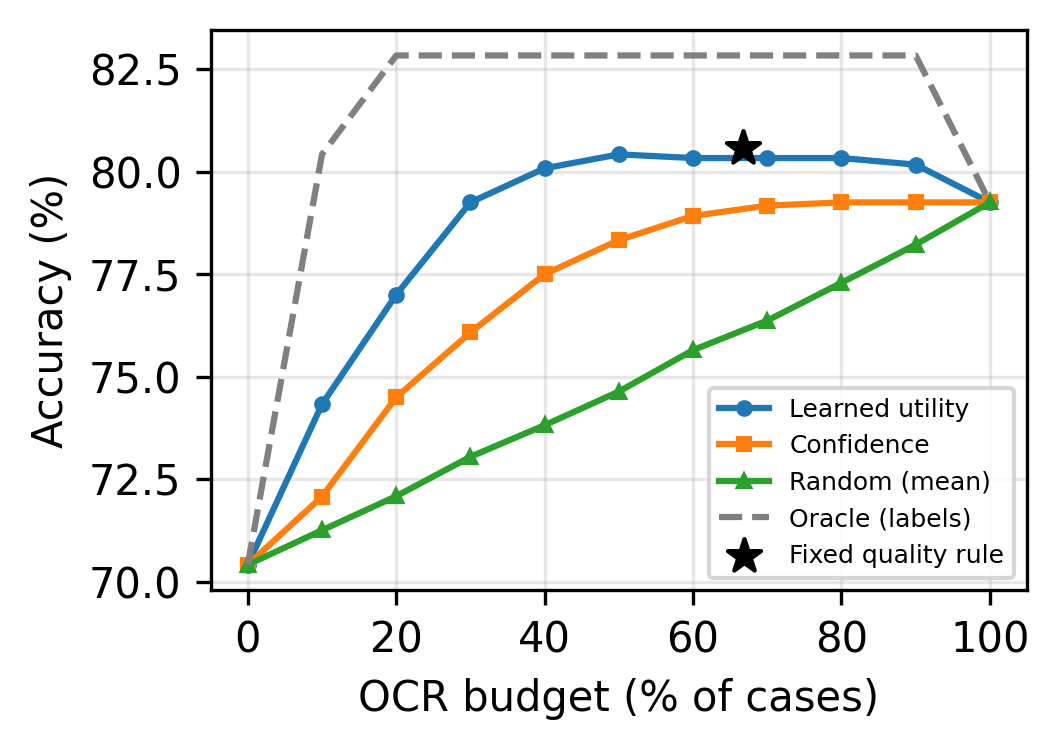

In [8]:
import matplotlib.pyplot as plt

b  = [0,10,20,30,40,50,60,70,80,90,100]
lu = [70.42,74.33,77.00,79.25,80.08,80.42,80.33,80.33,80.33,80.17,79.25]
cf = [70.42,72.08,74.50,76.08,77.50,78.33,78.92,79.17,79.25,79.25,79.25]
rd = [70.42,71.26,72.09,73.05,73.82,74.64,75.65,76.37,77.29,78.22,79.25]
orc= [70.42,80.42,82.83,82.83,82.83,82.83,82.83,82.83,82.83,82.83,79.25]

plt.figure(figsize=(3.5,2.6), dpi=300)  # IEEE single column
plt.plot(b, lu, "o-", label="Learned utility", ms=3)
plt.plot(b, cf, "s-", label="Confidence", ms=3)
plt.plot(b, rd, "^-", label="Random (mean)", ms=3)
plt.plot(b, orc, "--", label="Oracle (labels)", color="gray")
plt.scatter([66.67], [80.58], marker="*", s=70, color="k", zorder=5,
            label="Fixed quality rule")
plt.xlabel("OCR budget (% of cases)")
plt.ylabel("Accuracy (%)")
plt.legend(fontsize=6); plt.grid(alpha=.3)
plt.tight_layout(); plt.savefig("fig_budget_curve.png")

In [12]:
# ============================================================
# MEASURED LATENCY FOR THE CLEAN-CNN EXPERIMENT
#
# - Uses your original source images and saved checkpoint.
# - Rebuilds the original text classifier and quality detector.
# - Rebuilds and verifies the five fold-trained utility models.
# - Measures each policy sequentially on the same sampled cases.
# - OCR and text classification are actually run for each policy.
#
# IMPORTANT:
# Confidence and utility decisions are replayed from rankings
# over the complete 1,200-case panel. Ranking time is excluded.
# This is NOT a fixed-threshold streaming deployment test.
# ============================================================

import os
os.environ["OMP_THREAD_LIMIT"] = "1"

import ast
import hashlib
import json
import time
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import pytesseract
import torch
import torch.nn as nn
import torchvision.transforms as T

from PIL import Image, ImageFilter
from sklearn.ensemble import (
    RandomForestClassifier,
    RandomForestRegressor,
)
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from torchvision import models
from tqdm.auto import tqdm


# ------------------------------------------------------------
# 1. SETTINGS
# ------------------------------------------------------------

ROOT = Path("/kaggle/working/rvlcdip_baseline")
PILOT = ROOT / "four_class_original_pilot"

TRAIN_MANIFEST = PILOT / "four_class_manifest.csv"
TRAIN_OCR_CACHE = ROOT / "ocr_cache.jsonl"

DEV_FEATURES = (
    PILOT
    / "blur_noise_detector_routing_v1"
    / "paired_predictions_and_features.csv"
)

FRESH_ROOT = (
    PILOT / "fresh_source_alpha075_evaluation"
)

FRESH_MANIFEST = (
    FRESH_ROOT / "fresh_source_manifest.csv"
)

ORIGINAL_OUT = (
    PILOT / "clean_cnn_standard_preprocessing_v1"
)

CHECKPOINT = ORIGINAL_OUT / "clean_cnn_epoch8.pt"
RUN_CONFIG = ORIGINAL_OUT / "run_config.json"
PREDICTIONS = ORIGINAL_OUT / "all_predictions.csv"

UTILITY_OUT = Path(
    "/kaggle/working/"
    "utility_ablation_leave_condition_out_v1"
)

OOF_PATH = UTILITY_OUT / "out_of_fold_scores.csv"

OUT = Path(
    "/kaggle/working/measured_latency_clean_cnn_v1"
)

IMAGE_CACHE = OUT / "temporary_images"

OUT.mkdir(parents=True, exist_ok=True)
IMAGE_CACHE.mkdir(parents=True, exist_ok=True)

# Change to 40 for a shorter pilot.
# Must be divisible by four.
N_SOURCES = 100

BUDGET = 0.50
SEED = 42
N_BOOTSTRAPS = 2000

OCR_CONFIG = "--oem 1 --psm 6"
OCR_TIMEOUT = 120

MAIN_CONDITIONS = [
    "clean",
    "blur_3",
    "noise_28",
]

# One device by default. Tesseract itself runs on the CPU.
DEVICES = (
    ["cuda"]
    if torch.cuda.is_available()
    else ["cpu"]
)

# To benchmark both, change the line above to:
# DEVICES = ["cpu", "cuda"]

required_files = [
    TRAIN_MANIFEST,
    TRAIN_OCR_CACHE,
    DEV_FEATURES,
    FRESH_MANIFEST,
    CHECKPOINT,
    RUN_CONFIG,
    PREDICTIONS,
    OOF_PATH,
]

missing = [
    str(path)
    for path in required_files
    if not path.is_file()
]

if missing:
    raise FileNotFoundError(
        "Missing required files:\n"
        + "\n".join(missing)
    )

if N_SOURCES <= 0 or N_SOURCES % 4 != 0:
    raise ValueError(
        "N_SOURCES must be positive and divisible by four."
    )

print("Output:", OUT)
print("Devices:", DEVICES)
print("Sources:", N_SOURCES)
print("Budget on complete main panel:", BUDGET)
print("Tesseract:", pytesseract.get_tesseract_version())


# ------------------------------------------------------------
# 2. HELPERS AND ORIGINAL INPUT HASH CHECKS
# ------------------------------------------------------------

def sha256_file(path):
    digest = hashlib.sha256()

    with open(path, "rb") as handle:
        for chunk in iter(lambda: handle.read(1 << 20), b""):
            digest.update(chunk)

    return digest.hexdigest()


def stable_seed(*parts):
    digest = hashlib.sha256(
        "|".join(map(str, parts)).encode()
    ).digest()

    return int.from_bytes(
        digest[:8],
        "little",
    ) % (2 ** 32)


def parse_vector(value):
    if isinstance(value, str):
        value = ast.literal_eval(value)

    values = np.asarray(value, dtype=float)

    if values.shape != (4,) or not np.isfinite(values).all():
        raise ValueError(
            "Invalid probability vector."
        )

    return values


def resolve_image_path(value):
    value = str(value)

    candidates = [
        Path(value),
        ROOT / value,
        PILOT / value,
        FRESH_ROOT / value,
        FRESH_ROOT / "images" / value,
        Path("/kaggle/working") / value,
        Path("/kaggle/input") / value,
    ]

    for candidate in candidates:
        if candidate.is_file():
            return candidate

    raise FileNotFoundError(
        f"Cannot resolve source image: {value}"
    )


config = json.loads(
    RUN_CONFIG.read_text()
)

hash_checks = {
    "training_manifest": TRAIN_MANIFEST,
    "training_ocr_cache": TRAIN_OCR_CACHE,
    "detector_development_features": DEV_FEATURES,
    "fresh_manifest": FRESH_MANIFEST,
}

for name, path in hash_checks.items():
    expected = config.get("hashes", {}).get(name)

    if expected is None:
        raise RuntimeError(
            f"Run configuration lacks hash: {name}"
        )

    actual = sha256_file(path)

    if actual != expected:
        raise RuntimeError(
            f"Input hash mismatch: {name}\n"
            "Do not mix artifacts from different runs."
        )

print("Original input hashes verified.")


# ------------------------------------------------------------
# 3. RESTORE THE ORIGINAL VISUAL MODEL
# ------------------------------------------------------------

net = models.efficientnet_b0(weights=None)
net.classifier[1] = nn.Linear(
    net.classifier[1].in_features,
    4,
)

checkpoint = torch.load(
    CHECKPOINT,
    map_location="cpu",
    weights_only=False,
)

if not isinstance(checkpoint, dict) or "model" not in checkpoint:
    raise RuntimeError(
        "Unexpected checkpoint format: expected a dict "
        "containing the 'model' state dictionary."
    )

if checkpoint.get("run_config") != config:
    raise RuntimeError(
        "Checkpoint configuration differs from run_config.json."
    )

net.load_state_dict(
    checkpoint["model"],
    strict=True,
)

net.eval()

prep = T.Compose([
    T.Resize((224, 224)),
    T.ToTensor(),
    T.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225],
    ),
])


# ------------------------------------------------------------
# 4. REBUILD THE ORIGINAL TEXT CLASSIFIER
# ------------------------------------------------------------

manifest = pd.read_csv(
    TRAIN_MANIFEST,
    dtype={"id": str},
)

train = manifest[
    manifest["split"].astype(str).str.lower() == "train"
].copy()

train["label_4"] = pd.to_numeric(
    train["label_4"],
    errors="raise",
).astype(int)

train = train.sort_values(
    ["label_4", "id"]
).reset_index(drop=True)

if len(train) != 1280 or train["id"].duplicated().any():
    raise RuntimeError(
        "Training manifest does not contain the expected "
        "1,280 unique training sources."
    )

clean_ocr = {}

with TRAIN_OCR_CACHE.open(
    "r",
    encoding="utf-8",
) as handle:
    for line in handle:
        if not line.strip():
            continue

        record = json.loads(line)

        try:
            doc_id, condition, severity = record["key"].rsplit(
                "|",
                2,
            )
        except (KeyError, ValueError):
            continue

        if condition == "clean" and severity == "0":
            clean_ocr[str(doc_id)] = str(
                record.get("text", "")
            )

missing_ocr = [
    doc_id
    for doc_id in train["id"]
    if doc_id not in clean_ocr
]

if missing_ocr:
    raise RuntimeError(
        f"Missing cached OCR for {len(missing_ocr)} "
        "training documents."
    )

training_text = [
    clean_ocr[doc_id]
    if clean_ocr[doc_id].strip()
    else "<EMPTY_OCR>"
    for doc_id in train["id"]
]

vectorizer = TfidfVectorizer(
    max_features=8000,
    ngram_range=(1, 2),
    min_df=1,
)

text_model = LogisticRegression(
    C=3.0,
    max_iter=2000,
)

text_model.fit(
    vectorizer.fit_transform(training_text),
    train["label_4"].to_numpy(dtype=int),
)

if not np.array_equal(
    text_model.classes_,
    np.array([0, 1, 2, 3]),
):
    raise RuntimeError(
        f"Unexpected text classes: {text_model.classes_}"
    )

print("Text classifier rebuilt.")


# ------------------------------------------------------------
# 5. REBUILD THE ORIGINAL QUALITY DETECTOR
# ------------------------------------------------------------

FEATURE_NAMES = [
    "laplacian_variance",
    "laplacian_abs_mean",
    "gradient_mean",
    "gradient_std",
    "residual_std",
    "residual_abs_mean",
    "contrast_std",
    "edge_fraction",
    "bright_fraction",
    "entropy",
]

dev_features = pd.read_csv(
    DEV_FEATURES,
    dtype={"id": str},
)

dev_features["condition"] = (
    dev_features["condition"]
    .astype(str)
    .str.lower()
)

if set(dev_features["condition"]) != {
    "clean",
    "blur",
    "noise",
}:
    raise RuntimeError(
        "Unexpected quality-detector training conditions."
    )

detector = RandomForestClassifier(
    n_estimators=200,
    max_depth=6,
    min_samples_leaf=3,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1,
)

detector.fit(
    dev_features[FEATURE_NAMES],
    dev_features["condition"],
)

print("Quality detector rebuilt.")


# ------------------------------------------------------------
# 6. LOAD SAVED PREDICTIONS AND OOF SCORES
# ------------------------------------------------------------

pred = pd.read_csv(
    PREDICTIONS,
    dtype={"id": str},
)

oof = pd.read_csv(
    OOF_PATH,
    dtype={"id": str},
)

pred = pred[
    pred["condition"].isin(MAIN_CONDITIONS)
].copy()

oof = oof[
    oof["condition"].isin(MAIN_CONDITIONS)
].copy()

if pred.duplicated(["id", "condition"]).any():
    raise RuntimeError("Duplicate prediction records.")

if oof.duplicated(["id", "condition"]).any():
    raise RuntimeError("Duplicate OOF records.")

extra_columns = ["id",
    "condition",
    "image_sha256",
    "image_probabilities",
    "text_probabilities",]

main = oof.merge(
    pred[extra_columns],
    on=["id", "condition"],
    how="inner",
    validate="one_to_one",
)

main = main.sort_values(
    ["id", "condition"]
).reset_index(drop=True)

if len(main) != 1200 or main["id"].nunique() != 400:
    raise RuntimeError(
        "Expected 400 sources and 1,200 main-panel cases."
    )

if not main.groupby("id")["condition"].nunique().eq(3).all():
    raise RuntimeError(
        "A source is missing a main-panel condition."
    )

if not main.groupby("id")["fold"].nunique().eq(1).all():
    raise RuntimeError(
        "A source appears in more than one OOF fold."
    )

probabilities = np.stack(
    main["image_probabilities"].map(parse_vector)
)

confidence = main["image_conf"].to_numpy(dtype=float)

condition_features = pd.get_dummies(
    main["predicted_condition"]
    .astype(str)
    .str.lower()
).reindex(
    columns=["clean", "blur", "noise"],
    fill_value=0,
).to_numpy(dtype=float)

utility_features = np.column_stack([
    probabilities,
    confidence,
    condition_features,
])

labels = main["label"].to_numpy(dtype=int)

image_correct = (
    main["image_pred"].to_numpy(dtype=int) == labels
).astype(int)

fusion_correct = (
    main["fusion_pred"].to_numpy(dtype=int) == labels
).astype(int)

gain = fusion_correct - image_correct
folds = main["fold"].to_numpy(dtype=int)
groups = main["id"].to_numpy()

if set(folds) != {1, 2, 3, 4, 5}:
    raise RuntimeError(
        f"Unexpected fold IDs: {set(folds)}"
    )


# ------------------------------------------------------------
# 7. REBUILD AND VERIFY THE FIVE UTILITY MODELS
# ------------------------------------------------------------

utility_models = {}
rebuilt_scores = np.empty(len(main), dtype=float)

for fold in sorted(set(folds)):
    training = folds != fold
    testing = folds == fold

    if set(groups[training]) & set(groups[testing]):
        raise RuntimeError(
            f"Source overlap in fold {fold}."
        )

    router = RandomForestRegressor(
        n_estimators=150,
        max_depth=5,
        min_samples_leaf=10,
        random_state=42,
        n_jobs=-1,
    )

    router.fit(
        utility_features[training],
        gain[training],
    )

    rebuilt_scores[testing] = router.predict(
        utility_features[testing]
    )

    utility_models[fold] = router

saved_scores = main["full_score"].to_numpy(dtype=float)

max_score_difference = float(
    np.max(np.abs(rebuilt_scores - saved_scores))
)

print(
    "Maximum rebuilt OOF score difference:",
    max_score_difference,
)

if not np.allclose(
    rebuilt_scores,
    saved_scores,
    rtol=1e-7,
    atol=1e-8,
):
    raise RuntimeError(
        "Rebuilt utility scores do not match the saved run. "
        "Check the inputs and software versions before timing."
    )

print("Five original utility models rebuilt and verified.")


# ------------------------------------------------------------
# 8. FREEZE OFFLINE FULL-PANEL ROUTING DECISIONS
# ------------------------------------------------------------

count = round(BUDGET * len(main))

def select_by_order(order, count):
    selected = np.zeros(len(order), dtype=bool)
    selected[order[:count]] = True
    return selected


utility_order = np.argsort(
    -saved_scores,
    kind="stable",
)

confidence_order = np.argsort(
    confidence,
    kind="stable",
)

main["sel_utility"] = select_by_order(
    utility_order,
    count,
)

main["sel_confidence"] = select_by_order(
    confidence_order,
    count,
)

main["sel_quality"] = (
    main["predicted_condition"]
    .astype(str)
    .str.lower()
    != "blur"
)

# Exact 50% applies to the complete 1,200-case panel.
print(
    "Full-panel utility OCR usage:",
    100 * main["sel_utility"].mean(),
)


# ------------------------------------------------------------
# 9. SELECT BALANCED SOURCE DOCUMENTS
# ------------------------------------------------------------

source_rows = main.drop_duplicates("id")

class_counts = source_rows.groupby("label").size()

if set(class_counts.index) != {0, 1, 2, 3}:
    raise RuntimeError(
        f"Unexpected source classes: {class_counts}"
    )

per_class = N_SOURCES // 4

if (class_counts < per_class).any():
    raise RuntimeError(
        "Not enough sources in one or more classes."
    )

sample_ids = pd.concat([group.sample(
        n=per_class,
        random_state=SEED,
    )
    for _, group in source_rows.groupby("label", sort=True)])["id"]

sample = main[
    main["id"].isin(sample_ids)
].copy().reset_index(drop=True)

if (
    sample["id"].nunique() != N_SOURCES
    or len(sample) != N_SOURCES * 3
):
    raise RuntimeError(
        "Unexpected sampled source or case count."
    )

print(
    "Sample:",
    sample["id"].nunique(),
    "sources;",
    len(sample),
    "cases.",
)

print(
    "Sample utility OCR usage:",
    round(100 * sample["sel_utility"].mean(), 2),
    "%",
)

print(
    "Sample confidence OCR usage:",
    round(100 * sample["sel_confidence"].mean(), 2),
    "%",
)

print(
    "Sample quality-rule OCR usage:",
    round(100 * sample["sel_quality"].mean(), 2),
    "%",
)


# ------------------------------------------------------------
# 10. RECREATE THE ORIGINAL MAIN-PANEL CONDITIONS
# ------------------------------------------------------------

fresh = pd.read_csv(
    FRESH_MANIFEST,
    dtype={"id": str},
)

if fresh["id"].duplicated().any():
    raise RuntimeError(
        "Duplicate IDs in fresh-source manifest."
    )

path_columns = [
    name for name in [
        "image_path",
        "local_path",
        "cached_path",
        "path",
    ]
    if name in fresh.columns
]

if not path_columns:
    raise RuntimeError(
        "No recognized image-path column in fresh manifest."
    )

fresh_path_column = path_columns[0]
fresh = fresh.set_index("id")


def make_condition(clean_image, doc_id, condition):

    if condition == "clean":
        return clean_image.copy()

    if condition == "blur_3":
        return clean_image.filter(
            ImageFilter.GaussianBlur(radius=3.0)
        )

    if condition == "noise_28":
        rng = np.random.default_rng(
            stable_seed(
                "final_v2",
                doc_id,
                condition,
            )
        )

        array = np.asarray(
            clean_image,
            dtype=np.float32,
        )

        noise = rng.normal(
            0.0,
            28.0,
            size=array.shape,
        )

        result = np.clip(
            array + noise,
            0,
            255,
        ).astype(np.uint8)

        return Image.fromarray(result)

    raise ValueError(condition)


def image_quality_features(image):
    gray = cv2.cvtColor(
        np.asarray(image.convert("RGB")),
        cv2.COLOR_RGB2GRAY,
    )

    height, width = gray.shape

    scale = min(
        1.0,
        1500.0 / max(height, width),
    )

    if scale < 1.0:
        gray = cv2.resize(
            gray,
            (
                max(1, int(round(width * scale))),
                max(1, int(round(height * scale))),
            ),
            interpolation=cv2.INTER_AREA,
        )

    gray_float = gray.astype(np.float32)

    lap = cv2.Laplacian(
        gray_float,
        cv2.CV_32F,
        ksize=3,
    )

    gx = cv2.Sobel(
        gray_float,
        cv2.CV_32F,
        1,
        0,
        ksize=3,
    )

    gy = cv2.Sobel(
        gray_float,
        cv2.CV_32F,
        0,
        1,
        ksize=3,
    )

    gradient = cv2.magnitude(gx, gy)

    smoothed = cv2.GaussianBlur(
        gray_float,
        (3, 3),
        0,
    )

    residual = gray_float - smoothed
    edges = cv2.Canny(gray, 50, 150)

    histogram = np.histogram(
        gray,
        bins=256,
        range=(0, 256),
    )[0].astype(np.float64)

    histogram = histogram / max(
        histogram.sum(),
        1.0,
    )

    histogram = histogram[histogram > 0]

    entropy = -np.sum(
        histogram * np.log2(histogram)
    )

    return [
        float(lap.var()),
        float(np.abs(lap).mean()),
        float(gradient.mean()),
        float(gradient.std()),
        float(residual.std()),
        float(np.abs(residual).mean()),
        float(gray_float.std()),
        float((edges > 0).mean()),
        float((gray >= 235).mean()),
        float(entropy),
    ]


def cache_path(doc_id, condition):
    name = hashlib.sha256(
        f"{doc_id}|{condition}".encode()
    ).hexdigest()

    return IMAGE_CACHE / f"{name}.png"


# Recreate cached PNGs from verified original sources.
for doc_id, group in tqdm(
    sample.groupby("id", sort=True),
    total=N_SOURCES,
    desc="Preparing benchmark images",
):
    if doc_id not in fresh.index:
        raise RuntimeError(
            f"Source missing from fresh manifest: {doc_id}"
        )

    source_path = resolve_image_path(
        fresh.loc[doc_id, fresh_path_column]
    )

    source_hash = sha256_file(source_path)

    expected_hashes = set(
        group["image_sha256"].astype(str)
    )

    if expected_hashes != {source_hash}:
        raise RuntimeError(
            f"Source hash mismatch: {doc_id}"
        )

    with Image.open(source_path) as opened:
        clean_image = opened.convert("RGB").copy()

    for condition in group["condition"]:
        image = make_condition(
            clean_image,
            doc_id,
            condition,
        )

        # Rewritten to avoid using a stale cached image.
        image.save(
            cache_path(doc_id, condition),
            format="PNG",
        )

print("Benchmark images prepared.")


# ------------------------------------------------------------
# 11. DIRECT SEQUENTIAL POLICY EXECUTION
# ------------------------------------------------------------

POLICIES = [
    "image_only",
    "always_fusion",
    "confidence_replay",
    "quality_rule",
    "utility_replay",
]

CONDITION_NAMES = [
    "clean",
    "blur",
    "noise",
]


def sync(device):
    if device == "cuda":
        torch.cuda.synchronize()


def load_cached(doc_id, condition):
    with Image.open(
        cache_path(doc_id, condition)
    ) as opened:
        opened.load()
        return opened.convert("RGB").copy()


@torch.inference_mode()
def visual_probabilities(image, device):
    tensor = prep(image).unsqueeze(0).to(device)

    logits = net(tensor)

    return torch.softmax(
        logits,
        dim=1,
    )[0].cpu().numpy()


def run_policy(row, policy, device):
    """
    Times one sequential policy execution.

    Confidence and utility use previously determined
    full-panel routing decisions. Ranking itself is excluded.
    """

    stages = {
        "load_s": np.nan,
        "quality_features_s": np.nan,
        "quality_detector_s": np.nan,
        "cnn_s": np.nan,
        "utility_score_s": np.nan,
        "ocr_s": np.nan,
        "text_classifier_s": np.nan,
    }

    sync(device)
    total_start = time.perf_counter()

    start = time.perf_counter()
    image = load_cached(
        row["id"],
        row["condition"],
    )
    stages["load_s"] = time.perf_counter() - start

    predicted_condition = None

    if policy in {"quality_rule", "utility_replay"}:
        start = time.perf_counter()
        features = image_quality_features(image)
        stages["quality_features_s"] = (
            time.perf_counter() - start
        )

        feature_frame = pd.DataFrame(
            [features],
            columns=FEATURE_NAMES,
        )

        start = time.perf_counter()
        predicted_condition = str(
            detector.predict(feature_frame)[0]
        )
        stages["quality_detector_s"] = (
            time.perf_counter() - start
        )

    sync(device)
    start = time.perf_counter()

    image_probs = visual_probabilities(
        image,
        device,
    )

    sync(device)
    stages["cnn_s"] = time.perf_counter() - start

    utility_score = None

    if policy == "utility_replay":
        if predicted_condition not in CONDITION_NAMES:
            raise RuntimeError(
                f"Unexpected detector prediction: "
                f"{predicted_condition}"
            )

        condition_one_hot = np.eye(3)[
            CONDITION_NAMES.index(predicted_condition)
        ]

        utility_input = np.concatenate([
            image_probs,
            [float(image_probs.max())],
            condition_one_hot,
        ]).reshape(1, -1)

        start = time.perf_counter()
        utility_score = float(
            utility_models[int(row["fold"])].predict(
                utility_input
            )[0]
        )
        stages["utility_score_s"] = (
            time.perf_counter() - start
        )

    if policy == "image_only":
        use_ocr = False

    elif policy == "always_fusion":
        use_ocr = True

    elif policy == "confidence_replay":
        use_ocr = bool(row["sel_confidence"])

    elif policy == "quality_rule":
        use_ocr = predicted_condition != "blur"

    elif policy == "utility_replay":
        use_ocr = bool(row["sel_utility"])

    else:
        raise ValueError(policy)

    text_probs = None

    if use_ocr:
        start = time.perf_counter()

        try:
            text = pytesseract.image_to_string(
                image,
                config=OCR_CONFIG,
                timeout=OCR_TIMEOUT,
            )
        except RuntimeError as exc:
            raise RuntimeError(
                f"OCR failed or timed out for "
                f"{row['id']} / {row['condition']}. "
                "No empty-text latency result was substituted."
            ) from exc

        stages["ocr_s"] = time.perf_counter() - start

        if not text.strip():
            text = "<EMPTY_OCR>"

        start = time.perf_counter()

        text_probs = text_model.predict_proba(
            vectorizer.transform([text])
        )[0]

        stages["text_classifier_s"] = (
            time.perf_counter() - start
        )

        final_probs = (
            0.5 * image_probs
            + 0.5 * text_probs
        )

    else:
        final_probs = image_probs

    prediction = int(np.argmax(final_probs))

    sync(device)
    total_s = time.perf_counter() - total_start

    return {
        "total_s": total_s,
        "stages": stages,
        "prediction": prediction,
        "use_ocr": use_ocr,
        "image_probs": image_probs,
        "text_probs": text_probs,
        "predicted_condition": predicted_condition,
        "utility_score": utility_score,
    }


# ------------------------------------------------------------
# 12. WARM-UP AND BENCHMARK
# ------------------------------------------------------------

records = []
rng = np.random.default_rng(SEED)

for device in DEVICES:

    if device == "cuda" and not torch.cuda.is_available():
        raise RuntimeError(
            "CUDA requested but unavailable."
        )

    net.to(device)
    net.eval()

    # Warm-up is excluded from reported measurements.
    for _, row in sample.head(2).iterrows():
        run_policy(row, "image_only", device)
        run_policy(row, "quality_rule", device)

    warm_row = sample.iloc[0]
    run_policy(warm_row, "always_fusion", device)
    run_policy(warm_row, "utility_replay", device)

    print(f"\nWarm-up complete: {device}")

    for index, (_, row) in enumerate(
        tqdm(
            sample.iterrows(),
            total=len(sample),
            desc=f"Timing {device}",
        ),
        start=1,
    ):
        policy_order = rng.permutation(POLICIES)

        for policy in policy_order:
            result = run_policy(
                row,
                policy,
                device,
            )

            cached_image_probs = parse_vector(
                row["image_probabilities"]
            )

            visual_matches = bool(
                np.allclose(
                    result["image_probs"],
                    cached_image_probs,
                    rtol=1e-4,
                    atol=1e-4,
                )
            )

            detector_matches = True

            if result["predicted_condition"] is not None:
                detector_matches = (
                    result["predicted_condition"]
                    == str(
                        row["predicted_condition"]
                    ).lower()
                )

            utility_score_matches = True

            if result["utility_score"] is not None:
                utility_score_matches = bool(
                    np.isclose(
                        result["utility_score"],
                        float(row["full_score"]),
                        rtol=1e-4,
                        atol=1e-4,
                    )
                )

            text_matches = None

            if result["text_probs"] is not None:
                cached_text_probs = parse_vector(
                    row["text_probabilities"]
                )

                text_matches = bool(
                    np.allclose(
                        result["text_probs"],
                        cached_text_probs,
                        rtol=1e-4,
                        atol=1e-4,
                    )
                )

            record = {
                "device": device,
                "id": str(row["id"]),
                "label": int(row["label"]),
                "condition": str(row["condition"]),
                "policy": policy,
                "total_s": result["total_s"],
                "prediction": result["prediction"],
                "correct": int(
                    result["prediction"] == int(row["label"])
                ),
                "use_ocr": int(result["use_ocr"]),
                "visual_matches_cache": visual_matches,
                "detector_matches_cache": detector_matches,
                "utility_score_matches_cache": utility_score_matches,
                "text_matches_cache": text_matches,
            }

            record.update(result["stages"])
            records.append(record)


measurements = pd.DataFrame(records)


# ------------------------------------------------------------
# 13. SUMMARY AND SOURCE-LEVEL BOOTSTRAP
# ------------------------------------------------------------

summary_rows = []

for device, device_data in measurements.groupby("device"):

    policy_matrix = device_data.pivot(
        index=["id", "label", "condition"],
        columns="policy",
        values="total_s",
    )

    if policy_matrix.isna().any().any():
        raise RuntimeError(
            f"Missing timed policy cases for {device}."
        )

    # Average the three conditions within each source.
    per_source = (
        policy_matrix
        .reset_index()
        .groupby(["id", "label"])[POLICIES]
        .mean()
        .reset_index()
    )

    bootstrap_rng = np.random.default_rng(SEED)

    draws = np.zeros(
        (N_BOOTSTRAPS, len(POLICIES)),
        dtype=float,
    )

    for label, group in per_source.groupby("label", sort=True):
        values = group[POLICIES].to_numpy(dtype=float)

        indices = bootstrap_rng.integers(
            0,
            len(values),
            size=(N_BOOTSTRAPS, len(values)),
        )

        draws += values[indices].sum(axis=1)

    draws /= len(per_source)

    baseline_index = POLICIES.index("always_fusion")
    speedup_draws = (
        draws[:, baseline_index, None] / draws
    )

    for policy_index, policy in enumerate(POLICIES):

        subset = device_data[
            device_data["policy"] == policy
        ]

        baseline_mean = device_data[
            device_data["policy"] == "always_fusion"
        ]["total_s"].mean()

        mean_s = subset["total_s"].mean()

        summary_rows.append({
            "device": device,
            "policy": policy,
            "cases": len(subset),
            "ocr_pct": 100 * subset["use_ocr"].mean(),
            "accuracy_pct": 100 * subset["correct"].mean(),
            "mean_s": mean_s,
            "median_s": subset["total_s"].median(),
            "p95_s": subset["total_s"].quantile(0.95),
            "speedup_vs_always": baseline_mean / mean_s,
            "speedup_ci_low": np.percentile(
                speedup_draws[:, policy_index],
                2.5,
            ),
            "speedup_ci_high": np.percentile(
                speedup_draws[:, policy_index],
                97.5,
            ),
        })

summary = pd.DataFrame(summary_rows)

stage_columns = [
    "load_s",
    "quality_features_s",
    "quality_detector_s",
    "cnn_s",
    "utility_score_s",
    "ocr_s",
    "text_classifier_s",
]

stage_summary = (
    measurements
    .groupby(["device", "policy"])[stage_columns]
    .mean()
    .reset_index()
)

print("\n=== DIRECTLY MEASURED POLICY LATENCY ===")
print(summary.round(3).to_string(index=False))

print("\n=== MEAN STAGE TIMES, WHEN THE STAGE RAN ===")
print(stage_summary.round(4).to_string(index=False))

print("\n=== CHECKS AGAINST CACHED PREDICTIONS ===")

for column in [
    "visual_matches_cache",
    "detector_matches_cache",
    "utility_score_matches_cache",
    "text_matches_cache",
]:
    checked = measurements[column].dropna()

    if len(checked):
        mismatches = int(
            (~checked.astype(bool)).sum()
        )

        print(
            f"{column}: {mismatches} mismatches "
            f"out of {len(checked)} checks"
        )


# ------------------------------------------------------------
# 14. SAVE RESULTS
# ------------------------------------------------------------

measurements.to_csv(
    OUT / "latency_per_case.csv",
    index=False,
)

summary.to_csv(
    OUT / "latency_summary.csv",
    index=False,
)

stage_summary.to_csv(
    OUT / "latency_stage_summary.csv",
    index=False,
)

metadata = {
    "n_sources": N_SOURCES,
    "conditions": MAIN_CONDITIONS,
    "full_panel_budget": BUDGET,
    "devices": DEVICES,
    "gpu_name": (
        torch.cuda.get_device_name(0)
        if torch.cuda.is_available()
        else None
    ),
    "cpu_cores": os.cpu_count(),
    "torch_version": str(torch.__version__),
    "tesseract_version": str(
        pytesseract.get_tesseract_version()
    ),
    "ocr_config": OCR_CONFIG,
    "ocr_timeout_seconds": OCR_TIMEOUT,
    "utility_score_max_rebuild_difference": max_score_difference,
    "ranking": "offline full-panel replay; ranking time excluded",
    "image_input": "pre-generated cached PNG; image loading included",
    "corruption_generation_in_timing": False,
    "warmup_in_timing": False,
    "bootstrap": (
        "class-stratified source-level; "
        "fixed policy decisions; no retraining"
    ),
}

(OUT / "benchmark_config.json").write_text(
    json.dumps(metadata, indent=2)
)

print("\nSaved to:", OUT)

print(
    "\nIMPORTANT: Confidence and utility decisions were "
    "replayed from full-panel offline rankings. Ranking and "
    "corruption generation are excluded. The timed path includes "
    "cached-image loading, applicable model stages, OCR when "
    "selected, text classification and final prediction."
)

print(
    "If prediction checks show mismatches, do not claim the "
    "timed run exactly reproduces the original predictions."
)

print(
    "Temporary PNGs and per-case files may contain sensitive "
    "document information or identifiers. Do not publish them "
    "without checking permissions and privacy."
)

Output: /kaggle/working/measured_latency_clean_cnn_v1
Devices: ['cuda']
Sources: 100
Budget on complete main panel: 0.5
Tesseract: 5.3.4
Original input hashes verified.
Text classifier rebuilt.
Quality detector rebuilt.
Maximum rebuilt OOF score difference: 2.7755575615628914e-16
Five original utility models rebuilt and verified.
Full-panel utility OCR usage: 50.0
Sample: 100 sources; 300 cases.
Sample utility OCR usage: 46.0 %
Sample confidence OCR usage: 44.67 %
Sample quality-rule OCR usage: 66.67 %


Preparing benchmark images:   0%|          | 0/100 [00:00<?, ?it/s]

Benchmark images prepared.

Warm-up complete: cuda


Timing cuda:   0%|          | 0/300 [00:00<?, ?it/s]


=== DIRECTLY MEASURED POLICY LATENCY ===
device            policy  cases  ocr_pct  accuracy_pct  mean_s  median_s  p95_s  speedup_vs_always  speedup_ci_low  speedup_ci_high
  cuda        image_only    300    0.000        71.333   0.031     0.030  0.039             36.026          33.447           38.927
  cuda     always_fusion    300  100.000        80.667   1.127     0.940  2.840              1.000           1.000            1.000
  cuda confidence_replay    300   44.667        79.667   0.510     0.037  1.875              2.211           1.876            2.682
  cuda      quality_rule    300   66.667        81.333   1.065     0.978  2.916              1.059           1.047            1.074
  cuda    utility_replay    300   46.000        81.000   0.772     0.171  2.208              1.461           1.335            1.622

=== MEAN STAGE TIMES, WHEN THE STAGE RAN ===
device            policy  load_s  quality_features_s  quality_detector_s  cnn_s  utility_score_s  ocr_s  text_classifier

In [14]:
# ============================================================
# EXPLORATORY COST-AWARE OCR ROUTER
#
# Uses the 100-source latency sample and saved OOF predictions.
# No new OCR and no CNN training.
#
# All rankings are offline. OCR cost excludes router overhead.
# These sources were previously examined.
# ============================================================

import ast
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestRegressor


# ------------------------------------------------------------
# 1. INPUTS
# ------------------------------------------------------------

ROOT = Path("/kaggle/working/rvlcdip_baseline")
PILOT = ROOT / "four_class_original_pilot"

PRED_PATH = (
    PILOT
    / "clean_cnn_standard_preprocessing_v1"
    / "all_predictions.csv"
)

OOF_PATH = Path(
    "/kaggle/working/"
    "utility_ablation_leave_condition_out_v1/"
    "out_of_fold_scores.csv"
)

LATENCY_PATH = Path(
    "/kaggle/working/"
    "measured_latency_clean_cnn_v1/"
    "latency_per_case.csv"
)

OUT = Path(
    "/kaggle/working/cost_aware_ocr_exploratory_v1"
)

OUT.mkdir(parents=True, exist_ok=True)

for path in [PRED_PATH, OOF_PATH, LATENCY_PATH]:
    if not path.is_file():
        raise FileNotFoundError(
            f"Required file not found: {path}"
        )


# ------------------------------------------------------------
# 2. LOAD THE SAME 100 SOURCES USED IN THE TIMING TEST
# ------------------------------------------------------------

pred = pd.read_csv(
    PRED_PATH,
    dtype={"id": str},
)

oof = pd.read_csv(
    OOF_PATH,
    dtype={"id": str},
)

latency = pd.read_csv(
    LATENCY_PATH,
    dtype={"id": str},
)

# Use a single device's always-fusion measurements.
devices = latency["device"].dropna().unique().tolist()

if "cuda" in devices:
    device = "cuda"
elif "cpu" in devices:
    device = "cpu"
else:
    raise RuntimeError(
        f"No recognized device found: {devices}"
    )

timing = latency[
    (latency["device"] == device)
    & (latency["policy"] == "always_fusion")
].copy()

if timing.duplicated(["id", "condition"]).any():
    raise RuntimeError(
        "Duplicate always-fusion timing records."
    )

required_timing = {
    "id",
    "condition",
    "ocr_s",
    "text_classifier_s",
    "visual_matches_cache",
    "text_matches_cache",
}

missing = required_timing - set(timing.columns)

if missing:
    raise RuntimeError(
        f"Timing file is missing: {sorted(missing)}"
    )

for column in [
    "visual_matches_cache",
    "text_matches_cache",
]:
    values = (
        timing[column]
        .astype(str)
        .str.lower()
    )

    if not values.eq("true").all():
        raise RuntimeError(
            f"Cached-prediction check failed: {column}"
        )

if oof.duplicated(["id", "condition"]).any():
    raise RuntimeError(
        "Duplicate OOF prediction records."
    )

if pred.duplicated(["id", "condition"]).any():
    raise RuntimeError(
        "Duplicate original prediction records."
    )

main = {"clean", "blur_3", "noise_28"}

oof = oof[oof["condition"].isin(main)].copy()
pred = pred[pred["condition"].isin(main)].copy()
timing = timing[timing["condition"].isin(main)].copy()

data = (
    timing[
        [
            "id",
            "condition",
            "ocr_s",
            "text_classifier_s",
        ]
    ]
    .merge(
        oof,
        on=["id", "condition"],
        how="inner",
        validate="one_to_one",
    )
    .merge(
        pred[
            [
                "id",
                "condition",
                "image_probabilities",
            ]
        ],
        on=["id", "condition"],
        how="inner",
        validate="one_to_one",
    )
)

data = data.sort_values(
    ["id", "condition"]
).reset_index(drop=True)

if data["id"].nunique() != 100 or len(data) != 300:
    raise RuntimeError(
        f"Expected 100 sources and 300 cases; found "
        f"{data['id'].nunique()} sources and {len(data)} cases."
    )

if not data.groupby("id")["condition"].nunique().eq(3).all():
    raise RuntimeError(
        "A source is missing a main-panel condition."
    )

if not data.groupby("id")["fold"].nunique().eq(1).all():
    raise RuntimeError(
        "A source appears in multiple folds."
    )

print("Timing device:", device)
print("Sources:", data["id"].nunique())
print("Cases:", len(data))


# ------------------------------------------------------------
# 3. PRE-OCR FEATURES AND OBSERVED OCR COST
# ------------------------------------------------------------

def parse_vector(value):
    if isinstance(value, str):
        value = ast.literal_eval(value)

    values = np.asarray(value, dtype=float)

    if values.shape != (4,) or not np.isfinite(values).all():
        raise ValueError(
            "Invalid visual probability vector."
        )

    return values


probabilities = np.stack(
    data["image_probabilities"].map(parse_vector)
)

confidence = data["image_conf"].to_numpy(dtype=float)

condition_features = pd.get_dummies(
    data["predicted_condition"]
    .astype(str)
    .str.lower()
).reindex(
    columns=["clean", "blur", "noise"],
    fill_value=0,
).to_numpy(dtype=float)

# Available before OCR.
features = np.column_stack([
    probabilities,
    confidence,
    condition_features,
])

# Measured only after OCR; used as a training target and
# for retrospective evaluation, NEVER as an inference feature.
observed_cost = (
    data["ocr_s"].to_numpy(dtype=float)
    + data["text_classifier_s"].to_numpy(dtype=float)
)

if (
    not np.isfinite(observed_cost).all()
    or (observed_cost <= 0).any()
):
    raise RuntimeError(
        "Invalid observed OCR-stage timing."
    )

labels = data["label"].to_numpy(dtype=int)

image_correct = (
    data["image_pred"].to_numpy(dtype=int) == labels
).astype(int)

fusion_correct = (
    data["fusion_pred"].to_numpy(dtype=int) == labels
).astype(int)

utility_score = data["full_score"].to_numpy(dtype=float)
folds = data["fold"].to_numpy(dtype=int)
groups = data["id"].to_numpy()

if not np.isfinite(utility_score).all():
    raise RuntimeError("Invalid utility scores.")

if set(folds) != {1, 2, 3, 4, 5}:
    raise RuntimeError(
        f"Expected five folds; found {set(folds)}"
    )


# ------------------------------------------------------------
# 4. PREDICT OCR COST WITH SOURCE-SEPARATED FOLDS
# ------------------------------------------------------------

predicted_cost = np.full(len(data), np.nan)

for fold in sorted(set(folds)):
    training = folds != fold
    testing = folds == fold

    if set(groups[training]) & set(groups[testing]):
        raise RuntimeError(
            f"Source overlap in cost-model fold {fold}."
        )

    # Log target keeps predicted costs positive after inversion.
    cost_model = RandomForestRegressor(
        n_estimators=150,
        max_depth=5,
        min_samples_leaf=4,
        random_state=42,
        n_jobs=-1,
    )

    cost_model.fit(
        features[training],
        np.log1p(observed_cost[training]),
    )

    predicted_cost[testing] = np.maximum(
        np.expm1(
            cost_model.predict(features[testing])
        ),
        0.001,
    )

if not np.isfinite(predicted_cost).all():
    raise RuntimeError(
        "Some cases lack an out-of-fold cost prediction."
    )

mae = np.mean(
    np.abs(predicted_cost - observed_cost)
)

print(f"Mean measured OCR-stage cost: {observed_cost.mean():.3f} s")
print(f"Out-of-fold cost-prediction MAE: {mae:.3f} s")


# ------------------------------------------------------------
# 5. BUILD OFFLINE RANKINGS
# ------------------------------------------------------------

# Signed utility divided by predicted OCR time.
# This is a heuristic, not a claim of optimal routing.
cost_aware_score = utility_score / predicted_cost

orders = {
    "cost_aware": np.argsort(
        -cost_aware_score,
        kind="stable",
    ),

    "utility_only": np.argsort(
        -utility_score,
        kind="stable",
    ),

    "confidence": np.argsort(
        confidence,
        kind="stable",
    ),
}


def summarize(policy, budget_type, target, order, count):
    chosen = np.zeros(len(data), dtype=bool)
    chosen[order[:count]] = True

    correct = np.where(
        chosen,
        fusion_correct,
        image_correct,
    )

    return {
        "budget_type": budget_type,
        "target_pct": 100 * target,
        "policy": policy,
        "ocr_calls": int(chosen.sum()),
        "ocr_usage_pct": 100 * chosen.mean(),
        "accuracy_pct": 100 * correct.mean(),

        # Costs are retrospective sums of measured
        # always-fusion OCR + text-classifier stage times.
        "observed_ocr_cost_pct": (
            100
            * observed_cost[chosen].sum()
            / observed_cost.sum()
        ),

        "observed_ocr_seconds_per_case": (
            observed_cost[chosen].sum()
            / len(data)
        ),

        "predicted_ocr_cost_pct": (
            100
            * predicted_cost[chosen].sum()
            / predicted_cost.sum()
        ),
    }


# ------------------------------------------------------------
# 6. COMPARISON AT THE SAME NUMBER OF OCR CALLS
# ------------------------------------------------------------

rows = []

for fraction in [0.30, 0.40, 0.50, 2 / 3]:
    count = round(len(data) * fraction)

    for policy, order in orders.items():
        rows.append(
            summarize(
                policy,
                "matched_calls",
                fraction,
                order,
                count,
            )
        )


# ------------------------------------------------------------
# 7. COMPARISON AT THE SAME PREDICTED OCR-TIME BUDGET
# ------------------------------------------------------------

total_predicted_cost = predicted_cost.sum()

for fraction in [0.25, 0.50, 0.75]:
    predicted_budget = fraction * total_predicted_cost

    for policy, order in orders.items():
        cumulative_cost = np.cumsum(
            predicted_cost[order]
        )

        count = int(
            np.searchsorted(
                cumulative_cost,
                predicted_budget,
                side="right",
            )
        )

        rows.append(
            summarize(
                policy,
                "matched_predicted_time",
                fraction,
                order,
                count,
            )
        )


# ------------------------------------------------------------
# 8. SAVE AND REPORT
# ------------------------------------------------------------

results = pd.DataFrame(rows)

results.to_csv(
    OUT / "cost_aware_comparison.csv",
    index=False,
)

diagnostics = data[
    [
        "id",
        "condition",
        "label",
        "fold",
        "predicted_condition",
        "image_conf",
        "full_score",
    ]
].copy()

diagnostics["predicted_ocr_cost_s"] = predicted_cost
diagnostics["observed_ocr_cost_s"] = observed_cost
diagnostics["cost_aware_score"] = cost_aware_score

diagnostics.to_csv(
    OUT / "cost_predictions_by_case.csv",
    index=False,
)

print("\n=== SAME NUMBER OF OCR CALLS ===")
print(
    results[
        results["budget_type"] == "matched_calls"
    ].round(3).to_string(index=False)
)

print("\n=== SAME PREDICTED OCR-TIME BUDGET ===")
print(
    results[
        results["budget_type"] == "matched_predicted_time"
    ].round(3).to_string(index=False)
)

print("\nSaved to:", OUT)

print(
    "\nIMPORTANT: Rankings use this complete 300-case batch. "
    "The observed OCR times are used only for retrospective "
    "evaluation. Feature extraction, router inference and "
    "ranking overhead are excluded from the cost totals."
)

print(
    "The original 50% utility replay ranked 1,200 cases before "
    "sampling. This cell ranks the 300-case sample itself, so "
    "its operating points are not identical."
)

print(
    "This is exploratory cross-validation on previously "
    "examined sources, not an independent or live test."
)

Timing device: cuda
Sources: 100
Cases: 300
Mean measured OCR-stage cost: 1.096 s
Out-of-fold cost-prediction MAE: 0.344 s

=== SAME NUMBER OF OCR CALLS ===
  budget_type  target_pct       policy  ocr_calls  ocr_usage_pct  accuracy_pct  observed_ocr_cost_pct  observed_ocr_seconds_per_case  predicted_ocr_cost_pct
matched_calls      30.000   cost_aware         90         30.000        80.333                 34.287                          0.376                  35.109
matched_calls      30.000 utility_only         90         30.000        80.667                 36.016                          0.395                  36.807
matched_calls      30.000   confidence         90         30.000        78.667                 28.585                          0.313                  28.389
matched_calls      40.000   cost_aware        120         40.000        80.667                 46.080                          0.505                  46.865
matched_calls      40.000 utility_only        120         